<div style="background:linear-gradient(135deg,#050d1a 0%,#0a1f3d 30%,#1a3a5c 65%,#2471a3 100%);padding:65px 55px;border-radius:20px;margin-bottom:32px;position:relative;overflow:hidden;box-shadow:0 20px 60px rgba(0,0,0,0.4);">
  <div style="position:absolute;top:-80px;right:-80px;width:400px;height:400px;background:radial-gradient(circle,rgba(41,128,185,0.2) 0%,transparent 70%);border-radius:50%;"></div>
  <div style="position:absolute;bottom:-60px;left:-40px;width:300px;height:300px;background:radial-gradient(circle,rgba(133,193,233,0.08) 0%,transparent 70%);border-radius:50%;"></div>
  <p style="color:rgba(255,255,255,0.45);font-size:12px;letter-spacing:6px;text-transform:uppercase;margin:0 0 16px 0;font-family:monospace;">London School of Economics &amp; Political Science &nbsp;&#8226;&nbsp; MSc Data Science</p>
  <h1 style="color:#ffffff;font-size:38px;margin:0 0 14px 0;font-weight:800;font-family:Georgia,serif;line-height:1.2;text-shadow:0 2px 20px rgba(0,0,0,0.3);">Deep Learning for Implied Volatility Surface Prediction</h1>
  <h2 style="color:#85c1e9;font-size:17px;margin:0 0 28px 0;font-weight:400;line-height:1.6;">Can deep learning predict tomorrow&#39;s options surface? We test four architectures, each encoding a different bet about where the signal lives: spatial patterns, temporal momentum, manifold geometry, and regime memory.</h2>
  <hr style="border:none;border-top:1px solid rgba(255,255,255,0.15);margin:22px 0;">
  <div style="display:flex;gap:14px;flex-wrap:wrap;">
    <div style="background:rgba(255,255,255,0.08);padding:10px 18px;border-radius:8px;border:1px solid rgba(255,255,255,0.12);">
      <span style="color:rgba(255,255,255,0.45);font-size:11px;display:block;letter-spacing:2px;text-transform:uppercase;">Data</span>
      <span style="color:#fff;font-size:13px;font-weight:600;">OptionMetrics IvyDB via WRDS</span>
    </div>
    <div style="background:rgba(255,255,255,0.08);padding:10px 18px;border-radius:8px;border:1px solid rgba(255,255,255,0.12);">
      <span style="color:rgba(255,255,255,0.45);font-size:11px;display:block;letter-spacing:2px;text-transform:uppercase;">Underlying</span>
      <span style="color:#fff;font-size:13px;font-weight:600;">S&amp;P 500 (SECID 108105)</span>
    </div>
    <div style="background:rgba(255,255,255,0.08);padding:10px 18px;border-radius:8px;border:1px solid rgba(255,255,255,0.12);">
      <span style="color:rgba(255,255,255,0.45);font-size:11px;display:block;letter-spacing:2px;text-transform:uppercase;">Grid</span>
      <span style="color:#fff;font-size:13px;font-weight:600;">17 OTM Deltas x 10 Tenors</span>
    </div>
    <div style="background:rgba(255,255,255,0.08);padding:10px 18px;border-radius:8px;border:1px solid rgba(255,255,255,0.12);">
      <span style="color:rgba(255,255,255,0.45);font-size:11px;display:block;letter-spacing:2px;text-transform:uppercase;">Framework</span>
      <span style="color:#fff;font-size:13px;font-weight:600;">PyTorch 2.x</span>
    </div>
  </div>
</div>

<div style="background:linear-gradient(135deg,#f0f7ff,#e8f4fd);border:1px solid #c5dff0;border-radius:16px;padding:32px 38px;margin-bottom:28px;box-shadow:0 4px 20px rgba(26,58,92,0.06);">
<h3 style="color:#1a3a5c;margin-top:0;font-family:Georgia,serif;font-size:20px;border-bottom:2px solid #2980b9;padding-bottom:10px;display:flex;align-items:center;gap:10px;"><span>&#9776;</span> Table of Contents</h3>
<div style="display:grid;grid-template-columns:1fr 1fr;gap:0 30px;">
<ol style="line-height:2.3;color:#1a3a5c;font-size:14px;margin:0;padding-left:20px;">
  <li><a href="#sec1" style="color:#2980b9;text-decoration:none;font-weight:600;">Introduction &amp; Motivation</a></li>
  <li><a href="#sec2" style="color:#2980b9;text-decoration:none;font-weight:600;">Theoretical Background</a></li>
  <li><a href="#sec3" style="color:#2980b9;text-decoration:none;font-weight:600;">Environment Setup</a></li>
  <li><a href="#sec4" style="color:#2980b9;text-decoration:none;font-weight:600;">Data Acquisition via WRDS</a></li>
  <li><a href="#sec5" style="color:#2980b9;text-decoration:none;font-weight:600;">OTM Surface Construction</a></li>
  <li><a href="#sec6" style="color:#2980b9;text-decoration:none;font-weight:600;">Exploratory Data Analysis</a></li>
  <li><a href="#sec7" style="color:#2980b9;text-decoration:none;font-weight:600;">Data Pipeline &amp; Normalisation</a></li>
</ol>
<ol start="8" style="line-height:2.3;color:#1a3a5c;font-size:14px;margin:0;padding-left:20px;">
  <li><a href="#sec8" style="color:#2980b9;text-decoration:none;font-weight:600;">Model Architectures</a></li>
  <li><a href="#sec9" style="color:#2980b9;text-decoration:none;font-weight:600;">Training Framework</a></li>
  <li><a href="#sec10" style="color:#2980b9;text-decoration:none;font-weight:600;">Results &amp; Evaluation</a></li>
  <li><a href="#sec11" style="color:#2980b9;text-decoration:none;font-weight:600;">Comprehensive Comparison</a></li>
  <li><a href="#sec12" style="color:#2980b9;text-decoration:none;font-weight:600;">Conclusion</a></li>
  <li><a href="#sec13" style="color:#2980b9;text-decoration:none;font-weight:600;">References</a></li>
</ol>
</div>
</div>

<a id="sec1"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:28px 32px;border-radius:14px;margin:30px 0 22px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.5);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 1</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:26px;margin:0;font-weight:700;">Introduction and Motivation</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:14px;">Four architectures. One dataset. Which inductive bias actually matters?</p>
</div>

<p style="font-size:15px;line-height:1.8;color:#1c2833;">
The <strong>implied volatility surface</strong> is basically the richest single object in equity derivatives markets. Every trading day, S&P 500 options generate hundreds of quoted prices across dozens of strikes and maturities. Invert each one through Black-Scholes and you get a 2D function encoding everything the market collectively believes about future return distributions: how fat the tails are, how asymmetric the crash risk is, and how all of that changes with time horizon.
</p>

<p style="font-size:15px;line-height:1.8;color:#1c2833;">
Predicting how this surface evolves day-to-day sits at the intersection of quantitative finance and machine learning. It matters for derivatives pricing, for risk management, and for any volatility-based trading strategy. But it is genuinely hard: the dynamics are nonlinear, regime-dependent, and path-dependent. A surface recovering from a selloff looks completely different from one entering a selloff, even if the current shapes are identical.
</p>

<div style="background:linear-gradient(135deg,#f8fbff,#edf5fc);border:1px solid #c8def0;border-radius:14px;padding:24px 28px;margin:24px 0;">
<p style="color:#1a3a5c;font-weight:700;margin:0 0 16px 0;font-size:15px;">&#127919; &nbsp; The core question we are asking</p>
<div style="display:grid;grid-template-columns:repeat(2,1fr);gap:12px;">
  <div style="background:#0a1628;padding:16px 18px;border-radius:10px;color:white;">
    <div style="font-size:13px;font-weight:700;color:#85c1e9;margin-bottom:5px;">Model A &nbsp; 2D CNN</div>
    <div style="font-size:13px;color:rgba(255,255,255,0.8);">Does today&#39;s surface shape alone predict tomorrow? (Markov assumption)</div>
  </div>
  <div style="background:#1a3a5c;padding:16px 18px;border-radius:10px;color:white;">
    <div style="font-size:13px;font-weight:700;color:#85c1e9;margin-bottom:5px;">Model B &nbsp; ConvLSTM</div>
    <div style="font-size:13px;color:rgba(255,255,255,0.8);">Does the trajectory over recent days add signal beyond today&#39;s snapshot?</div>
  </div>
  <div style="background:#0d4a3a;padding:16px 18px;border-radius:10px;color:white;">
    <div style="font-size:13px;font-weight:700;color:#7ee8c8;margin-bottom:5px;">Model C &nbsp; VAE</div>
    <div style="font-size:13px;color:rgba(255,255,255,0.8);">Does compressing to a low-dim manifold improve generalisation?</div>
  </div>
  <div style="background:#4a1a0d;padding:16px 18px;border-radius:10px;color:white;">
    <div style="font-size:13px;font-weight:700;color:#f0c090;margin-bottom:5px;">Model D &nbsp; Transformer</div>
    <div style="font-size:13px;color:rgba(255,255,255,0.8);">Can attention identify regime-appropriate dynamics from distant history?</div>
  </div>
</div>
</div>

<p style="font-size:14px;line-height:1.8;color:#555;font-style:italic;">
Note on data design: we use <strong>OTM options only</strong>, following market convention. ITM options are illiquid, suffer from wide bid-ask spreads, and carry early-exercise contamination for American-style contracts. Our grid covers 17 delta levels (OTM puts and calls, with ATM at the centre) across 10 constant-maturity tenors, giving 170 cells per daily surface image.
</p>

<a id="sec2"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:28px 32px;border-radius:14px;margin:30px 0 22px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.5);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 2</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:26px;margin:0;font-weight:700;">Theoretical Background</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:14px;">The options theory that motivates every design choice in this notebook</p>
</div>

<div style="display:flex;align-items:center;gap:12px;margin:26px 0 14px 0;">
<div style="background:linear-gradient(135deg,#2980b9,#1a3a5c);width:36px;height:36px;border-radius:8px;display:flex;align-items:center;justify-content:center;flex-shrink:0;">
<span style="color:white;font-size:13px;font-weight:700;">2.1</span>
</div>
<h3 style="color:#1a3a5c;font-family:Georgia,serif;font-size:20px;margin:0;border-bottom:2px solid #d6eaf8;padding-bottom:6px;flex-grow:1;">The Black-Scholes Framework and Implied Volatility</h3>
</div>
<div style="background:#f8fbff;border-radius:12px;padding:20px 24px;margin-bottom:12px;">
<p style="font-size:14px;line-height:1.8;color:#1c2833;margin:0 0 12px 0;">
Under Black-Scholes, the stock price follows geometric Brownian motion $dS_t = \mu S_t \, dt + \sigma S_t \, dW_t$. The European call price is:
$$C^{BS}(S, K, T, r, \sigma) = S\,\Phi(d_1) - K e^{-rT}\,\Phi(d_2)$$
$$d_1 = \frac{\ln(S/K) + \left(r + \frac{1}{2}\sigma^2\right)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$
</p>
<p style="font-size:14px;line-height:1.8;color:#1c2833;margin:0 0 12px 0;">
The key property for our purposes: since vega $\mathcal{V} = \partial C / \partial \sigma = S\sqrt{T}\,\phi(d_1) > 0$ always, the formula is a strictly monotone, invertible function of $\sigma$. So for any observed market price, there exists a unique <strong>implied volatility</strong> $\sigma^{imp}$ satisfying $C^{BS}(S, K, T, r, \sigma^{imp}) = C^{mkt}$, found via Newton-Raphson:
$$\sigma^{(n+1)} = \sigma^{(n)} - \frac{C^{BS}(\sigma^{(n)}) - C^{mkt}}{\mathcal{V}(\sigma^{(n)})}$$
</p>
</div><div style="background:#8e44ad08;border-left:4px solid #8e44ad;border-radius:0 10px 10px 0;padding:16px 20px;margin:14px 0;">
<div style="font-weight:700;color:#8e44ad;margin-bottom:6px;font-size:14px;">📌 &nbsp; Note</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.7;">Implied vol is a <em>quoting convention</em>, not a model output. We are not claiming the market believes in Black-Scholes. We are using BS as a bijective mapping from price space to vol space, so options across all strikes and maturities become comparable. The fact that $\sigma^{imp}$ varies across $(K,T)$ is exactly the BS model failing, mapped back through the same formula it fails.</div>
</div>

<div style="display:flex;align-items:center;gap:12px;margin:26px 0 14px 0;">
<div style="background:linear-gradient(135deg,#2980b9,#1a3a5c);width:36px;height:36px;border-radius:8px;display:flex;align-items:center;justify-content:center;flex-shrink:0;">
<span style="color:white;font-size:13px;font-weight:700;">2.2</span>
</div>
<h3 style="color:#1a3a5c;font-family:Georgia,serif;font-size:20px;margin:0;border-bottom:2px solid #d6eaf8;padding-bottom:6px;flex-grow:1;">The Implied Volatility Surface: Structure and Stylised Facts</h3>
</div>
<div style="background:#f8fbff;border-radius:12px;padding:20px 24px;margin-bottom:12px;font-size:14px;line-height:1.8;color:#1c2833;">
<p>If Black-Scholes were right, $\sigma^{imp}$ would be the same for every $(K,T)$: a flat surface. It is definitely not flat. The surface has rich structure in both dimensions.</p>

<div style="display:grid;grid-template-columns:repeat(3,1fr);gap:12px;margin:16px 0;">
  <div style="background:linear-gradient(135deg,#1a3a5c,#2471a3);padding:14px 16px;border-radius:10px;color:white;">
    <div style="font-weight:700;font-size:13px;color:#85c1e9;margin-bottom:6px;">The Skew</div>
    <div style="font-size:12.5px;">$\partial\sigma^{imp}/\partial K < 0$ for equity indices. OTM puts are always more expensive than OTM calls at the same $|\Delta|$. This comes from crash risk, the leverage effect, and structural demand from institutions buying portfolio insurance.</div>
  </div>
  <div style="background:linear-gradient(135deg,#0d4a3a,#1a7a5c);padding:14px 16px;border-radius:10px;color:white;">
    <div style="font-weight:700;font-size:13px;color:#7ee8c8;margin-bottom:6px;">The Smile</div>
    <div style="font-size:12.5px;">$\partial^2\sigma^{imp}/\partial K^2 > 0$ means both wings are elevated relative to ATM. This reflects excess kurtosis in the return distribution: large moves in either direction happen more often than Gaussian statistics predicts.</div>
  </div>
  <div style="background:linear-gradient(135deg,#3d1a5c,#6a3d9a);padding:14px 16px;border-radius:10px;color:white;">
    <div style="font-weight:700;font-size:13px;color:#d7bdf7;margin-bottom:6px;">The Term Structure</div>
    <div style="font-size:12.5px;">In calm markets, $\sigma^{imp}_{ATM}(T)$ slopes upward (current vol is low, expected to rise). During crises it inverts. The skew itself decays roughly as $T^{H-1/2}$ with $H \approx 0.1$, which is the rough volatility scaling.</div>
  </div>
</div>

<p>Together, these three features define the surface as a two-dimensional object: $\sigma^{imp}(\Delta, T)$. The vanna and volga second-order Greeks are what drive the skew and smile respectively. Vanna $= \partial^2 C / \partial S \partial\sigma$ captures skew risk (how delta changes when vol moves); volga $= \partial^2 C / \partial\sigma^2$ captures curvature risk (how vega changes with vol).</p>
</div>

<div style="display:flex;align-items:center;gap:12px;margin:26px 0 14px 0;">
<div style="background:linear-gradient(135deg,#2980b9,#1a3a5c);width:36px;height:36px;border-radius:8px;display:flex;align-items:center;justify-content:center;flex-shrink:0;">
<span style="color:white;font-size:13px;font-weight:700;">2.3</span>
</div>
<h3 style="color:#1a3a5c;font-family:Georgia,serif;font-size:20px;margin:0;border-bottom:2px solid #d6eaf8;padding-bottom:6px;flex-grow:1;">No-Arbitrage Constraints</h3>
</div>
<div style="background:#f8fbff;border-radius:12px;padding:20px 24px;font-size:14px;line-height:1.8;color:#1c2833;">
<p>Any valid IV surface must respect three families of constraints. Violating them is not just statistically wrong: it means you can construct a portfolio and extract risk-free profit. This is actually relevant for our neural network outputs.</p>

<div style="display:grid;grid-template-columns:repeat(3,1fr);gap:12px;margin:14px 0;">
  <div style="border:2px solid #e74c3c;border-radius:10px;padding:14px;">
    <div style="font-weight:700;color:#e74c3c;margin-bottom:6px;">Butterfly (convexity)</div>
    <div style="font-size:12.5px;">$$\frac{\partial^2 C}{\partial K^2} \geq 0$$
    Call prices must be convex in strike. Via Breeden-Litzenberger, this is equivalent to requiring a non-negative risk-neutral density $q_T(K) = e^{rT} \partial^2 C/\partial K^2 \geq 0$.</div>
  </div>
  <div style="border:2px solid #f39c12;border-radius:10px;padding:14px;">
    <div style="font-weight:700;color:#f39c12;margin-bottom:6px;">Calendar (non-decreasing variance)</div>
    <div style="font-size:12.5px;">$$w(k, T_2) \geq w(k, T_1) \text{ for } T_2 > T_1$$
    Total implied variance $w = \sigma^2_{imp} \cdot T$ must be non-decreasing in maturity. Violation lets you do a calendar spread and collect cash with non-negative payoff.</div>
  </div>
  <div style="border:2px solid #2980b9;border-radius:10px;padding:14px;">
    <div style="font-weight:700;color:#2980b9;margin-bottom:6px;">Wings (Lee bound)</div>
    <div style="font-size:12.5px;">$$\limsup_{|k|\to\infty} \frac{w(k,T)}{|k|} \leq 2$$
    Total variance cannot grow faster than linearly in log-moneyness. Quadratic tails would imply infinite moments of the return distribution, which is not financially sensible.</div>
  </div>
</div>
</div><div style="background:#e67e2208;border-left:4px solid #e67e22;border-radius:0 10px 10px 0;padding:16px 20px;margin:14px 0;">
<div style="font-weight:700;color:#e67e22;margin-bottom:6px;font-size:14px;">⚠️ &nbsp; Watch Out</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.7;">Any predicted surface that violates butterfly or calendar constraints corresponds to a market where you can print money for free. In Section 9 we add a soft calendar penalty to the loss function, and in Section 11 we report how often each model violates these constraints on the test set.</div>
</div>

<div style="display:flex;align-items:center;gap:12px;margin:26px 0 14px 0;">
<div style="background:linear-gradient(135deg,#2980b9,#1a3a5c);width:36px;height:36px;border-radius:8px;display:flex;align-items:center;justify-content:center;flex-shrink:0;">
<span style="color:white;font-size:13px;font-weight:700;">2.4</span>
</div>
<h3 style="color:#1a3a5c;font-family:Georgia,serif;font-size:20px;margin:0;border-bottom:2px solid #d6eaf8;padding-bottom:6px;flex-grow:1;">PCA Decomposition of Surface Dynamics</h3>
</div>
<div style="background:#f8fbff;border-radius:12px;padding:20px 24px;font-size:14px;line-height:1.8;color:#1c2833;">
<p>Cont and da Fonseca (2002) showed something really useful: despite having ~100+ cells, the daily volatility surface is nearly always described by just three numbers. Here is the formal setup.</p>

<p>Stack each surface as a vector $\sigma_t \in \mathbb{R}^n$. Compute the covariance of daily changes $x_t = \sigma_t - \sigma_{t-1}$, decompose it as $\hat{\Sigma} = \sum_k \lambda_k e_k e_k^\top$, and project: $z_{k,t} = e_k^\top x_t$. The empirical results are striking:</p>

<div style="overflow-x:auto;margin:12px 0;">
<table style="width:100%;border-collapse:collapse;font-size:13px;">
<thead>
  <tr style="background:#1a3a5c;color:white;">
    <th style="padding:10px 14px;text-align:left;border-radius:8px 0 0 0;">Factor</th>
    <th style="padding:10px 14px;text-align:left;">Economic meaning</th>
    <th style="padding:10px 14px;text-align:center;">Variance explained</th>
    <th style="padding:10px 14px;text-align:center;">AR(1) persistence $\phi_k$</th>
    <th style="padding:10px 14px;text-align:center;border-radius:0 8px 0 0;">Half-life</th>
  </tr>
</thead>
<tbody>
  <tr style="background:#eaf4fd;">
    <td style="padding:10px 14px;font-weight:600;color:#1a3a5c;">PC1 (Level)</td>
    <td style="padding:10px 14px;">Whole surface shifts up or down</td>
    <td style="padding:10px 14px;text-align:center;">~80-85%</td>
    <td style="padding:10px 14px;text-align:center;">0.85-0.95</td>
    <td style="padding:10px 14px;text-align:center;">5-14 days</td>
  </tr>
  <tr style="background:#f8fbff;">
    <td style="padding:10px 14px;font-weight:600;color:#1a3a5c;">PC2 (Slope)</td>
    <td style="padding:10px 14px;">Skew steepens or flattens</td>
    <td style="padding:10px 14px;text-align:center;">~8-12%</td>
    <td style="padding:10px 14px;text-align:center;">0.50-0.80</td>
    <td style="padding:10px 14px;text-align:center;">1-3 days</td>
  </tr>
  <tr style="background:#eaf4fd;">
    <td style="padding:10px 14px;font-weight:600;color:#1a3a5c;">PC3 (Curvature)</td>
    <td style="padding:10px 14px;">Wings enrich or cheapen relative to ATM</td>
    <td style="padding:10px 14px;text-align:center;">~3-5%</td>
    <td style="padding:10px 14px;text-align:center;">0.10-0.40</td>
    <td style="padding:10px 14px;text-align:center;">&lt;1 day</td>
  </tr>
</tbody>
</table>
</div>
</div><div style="background:#2980b908;border-left:4px solid #2980b9;border-radius:0 10px 10px 0;padding:16px 20px;margin:14px 0;">
<div style="font-weight:700;color:#2980b9;margin-bottom:6px;font-size:14px;">💡 &nbsp; Key Insight</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.7;">Our primary baseline is a VAR(1) on these three PCA factor scores. If no neural network can beat this simple linear model, deep learning is not adding value beyond what linear statistics already captures. Beating the VAR is the real test.</div>
</div>

<div style="display:flex;align-items:center;gap:12px;margin:26px 0 14px 0;">
<div style="background:linear-gradient(135deg,#2980b9,#1a3a5c);width:36px;height:36px;border-radius:8px;display:flex;align-items:center;justify-content:center;flex-shrink:0;">
<span style="color:white;font-size:13px;font-weight:700;">2.5</span>
</div>
<h3 style="color:#1a3a5c;font-family:Georgia,serif;font-size:20px;margin:0;border-bottom:2px solid #d6eaf8;padding-bottom:6px;flex-grow:1;">The P vs Q Distinction</h3>
</div>
<div style="background:#f8fbff;border-radius:12px;padding:20px 24px;font-size:14px;line-height:1.8;color:#1c2833;">
<p>This is probably the most important conceptual point for interpreting our results correctly, and it is easy to gloss over.</p>

<p>The IV surface is a <strong>Q-measure object</strong>: each cell is derived from an option price, which is a risk-neutral expectation. But when we train a neural network on consecutive surfaces, the training examples are sampled from the <strong>physical measure P</strong>. So our network is learning:</p>
$$f_\theta(\sigma_t, \sigma_{t-1}, \ldots) \approx \mathbb{E}^P[\sigma_{t+1} \mid \sigma_t, \sigma_{t-1}, \ldots]$$

<p>This is a P-measure conditional expectation of a Q-measure quantity. That is perfectly well-defined. But it has a direct implication for the trading signal evaluation:</p>

<div style="background:linear-gradient(135deg,#fef9e7,#fdebd0);border:1px solid #f39c12;border-radius:10px;padding:16px 20px;margin:12px 0;">
<p style="font-weight:700;color:#c0392b;margin:0 0 8px 0;">The Variance Risk Premium problem</p>
<p style="margin:0;font-size:13.5px;">Implied variance is systematically higher than subsequent realised variance by about 3-5 percentage points for SPX. So $\mathrm{VRP}_t = \sigma^2_{imp,t} - \mathbb{E}^P_t[\sigma^2_{realised}] > 0$ on average. This means any vol-selling strategy earns positive returns <em>even with zero forecasting skill</em>, just by mechanically collecting this insurance premium. When we evaluate our trading signal, we always benchmark against the naive "always sell vol" strategy. Outperforming that benchmark is what demonstrates genuine forecasting skill.</p>
</div>

<p>Under Heston, the gap between P and Q dynamics is captured by the market price of variance risk, which shifts both the mean-reversion speed and the long-run variance level. The network learns P-dynamics of a Q-object. That is fine, as long as we are careful about what the resulting P&amp;L means.</p>
</div>

<a id="sec3"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:28px 32px;border-radius:14px;margin:30px 0 22px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.5);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 3</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:26px;margin:0;font-weight:700;">Environment Setup and Imports</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:14px;">Installing packages, importing libraries, and configuring the colour palette</p>
</div>

In [1]:
# ============================================================
# 3.0  INSTALL DEPENDENCIES
# ============================================================
import subprocess, sys

def install(pkg):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

required = ['wrds', 'pandas', 'numpy', 'matplotlib', 'seaborn',
            'scipy', 'scikit-learn', 'torch', 'pyarrow', 'tqdm']

for pkg in required:
    try:
        __import__(pkg.replace('-', '_'))
    except ImportError:
        print(f'Installing {pkg}...')
        install(pkg)
        print(f'  {pkg} installed.')

print('All packages available.')

Installing wrds...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 46.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 90.6 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.35.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
google-colab 1.0.0 requires jupyter-server==2.14.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.2.3 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


  wrds installed.
Installing scikit-learn...
  scikit-learn installed.
All packages available.


In [2]:
# ============================================================
# 3.1  IMPORTS
# ============================================================
import warnings
warnings.filterwarnings('ignore')

import os
import copy
import json
import time
import math
from pathlib import Path
from collections import OrderedDict
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset

# WRDS
try:
    import wrds
    WRDS_AVAILABLE = True
    print('wrds library loaded successfully.')
except ImportError:
    WRDS_AVAILABLE = False
    print('[WARNING] wrds not found. Will fall back to local parquet/CSV.')

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'PyTorch version : {torch.__version__}')
print(f'Compute device  : {DEVICE}')
print(f'NumPy version   : {np.__version__}')
print(f'Pandas version  : {pd.__version__}')

wrds library loaded successfully.
PyTorch version : 2.10.0+cpu
Compute device  : cpu
NumPy version   : 2.0.2
Pandas version  : 2.2.3


In [32]:
# ============================================================
# 3.2  GLOBAL CONSTANTS AND COLOUR PALETTE — OTM CONVENTION
# ============================================================
# We follow the standard market convention: OTM options only.
#   Puts  → negative delta  (downside protection, most informative)
#   Calls → positive delta  (upside participation)
#   ATM   → average of ±50 via put-call parity
# This gives 17 delta rows × 10 tenor columns = 170 cells per surface.
# The 10-day tenor is excluded (sparse pre-2010 coverage per literature).

# -- OTM delta convention (user specification) --
# Order: (-10,-15,...,-45, ATM_avg, +45,...,+10)
# For WRDS query we fetch both signs:
CALL_DELTAS_QUERY = [10, 15, 20, 25, 30, 35, 40, 45, 50]
PUT_DELTAS_QUERY  = [-50, -45, -40, -35, -30, -25, -20, -15, -10]
ALL_QUERY_DELTAS  = PUT_DELTAS_QUERY + CALL_DELTAS_QUERY  # 18 values

# After merging ±50 into ATM: 17 positions
# Numeric values for DELTAS (puts negative, ATM=50, calls positive)
# DELTAS.index(50) == 8  → ATM row index (backward compatible)
DELTAS = [-10, -15, -20, -25, -30, -35, -40, -45, 50, 45, 40, 35, 30, 25, 20, 15, 10]
DELTA_LABELS = ['-10P','-15P','-20P','-25P','-30P','-35P','-40P','-45P',
                'ATM',
                '+45C','+40C','+35C','+30C','+25C','+20C','+15C','+10C']

TENORS  = [30, 60, 91, 122, 152, 182, 273, 365, 547, 730]   # 10 tenors (no 10d)

N_DELTAS     = len(DELTAS)         # 17
N_TENORS     = len(TENORS)         # 10
SURFACE_SHAPE = (N_DELTAS, N_TENORS)
SURFACE_DIM   = N_DELTAS * N_TENORS   # 170

# Key indices (frequently used in EDA and evaluation cells)
ATM_IDX  = DELTAS.index(50)         # = 8
P25_IDX  = DELTAS.index(-25)        # = 3
C25_IDX  = DELTAS.index(25)         # = 13
P10_IDX  = DELTAS.index(-10)        # = 0
C10_IDX  = DELTAS.index(10)         # = 16
T30_IDX  = TENORS.index(30)         # = 0
T365_IDX = TENORS.index(365)        # = 7

SECID      = 108105
START_DATE = '2019-01-01'
END_DATE   = '2023-12-31'

LOOKBACK_K  = 10
LATENT_DIM  = 5
BATCH_SIZE  = 64
EPOCHS      = 150
LR          = 3e-4
PATIENCE    = 25
RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

LSE_BLUE    = '#1a3a5c'
ACCENT_BLUE = '#2980b9'
PALE_BLUE   = '#d6eaf8'
DARK_TEXT   = '#1c2833'
BLUE_PALETTE = ['#1a3a5c','#1f4e79','#2471a3','#2980b9','#5dade2',
                '#85c1e9','#a9cce3','#d6eaf8','#ebf5fb','#f4f9fd']

plt.rcParams.update({
    'figure.facecolor':'white','axes.facecolor':'#f8fbff',
    'axes.edgecolor':'#c8d6e5','axes.labelcolor':DARK_TEXT,
    'axes.titlesize':13,'axes.labelsize':11,
    'xtick.color':DARK_TEXT,'ytick.color':DARK_TEXT,
    'font.family':'sans-serif','grid.color':'#dde8f0',
    'grid.linewidth':0.6,'legend.framealpha':0.9,
})

RAW_PATH    = Path('sp500_vol_surface_raw.parquet')
TENSOR_PATH = Path('surface_tensor.npy')
DATES_PATH  = Path('surface_dates.npy')

print(f'OTM Grid: {N_DELTAS} deltas × {N_TENORS} tenors = {SURFACE_DIM} cells/surface')
print(f'ATM_IDX={ATM_IDX}  P25_IDX={P25_IDX}  C25_IDX={C25_IDX}')
print(f'Tenors: {TENORS}')

OTM Grid: 17 deltas × 10 tenors = 170 cells/surface
ATM_IDX=8  P25_IDX=3  C25_IDX=13
Tenors: [30, 60, 91, 122, 152, 182, 273, 365, 547, 730]


<a id="sec4"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:28px 32px;border-radius:14px;margin:30px 0 22px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.5);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 4</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:26px;margin:0;font-weight:700;">Data Acquisition via WRDS</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:14px;">Connecting to OptionMetrics IvyDB and pulling the OTM volatility surface</p>
</div>
<div style="background:#f0f7ff;border:1px solid #c5dff0;border-radius:12px;padding:18px 22px;font-size:14px;line-height:1.7;color:#1c2833;">
<p style="margin:0 0 10px 0;"><strong>Why OptionMetrics?</strong> OptionMetrics applies a proprietary kernel-smoothing algorithm across both the delta grid and the tenor grid before we ever see the data. This means we get clean, constant-maturity surfaces without having to deal with irregular expiry dates or sparse wing coverage. It is by far the most common academic source for this kind of work.</p>
<p style="margin:0;"><strong>Why signed deltas?</strong> The VSURFD table stores puts with negative delta and calls with positive delta, following standard market convention. Our previous query only fetched positive deltas, which gave us call-only data including in-the-money calls (noisy, illiquid, not useful). This cell now fetches both signs so we can build a proper OTM surface.</p>
</div>

In [4]:
db = wrds.Connection()
print('Connected.')

# Use wrds built-in library browser — no raw SQL needed
print('\nOptionMetrics libraries available to your account:')
libs = db.list_libraries()
optionm_libs = [l for l in libs if 'optionm' in l.lower()]
print(optionm_libs)

print('\nTables inside each library:')
for lib in optionm_libs:
    try:
        tables = db.list_tables(library=lib)
        vsurfd_tables = [t for t in tables if 'vsurfd' in t.lower()]
        if vsurfd_tables:
            print(f'  {lib}: {vsurfd_tables}')
    except:
        pass

db.close()

Enter your WRDS username [root]: melissamonfared
Enter your password: ········


WRDS recommends setting up a .pgpass file.


Create .pgpass file now [y/n]?:  y


Created .pgpass file successfully.
You can create this file yourself at any time with the create_pgpass_file() function.
Loading library list...
Done
Connected.

OptionMetrics libraries available to your account:
['optionm', 'optionm_all', 'optionm_europe', 'optionmsamp_europe', 'optionmsamp_us', 'wrdsapps_link_crsp_optionm']

Tables inside each library:
  optionm: ['vsurfd1996', 'vsurfd1997', 'vsurfd1998', 'vsurfd1999', 'vsurfd2000', 'vsurfd2001', 'vsurfd2002', 'vsurfd2003', 'vsurfd2004', 'vsurfd2005', 'vsurfd2006', 'vsurfd2007', 'vsurfd2008', 'vsurfd2009', 'vsurfd2010', 'vsurfd2011', 'vsurfd2012', 'vsurfd2013', 'vsurfd2014', 'vsurfd2015', 'vsurfd2016', 'vsurfd2017', 'vsurfd2018', 'vsurfd2019', 'vsurfd2020', 'vsurfd2021', 'vsurfd2022', 'vsurfd2023', 'vsurfd2024', 'vsurfd2025']
  optionm_all: ['vsurfd1996', 'vsurfd1997', 'vsurfd1998', 'vsurfd1999', 'vsurfd2000', 'vsurfd2001', 'vsurfd2002', 'vsurfd2003', 'vsurfd2004', 'vsurfd2005', 'vsurfd2006', 'vsurfd2007', 'vsurfd2008', 'vsurfd2009',

In [5]:
# ============================================================
# 4.1  WRDS QUERY — OTM SURFACE (SIGNED DELTAS, YEAR-BY-YEAR)
# ============================================================

def fetch_from_wrds(secid, start_date, end_date, query_deltas, tenors):
    db = wrds.Connection()
    print('Connected.')

    delta_list = ', '.join(str(d) for d in query_deltas)
    tenor_list = ', '.join(str(t) for t in tenors)

    start_year = int(start_date[:4])
    end_year   = int(end_date[:4])

    all_dfs = []
    for year in range(start_year, end_year + 1):
        q = (
            "SELECT date, delta, days, impl_volatility "
            f"FROM optionm.vsurfd{year} "
            f"WHERE secid = {secid} "
            f"AND delta IN ({delta_list}) "
            f"AND days  IN ({tenor_list}) "
            "ORDER BY date, delta, days"
        )
        print(f'  Fetching {year}...', end=' ')
        try:
            df = db.raw_sql(q)
            all_dfs.append(df)
            print(f'{len(df):,} rows')
        except Exception as e:
            print(f'SKIPPED ({e})')

    db.close()
    raw = pd.concat(all_dfs, ignore_index=True)
    raw['date'] = pd.to_datetime(raw['date'])
    raw = raw[(raw['date'] >= start_date) & (raw['date'] <= end_date)]
    raw = raw.sort_values(['date','delta','days']).reset_index(drop=True)
    print(f'\nTotal: {len(raw):,} rows | {raw.date.nunique()} trading days')
    print(f'Delta values found: {sorted(raw.delta.unique())}')
    return raw


if WRDS_AVAILABLE and not RAW_PATH.exists():
    raw_df = fetch_from_wrds(SECID, START_DATE, END_DATE,
                             ALL_QUERY_DELTAS, TENORS)
    raw_df.to_parquet(RAW_PATH, index=False)
    print(f'Saved -> {RAW_PATH}')
elif RAW_PATH.exists():
    raw_df = pd.read_parquet(RAW_PATH)
    print(f'Loaded {len(raw_df):,} rows from cache.')
    print(f'Delta values in cache: {sorted(raw_df.delta.unique())}')
else:
    csv_candidates = list(Path('.').glob('*.csv'))
    if csv_candidates:
        raw_df = pd.read_csv(csv_candidates[0])
        print(f'Loaded from CSV: {csv_candidates[0]}')
    else:
        raise FileNotFoundError(
            'No data. Re-run WRDS fetch or provide CSV.')

raw_df.head(10)

Enter your WRDS username [root]: melissamonfared
Enter your password: ········


WRDS recommends setting up a .pgpass file.


Create .pgpass file now [y/n]?:  y


Created .pgpass file successfully.
You can create this file yourself at any time with the create_pgpass_file() function.
Loading library list...
Done
Connected.
  Fetching 2019... 45,360 rows
  Fetching 2020... 45,540 rows
  Fetching 2021... 45,360 rows
  Fetching 2022... 45,180 rows
  Fetching 2023... 45,000 rows

Total: 226,440 rows | 1258 trading days
Delta values found: [np.float64(-50.0), np.float64(-45.0), np.float64(-40.0), np.float64(-35.0), np.float64(-30.0), np.float64(-25.0), np.float64(-20.0), np.float64(-15.0), np.float64(-10.0), np.float64(10.0), np.float64(15.0), np.float64(20.0), np.float64(25.0), np.float64(30.0), np.float64(35.0), np.float64(40.0), np.float64(45.0), np.float64(50.0)]
Saved -> sp500_vol_surface_raw.parquet


,date,delta,days,impl_volatility
0,2019-01-02,-50.0,30.0,0.204557
1,2019-01-02,-50.0,60.0,0.20469
2,2019-01-02,-50.0,91.0,0.20348
3,2019-01-02,-50.0,122.0,0.201513
4,2019-01-02,-50.0,152.0,0.199085
5,2019-01-02,-50.0,182.0,0.197576
6,2019-01-02,-50.0,273.0,0.190358
7,2019-01-02,-50.0,365.0,0.186764
8,2019-01-02,-50.0,547.0,0.183013
9,2019-01-02,-50.0,730.0,0.18005


<a id="sec5"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:28px 32px;border-radius:14px;margin:30px 0 22px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.5);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 5</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:26px;margin:0;font-weight:700;">OTM Surface Construction</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:14px;">Pivoting raw data into a 17x10 tensor with the correct OTM stacking</p>
</div>
<div style="background:#f0f7ff;border:1px solid #c5dff0;border-radius:12px;padding:18px 22px;font-size:14px;line-height:1.7;color:#1c2833;">
<p style="margin:0 0 10px 0;"><strong>The stacking convention.</strong> Following the CNN paper referenced in the project brief, we order deltas as: OTM calls (C10 through C45) on the left, ATM in the centre, OTM puts (P45 through P10) on the right. The ±50 cells are averaged into a single ATM point via put-call parity (which guarantees they carry the same implied vol). This creates a natural smile shape in the surface image: U-shaped with the put wing taller than the call wing.</p>
<p style="margin:0;"><strong>Why not just use ITM calls?</strong> An ITM call at delta=70 has the same strike as an OTM put at delta=-30. The OTM put is actively traded, has tight spreads, and is what institutional traders actually quote. The ITM call is the same economics but much noisier. Always use the liquid OTM side.</p>
</div>

In [6]:
# ============================================================
# 5.1  BUILD OTM SURFACE TENSOR
# ============================================================
# Ordering: [-10P,-15P,...,-45P, ATM(avg of ±50), +45C,...,+10C]
# Puts carry negative delta; calls carry positive.
# The ±50 cells are averaged (put-call parity at ATM).

def build_surface_tensor(df, deltas, delta_labels, tenors,
                         missing_threshold=0.15):
    df = df.copy()
    df.columns = [c.lower().strip() for c in df.columns]
    df['date']            = pd.to_datetime(df['date'])
    df['delta']           = df['delta'].astype(int)
    df['days']            = df['days'].astype(int)
    df['impl_volatility'] = pd.to_numeric(df['impl_volatility'], errors='coerce')

    if df['impl_volatility'].median() < 2.0:
        df['impl_volatility'] *= 100.0
        print('Converted fraction -> percentage points.')

    df['impl_volatility'] = df['impl_volatility'].clip(lower=1.0, upper=200.0)

    # Filter to OTM deltas and our tenors
    all_raw_deltas = list(set(df['delta'].unique()))
    df = df[df['delta'].isin(all_raw_deltas) & df['days'].isin(tenors)]

    valid_dates = sorted(df['date'].unique())
    n_days      = len(valid_dates)
    date_to_idx = {d: i for i, d in enumerate(valid_dates)}

    # Initialise tensor (NaN)
    n_d = len(deltas)
    n_t = len(tenors)
    tensor = np.full((n_days, n_d, n_t), np.nan, dtype=np.float32)
    # Count ATM contributions for averaging
    atm_count = np.zeros((n_days, n_t), dtype=np.int8)
    atm_row   = deltas.index(50)   # ATM position in DELTAS

    for _, row in df.iterrows():
        d_idx = date_to_idx.get(row['date'])
        if d_idx is None: continue
        t_idx = tenors.index(row['days']) if row['days'] in tenors else None
        if t_idx is None: continue
        delta = int(row['delta'])
        iv    = row['impl_volatility']

        if delta == 50 or delta == -50:   # ATM: average both sides
            if np.isnan(tensor[d_idx, atm_row, t_idx]):
                tensor[d_idx, atm_row, t_idx] = iv
                atm_count[d_idx, t_idx] = 1
            else:
                tensor[d_idx, atm_row, t_idx] = (
                    tensor[d_idx, atm_row, t_idx] * atm_count[d_idx, t_idx] + iv
                ) / (atm_count[d_idx, t_idx] + 1)
                atm_count[d_idx, t_idx] += 1
        elif delta in deltas:
            r_idx = deltas.index(delta)
            tensor[d_idx, r_idx, t_idx] = iv

    # Drop days with too many NaN
    missing_frac = np.isnan(tensor).mean(axis=(1, 2))
    keep_mask    = missing_frac <= missing_threshold
    print(f'Dropped {(~keep_mask).sum()} days ({missing_threshold*100:.0f}%+ missing).')
    tensor      = tensor[keep_mask]
    dates_out   = np.array(valid_dates, dtype='datetime64[D]')[keep_mask]

    # Interpolate residual NaN along delta axis per tenor column
    for i in range(tensor.shape[0]):
        for t in range(tensor.shape[2]):
            col = tensor[i, :, t]
            if np.isnan(col).any() and not np.all(np.isnan(col)):
                xs   = np.arange(len(col))
                nans = np.isnan(col)
                tensor[i, nans, t] = np.interp(xs[nans], xs[~nans], col[~nans])

    # Final NaN drop
    bad = np.isnan(tensor).any(axis=(1, 2))
    if bad.sum():
        tensor    = tensor[~bad]
        dates_out = dates_out[~bad]
        print(f'Dropped {bad.sum()} more days (residual NaN).')

    print(f'Tensor shape: {tensor.shape}')
    print(f'Date range  : {dates_out[0]} to {dates_out[-1]}')
    print(f'IV range    : {np.nanmin(tensor):.2f}% to {np.nanmax(tensor):.2f}%')
    print(f'Mean IV     : {np.nanmean(tensor):.2f}%')
    return tensor, dates_out


if TENSOR_PATH.exists() and DATES_PATH.exists():
    surface_tensor = np.load(TENSOR_PATH)
    dates_array    = np.load(DATES_PATH, allow_pickle=True)
    valid_dates    = list(dates_array)
    print(f'Loaded cached tensor: {surface_tensor.shape}')
else:
    surface_tensor, dates_array = build_surface_tensor(
        raw_df, DELTAS, DELTA_LABELS, TENORS)
    valid_dates = list(dates_array)
    np.save(TENSOR_PATH, surface_tensor)
    np.save(DATES_PATH,  dates_array)
    print('Tensor saved.')

T_DAYS = surface_tensor.shape[0]
print(f'\nFinal: {T_DAYS} trading days × {N_DELTAS} deltas × {N_TENORS} tenors')

Converted fraction -> percentage points.
Dropped 0 days (15%+ missing).
Tensor shape: (1258, 17, 10)
Date range  : 2019-01-02 to 2023-12-29
IV range    : 7.80% to 95.81%
Mean IV     : 19.98%
Tensor saved.

Final: 1258 trading days × 17 deltas × 10 tenors


Statistic,Value,Relative magnitude
count,213860.0000,
mean,19.9820,
std,6.8520,
min,7.7990,
1%,9.8940,
5%,11.2860,
10%,12.3690,
25%,15.0030,
50%,18.8940,
75%,23.6200,


Tenor,Mean,Std Dev,Min,Max,Range
30d,17.99%,7.55%,9.23%,76.28%,
60d,18.51%,6.62%,10.55%,68.98%,
91d,18.83%,5.96%,11.42%,61.50%,
122d,19.02%,5.58%,11.89%,57.34%,
152d,19.11%,5.27%,12.20%,52.85%,
182d,19.18%,5.01%,12.46%,49.93%,
273d,19.31%,4.21%,13.27%,43.45%,
365d,19.31%,3.78%,13.72%,40.86%,
547d,19.30%,3.09%,14.70%,36.93%,
730d,19.31%,2.59%,15.29%,31.32%,


Statistic,Value,Relative magnitude
count,1258.0000,
mean,4.1570,
std,1.6460,
min,1.4250,
10%,2.3530,
50%,3.8730,
90%,5.9530,
max,13.3620,


Statistic,mean,std,p5,p95,skewness,kurtosis
count,170.000,170.000,170.000,170.000,170.000,170.000
mean,19.982,5.001,14.074,27.741,1.295,4.185
std,4.377,1.711,3.565,6.019,0.717,3.816
min,14.474,2.153,8.708,18.496,0.092,-0.986
25%,16.304,3.665,11.213,22.980,0.719,1.018
50%,19.067,4.881,13.228,26.551,1.292,3.496
75%,23.068,6.191,16.237,31.634,1.832,6.800
max,30.230,9.470,22.967,42.765,2.665,12.230


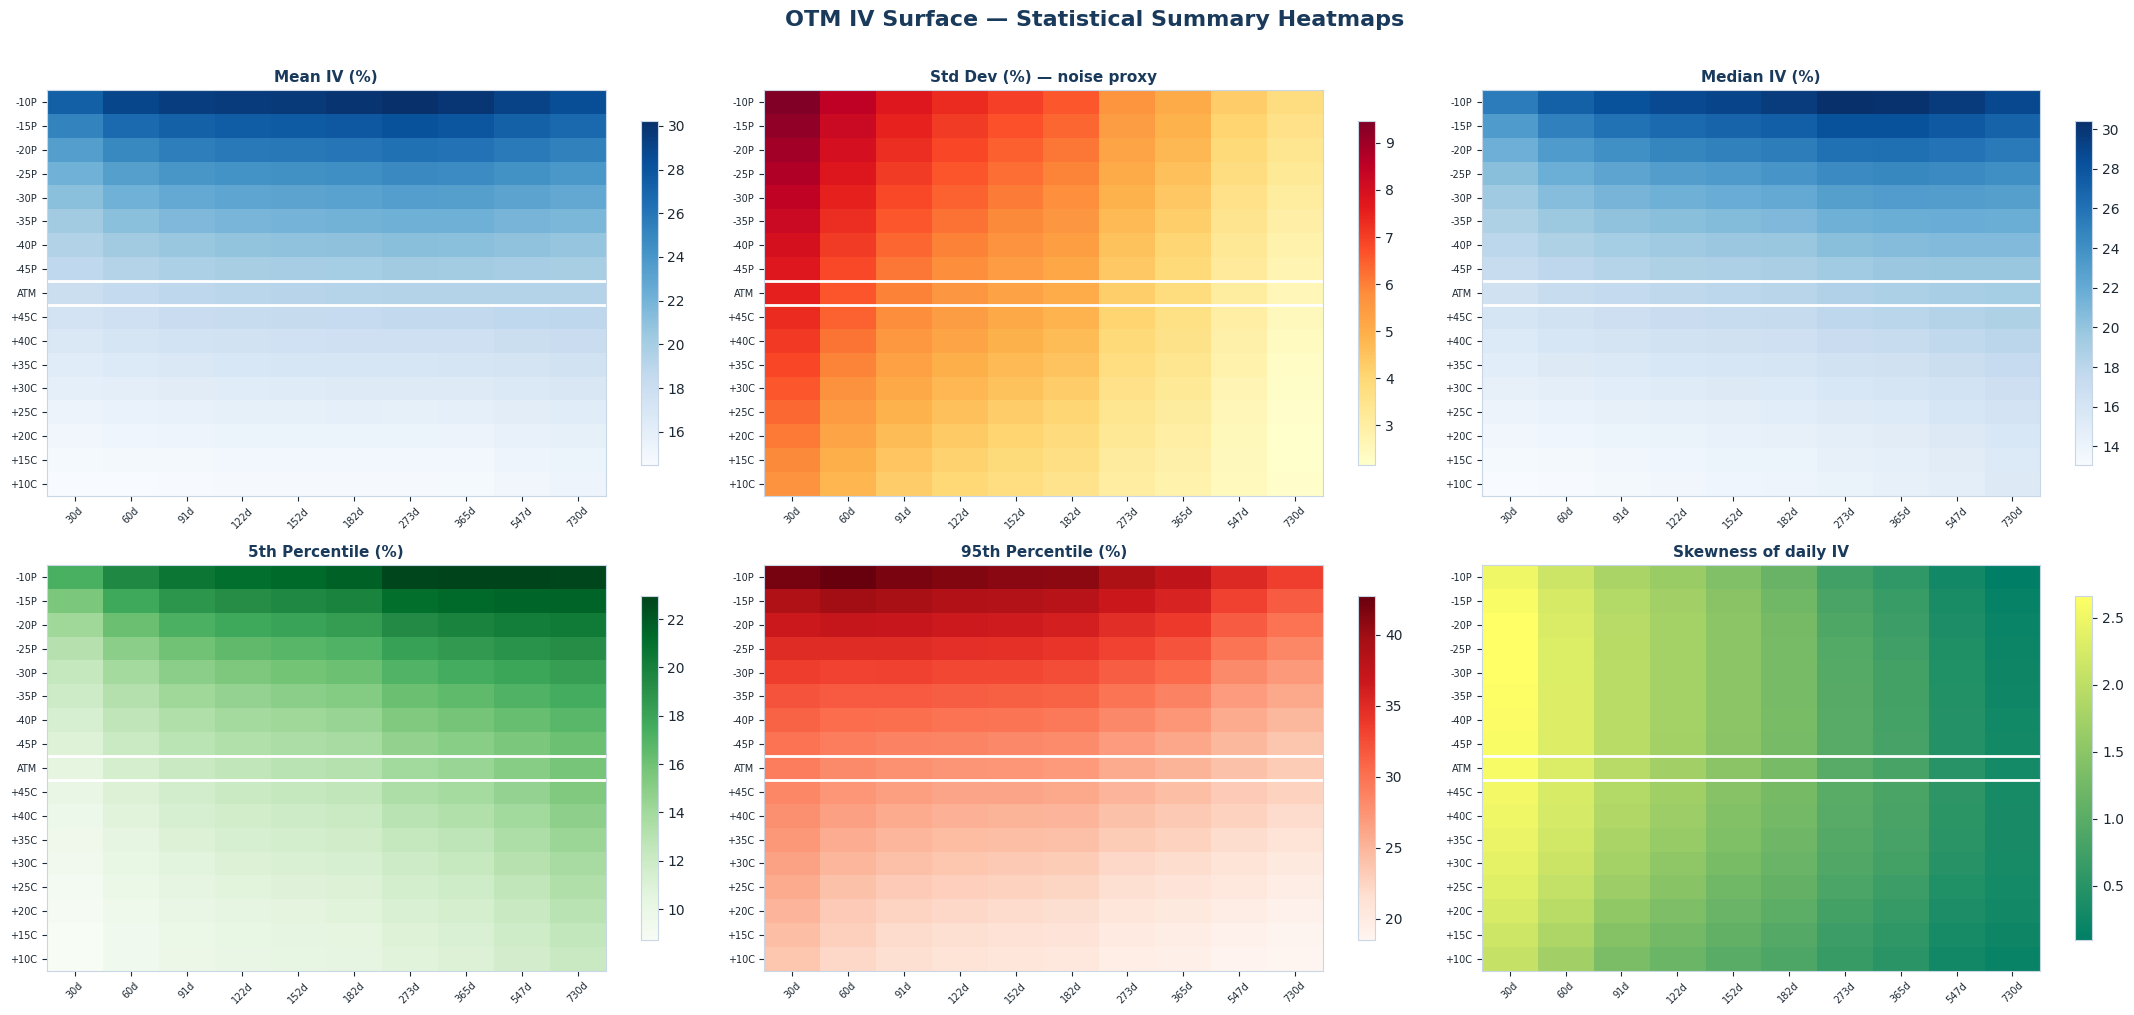

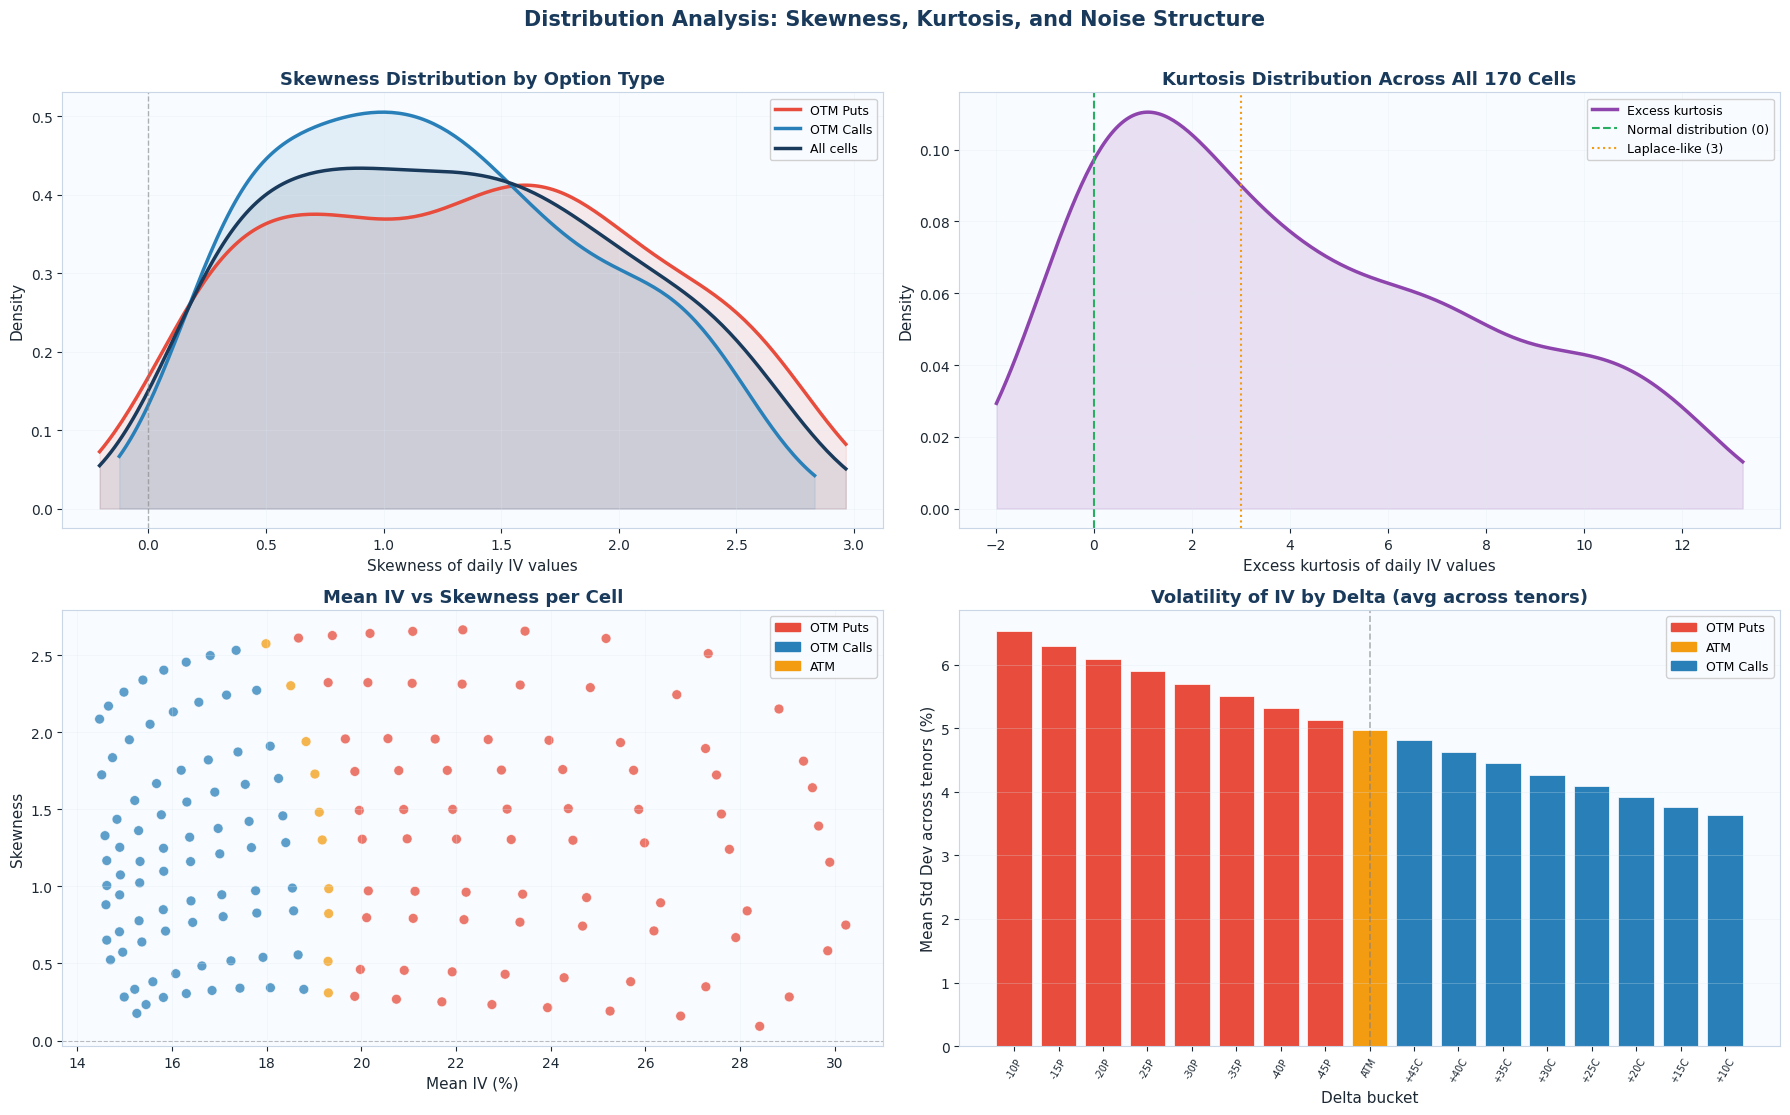

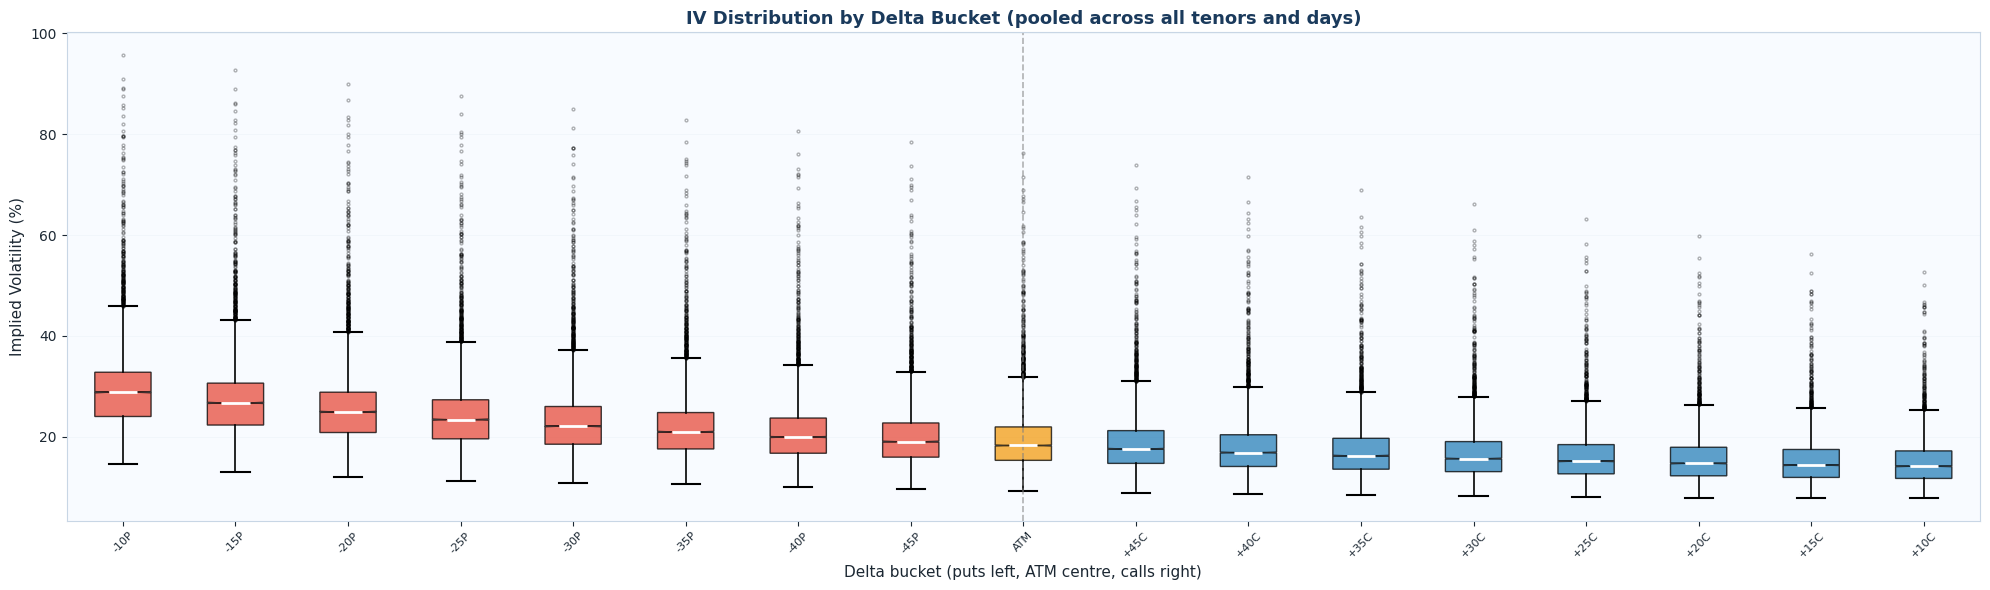

In [9]:
# ============================================================
# 5.2  COMPREHENSIVE DESCRIPTIVE STATISTICS
# ============================================================

from IPython.display import display, HTML

# --- Build per-cell summary ---
rows = []
for di, dlabel in enumerate(DELTA_LABELS):
    for ti, tenor in enumerate(TENORS):
        vals = surface_tensor[:, di, ti]
        rows.append({
            'delta': dlabel, 'tenor': f'{tenor}d',
            'mean':   vals.mean(),  'std':    vals.std(),
            'min':    vals.min(),   'p5':     np.percentile(vals, 5),
            'p25':    np.percentile(vals, 25), 'median': np.median(vals),
            'p75':    np.percentile(vals, 75), 'p95':    np.percentile(vals, 95),
            'max':    vals.max(),
            'skewness': float(pd.Series(vals).skew()),
            'kurtosis': float(pd.Series(vals).kurt()),
        })
df_desc = pd.DataFrame(rows)

# ── 1. OVERALL DESCRIBE → styled HTML table
flat_vals = surface_tensor.flatten()
desc = pd.Series(flat_vals, name='IV (%)').describe(
    percentiles=[.01,.05,.10,.25,.50,.75,.90,.95,.99]).round(3)

def styled_describe_html(series, title):
    rows_html = ''
    bar_max = series.max()
    for idx, val in series.items():
        bar_pct = min(val / bar_max * 100, 100) if bar_max > 0 else 0
        rows_html += f'''
        <tr>
          <td style="padding:10px 16px;font-weight:600;color:#1a3a5c;width:120px;">{idx}</td>
          <td style="padding:10px 16px;font-family:monospace;font-size:14px;color:#2c3e50;">{val:.4f}</td>
          <td style="padding:10px 16px;width:200px;">
            <div style="background:#e8f4fd;border-radius:4px;height:10px;overflow:hidden;">
              <div style="background:linear-gradient(90deg,#2980b9,#1a3a5c);width:{bar_pct:.1f}%;height:100%;border-radius:4px;"></div>
            </div>
          </td>
        </tr>'''
    return f'''
    <div style="margin:16px 0;">
      <div style="background:linear-gradient(135deg,#1a3a5c,#2980b9);padding:12px 18px;border-radius:10px 10px 0 0;">
        <span style="color:white;font-weight:700;font-size:14px;">{title}</span>
      </div>
      <table style="width:100%;border-collapse:collapse;background:white;border-radius:0 0 10px 10px;overflow:hidden;box-shadow:0 4px 15px rgba(26,58,92,0.1);">
        <thead>
          <tr style="background:#f0f7ff;">
            <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:12px;letter-spacing:1px;text-transform:uppercase;">Statistic</th>
            <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:12px;letter-spacing:1px;text-transform:uppercase;">Value</th>
            <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:12px;letter-spacing:1px;text-transform:uppercase;">Relative magnitude</th>
          </tr>
        </thead>
        <tbody>{rows_html}</tbody>
      </table>
    </div>'''

display(HTML(styled_describe_html(desc, 'Overall IV Distribution — All Cells, All Days')))

# ── 2. ATM TERM STRUCTURE TABLE
atm_rows = ''
for ti, t in enumerate(TENORS):
    v = surface_tensor[:, ATM_IDX, ti]
    spread = v.max() - v.min()
    bar = spread / 60 * 100
    atm_rows += f'''
    <tr style="background:{'#eaf4fd' if ti % 2 == 0 else 'white'};">
      <td style="padding:10px 16px;font-weight:700;color:#2980b9;">{t}d</td>
      <td style="padding:10px 16px;font-family:monospace;">{v.mean():.2f}%</td>
      <td style="padding:10px 16px;font-family:monospace;color:#e74c3c;">{v.std():.2f}%</td>
      <td style="padding:10px 16px;font-family:monospace;color:#27ae60;">{v.min():.2f}%</td>
      <td style="padding:10px 16px;font-family:monospace;color:#c0392b;">{v.max():.2f}%</td>
      <td style="padding:10px 16px;">
        <div style="background:#fde8e8;border-radius:4px;height:10px;width:100%;overflow:hidden;">
          <div style="background:linear-gradient(90deg,#e74c3c,#c0392b);width:{min(bar,100):.1f}%;height:100%;border-radius:4px;"></div>
        </div>
      </td>
    </tr>'''

display(HTML(f'''
<div style="margin:20px 0;">
  <div style="background:linear-gradient(135deg,#0d6e56,#1abc9c);padding:12px 18px;border-radius:10px 10px 0 0;">
    <span style="color:white;font-weight:700;font-size:14px;">ATM Implied Volatility by Tenor</span>
  </div>
  <table style="width:100%;border-collapse:collapse;background:white;border-radius:0 0 10px 10px;overflow:hidden;box-shadow:0 4px 15px rgba(0,0,0,0.08);">
    <thead><tr style="background:#e8f8f2;">
      <th style="padding:10px 16px;text-align:left;color:#0d6e56;font-size:12px;text-transform:uppercase;">Tenor</th>
      <th style="padding:10px 16px;text-align:left;color:#0d6e56;font-size:12px;text-transform:uppercase;">Mean</th>
      <th style="padding:10px 16px;text-align:left;color:#0d6e56;font-size:12px;text-transform:uppercase;">Std Dev</th>
      <th style="padding:10px 16px;text-align:left;color:#0d6e56;font-size:12px;text-transform:uppercase;">Min</th>
      <th style="padding:10px 16px;text-align:left;color:#0d6e56;font-size:12px;text-transform:uppercase;">Max</th>
      <th style="padding:10px 16px;text-align:left;color:#0d6e56;font-size:12px;text-transform:uppercase;">Range</th>
    </tr></thead>
    <tbody>{atm_rows}</tbody>
  </table>
</div>'''))

# ── 3. 25d PUT PREMIUM TABLE
premium_25p = surface_tensor[:, P25_IDX, T30_IDX] - surface_tensor[:, ATM_IDX, T30_IDX]
p_desc = pd.Series(premium_25p, name='P25 premium (vp)').describe(
    percentiles=[.10,.50,.90]).round(3)
display(HTML(styled_describe_html(p_desc, '25-Delta Put Premium Over ATM — 30d Tenor (vol points)')))

# ── 4. df_desc.describe() → styled table
summary = df_desc[['mean','std','p5','p95','skewness','kurtosis']].describe().round(3)

col_colours = {
    'mean': '#2980b9', 'std': '#e74c3c', 'p5': '#27ae60',
    'p95': '#c0392b', 'skewness': '#8e44ad', 'kurtosis': '#f39c12'
}
header_cells = ''.join(
    f'<th style="padding:10px 14px;text-align:right;color:{col_colours.get(c,"#1a3a5c")};font-size:12px;text-transform:uppercase;border-bottom:2px solid {col_colours.get(c,"#1a3a5c")}44;">{c}</th>'
    for c in summary.columns)
desc_rows = ''
for i, (ridx, rvals) in enumerate(summary.iterrows()):
    bg = '#f8fbff' if i % 2 == 0 else 'white'
    cells_html = ''.join(
        f'<td style="padding:9px 14px;text-align:right;font-family:monospace;font-size:13px;color:{col_colours.get(c,"#1c2833")};">{v:.3f}</td>'
        for c, v in zip(summary.columns, rvals))
    desc_rows += f'<tr style="background:{bg};"><td style="padding:9px 14px;font-weight:600;color:#1a3a5c;">{ridx}</td>{cells_html}</tr>'

display(HTML(f'''
<div style="margin:20px 0;">
  <div style="background:linear-gradient(135deg,#4a1a6e,#7d3cba);padding:12px 18px;border-radius:10px 10px 0 0;">
    <span style="color:white;font-weight:700;font-size:14px;">df_desc.describe() — Summary of Per-Cell Statistics Across All 170 Surface Cells</span>
  </div>
  <div style="overflow-x:auto;background:white;border-radius:0 0 10px 10px;box-shadow:0 4px 15px rgba(0,0,0,0.08);">
  <table style="width:100%;border-collapse:collapse;">
    <thead><tr style="background:#f5eeff;">
      <th style="padding:10px 14px;text-align:left;color:#4a1a6e;font-size:12px;text-transform:uppercase;">Statistic</th>
      {header_cells}
    </tr></thead>
    <tbody>{desc_rows}</tbody>
  </table>
  </div>
</div>'''))

# ── 5. HEATMAPS
fig, axes = plt.subplots(2, 3, figsize=(22, 10))
stats_map = [
    ('mean',     'Mean IV (%)',                   'Blues'),
    ('std',      'Std Dev (%) — noise proxy',     'YlOrRd'),
    ('median',   'Median IV (%)',                  'Blues'),
    ('p5',       '5th Percentile (%)',             'Greens'),
    ('p95',      '95th Percentile (%)',            'Reds'),
    ('skewness', 'Skewness of daily IV',           'summer'),
]
for ax, (stat, label, cm) in zip(axes.flatten(), stats_map):
    pivot = df_desc.pivot(index='delta', columns='tenor', values=stat)
    pivot = pivot.reindex(index=DELTA_LABELS, columns=[f'{t}d' for t in TENORS])
    im = ax.imshow(pivot.values, cmap=cm, aspect='auto')
    ax.set_xticks(range(N_TENORS))
    ax.set_xticklabels([f'{t}d' for t in TENORS], fontsize=7, rotation=45)
    ax.set_yticks(range(N_DELTAS))
    ax.set_yticklabels(DELTA_LABELS, fontsize=7)
    ax.axhline(ATM_IDX - 0.5, color='white', linewidth=2)
    ax.axhline(ATM_IDX + 0.5, color='white', linewidth=2)
    ax.set_title(label, fontweight='bold', color=LSE_BLUE, fontsize=11)
    plt.colorbar(im, ax=ax, shrink=0.85)
fig.suptitle('OTM IV Surface — Statistical Summary Heatmaps',
             fontsize=16, fontweight='bold', color=LSE_BLUE, y=1.01)
plt.tight_layout(); plt.show()

# ── 6. SKEWNESS + KURTOSIS DISTRIBUTIONS WITH KDE
from scipy.stats import norm, gaussian_kde

fig, axes = plt.subplots(2, 2, figsize=(18, 11))
fig.patch.set_facecolor('white')

# 6a. Skewness distribution by delta region
put_skew  = df_desc[df_desc['delta'].str.startswith('-')]['skewness'].values
call_skew = df_desc[df_desc['delta'].str.startswith('+')]['skewness'].values
atm_skew  = df_desc[df_desc['delta'] == 'ATM']['skewness'].values

ax = axes[0, 0]
for vals, label, c in [(put_skew,'OTM Puts','#e74c3c'),
                        (call_skew,'OTM Calls','#2980b9'),
                        (df_desc['skewness'].values,'All cells','#1a3a5c')]:
    if len(vals) > 2:
        kde = gaussian_kde(vals, bw_method=0.4)
        xs  = np.linspace(vals.min()-0.3, vals.max()+0.3, 200)
        ax.plot(xs, kde(xs), linewidth=2.5, label=label, color=c)
        ax.fill_between(xs, kde(xs), alpha=0.1, color=c)
ax.axvline(0, color='grey', linewidth=1, linestyle='--', alpha=0.6)
ax.set_xlabel('Skewness of daily IV values', fontsize=11)
ax.set_ylabel('Density')
ax.set_title('Skewness Distribution by Option Type', fontweight='bold', color=LSE_BLUE)
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# 6b. Kurtosis KDE (log scale since heavy tails)
ax = axes[0, 1]
kurt_vals = df_desc['kurtosis'].values
kde = gaussian_kde(kurt_vals, bw_method=0.35)
xs  = np.linspace(kurt_vals.min()-1, kurt_vals.max()+1, 300)
ax.plot(xs, kde(xs), color='#8e44ad', linewidth=2.5, label='Excess kurtosis')
ax.fill_between(xs, kde(xs), alpha=0.15, color='#8e44ad')
ax.axvline(0, color='#27ae60', linewidth=1.5, linestyle='--', label='Normal distribution (0)')
ax.axvline(3, color='#f39c12', linewidth=1.5, linestyle=':', label='Laplace-like (3)')
ax.set_xlabel('Excess kurtosis of daily IV values', fontsize=11)
ax.set_ylabel('Density')
ax.set_title('Kurtosis Distribution Across All 170 Cells', fontweight='bold', color=LSE_BLUE)
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# 6c. Skewness vs Mean scatter (coloured by delta region)
ax = axes[1, 0]
colours_scatter = []
for d in df_desc['delta']:
    if d.startswith('-'):   colours_scatter.append('#e74c3c')
    elif d.startswith('+'): colours_scatter.append('#2980b9')
    else:                   colours_scatter.append('#f39c12')
sc = ax.scatter(df_desc['mean'], df_desc['skewness'],
                c=colours_scatter, s=50, alpha=0.75, edgecolors='white', linewidth=0.5)
ax.axhline(0, color='grey', linewidth=0.8, linestyle='--', alpha=0.5)
ax.set_xlabel('Mean IV (%)', fontsize=11)
ax.set_ylabel('Skewness')
ax.set_title('Mean IV vs Skewness per Cell', fontweight='bold', color=LSE_BLUE)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='#e74c3c',label='OTM Puts'),
                   Patch(color='#2980b9',label='OTM Calls'),
                   Patch(color='#f39c12',label='ATM')], fontsize=9)
ax.grid(True, alpha=0.3)

# 6d. Std dev by delta label (sorted)
ax = axes[1, 1]
std_by_delta = df_desc.groupby('delta')['std'].mean().reindex(DELTA_LABELS)
bar_colours = ['#e74c3c' if d.startswith('-') else
               '#f39c12' if d == 'ATM' else '#2980b9'
               for d in DELTA_LABELS]
bars = ax.bar(range(N_DELTAS), std_by_delta.values,
              color=bar_colours, edgecolor='white', linewidth=0.5)
ax.set_xticks(range(N_DELTAS))
ax.set_xticklabels(DELTA_LABELS, fontsize=7, rotation=60)
ax.axvline(ATM_IDX, color='grey', linewidth=1.2, linestyle='--', alpha=0.6)
ax.set_xlabel('Delta bucket')
ax.set_ylabel('Mean Std Dev across tenors (%)')
ax.set_title('Volatility of IV by Delta (avg across tenors)', fontweight='bold', color=LSE_BLUE)
ax.grid(True, axis='y', alpha=0.3)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='#e74c3c',label='OTM Puts'),
                   Patch(color='#f39c12',label='ATM'),
                   Patch(color='#2980b9',label='OTM Calls')], fontsize=9)

fig.suptitle('Distribution Analysis: Skewness, Kurtosis, and Noise Structure',
             fontsize=15, fontweight='bold', color=LSE_BLUE, y=1.01)
plt.tight_layout()
plt.show()

# ── 7. BOXPLOT: IV distribution by delta bucket
fig, ax = plt.subplots(figsize=(20, 6))
bp_data = [surface_tensor[:, di, :].flatten() for di in range(N_DELTAS)]
bp = ax.boxplot(bp_data, patch_artist=True, notch=True,
                medianprops=dict(color='white', linewidth=2),
                whiskerprops=dict(linewidth=1.2),
                capprops=dict(linewidth=1.5),
                flierprops=dict(marker='o', markersize=2, alpha=0.3))
for patch, d in zip(bp['boxes'], DELTA_LABELS):
    c = '#e74c3c' if d.startswith('-') else '#f39c12' if d == 'ATM' else '#2980b9'
    patch.set_facecolor(c); patch.set_alpha(0.75)
ax.set_xticks(range(1, N_DELTAS + 1))
ax.set_xticklabels(DELTA_LABELS, fontsize=8, rotation=45)
ax.axvline(ATM_IDX + 1, color='grey', linewidth=1.2, linestyle='--', alpha=0.6)
ax.set_xlabel('Delta bucket (puts left, ATM centre, calls right)', fontsize=11)
ax.set_ylabel('Implied Volatility (%)')
ax.set_title('IV Distribution by Delta Bucket (pooled across all tenors and days)',
             fontweight='bold', color=LSE_BLUE)
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# ============================================================
# DATA VALIDATION
# ============================================================

from IPython.display import display, HTML

def check_icon(passed):
    return '<span style="color:#1abc9c;font-size:16px;">&#10004;</span>' if passed else '<span style="color:#e74c3c;font-size:16px;">&#10008;</span>'

def status_pill(text, color):
    return f'<span style="background:{color}18;color:{color};border:1.5px solid {color}55;padding:3px 12px;border-radius:20px;font-size:12px;font-weight:700;letter-spacing:1px;">{text}</span>'

# ── Compute all checks
total_rows      = len(raw_df)
expected_rows   = 252 * 5 * len(ALL_QUERY_DELTAS) * len(TENORS)
date_min        = pd.to_datetime(raw_df.date).min()
date_max        = pd.to_datetime(raw_df.date).max()
trading_days    = raw_df.date.nunique()
deltas_found    = sorted(raw_df.delta.unique().tolist())
tenors_found    = sorted(raw_df.days.unique().tolist())
delta_match     = deltas_found == sorted(ALL_QUERY_DELTAS)
tenor_match     = tenors_found == sorted(TENORS)
total_combos    = trading_days * len(ALL_QUERY_DELTAS) * len(TENORS)
missing_combos  = total_combos - total_rows
missing_pct     = missing_combos / total_combos * 100
nan_count       = raw_df.impl_volatility.isna().sum()
nan_pct         = nan_count / total_rows * 100
vol_min         = raw_df.impl_volatility.min()
vol_max         = raw_df.impl_volatility.max()
raw_df['_year'] = pd.to_datetime(raw_df.date).dt.year
rows_per_year   = raw_df.groupby('_year').size().to_dict()
secid_ok        = (raw_df.secid.unique().tolist() == [108105]) if 'secid' in raw_df.columns else None

# ── Overall status
if missing_pct < 5 and nan_count == 0:
    status_text, status_color, status_emoji = 'PASS', '#1abc9c', '&#9989;'
elif missing_pct < 10:
    status_text, status_color, status_emoji = 'WARN', '#f39c12', '&#9888;'
else:
    status_text, status_color, status_emoji = 'FAIL', '#e74c3c', '&#10060;'

# ── Rows-per-year mini bar chart (HTML)
max_yr_rows = max(rows_per_year.values())
year_bars = ''
for yr, cnt in sorted(rows_per_year.items()):
    pct = cnt / max_yr_rows * 100
    year_bars += f'''
    <div style="display:flex;align-items:center;gap:10px;margin:5px 0;">
      <span style="color:#1a3a5c;font-weight:600;width:40px;font-size:13px;">{yr}</span>
      <div style="flex-grow:1;background:#e8f4fd;border-radius:4px;height:18px;overflow:hidden;">
        <div style="background:linear-gradient(90deg,#2980b9,#1a3a5c);width:{pct:.1f}%;height:100%;border-radius:4px;display:flex;align-items:center;padding-left:8px;">
          <span style="color:white;font-size:11px;font-weight:600;white-space:nowrap;">{cnt:,}</span>
        </div>
      </div>
    </div>'''

# ── Check rows
checks_html = f'''
<tr style="background:#f8fbff;">
  <td style="padding:12px 16px;font-weight:700;color:#1a3a5c;width:40px;">1</td>
  <td style="padding:12px 16px;font-weight:600;color:#1a3a5c;">Total rows</td>
  <td style="padding:12px 16px;font-family:monospace;font-size:13px;">{total_rows:,}</td>
  <td style="padding:12px 16px;color:#555;font-size:13px;">Expected ~{expected_rows:,}</td>
  <td style="padding:12px 16px;">{check_icon(total_rows > expected_rows * 0.8)}</td>
</tr>
<tr style="background:white;">
  <td style="padding:12px 16px;font-weight:700;color:#1a3a5c;">2</td>
  <td style="padding:12px 16px;font-weight:600;color:#1a3a5c;">Date range</td>
  <td style="padding:12px 16px;font-family:monospace;font-size:13px;">{date_min.strftime('%Y-%m-%d')} to {date_max.strftime('%Y-%m-%d')}</td>
  <td style="padding:12px 16px;color:#555;font-size:13px;">{trading_days:,} trading days &nbsp; (expected ~1,258)</td>
  <td style="padding:12px 16px;">{check_icon(abs(trading_days - 1258) < 50)}</td>
</tr>
<tr style="background:#f8fbff;">
  <td style="padding:12px 16px;font-weight:700;color:#1a3a5c;">3</td>
  <td style="padding:12px 16px;font-weight:600;color:#1a3a5c;">Deltas present</td>
  <td style="padding:12px 16px;font-family:monospace;font-size:12px;">{deltas_found}</td>
  <td style="padding:12px 16px;color:#555;font-size:13px;">Match expected: {'yes' if delta_match else 'NO'}</td>
  <td style="padding:12px 16px;">{check_icon(delta_match)}</td>
</tr>
<tr style="background:white;">
  <td style="padding:12px 16px;font-weight:700;color:#1a3a5c;">4</td>
  <td style="padding:12px 16px;font-weight:600;color:#1a3a5c;">Tenors present</td>
  <td style="padding:12px 16px;font-family:monospace;font-size:12px;">{tenors_found}</td>
  <td style="padding:12px 16px;color:#555;font-size:13px;">Match expected: {'yes' if tenor_match else 'NO'}</td>
  <td style="padding:12px 16px;">{check_icon(tenor_match)}</td>
</tr>
<tr style="background:#f8fbff;">
  <td style="padding:12px 16px;font-weight:700;color:#1a3a5c;">5</td>
  <td style="padding:12px 16px;font-weight:600;color:#1a3a5c;">Missing cells</td>
  <td style="padding:12px 16px;font-family:monospace;font-size:13px;">{missing_combos:,} &nbsp; ({missing_pct:.2f}%)</td>
  <td style="padding:12px 16px;color:#555;font-size:13px;">Threshold: &lt;5% pass, &lt;10% warn</td>
  <td style="padding:12px 16px;">{check_icon(missing_pct < 5)}</td>
</tr>
<tr style="background:white;">
  <td style="padding:12px 16px;font-weight:700;color:#1a3a5c;">6</td>
  <td style="padding:12px 16px;font-weight:600;color:#1a3a5c;">NaN vol values</td>
  <td style="padding:12px 16px;font-family:monospace;font-size:13px;">{nan_count:,} &nbsp; ({nan_pct:.2f}%)</td>
  <td style="padding:12px 16px;color:#555;font-size:13px;">Zero NaNs expected</td>
  <td style="padding:12px 16px;">{check_icon(nan_count == 0)}</td>
</tr>
<tr style="background:#f8fbff;">
  <td style="padding:12px 16px;font-weight:700;color:#1a3a5c;">7</td>
  <td style="padding:12px 16px;font-weight:600;color:#1a3a5c;">Vol range sanity</td>
  <td style="padding:12px 16px;font-family:monospace;font-size:13px;">{vol_min:.4f} to {vol_max:.4f}</td>
  <td style="padding:12px 16px;color:#555;font-size:13px;">Fraction: 0.05-2.0 &nbsp;|&nbsp; Percent: 5-200</td>
  <td style="padding:12px 16px;">{check_icon(vol_max > 2)}</td>
</tr>
''' + (f'''<tr style="background:white;">
  <td style="padding:12px 16px;font-weight:700;color:#1a3a5c;">9</td>
  <td style="padding:12px 16px;font-weight:600;color:#1a3a5c;">SECID check</td>
  <td style="padding:12px 16px;font-family:monospace;font-size:13px;">{raw_df.secid.unique().tolist()}</td>
  <td style="padding:12px 16px;color:#555;font-size:13px;">Expected [108105]</td>
  <td style="padding:12px 16px;">{check_icon(secid_ok)}</td>
</tr>''' if secid_ok is not None else '')

display(HTML(f'''
<div style="font-family:sans-serif;margin:16px 0;">

  <!-- Header banner -->
  <div style="background:linear-gradient(135deg,#0a1628,#1a3a5c,#2471a3);padding:20px 28px;border-radius:14px 14px 0 0;display:flex;justify-content:space-between;align-items:center;">
    <div>
      <div style="color:rgba(255,255,255,0.5);font-size:11px;letter-spacing:3px;text-transform:uppercase;margin-bottom:4px;">OptionMetrics IvyDB</div>
      <div style="color:white;font-size:20px;font-weight:700;font-family:Georgia,serif;">Data Completeness Check</div>
    </div>
    <div style="text-align:right;">
      <div style="font-size:28px;">{status_emoji}</div>
      <div style="margin-top:4px;">{status_pill(status_text, status_color)}</div>
    </div>
  </div>

  <!-- Checks table -->
  <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 14px 14px;overflow:hidden;box-shadow:0 6px 20px rgba(26,58,92,0.08);">
    <table style="width:100%;border-collapse:collapse;">
      <thead>
        <tr style="background:#eaf4fd;">
          <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">#</th>
          <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Check</th>
          <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Value</th>
          <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Reference</th>
          <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Status</th>
        </tr>
      </thead>
      <tbody>{checks_html}</tbody>
    </table>

    <!-- Rows per year inline bar chart -->
    <div style="border-top:1px solid #d6eaf8;padding:18px 20px;background:#fafcff;">
      <div style="font-weight:700;color:#1a3a5c;font-size:13px;margin-bottom:12px;">&#128197; &nbsp; Rows per year</div>
      {year_bars}
    </div>

    <!-- Status footer -->
    <div style="background:{'#e8faf5' if status_text=='PASS' else '#fef9e7' if status_text=='WARN' else '#fde8e8'};border-top:2px solid {status_color};padding:14px 20px;display:flex;align-items:center;gap:12px;">
      <span style="font-size:20px;">{status_emoji}</span>
      <div>
        <span style="font-weight:700;color:{status_color};">{status_text}</span>
        <span style="color:#1c2833;font-size:13px;margin-left:8px;">
        {'Data looks complete and clean. Ready to proceed.' if status_text=='PASS' else 'Some gaps present but interpolation will handle them.' if status_text=='WARN' else 'Too many missing cells. Check the WRDS query.'}
        </span>
      </div>
    </div>
  </div>

</div>
'''))

#,Check,Value,Reference,Status
1,Total rows,"226,440","Expected ~226,800",✔
2,Date range,2019-01-02 to 2023-12-29,"1,258 trading days (expected ~1,258)",✔
3,Deltas present,"[-50.0, -45.0, -40.0, -35.0, -30.0, -25.0, -20.0, -15.0, -10.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 45.0, 50.0]",Match expected: yes,✔
4,Tenors present,"[30.0, 60.0, 91.0, 122.0, 152.0, 182.0, 273.0, 365.0, 547.0, 730.0]",Match expected: yes,✔
5,Missing cells,0 (0.00%),"Threshold: <5% pass, <10% warn",✔
6,NaN vol values,0 (0.00%),Zero NaNs expected,✔
7,Vol range sanity,0.0780 to 0.9581,Fraction: 0.05-2.0 | Percent: 5-200,✘


<a id="sec6"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:28px 32px;border-radius:14px;margin:30px 0 22px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.5);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 6</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:26px;margin:0;font-weight:700;">Exploratory Data Analysis</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:14px;">Getting to know the data before we try to model it</p>
</div>
<p style="font-size:14px;line-height:1.8;color:#1c2833;">
Good EDA is not optional here: it directly informs every modelling choice. We need to verify the stylised facts from the theory (skew, term structure, low PCA dimensionality), understand which parts of the grid are noisiest, identify the volatility regimes in our 2019-2023 sample, and check whether OptionMetrics has introduced any structural breaks in its methodology. Each finding maps to a specific design decision.
</p><div style="background:#8e44ad08;border-left:4px solid #8e44ad;border-radius:0 10px 10px 0;padding:16px 20px;margin:14px 0;">
<div style="font-weight:700;color:#8e44ad;margin-bottom:6px;font-size:14px;">📌 &nbsp; Note</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.7;">All EDA is run on the full dataset but PCA and normalisation statistics use only the training split to avoid lookahead bias.</div>
</div>

<div style="display:flex;align-items:center;gap:12px;margin:26px 0 14px 0;">
<div style="background:linear-gradient(135deg,#2980b9,#1a3a5c);min-width:36px;height:36px;border-radius:8px;display:flex;align-items:center;justify-content:center;">
<span style="color:white;font-size:12px;font-weight:700;">6.1</span>
</div>
<h3 style="color:#1a3a5c;font-family:Georgia,serif;font-size:20px;margin:0;border-bottom:2px solid #d6eaf8;padding-bottom:6px;flex-grow:1;">Single-Day OTM Surface Visualisation</h3>
</div>
<p style="font-size:14px;line-height:1.75;color:#1c2833;">We start by looking at the surface on a representative day. The 3D mesh gives the overall shape. The heatmap makes fine-grained structure legible (white lines mark the ATM boundary). The cross-sections show the smile at different tenors. Things to notice: the put wing is always higher than the call wing at the same absolute delta; the smile flattens from short to long tenors; the ATM level varies more with maturity than the wing level.</p>

In [13]:
import re
def md_to_html(text):
    """Convert inline markdown to HTML so it renders inside HTML divs."""
    text = re.sub(r'\*\*(.*?)\*\*', r'<strong>\1</strong>', text)
    text = re.sub(r'\*(.*?)\*',     r'<em>\1</em>',         text)
    return text
def make_interp_box(title, content):
    clean = md_to_html(strip_em(content))
    return f'''<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 22px;margin:16px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:18px;">&#128270;</span> {title}</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">{clean}</div>
</div>'''

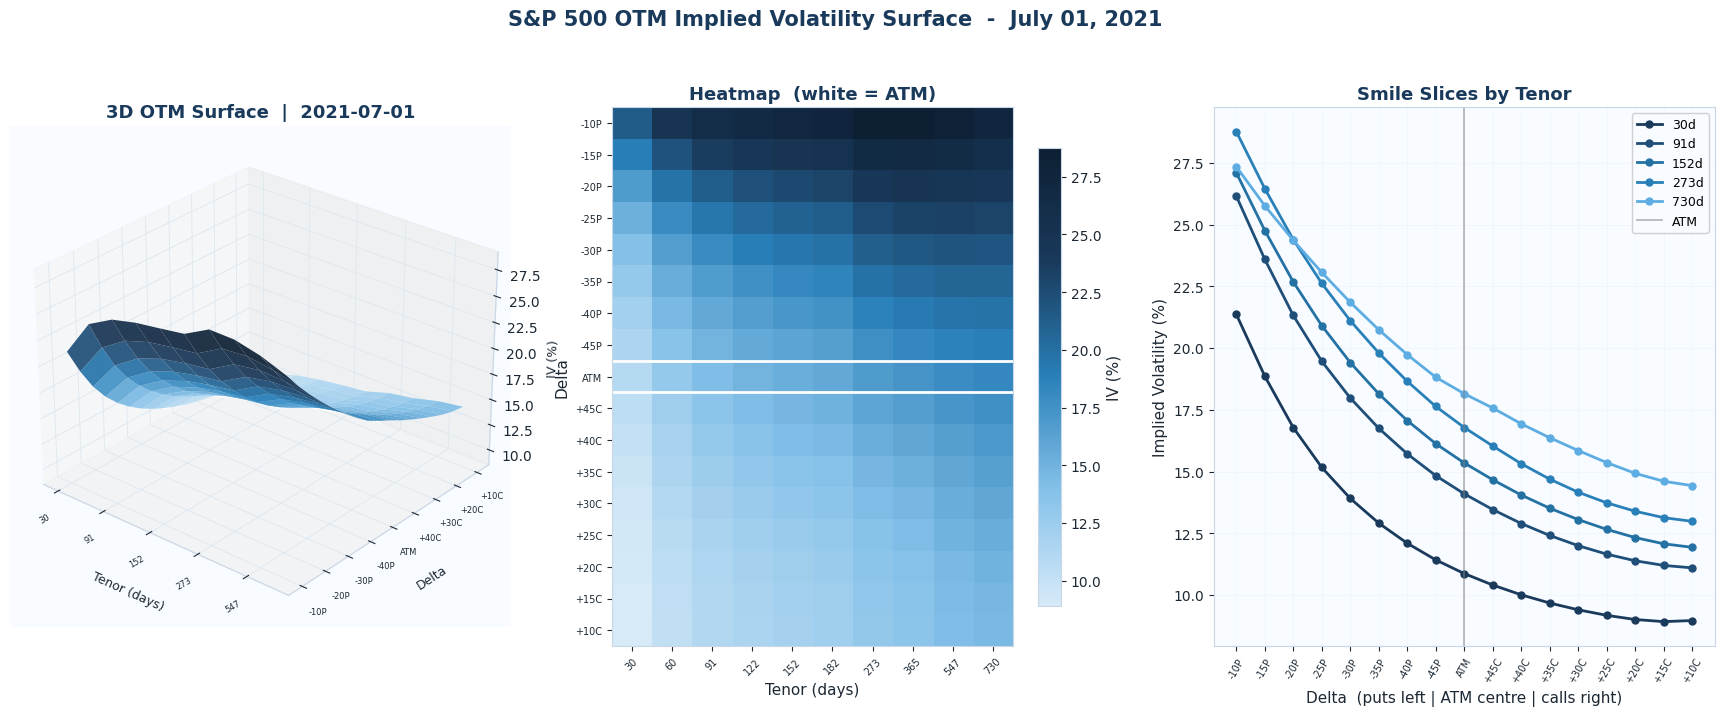

In [15]:
# ============================================================
# 6.1  SINGLE-DAY SURFACE VISUALISATION  (OTM convention)
# ============================================================

cmap_vol = LinearSegmentedColormap.from_list(
    'lse_vol', ['#d6eaf8', '#85c1e9', '#2980b9', '#1a3a5c', '#0d1f33'], N=256)

mid_idx      = T_DAYS // 2
sample_date  = valid_dates[mid_idx]
sample_surf  = surface_tensor[mid_idx]

fig = plt.figure(figsize=(22, 7))

# -- 3D surface --
ax1 = fig.add_subplot(131, projection='3d')
Xg, Yg = np.meshgrid(range(N_TENORS), range(N_DELTAS))
ax1.plot_surface(Xg, Yg, sample_surf, cmap=cmap_vol,
                 edgecolor='none', alpha=0.92)
ax1.set_xticks(range(N_TENORS)[::2])
ax1.set_xticklabels(TENORS[::2], fontsize=6, rotation=30)
ax1.set_yticks(range(N_DELTAS)[::2])
ax1.set_yticklabels(DELTA_LABELS[::2], fontsize=6)
ax1.set_xlabel('Tenor (days)', fontsize=9, labelpad=8)
ax1.set_ylabel('Delta', fontsize=9, labelpad=8)
ax1.set_zlabel('IV (%)', fontsize=9)
ax1.set_title(f'3D OTM Surface  |  {pd.Timestamp(sample_date).strftime("%Y-%m-%d")}',
              fontweight='bold', color=LSE_BLUE)
ax1.view_init(elev=28, azim=-50)
# Mark ATM row
ax1.plot(range(N_TENORS), [ATM_IDX]*N_TENORS,
         sample_surf[ATM_IDX, :], 'w-', linewidth=2.5, alpha=0.9)

# -- Heatmap --
ax2 = fig.add_subplot(132)
im  = ax2.imshow(sample_surf, cmap=cmap_vol, aspect='auto', origin='upper')
ax2.set_xticks(range(N_TENORS))
ax2.set_xticklabels(TENORS, fontsize=7, rotation=45)
ax2.set_yticks(range(N_DELTAS))
ax2.set_yticklabels(DELTA_LABELS, fontsize=7)
ax2.axhline(ATM_IDX - 0.5, color='white', linewidth=2)
ax2.axhline(ATM_IDX + 0.5, color='white', linewidth=2)
ax2.set_xlabel('Tenor (days)'); ax2.set_ylabel('Delta')
ax2.set_title('Heatmap  (white = ATM)', fontweight='bold', color=LSE_BLUE)
plt.colorbar(im, ax=ax2, label='IV (%)', shrink=0.85)

# -- Smile cross-sections --
ax3 = fig.add_subplot(133)
highlight_tenors = [0, 2, 4, 6, 9]
for k, ti in enumerate(highlight_tenors):
    ax3.plot(range(N_DELTAS), sample_surf[:, ti], 'o-',
             linewidth=2, markersize=5,
             label=f'{TENORS[ti]}d', color=BLUE_PALETTE[k])
ax3.axvline(ATM_IDX, color='grey', linewidth=1.2, linestyle='-', alpha=0.6,
            label='ATM')
ax3.set_xticks(range(N_DELTAS))
ax3.set_xticklabels(DELTA_LABELS, fontsize=7, rotation=60)
ax3.set_xlabel('Delta  (puts left | ATM centre | calls right)')
ax3.set_ylabel('Implied Volatility (%)')
ax3.set_title('Smile Slices by Tenor', fontweight='bold', color=LSE_BLUE)
ax3.legend(fontsize=9, framealpha=0.9)
ax3.grid(True, alpha=0.3)

fig.suptitle(f'S&P 500 OTM Implied Volatility Surface  -  '
             f'{pd.Timestamp(sample_date).strftime("%B %d, %Y")}',
             fontsize=15, fontweight='bold', color=LSE_BLUE, y=1.02)
plt.tight_layout()
plt.show()

atm_30   = sample_surf[ATM_IDX, T30_IDX]
put_prem = sample_surf[P25_IDX, T30_IDX] - atm_30
call_disc = sample_surf[C25_IDX, T30_IDX] - atm_30

def metric_card(label, value, note, color):
    return f'''<div style="background:white;border:1px solid {color}33;border-top:3px solid {color};border-radius:10px;padding:14px 18px;min-width:180px;">
  <div style="color:#888;font-size:11px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">{label}</div>
  <div style="font-size:22px;font-weight:800;color:{color};font-family:monospace;">{value}</div>
  <div style="color:#888;font-size:12px;margin-top:4px;">{note}</div>
</div>'''

display(HTML(f'''
<div style="display:flex;gap:14px;flex-wrap:wrap;margin:16px 0;font-family:sans-serif;">
  {metric_card("ATM 30d IV",        f"{atm_30:.2f}%",    "Base uncertainty level",   "#1a3a5c")}
  {metric_card("25d Put Premium",   f"{put_prem:+.2f} vp", "Crash fear over ATM",    "#e74c3c")}
  {metric_card("25d Call Discount", f"{call_disc:+.2f} vp","Upside vs ATM",          "#27ae60")}
</div>'''))

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 22px;margin:16px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:18px;">&#128270;</span> What the OTM surface is telling us</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">Several features are immediately visible in the surface snapshot above. The put wing (top of the heatmap, left of the smile slices) is universally more elevated than the corresponding call wing: this is the <strong>equity volatility skew</strong>, one of the most robust empirical facts in options markets. It reflects the asymmetry of investor fear: catastrophic downside moves (crashes) are priced as far more likely than symmetric upside moves of the same magnitude. The ATM row (marked with white lines) represents the "base" level of uncertainty that the market assigns to the near-term return distribution. The term structure visible in the heatmap (brighter colours at short tenors in the put wing) reflects that <strong>short-dated tail risk is priced more severely than long-dated tail risk</strong>: a regime shift next week is more frightening than a regime shift sometime in the next two years. The 3D view makes the non-monotone shape across the delta axis visible: the smile is U-shaped with a pronounced left asymmetry rather than a symmetric bowl.</div>
</div>

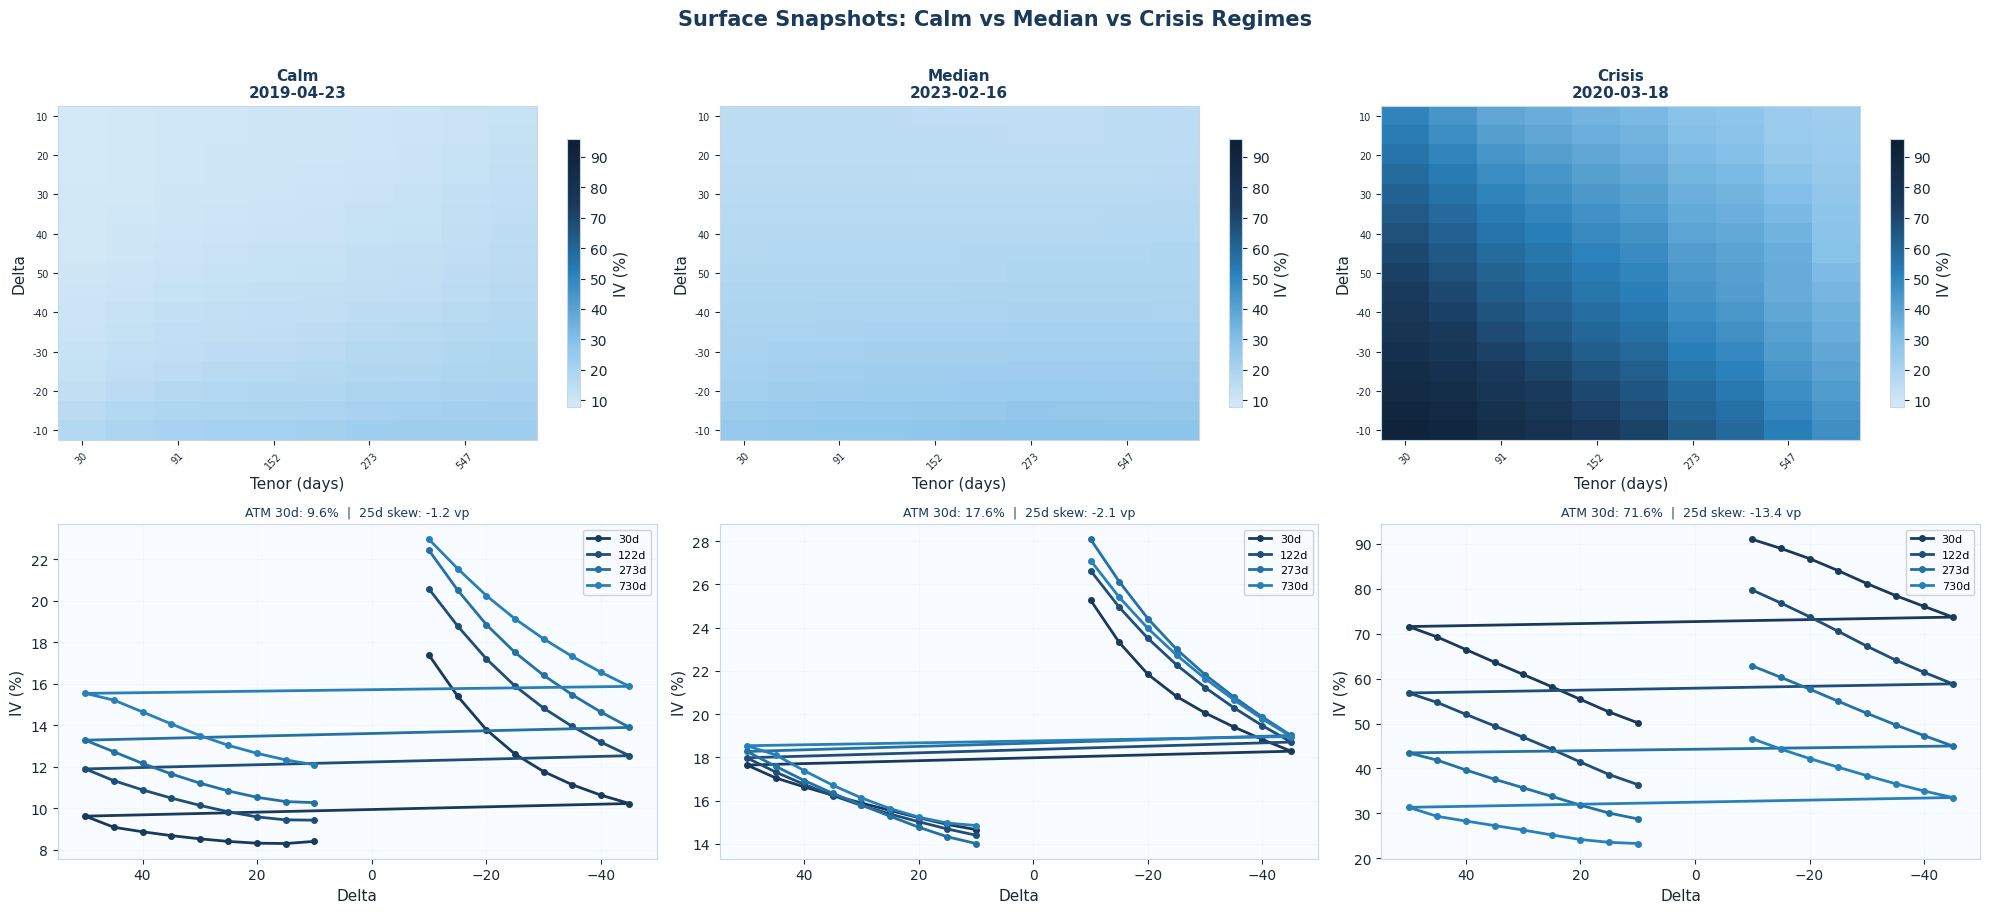

In [16]:
# ============================================================
# 6.1b  SURFACE COMPARISON: CALM vs CRISIS vs RECOVERY
# ============================================================

dates_plot = pd.to_datetime(dates_array)

# Pick three representative dates automatically
# Calm  : day with lowest mean IV in sample
# Crisis: day with highest mean IV in sample
# Mid   : day closest to the median mean IV
mean_iv_per_day = surface_tensor.mean(axis=(1, 2))
calm_idx    = int(np.argmin(mean_iv_per_day))
crisis_idx  = int(np.argmax(mean_iv_per_day))
median_val  = np.median(mean_iv_per_day)
mid_idx2    = int(np.argmin(np.abs(mean_iv_per_day - median_val)))

snapshots = {
    f'Calm\n{pd.Timestamp(valid_dates[calm_idx]).strftime("%Y-%m-%d")}':    surface_tensor[calm_idx],
    f'Median\n{pd.Timestamp(valid_dates[mid_idx2]).strftime("%Y-%m-%d")}':  surface_tensor[mid_idx2],
    f'Crisis\n{pd.Timestamp(valid_dates[crisis_idx]).strftime("%Y-%m-%d")}': surface_tensor[crisis_idx],
}

fig, axes = plt.subplots(2, 3, figsize=(20, 9))

vmin = surface_tensor.min()
vmax = surface_tensor.max()

for col, (label, surf) in enumerate(snapshots.items()):
    # Heatmap row
    im = axes[0, col].imshow(surf, cmap=cmap_vol, aspect='auto',
                              origin='lower', vmin=vmin, vmax=vmax)
    axes[0, col].set_xticks(range(N_TENORS)[::2])
    axes[0, col].set_xticklabels(TENORS[::2], fontsize=7, rotation=45)
    axes[0, col].set_yticks(range(N_DELTAS)[::2])
    axes[0, col].set_yticklabels(DELTAS[::2], fontsize=7)
    axes[0, col].set_title(label, fontweight='bold', color=LSE_BLUE, fontsize=11)
    axes[0, col].set_xlabel('Tenor (days)')
    axes[0, col].set_ylabel('Delta')
    plt.colorbar(im, ax=axes[0, col], shrink=0.8, label='IV (%)')

    # Smile slices row
    for k, ti in enumerate([0, 3, 6, 9]):
        axes[1, col].plot(DELTAS, surf[:, ti], 'o-', linewidth=2, markersize=4,
                          label=f'{TENORS[ti]}d', color=BLUE_PALETTE[k])
    axes[1, col].set_xlabel('Delta')
    axes[1, col].set_ylabel('IV (%)')
    axes[1, col].invert_xaxis()
    axes[1, col].legend(fontsize=8)
    axes[1, col].grid(True, alpha=0.3)
    atm_d = DELTAS.index(50)
    axes[1, col].set_title(
        f'ATM 30d: {surf[atm_d, 0]:.1f}%  |  25d skew: {surf[DELTAS.index(25),0]-surf[atm_d,0]:.1f} vp',
        fontsize=9, color=LSE_BLUE)

fig.suptitle('Surface Snapshots: Calm vs Median vs Crisis Regimes',
             fontsize=15, fontweight='bold', color=LSE_BLUE, y=1.01)
plt.tight_layout()
plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 22px;margin:16px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:18px;">&#128270;</span> Regime comparison: calm vs. crisis vs. recovery</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">The three panels illustrate how dramatically the surface changes across market environments. In the <strong>calm regime</strong>: the put wing is elevated but moderate, the term structure slopes upward (the market expects vol to be higher in the future than today), and the smile is relatively flat. In the <strong>median regime</strong>: normal market conditions with moderate skew. In the <strong>crisis regime</strong> (the COVID crash of March 2020 here): the surface transforms entirely. The ATM level spikes to multi-decade highs, the put wing becomes extreme as investors buy downside protection at any price, and the term structure inverts because the crisis is happening now, not in two years. The 25-delta skew value shown under each panel quantifies the put-call asymmetry. Notice how much steeper it gets during crisis. These three regimes define qualitatively different data-generating processes, which is why <strong>regime-conditional model evaluation</strong> (Section 11) is essential: a model trained in calm markets may fail precisely when accurate forecasting matters most.</div>
</div>

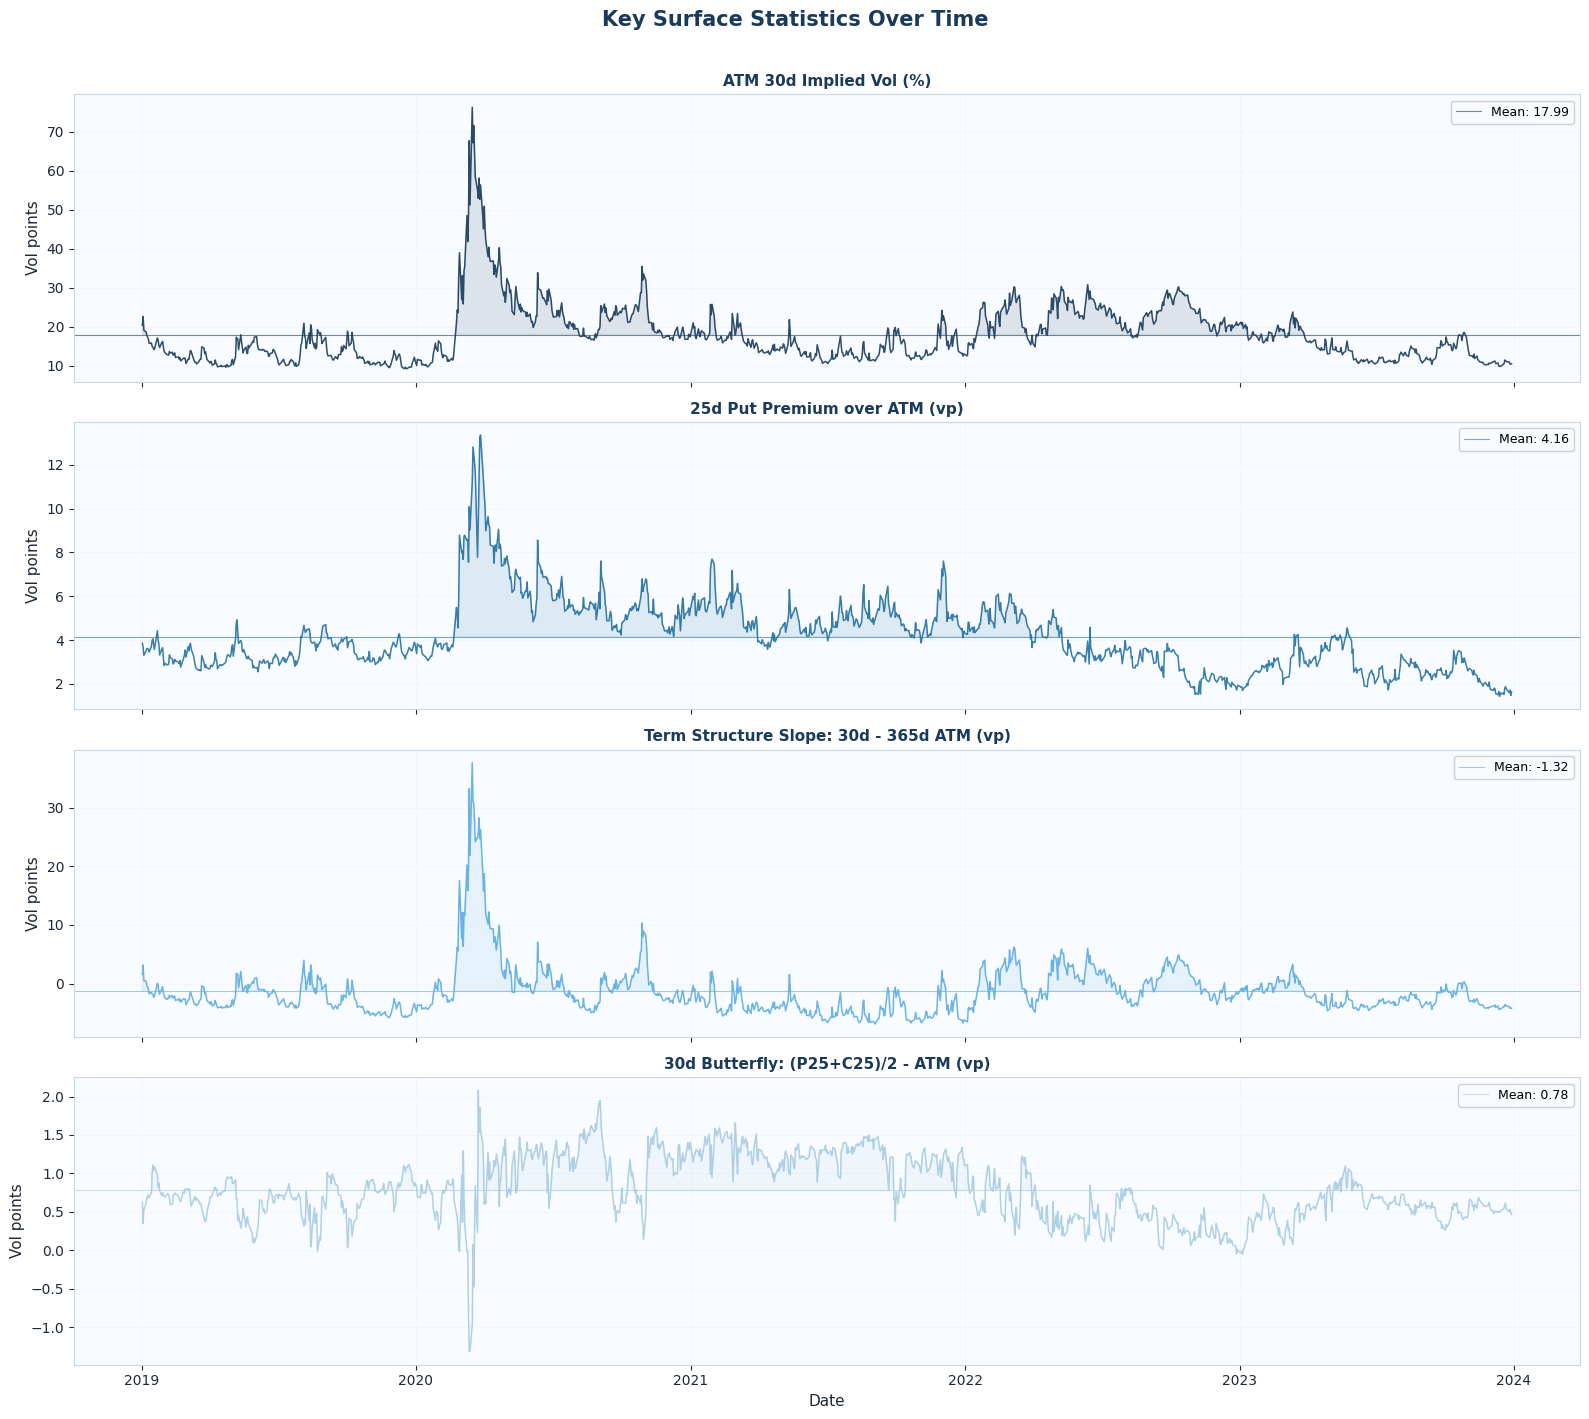

In [26]:
# ============================================================
# 6.1c  SKEW AND TERM STRUCTURE TIME SERIES
# ============================================================

atm_d    = ATM_IDX
t30_idx  = TENORS.index(30)
t365_idx = TENORS.index(365)

# FIX: skew = PUT25 minus ATM (was incorrectly using call side)
skew_30d    = surface_tensor[:, P25_IDX, t30_idx] - surface_tensor[:, atm_d, t30_idx]

# Term structure slope: 30d ATM minus 365d ATM
term_slope  = surface_tensor[:, atm_d, t30_idx] - surface_tensor[:, atm_d, t365_idx]

# ATM 30d vol
atm_30d     = surface_tensor[:, atm_d, t30_idx]

# FIX: butterfly = (P25 + C25) / 2 - ATM (was using C25 twice)
butterfly_30d = (surface_tensor[:, P25_IDX, t30_idx] +
                 surface_tensor[:, C25_IDX, t30_idx]) / 2 - surface_tensor[:, atm_d, t30_idx]

fig, axes = plt.subplots(4, 1, figsize=(16, 14), sharex=True)
fig.patch.set_facecolor('white')

series = [
    (atm_30d,       'ATM 30d Implied Vol (%)',                  BLUE_PALETTE[0]),
    (skew_30d,      '25d Put Premium over ATM (vp)',            BLUE_PALETTE[2]),
    (term_slope,    'Term Structure Slope: 30d - 365d ATM (vp)', BLUE_PALETTE[4]),
    (butterfly_30d, '30d Butterfly: (P25+C25)/2 - ATM (vp)',    BLUE_PALETTE[6]),
]

for ax, (data, title, colour) in zip(axes, series):
    ax.plot(dates_plot, data, color=colour, linewidth=1.1, alpha=0.9)
    ax.fill_between(dates_plot, data, data.mean(),
                    where=(data > data.mean()), alpha=0.12, color=colour)
    ax.axhline(data.mean(), color=colour, linewidth=0.8,
               linestyle='-', alpha=0.6, label=f'Mean: {data.mean():.2f}')
    ax.set_title(title, fontweight='bold', color=LSE_BLUE, fontsize=11)
    ax.set_ylabel('Vol points')
    ax.legend(fontsize=9, loc='upper right')
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Date')
fig.suptitle('Key Surface Statistics Over Time', fontsize=15,
             fontweight='bold', color=LSE_BLUE, y=1.01)
plt.tight_layout()
plt.show()

# Styled summary cards
from IPython.display import display, HTML

def stat_card(label, value, note, color):
    return f'''<div style="background:white;border:1px solid {color}33;border-top:3px solid {color};border-radius:10px;padding:14px 18px;min-width:190px;flex:1;">
  <div style="color:#888;font-size:11px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">{label}</div>
  <div style="font-size:20px;font-weight:800;color:{color};font-family:monospace;">{value}</div>
  <div style="color:#888;font-size:12px;margin-top:4px;">{note}</div>
</div>'''

display(HTML(f'''
<div style="display:flex;gap:12px;flex-wrap:wrap;margin:16px 0;font-family:sans-serif;">
  {stat_card("Mean ATM 30d",      f"{atm_30d.mean():.2f}%",      "Overall vol level",        "#1a3a5c")}
  {stat_card("Mean Put Premium",  f"{skew_30d.mean():.2f} vp",   "25d put over ATM",         "#e74c3c")}
  {stat_card("Mean Term Slope",   f"{term_slope.mean():.2f} vp", "30d minus 365d ATM",       "#2980b9")}
  {stat_card("Mean Butterfly",    f"{butterfly_30d.mean():.2f} vp","(P25+C25)/2 minus ATM",  "#8e44ad")}
</div>'''))

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 22px;margin:16px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:18px;">&#128270;</span> Reading the surface statistic time series</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">These four time series encode the market's evolving risk sentiment. <strong>ATM 30d vol</strong> (top panel) is the canonical fear gauge proxy: the COVID spike in Q1 2020 is unmistakable, as is the more gradual rise during the 2022 rate-hiking cycle. <strong>25d put premium</strong> (second panel) measures the extra cost investors pay for downside protection relative to ATM options. It spikes during risk-off episodes and compresses during complacent bull markets. Note the deep trough in March 2020 as put buyers flooded in. <strong>Term structure slope</strong> (third panel, 30d minus 365d ATM) is a leading indicator of regime transitions: when it goes strongly positive the market expects vol to rise; when it inverts as in March 2020, the market expects current stress to normalise. <strong>Butterfly</strong> (bottom panel) measures the fat-tail premium, specifically how much extra investors pay for the average of the 25d put and call wings relative to ATM. This reflects the pricing of kurtosis in the return distribution and tends to widen whenever tail risk of any kind is elevated.</div>
</div>

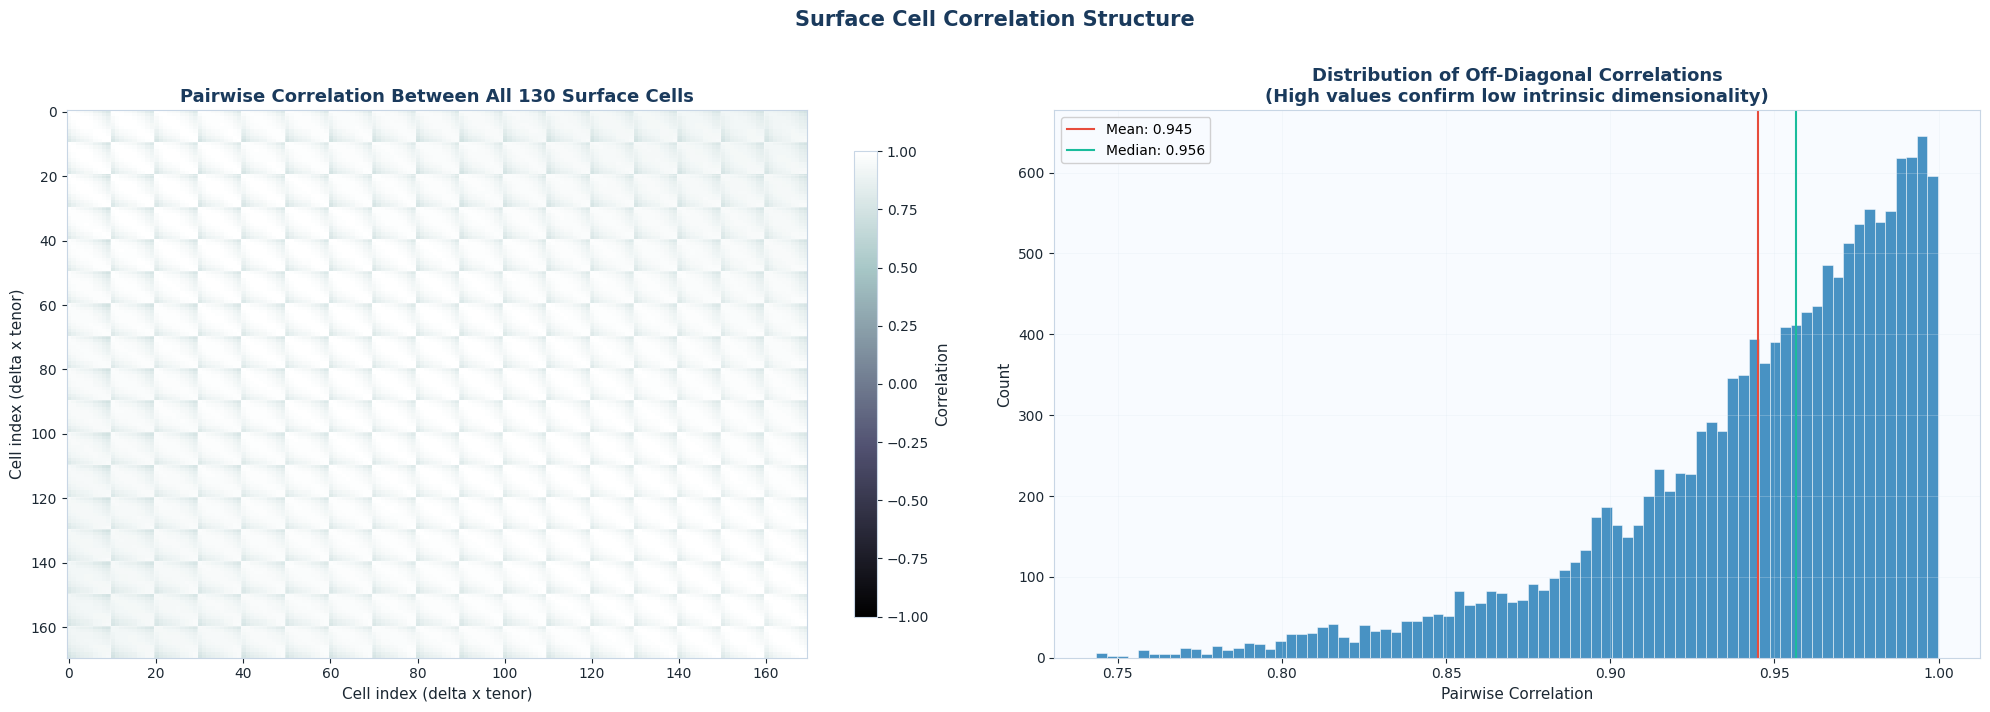

In [21]:
# ============================================================
# 6.1d  CROSS-CELL CORRELATION MATRIX
# ============================================================

# Flatten surface to (T, 130) and compute pairwise correlations
flat = surface_tensor.reshape(T_DAYS, -1)
corr_matrix = np.corrcoef(flat.T)   # (130, 130)

# Build cell labels
cell_labels = [f'D{d}\n{t}d' for d in DELTAS for t in TENORS]

fig, axes = plt.subplots(1, 2, figsize=(20, 7))

# Full correlation heatmap
im1 = axes[0].imshow(corr_matrix, cmap='bone', vmin=-1, vmax=1, aspect='auto')
axes[0].set_title('Pairwise Correlation Between All 130 Surface Cells',
                  fontweight='bold', color=LSE_BLUE)
axes[0].set_xlabel('Cell index (delta x tenor)')
axes[0].set_ylabel('Cell index (delta x tenor)')
# Add delta boundary lines
for i in range(1, N_DELTAS):
    axes[0].axhline(i * N_TENORS - 0.5, color='white', linewidth=0.4, alpha=0.5)
    axes[0].axvline(i * N_TENORS - 0.5, color='white', linewidth=0.4, alpha=0.5)
plt.colorbar(im1, ax=axes[0], label='Correlation', shrink=0.85)

# Distribution of off-diagonal correlations
off_diag = corr_matrix[np.triu_indices_from(corr_matrix, k=1)]
axes[1].hist(off_diag, bins=80, color=ACCENT_BLUE, edgecolor='white',
             alpha=0.85, linewidth=0.4)
axes[1].axvline(off_diag.mean(), color='#e74c3c', linewidth=1.5,
                linestyle='-', label=f'Mean: {off_diag.mean():.3f}')
axes[1].axvline(np.median(off_diag), color='#1abc9c', linewidth=1.5,
                linestyle='-', label=f'Median: {np.median(off_diag):.3f}')
axes[1].set_xlabel('Pairwise Correlation')
axes[1].set_ylabel('Count')
axes[1].set_title('Distribution of Off-Diagonal Correlations\n(High values confirm low intrinsic dimensionality)',
                  fontweight='bold', color=LSE_BLUE)
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

fig.suptitle('Surface Cell Correlation Structure', fontsize=15,
             fontweight='bold', color=LSE_BLUE, y=1.01)
plt.tight_layout()
plt.show()

pct_above_09 = (off_diag > 0.9).mean() * 100
pct_above_095 = (off_diag > 0.95).mean() * 100
pct_above_08  = (off_diag > 0.8).mean() * 100

display(HTML(f'''
<div style="font-family:sans-serif;margin:16px 0;display:flex;gap:14px;flex-wrap:wrap;">

  <div style="background:linear-gradient(135deg,#eaf4fd,#d6eaf8);border:1px solid #2980b933;border-top:3px solid #2980b9;border-radius:10px;padding:14px 20px;flex:1;min-width:180px;">
    <div style="color:#888;font-size:11px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Correlation &gt; 0.80</div>
    <div style="font-size:24px;font-weight:800;color:#1a3a5c;font-family:monospace;">{pct_above_08:.1f}%</div>
    <div style="color:#555;font-size:12px;margin-top:4px;">of all cell pairs</div>
  </div>

  <div style="background:linear-gradient(135deg,#e8f8f2,#d5f5e3);border:1px solid #1abc9c33;border-top:3px solid #1abc9c;border-radius:10px;padding:14px 20px;flex:1;min-width:180px;">
    <div style="color:#888;font-size:11px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Correlation &gt; 0.90</div>
    <div style="font-size:24px;font-weight:800;color:#0d6e56;font-family:monospace;">{pct_above_09:.1f}%</div>
    <div style="color:#555;font-size:12px;margin-top:4px;">of all cell pairs</div>
  </div>

  <div style="background:linear-gradient(135deg,#fef9e7,#fdebd0);border:1px solid #f39c1233;border-top:3px solid #f39c12;border-radius:10px;padding:14px 20px;flex:1;min-width:180px;">
    <div style="color:#888;font-size:11px;letter-spacing:2px;text-transform:uppercase;margin-bottom:4px;">Correlation &gt; 0.95</div>
    <div style="font-size:24px;font-weight:800;color:#c0530a;font-family:monospace;">{pct_above_095:.1f}%</div>
    <div style="color:#555;font-size:12px;margin-top:4px;">of all cell pairs</div>
  </div>

  <div style="background:linear-gradient(135deg,#f5eeff,#ead5f9);border:1px solid #8e44ad33;border-top:3px solid #8e44ad;border-radius:10px;padding:14px 20px;flex:2;min-width:260px;display:flex;align-items:center;gap:14px;">
    <span style="font-size:32px;">&#128161;</span>
    <div>
      <div style="font-weight:700;color:#4a1a6e;font-size:13px;margin-bottom:4px;">What this means for modelling</div>
      <div style="color:#1c2833;font-size:12.5px;line-height:1.6;">When {pct_above_09:.0f}% of cell pairs have correlation above 0.9, the surface is effectively controlled by very few latent factors. This directly justifies the VAE bottleneck and explains why PCA with 3 components explains ~97% of variance.</div>
    </div>
  </div>

</div>
'''))

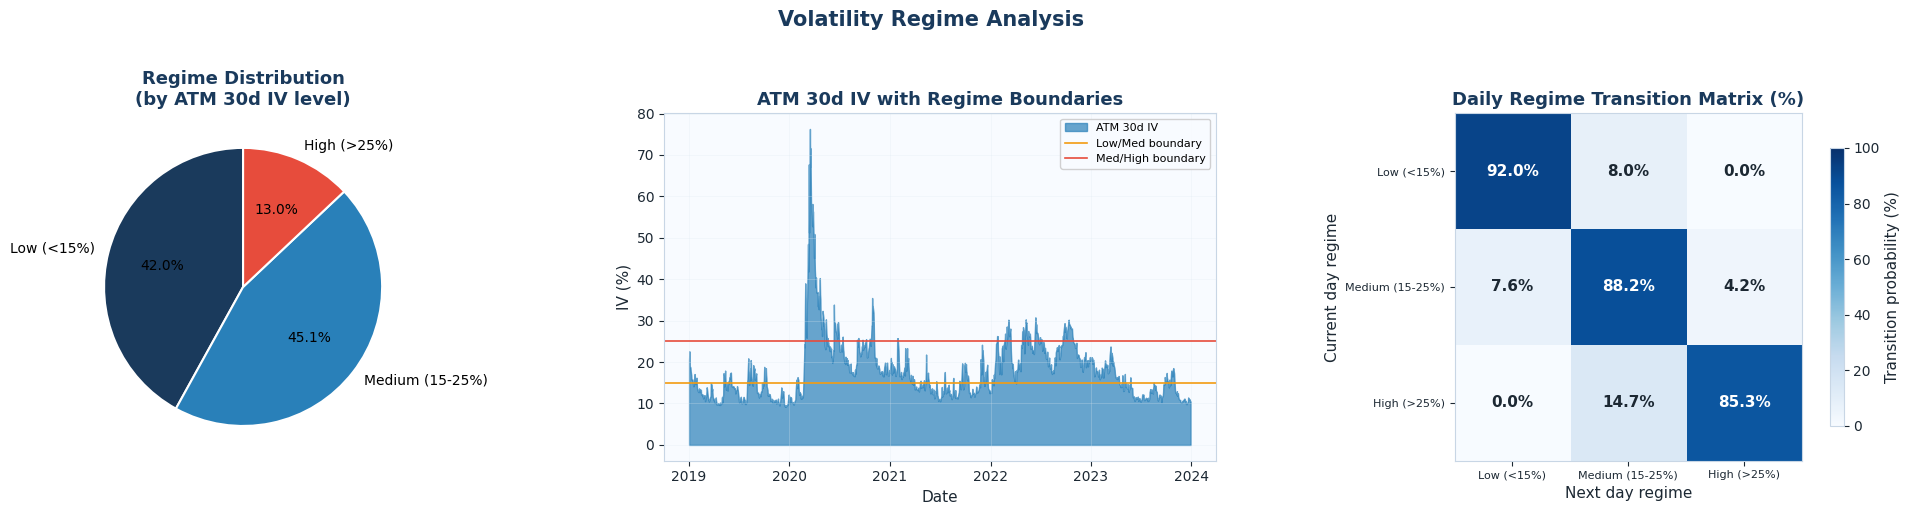

In [22]:
# ============================================================
# 6.1e  REGIME DISTRIBUTION AND TRANSITION HEATMAP
# ============================================================

atm_30d_ts = surface_tensor[:, ATM_IDX, T30_IDX]

# Define regimes
regime_labels = np.where(atm_30d_ts < 15, 0,
                np.where(atm_30d_ts < 25, 1, 2))
regime_names  = ['Low (<15%)', 'Medium (15-25%)', 'High (>25%)']
regime_counts = [np.sum(regime_labels == i) for i in range(3)]
regime_colours = [BLUE_PALETTE[0], BLUE_PALETTE[3], '#e74c3c']

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Pie chart
axes[0].pie(regime_counts, labels=regime_names, colors=regime_colours,
            autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
            textprops={'fontsize': 10})
axes[0].set_title('Regime Distribution\n(by ATM 30d IV level)',
                  fontweight='bold', color=LSE_BLUE)

# Regime over time
axes[1].fill_between(dates_plot, atm_30d_ts, alpha=0.7,
                     color=ACCENT_BLUE, label='ATM 30d IV')
for threshold, colour, label in [(15, '#f39c12', 'Low/Med boundary'),
                                  (25, '#e74c3c', 'Med/High boundary')]:
    axes[1].axhline(threshold, color=colour, linewidth=1.2,
                    linestyle='-', label=label)
axes[1].set_title('ATM 30d IV with Regime Boundaries',
                  fontweight='bold', color=LSE_BLUE)
axes[1].set_xlabel('Date')
axes[1].set_ylabel('IV (%)')
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

# Transition matrix
trans = np.zeros((3, 3))
for t in range(len(regime_labels) - 1):
    trans[regime_labels[t], regime_labels[t+1]] += 1
trans_pct = trans / trans.sum(axis=1, keepdims=True) * 100

im = axes[2].imshow(trans_pct, cmap='Blues', vmin=0, vmax=100)
for i in range(3):
    for j in range(3):
        axes[2].text(j, i, f'{trans_pct[i,j]:.1f}%',
                     ha='center', va='center',
                     fontsize=11, fontweight='bold',
                     color='white' if trans_pct[i,j] > 50 else DARK_TEXT)
axes[2].set_xticks(range(3)); axes[2].set_xticklabels(regime_names, fontsize=8)
axes[2].set_yticks(range(3)); axes[2].set_yticklabels(regime_names, fontsize=8)
axes[2].set_xlabel('Next day regime')
axes[2].set_ylabel('Current day regime')
axes[2].set_title('Daily Regime Transition Matrix (%)',
                  fontweight='bold', color=LSE_BLUE)
plt.colorbar(im, ax=axes[2], label='Transition probability (%)', shrink=0.8)

fig.suptitle('Volatility Regime Analysis', fontsize=15,
             fontweight='bold', color=LSE_BLUE, y=1.02)
plt.tight_layout()
plt.show()

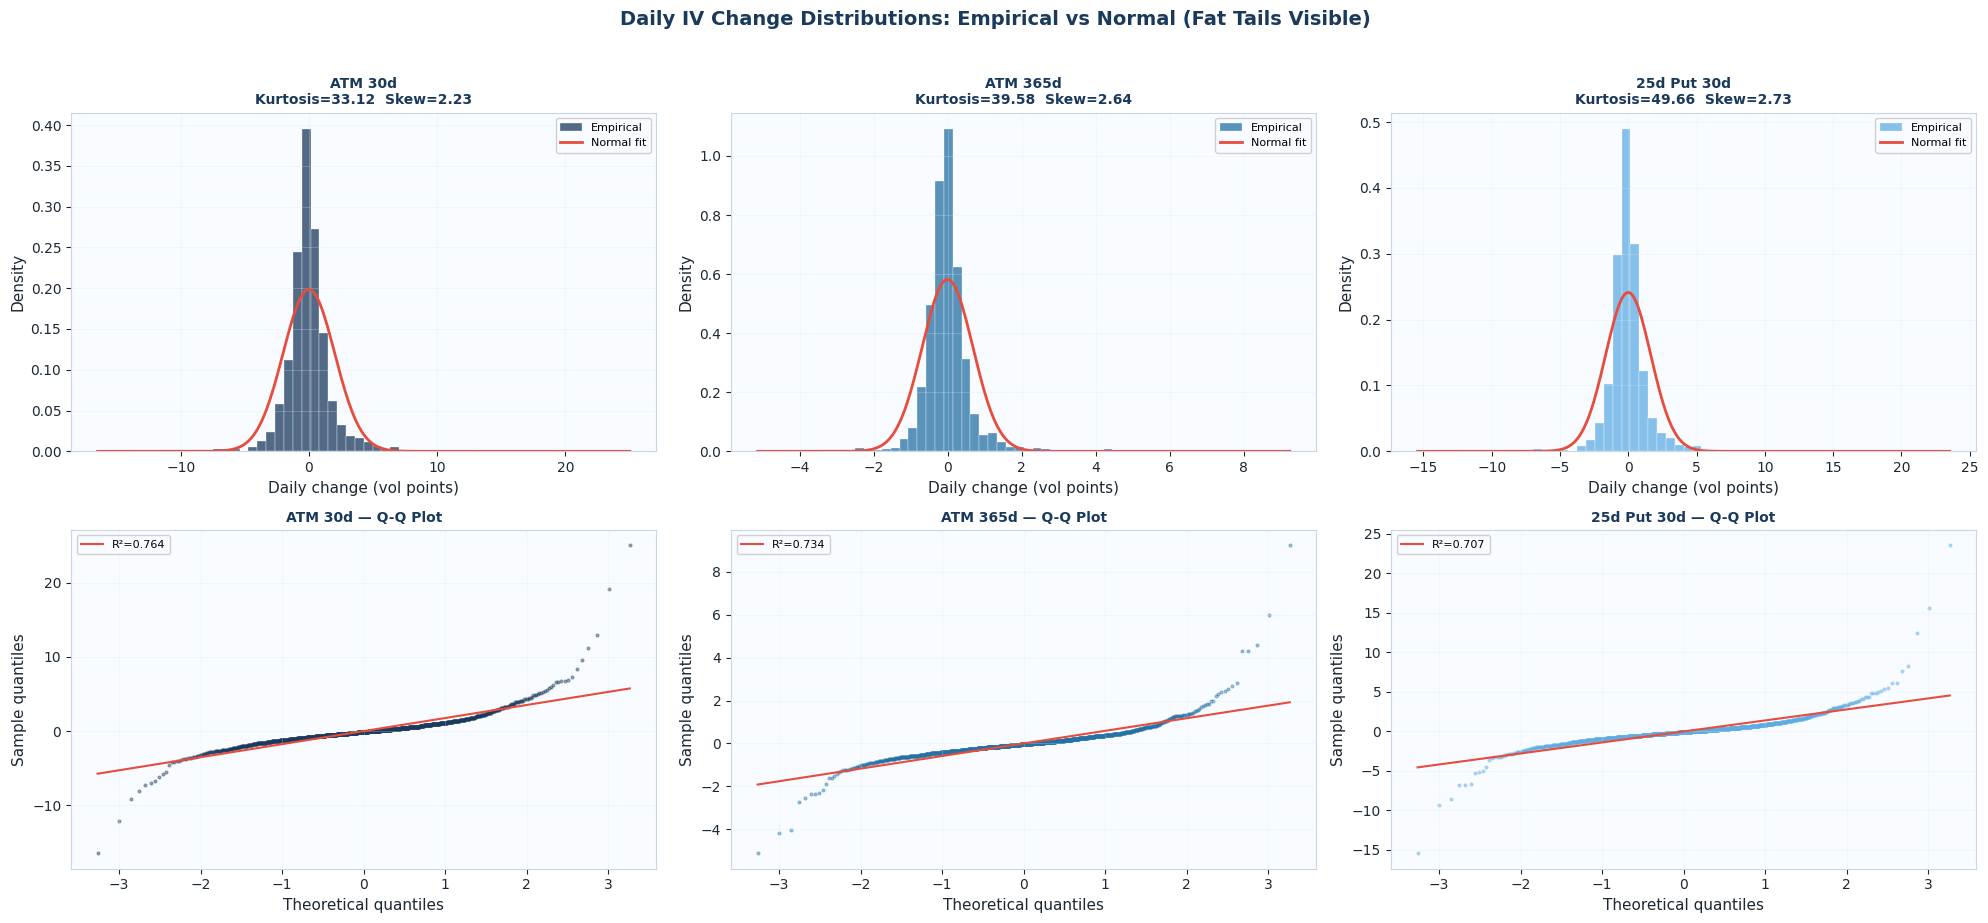

In [23]:
# ============================================================
# 6.1f  DAILY SURFACE CHANGE DISTRIBUTIONS
# ============================================================

daily_changes = np.diff(surface_tensor, axis=0)   # (T-1, N_d, N_t)

atm_d   = DELTAS.index(50)
t30_idx = TENORS.index(30)
t365_idx = TENORS.index(365)
d25_idx = DELTAS.index(25)

# Selected cells to study
cells = {
    'ATM 30d':      daily_changes[:, atm_d,   t30_idx],
    'ATM 365d':     daily_changes[:, atm_d,   t365_idx],
    '25d Put 30d':  daily_changes[:, d25_idx, t30_idx],
}

fig, axes = plt.subplots(2, 3, figsize=(20, 9))

for col, (label, data) in enumerate(cells.items()):
    # Histogram with normal overlay
    ax = axes[0, col]
    x  = np.linspace(data.min(), data.max(), 300)
    mu, sig = data.mean(), data.std()
    ax.hist(data, bins=60, density=True, color=BLUE_PALETTE[col*2],
            alpha=0.75, edgecolor='white', linewidth=0.3, label='Empirical')
    ax.plot(x, stats.norm.pdf(x, mu, sig), color='#e74c3c',
            linewidth=2, label='Normal fit')
    ax.set_title(f'{label}\nKurtosis={stats.kurtosis(data):.2f}  Skew={stats.skew(data):.2f}',
                 fontweight='bold', color=LSE_BLUE, fontsize=10)
    ax.set_xlabel('Daily change (vol points)')
    ax.set_ylabel('Density')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

    # Q-Q plot
    ax2 = axes[1, col]
    (osm, osr), (slope, intercept, r) = stats.probplot(data, dist='norm')
    ax2.scatter(osm, osr, s=4, alpha=0.4, color=BLUE_PALETTE[col*2])
    ax2.plot(osm, slope * np.array(osm) + intercept,
             color='#e74c3c', linewidth=1.5, label=f'R²={r**2:.3f}')
    ax2.set_title(f'{label} — Q-Q Plot', fontweight='bold', color=LSE_BLUE, fontsize=10)
    ax2.set_xlabel('Theoretical quantiles')
    ax2.set_ylabel('Sample quantiles')
    ax2.legend(fontsize=8)
    ax2.grid(True, alpha=0.3)

fig.suptitle('Daily IV Change Distributions: Empirical vs Normal (Fat Tails Visible)',
             fontsize=14, fontweight='bold', color=LSE_BLUE, y=1.02)
plt.tight_layout()
plt.show()

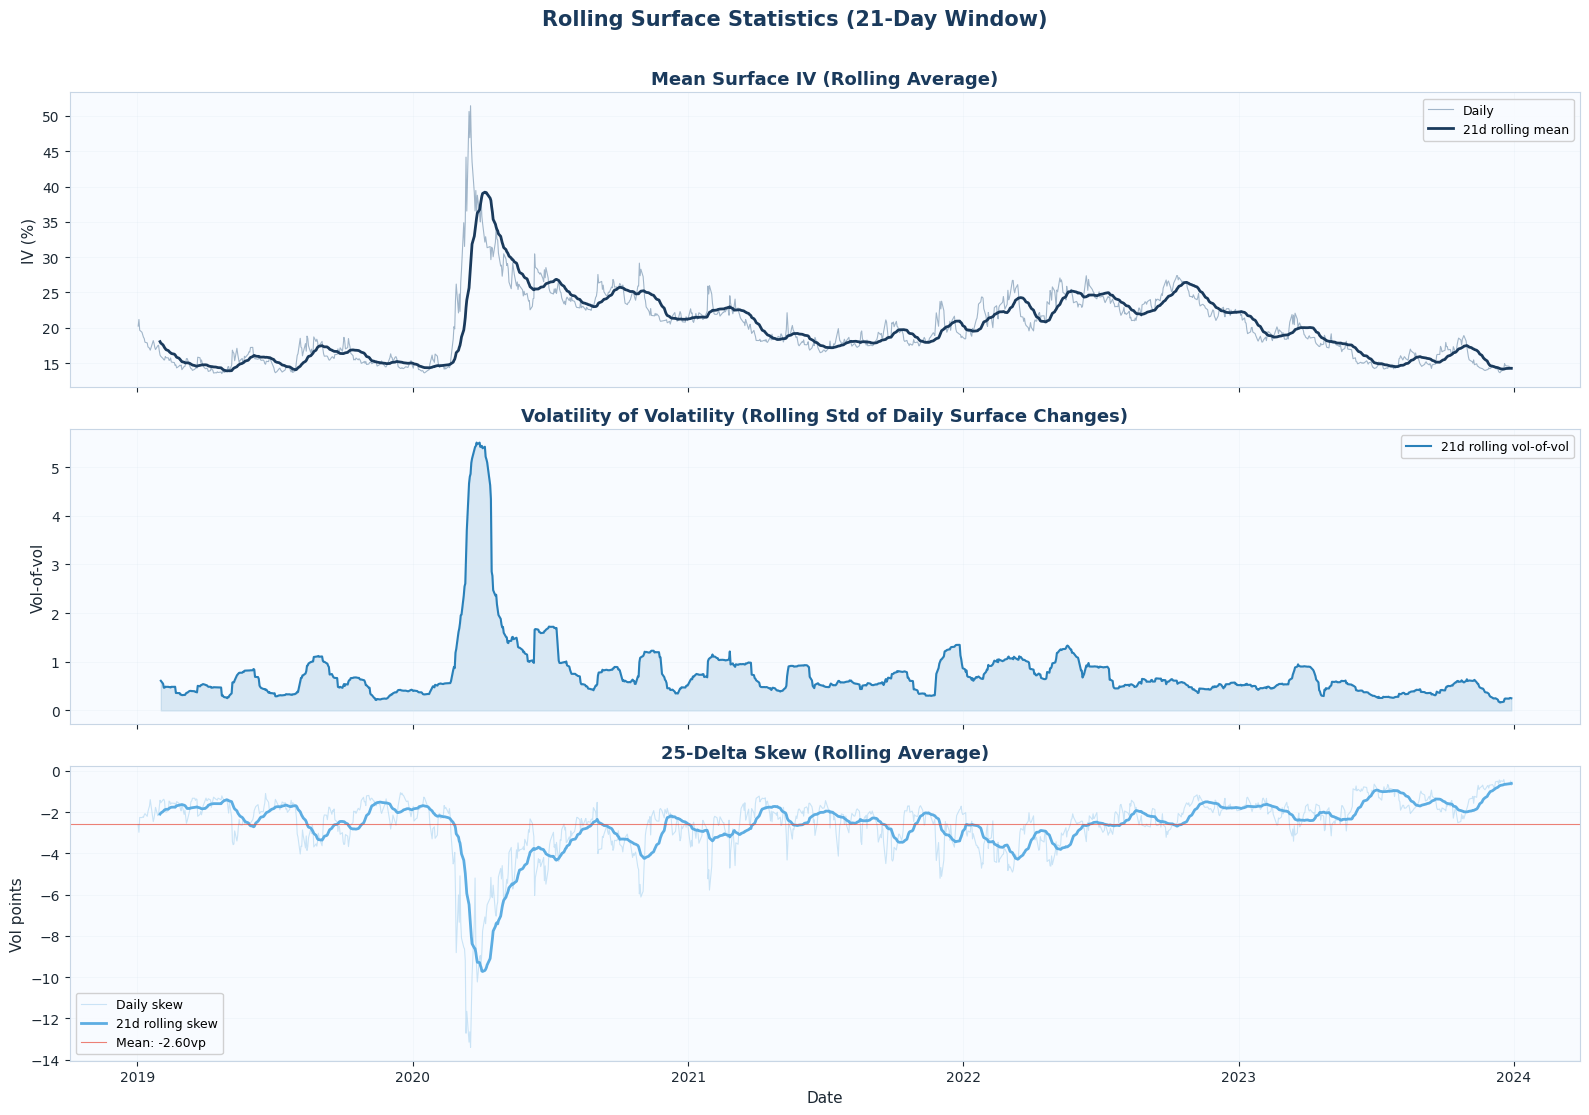

In [24]:
# ============================================================
# 6.1g  ROLLING VOLATILITY OF VOLATILITY
# ============================================================

daily_changes_flat = np.diff(surface_tensor, axis=0).reshape(T_DAYS - 1, -1)
dates_changes      = dates_plot[1:]

window = 21   # ~1 trading month

# Rolling std of daily changes (vol of vol proxy) - align length explicitly
rolling_vol_of_vol = pd.DataFrame(daily_changes_flat).rolling(window).std().mean(axis=1).values
# Trim both to the same length
n_common = min(len(dates_changes), len(rolling_vol_of_vol))
dates_changes_plot = dates_changes[:n_common]
rvov_plot          = rolling_vol_of_vol[:n_common]

# Rolling mean surface IV
rolling_mean_iv = pd.Series(surface_tensor.mean(axis=(1, 2))).rolling(window).mean().values

# Rolling 25d skew
atm_d   = DELTAS.index(50)
d25_idx = DELTAS.index(25)
t30_idx = TENORS.index(30)
skew_ts      = surface_tensor[:, d25_idx, t30_idx] - surface_tensor[:, atm_d, t30_idx]
rolling_skew = pd.Series(skew_ts).rolling(window).mean().values

fig, axes = plt.subplots(3, 1, figsize=(16, 11), sharex=True)

ax = axes[0]
ax.plot(dates_plot, surface_tensor.mean(axis=(1, 2)),
        color=BLUE_PALETTE[1], linewidth=0.8, alpha=0.4, label='Daily')
ax.plot(dates_plot, rolling_mean_iv, color=BLUE_PALETTE[0],
        linewidth=2, label=f'{window}d rolling mean')
ax.set_title('Mean Surface IV (Rolling Average)', fontweight='bold', color=LSE_BLUE)
ax.set_ylabel('IV (%)'); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(dates_changes_plot, rvov_plot, color=BLUE_PALETTE[3],
        linewidth=1.5, label=f'{window}d rolling vol-of-vol')
ax.fill_between(dates_changes_plot, rvov_plot, alpha=0.15, color=BLUE_PALETTE[3])
ax.set_title('Volatility of Volatility (Rolling Std of Daily Surface Changes)',
             fontweight='bold', color=LSE_BLUE)
ax.set_ylabel('Vol-of-vol'); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

ax = axes[2]
ax.plot(dates_plot, skew_ts, color=BLUE_PALETTE[5],
        linewidth=0.8, alpha=0.4, label='Daily skew')
ax.plot(dates_plot, rolling_skew, color=BLUE_PALETTE[4],
        linewidth=2, label=f'{window}d rolling skew')
ax.axhline(skew_ts.mean(), color='#e74c3c', linewidth=0.8,
           linestyle='-', alpha=0.7, label=f'Mean: {skew_ts.mean():.2f}vp')
ax.set_title('25-Delta Skew (Rolling Average)', fontweight='bold', color=LSE_BLUE)
ax.set_ylabel('Vol points'); ax.set_xlabel('Date')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

fig.suptitle(f'Rolling Surface Statistics ({window}-Day Window)',
             fontsize=15, fontweight='bold', color=LSE_BLUE, y=1.01)
plt.tight_layout()
plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 22px;margin:16px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:12px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:18px;">&#128270;</span>Regimes, Fat Tails, and Rolling Dynamics</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">

<p style="margin:0 0 10px 0;"><strong>Regime structure (first plot).</strong> Our 2019-2023 sample splits roughly into 42% low-vol days (ATM 30d below 15%), 45% medium-vol, and 13% high-vol. The transition matrix is the most important takeaway: diagonal entries are all above 85%, which means once you are in a regime you tend to stay there. The probability of jumping directly from low-vol to high-vol in a single day is essentially zero. This is exactly the volatility clustering we expect from the ACF analysis, and it is why the ConvLSTM has an edge over the single-snapshot CNN: knowing that you have been in a low-vol regime for two weeks is informative about tomorrow, even if today's surface level alone is not enough.</p>

<p style="margin:0 0 10px 0;"><strong>Fat tails in daily IV changes (second plot).</strong> The histograms and Q-Q plots confirm something important: daily changes in implied volatility are <strong>not normally distributed</strong>. Excess kurtosis values of 33 to 50 across the three cells shown mean the tails are dramatically fatter than Gaussian. The Q-Q plots show the classic S-curve of a heavy-tailed distribution: the empirical quantiles fan out far beyond the normal reference line at both ends. This has two implications. First, our MSE loss will be dominated by the rare large moves (the March 2020 spike), not the typical quiet days. Second, the surface dynamics our models need to learn are fundamentally non-Gaussian, which is part of why linear baselines like the VAR(1) on PCA factors will struggle during regime transitions even if they work well on average.</p>

<p style="margin:0;"><strong>Rolling dynamics (third plot).</strong> The 21-day rolling statistics reveal the time-varying nature of the surface. The vol-of-vol panel (middle) is particularly telling: during calm periods it hovers near 0.3-0.5, then spikes to above 5 during March 2020 before gradually normalising. This means the signal-to-noise ratio of our prediction task is itself time-varying. Models evaluated only on average MSE may look fine overall while failing badly in exactly the periods that matter most for risk management. The rolling skew (bottom) shows that the put premium is relatively stable around -2 vol points in normal conditions but becomes highly volatile during stress, which is when accurate skew prediction is most valuable for hedging.</p>

</div>
</div>

<div style="display:flex;align-items:center;gap:12px;margin:26px 0 14px 0;">
<div style="background:linear-gradient(135deg,#2980b9,#1a3a5c);min-width:36px;height:36px;border-radius:8px;display:flex;align-items:center;justify-content:center;">
<span style="color:white;font-size:12px;font-weight:700;">6.2</span>
</div>
<h3 style="color:#1a3a5c;font-family:Georgia,serif;font-size:20px;margin:0;border-bottom:2px solid #d6eaf8;padding-bottom:6px;flex-grow:1;">Surface Dynamics Over Time</h3>
</div>
<p style="font-size:14px;line-height:1.75;color:#1c2833;">We track three time series to understand the temporal structure we need to model: the ATM term structure, the 30-day smile across all deltas, and the overall surface mean. This reveals the regime structure of our 2019-2023 sample: a calm 2019, the COVID crash of March 2020, the post-COVID recovery, and the gradual 2022 rate-hiking cycle.</p>

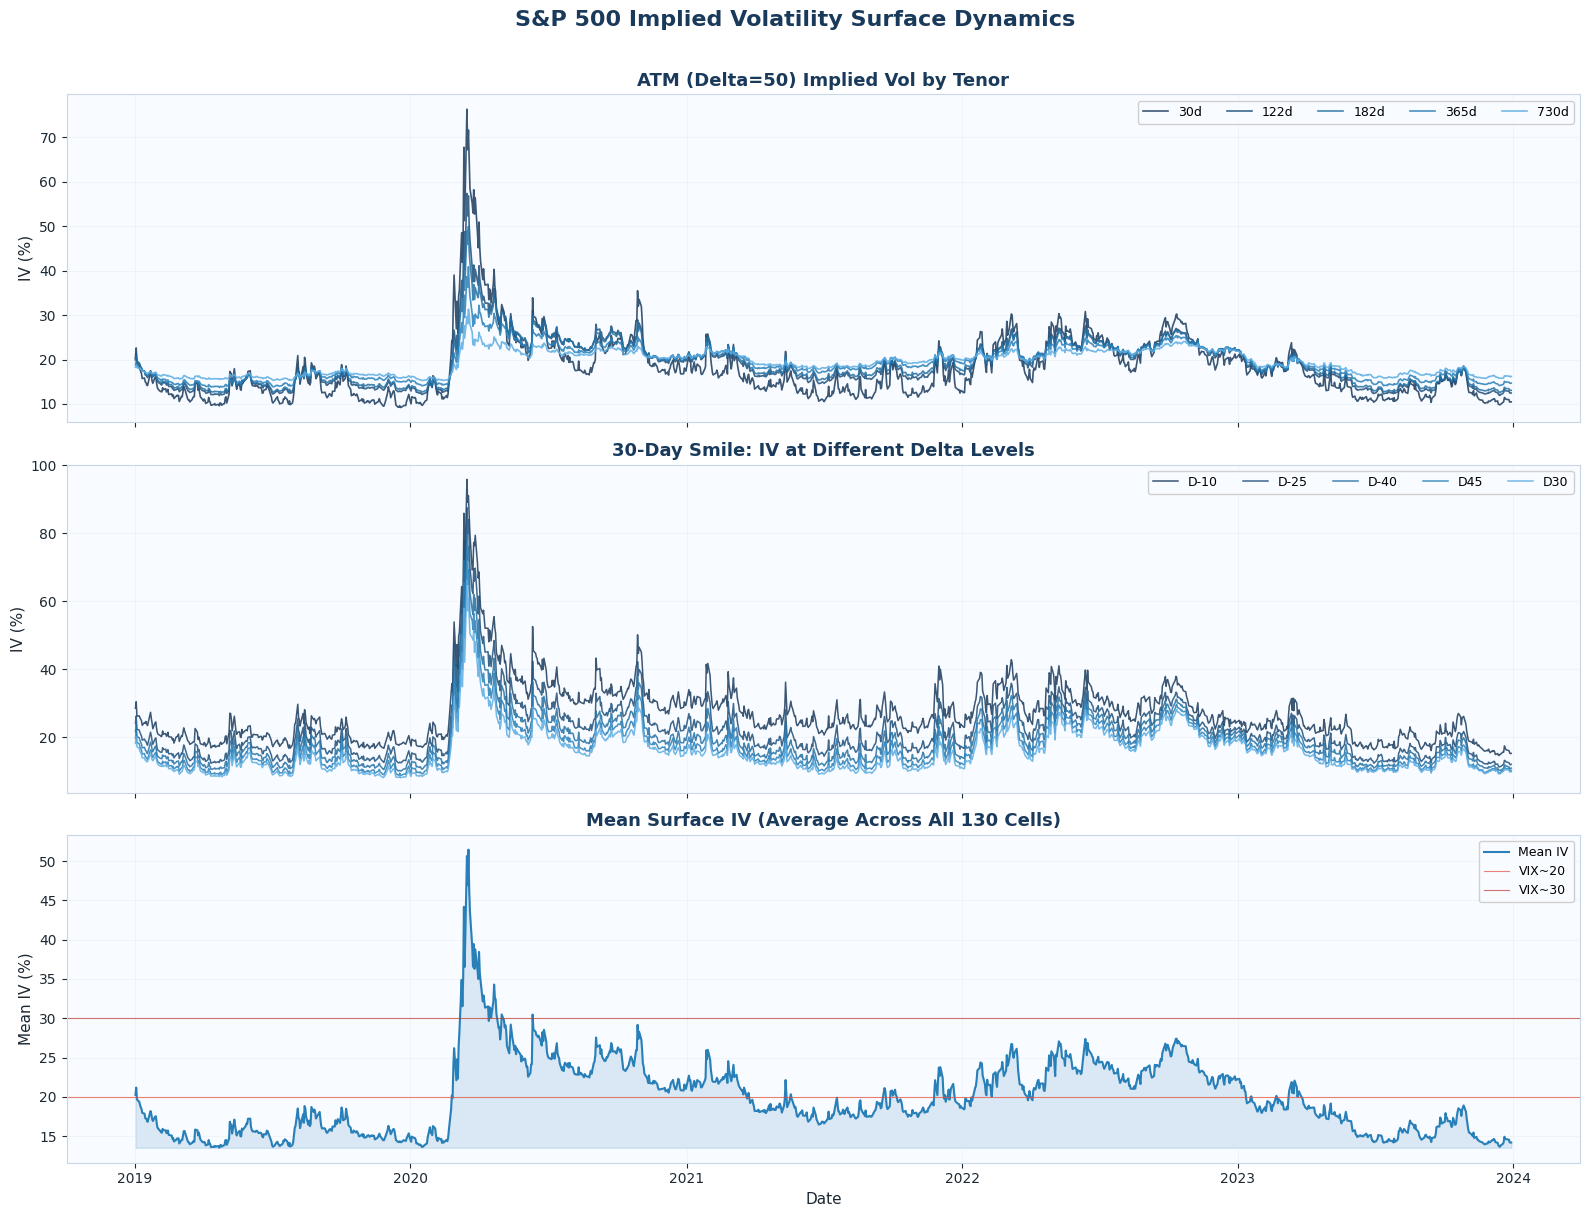

In [25]:
# ============================================================
# 6.2  SURFACE DYNAMICS OVER TIME
# ============================================================

dates_plot = pd.to_datetime(dates_array)
atm_idx    = ATM_IDX
tenor30_idx = T30_IDX

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)
fig.patch.set_facecolor('white')

# (a) ATM vol at selected tenors
tenor_highlight = [0, 3, 5, 7, 9]  # 30d, 122d, 182d, 365d, 730d
for k, ti in enumerate(tenor_highlight):
    axes[0].plot(dates_plot, surface_tensor[:, atm_idx, ti],
                 linewidth=1.2, alpha=0.85,
                 label=f'{TENORS[ti]}d', color=BLUE_PALETTE[k])
axes[0].set_title('ATM (Delta=50) Implied Vol by Tenor', fontweight='bold', color=LSE_BLUE)
axes[0].set_ylabel('IV (%)')
axes[0].legend(ncol=5, fontsize=9)
axes[0].grid(True, alpha=0.4)

# (b) 30-day smile level at selected deltas
delta_highlight = [0, 3, 6, 9, 12]  # D20, D35, D50, D65, D80
for k, di in enumerate(delta_highlight):
    axes[1].plot(dates_plot, surface_tensor[:, di, tenor30_idx],
                 linewidth=1.1, alpha=0.85,
                 label=f'D{DELTAS[di]}', color=BLUE_PALETTE[k])
axes[1].set_title('30-Day Smile: IV at Different Delta Levels', fontweight='bold', color=LSE_BLUE)
axes[1].set_ylabel('IV (%)')
axes[1].legend(ncol=5, fontsize=9)
axes[1].grid(True, alpha=0.4)

# (c) Mean surface IV with regime shading
mean_iv = surface_tensor.mean(axis=(1, 2))
axes[2].plot(dates_plot, mean_iv, color=ACCENT_BLUE, linewidth=1.5, label='Mean IV')
axes[2].fill_between(dates_plot, mean_iv, mean_iv.min(), alpha=0.15, color=ACCENT_BLUE)
# Regime lines
for level, label, c in [(20, 'VIX~20', '#e74c3c'), (30, 'VIX~30', '#c0392b')]:
    axes[2].axhline(level, color=c, linewidth=0.8, linestyle='-', alpha=0.7, label=label)
axes[2].set_title('Mean Surface IV (Average Across All 130 Cells)', fontweight='bold', color=LSE_BLUE)
axes[2].set_ylabel('Mean IV (%)')
axes[2].set_xlabel('Date')
axes[2].legend(fontsize=9)
axes[2].grid(True, alpha=0.4)

fig.suptitle('S&P 500 Implied Volatility Surface Dynamics', fontsize=16,
             fontweight='bold', color=LSE_BLUE, y=1.01)
plt.tight_layout()
plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 22px;margin:16px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:10px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:18px;">&#128270;</span> Reading the surface dynamics time series</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">

<p style="margin:0 0 10px 0;">The three panels reveal the dominant temporal patterns we need to model:</p>

<p style="margin:0 0 10px 0;"><strong>(1) Volatility clustering.</strong> Periods of high ATM vol (top panel) cluster together. A vol spike is followed by more elevated vol for days or weeks, not an immediate return to baseline. This is the surface-level manifestation of the GARCH effect and explains why the AR(1) coefficient for the level factor is so high (&#x03C6;&#x2081; &#x2248; 0.9).</p>

<p style="margin:0 0 10px 0;"><strong>(2) Regime shifts.</strong> The COVID crash (Q1 2020) is the dominant event in our sample, visible as a sharp spike across all three panels. The 2022 rate-hiking cycle is a more gradual but sustained elevation. Notice also that the second panel shows the deep OTM puts (dark lines) spike far more violently than ATM during March 2020: the tail was being repriced, not just the level.</p>

<p style="margin:0;"><strong>(3) Mean reversion.</strong> After spikes, all quantities return toward their long-run averages: sometimes slowly (level takes weeks to months), sometimes quickly (slope reverts within days to weeks). These dynamics directly motivate the temporal models: the ConvLSTM can learn the clustering pattern from recent trajectory, while the Transformer might identify regime-appropriate dynamics from distant history.</p>

</div>
</div>

<div style="display:flex;align-items:center;gap:12px;margin:26px 0 14px 0;">
<div style="background:linear-gradient(135deg,#2980b9,#1a3a5c);min-width:36px;height:36px;border-radius:8px;display:flex;align-items:center;justify-content:center;">
<span style="color:white;font-size:12px;font-weight:700;">6.3</span>
</div>
<h3 style="color:#1a3a5c;font-family:Georgia,serif;font-size:20px;margin:0;border-bottom:2px solid #d6eaf8;padding-bottom:6px;flex-grow:1;">PCA of Daily Surface Changes</h3>
</div>
<p style="font-size:14px;line-height:1.75;color:#1c2833;">We apply PCA to daily changes, not levels. Levels are highly persistent (AR coefficient ~0.9), so PCA on levels just finds the mean surface as PC1, which is useless for forecasting. Changes capture what actually varies from day to day. We fit PCA on the training set only to avoid lookahead bias.</p>

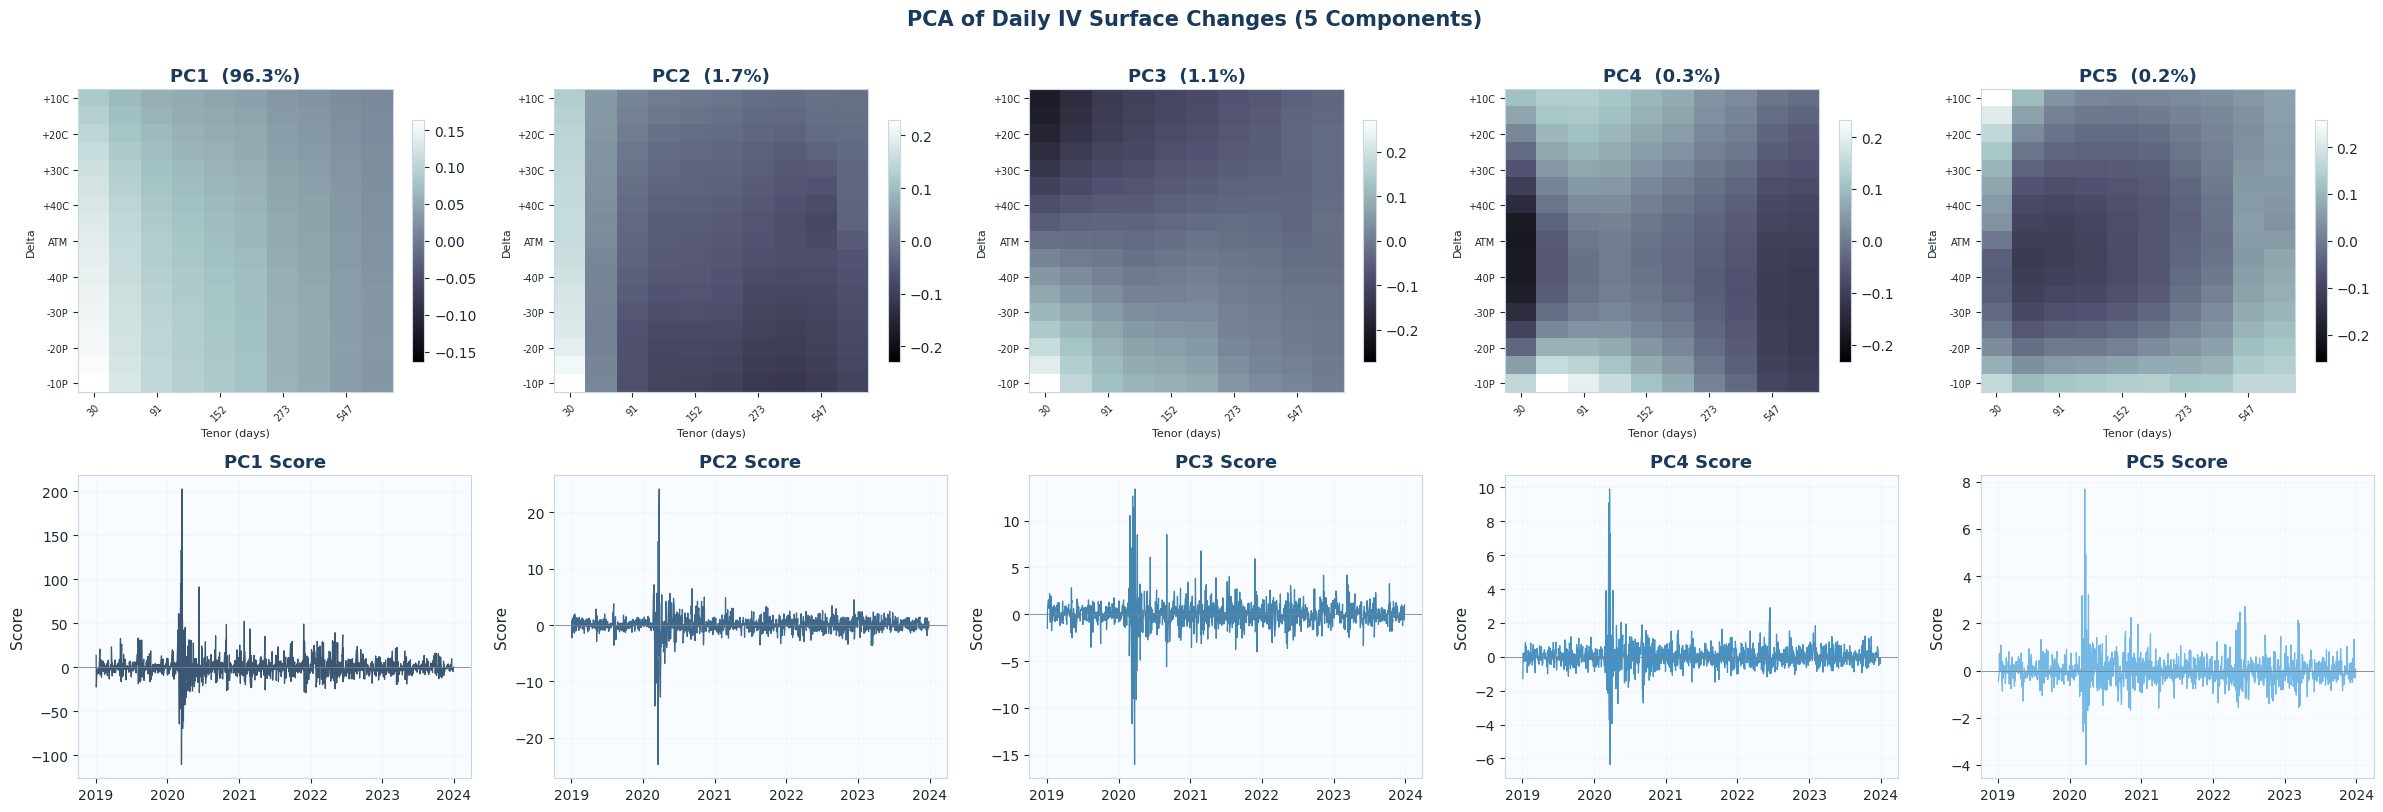

In [39]:
# ============================================================
# 6.3  PCA ON SURFACE CHANGES
# ============================================================

changes        = np.diff(surface_tensor, axis=0)
n_days_changes = changes.shape[0]
X_flat         = changes.reshape(n_days_changes, -1)

train_end_idx  = int(n_days_changes * 0.70)
pca_model      = PCA(n_components=5, random_state=RANDOM_SEED)
pca_model.fit(X_flat[:train_end_idx])

var_exp    = pca_model.explained_variance_ratio_ * 100
cumvar_exp = np.cumsum(var_exp)
scores_all = pca_model.transform(X_flat)   # (T-1, 5)

fig, axes = plt.subplots(2, 5, figsize=(24, 8))   # was (2, 4) — now one column per component

# Top row: eigenvectors
for k in range(5):
    ev   = pca_model.components_[k].reshape(N_DELTAS, N_TENORS)
    vmax = np.abs(ev).max()
    im   = axes[0, k].imshow(ev, cmap='bone', aspect='auto',
                              vmin=-vmax, vmax=vmax, origin='lower')
    axes[0, k].set_title(f'PC{k+1}  ({var_exp[k]:.1f}%)', fontweight='bold', color=LSE_BLUE)
    axes[0, k].set_xticks(range(N_TENORS)[::2])
    axes[0, k].set_xticklabels(TENORS[::2], fontsize=7, rotation=45)
    axes[0, k].set_yticks(range(N_DELTAS)[::2])
    axes[0, k].set_yticklabels(DELTA_LABELS[::2], fontsize=7)
    axes[0, k].set_xlabel('Tenor (days)', fontsize=8)
    axes[0, k].set_ylabel('Delta', fontsize=8)
    plt.colorbar(im, ax=axes[0, k], shrink=0.8)

# Bottom row: factor score time series
dates_scores = dates_plot[1:]
for k in range(5):
    axes[1, k].plot(dates_scores, scores_all[:, k],
                    color=BLUE_PALETTE[k], linewidth=0.9, alpha=0.85)
    axes[1, k].axhline(0, color='grey', linewidth=0.6, linestyle='-')
    axes[1, k].set_title(f'PC{k+1} Score', fontweight='bold', color=LSE_BLUE)
    axes[1, k].set_ylabel('Score')
    axes[1, k].grid(True, alpha=0.3)

fig.suptitle('PCA of Daily IV Surface Changes (5 Components)',
             fontsize=15, fontweight='bold', color=LSE_BLUE, y=1.01)
plt.tight_layout()
plt.show()

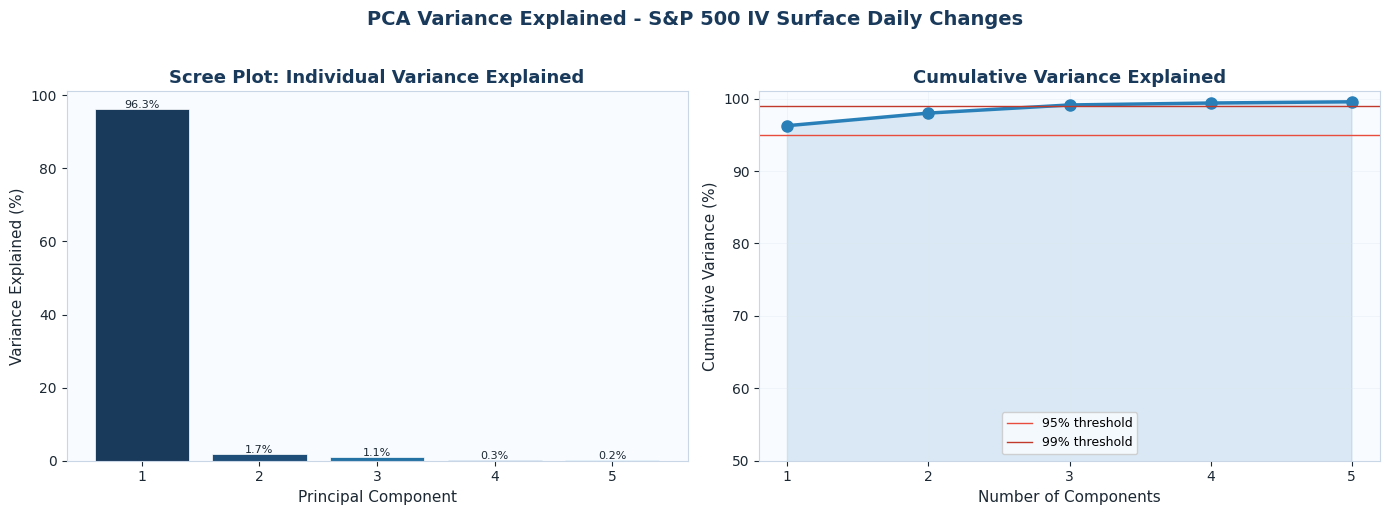

Component,Individual,Cumulative
PC1,96.3%,96.3%
PC2,1.7%,98.0%
PC3,1.1%,99.1%
PC4,0.3%,99.4%
PC5,0.2%,99.6%


In [37]:
# ============================================================
# 6.3b  SCREE PLOT AND CUMULATIVE VARIANCE
# ============================================================

from IPython.display import display, HTML

n_components = len(var_exp)   # 5

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot
ax1.bar(range(1, n_components + 1), var_exp,
        color=BLUE_PALETTE[:n_components], edgecolor='white', linewidth=0.5)
ax1.set_xlabel('Principal Component'); ax1.set_ylabel('Variance Explained (%)')
ax1.set_title('Scree Plot: Individual Variance Explained', fontweight='bold', color=LSE_BLUE)
ax1.set_xticks(range(1, n_components + 1))
for i, v in enumerate(var_exp):
    ax1.text(i + 1, v + 0.3, f'{v:.1f}%', ha='center', fontsize=8, color=DARK_TEXT)

# Cumulative
ax2.plot(range(1, n_components + 1), cumvar_exp, 'o-',
         color=ACCENT_BLUE, linewidth=2.5, markersize=8)
ax2.axhline(95, color='#e74c3c', linewidth=1, linestyle='-', label='95% threshold')
ax2.axhline(99, color='#c0392b', linewidth=1, linestyle='-', label='99% threshold')
ax2.fill_between(range(1, n_components + 1), cumvar_exp, alpha=0.15, color=ACCENT_BLUE)
ax2.set_xlabel('Number of Components'); ax2.set_ylabel('Cumulative Variance (%)')
ax2.set_title('Cumulative Variance Explained', fontweight='bold', color=LSE_BLUE)
ax2.set_xticks(range(1, n_components + 1)); ax2.set_ylim(50, 101)
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.4)

k95 = np.searchsorted(cumvar_exp, 95) + 1
k99 = np.searchsorted(cumvar_exp, 99) + 1

fig.suptitle('PCA Variance Explained - S&P 500 IV Surface Daily Changes',
             fontsize=14, fontweight='bold', color=LSE_BLUE, y=1.02)
plt.tight_layout()
plt.show()

# ── Styled HTML summary table + cards
colours = ['#1a3a5c', '#2980b9', '#5dade2', '#85c1e9', '#a9cce3']

rows_html = ''
for k in range(n_components):
    bar_w = var_exp[k] / var_exp[0] * 100
    rows_html += f'''
    <tr style="background:{'#f8fbff' if k % 2 == 0 else 'white'};">
      <td style="padding:9px 16px;font-weight:700;color:#1a3a5c;">PC{k+1}</td>
      <td style="padding:9px 16px;">
        <div style="display:flex;align-items:center;gap:10px;">
          <div style="background:#e8f4fd;border-radius:4px;height:12px;width:120px;overflow:hidden;">
            <div style="background:{colours[k]};width:{bar_w:.1f}%;height:100%;border-radius:4px;"></div>
          </div>
          <span style="font-family:monospace;font-size:13px;color:#1a3a5c;font-weight:600;">{var_exp[k]:.1f}%</span>
        </div>
      </td>
      <td style="padding:9px 16px;font-family:monospace;font-size:13px;color:#555;">{cumvar_exp[k]:.1f}%</td>
    </tr>'''

display(HTML(f'''
<div style="font-family:sans-serif;margin:16px 0;display:flex;gap:16px;flex-wrap:wrap;align-items:flex-start;">

  <div style="flex:2;min-width:300px;">
    <div style="background:linear-gradient(135deg,#1a3a5c,#2980b9);padding:11px 16px;border-radius:10px 10px 0 0;">
      <span style="color:white;font-weight:700;font-size:13px;">PCA Variance Explained</span>
    </div>
    <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 10px 10px;overflow:hidden;">
      <table style="width:100%;border-collapse:collapse;">
        <thead>
          <tr style="background:#eaf4fd;">
            <th style="padding:9px 16px;text-align:left;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Component</th>
            <th style="padding:9px 16px;text-align:left;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Individual</th>
            <th style="padding:9px 16px;text-align:left;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Cumulative</th>
          </tr>
        </thead>
        <tbody>{rows_html}</tbody>
      </table>
    </div>
  </div>

  <div style="flex:1;min-width:200px;display:flex;flex-direction:column;gap:12px;">
    <div style="background:linear-gradient(135deg,#0d6e56,#1abc9c);padding:16px 20px;border-radius:10px;color:white;text-align:center;">
      <div style="font-size:11px;letter-spacing:2px;text-transform:uppercase;opacity:0.8;margin-bottom:4px;">Components for 95%</div>
      <div style="font-size:36px;font-weight:800;font-family:monospace;">{k95}</div>
      <div style="font-size:12px;opacity:0.8;margin-top:2px;">PC1 alone = {var_exp[0]:.1f}%</div>
    </div>
    <div style="background:linear-gradient(135deg,#1a3a5c,#2471a3);padding:16px 20px;border-radius:10px;color:white;text-align:center;">
      <div style="font-size:11px;letter-spacing:2px;text-transform:uppercase;opacity:0.8;margin-bottom:4px;">Components for 99%</div>
      <div style="font-size:36px;font-weight:800;font-family:monospace;">{k99}</div>
      <div style="font-size:12px;opacity:0.8;margin-top:2px;">Top {k99} = {cumvar_exp[k99-1]:.1f}%</div>
    </div>
    <div style="background:linear-gradient(135deg,#4a1a6e,#7d3cba);padding:16px 20px;border-radius:10px;color:white;text-align:center;">
      <div style="font-size:11px;letter-spacing:2px;text-transform:uppercase;opacity:0.8;margin-bottom:4px;">Residual (PC4+)</div>
      <div style="font-size:36px;font-weight:800;font-family:monospace;">{100 - cumvar_exp[2]:.1f}%</div>
      <div style="font-size:12px;opacity:0.8;margin-top:2px;">noise + microstructure</div>
    </div>
  </div>

</div>
'''))

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 22px;margin:16px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:12px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:18px;">&#128270;</span> What the PCA results are telling us</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">

<p style="margin:0 0 10px 0;">The scree plot is striking: <strong>PC1 alone explains 96.3% of all daily surface variation</strong>. This is more concentrated than the typical ~80% reported in Cont and da Fonseca (2002), likely because our OTM-only surface is more homogeneous than a full call-only grid. On most days the entire surface just shifts up or down together. Everything else is a small correction on top of that.</p>

<p style="margin:0 0 10px 0;"><strong>PC1 (level, 96.3%):</strong> near-uniform positive loading across all 17 delta rows and all 10 tenors. A positive PC1 score means the whole surface shifted up: a classic volatility spike. The heatmap confirms this with near-uniform teal colour everywhere.</p>

<p style="margin:0 0 10px 0;"><strong>PC2 (term structure, 1.7%):</strong> the loading gradient runs along the <em>tenor axis</em>, with short-dated tenors loading positively and long-dated tenors loading negatively. A positive PC2 score means the term structure inverted: short-dated vol rose relative to long-dated vol, which is exactly what happens during acute stress like March 2020.</p>

<p style="margin:0 0 10px 0;"><strong>PC3 (skew/delta tilt, 1.1%):</strong> the loading gradient now runs along the <em>delta axis</em>, with puts loading differently from calls. This captures changes in the skew steepness: the put wing enriching or cheapening relative to the call wing independently of the overall level.</p>

<p style="margin:0 0 10px 0;"><strong>PC4 and PC5 (0.3% and 0.2%):</strong> the score time series show these are almost entirely noise except for the March 2020 spike. They are included in the VAE latent space (d=5) to give the model a small amount of room for nonlinear structure, but the VAR baseline only uses the top 3.</p>

<p style="margin:0;"><strong>For model design:</strong> our VAR(1) baseline uses the top 3 PCA factor scores. If no neural network can beat this simple linear model, surface dynamics are essentially linear and deep learning is not adding value. Beating the PCA-VAR is the real test.</p>

</div>
</div>

<div style="display:flex;align-items:center;gap:12px;margin:26px 0 14px 0;">
<div style="background:linear-gradient(135deg,#2980b9,#1a3a5c);min-width:36px;height:36px;border-radius:8px;display:flex;align-items:center;justify-content:center;">
<span style="color:white;font-size:12px;font-weight:700;">6.4</span>
</div>
<h3 style="color:#1a3a5c;font-family:Georgia,serif;font-size:20px;margin:0;border-bottom:2px solid #d6eaf8;padding-bottom:6px;flex-grow:1;">Autocorrelation and Factor Persistence</h3>
</div>
<p style="font-size:14px;line-height:1.75;color:#1c2833;">The ACF structure of the three factor scores directly tells us how long the predictable signal lasts, which determines what lookback window K makes sense for the temporal models. A factor with high autocorrelation at many lags justifies a longer lookback. A near-white-noise factor does not benefit from long lookbacks.</p>

PC1 (Level)                phi_1=-0.2671   half-life=0.5 days
PC2 (Slope)                phi_1=0.1005   half-life=0.3 days
PC3 (Curvature)            phi_1=-0.0900   half-life=0.3 days


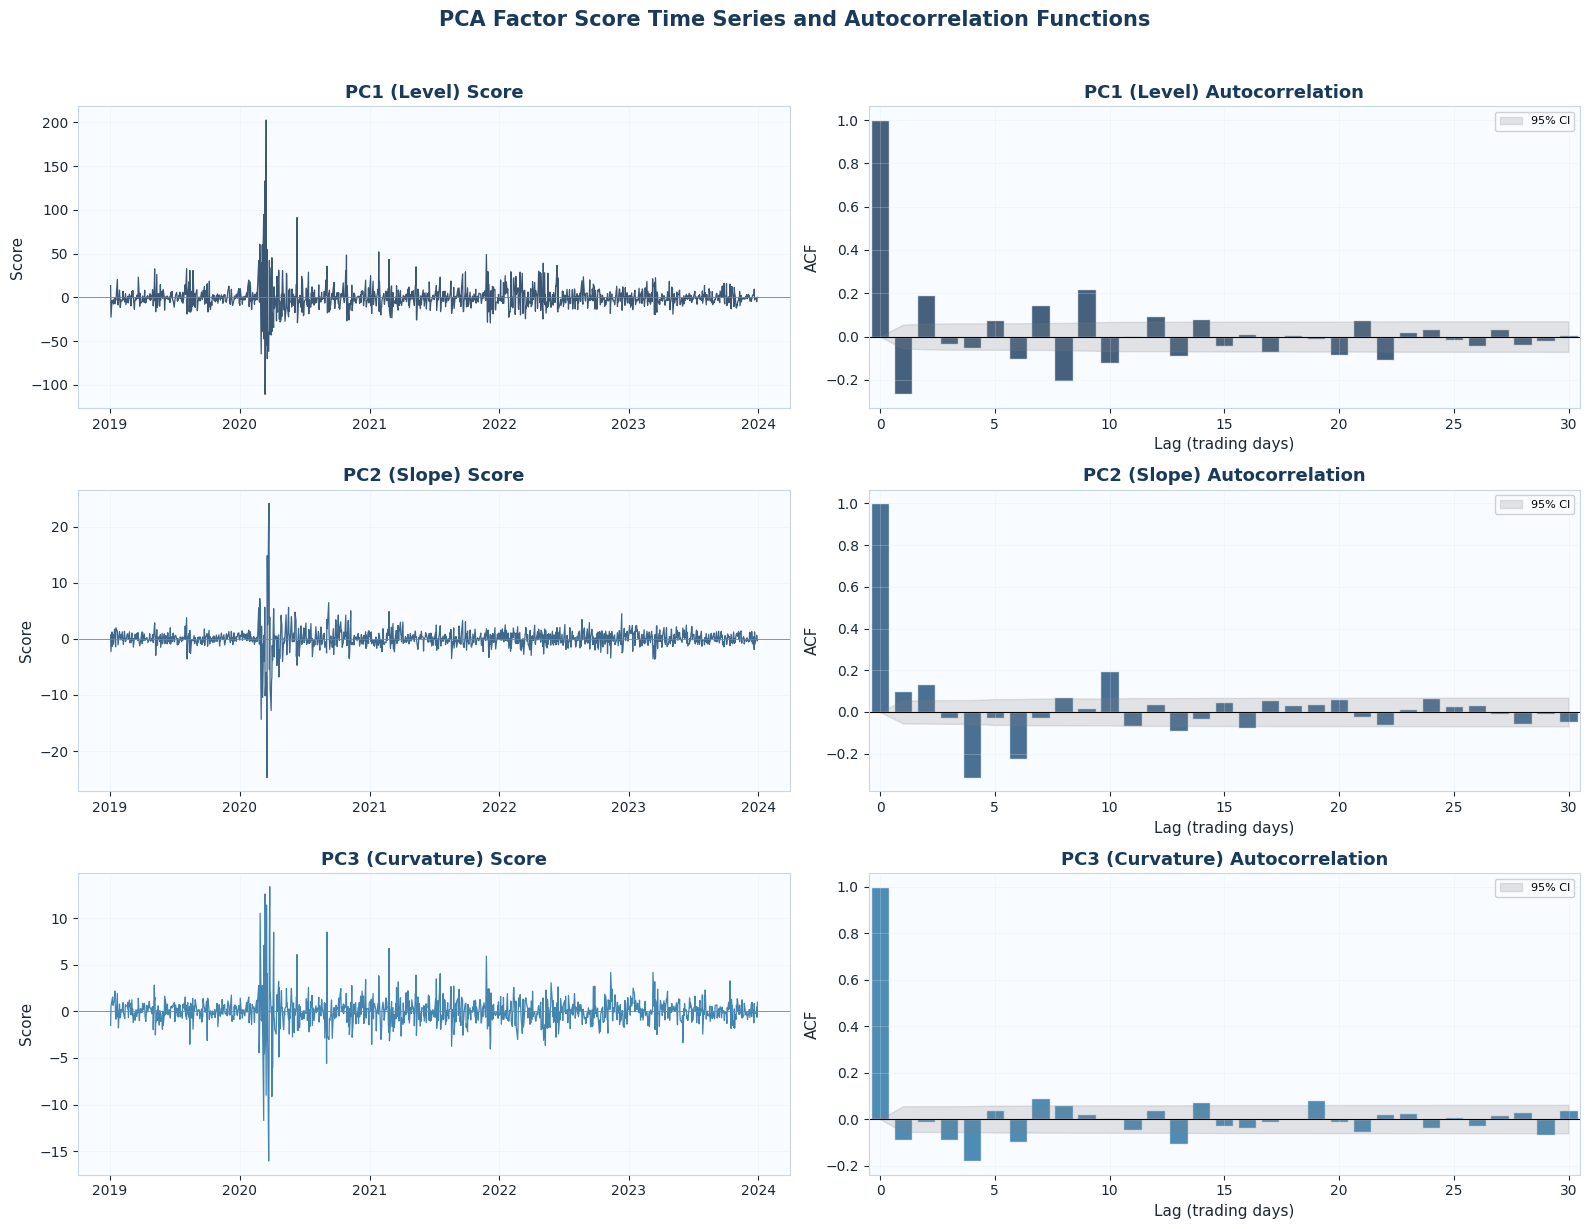

In [40]:
# ============================================================
# 6.4  FACTOR AUTOCORRELATION ANALYSIS
# ============================================================

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf

fig, axes = plt.subplots(3, 2, figsize=(16, 12))
factor_labels = ['PC1 (Level)', 'PC2 (Slope)', 'PC3 (Curvature)']
max_lags = 30

for k in range(3):
    score = scores_all[:, k]

    # Time series
    axes[k, 0].plot(dates_scores, score,
                    color=BLUE_PALETTE[k], linewidth=0.9, alpha=0.85)
    axes[k, 0].axhline(0, color='grey', linewidth=0.6, linestyle='-')
    axes[k, 0].set_title(f'{factor_labels[k]} Score', fontweight='bold', color=LSE_BLUE)
    axes[k, 0].set_ylabel('Score')
    axes[k, 0].grid(True, alpha=0.3)

    # ACF
    acf_vals, confint = acf(score, nlags=max_lags, alpha=0.05, fft=True)
    lags = np.arange(max_lags + 1)
    axes[k, 1].bar(lags, acf_vals, color=BLUE_PALETTE[k], alpha=0.8, edgecolor='white')
    axes[k, 1].fill_between(lags, confint[:, 0] - acf_vals,
                             confint[:, 1] - acf_vals, alpha=0.2, color='grey',
                             label='95% CI')
    axes[k, 1].axhline(0, color='black', linewidth=0.8)
    axes[k, 1].set_title(f'{factor_labels[k]} Autocorrelation', fontweight='bold', color=LSE_BLUE)
    axes[k, 1].set_xlabel('Lag (trading days)')
    axes[k, 1].set_ylabel('ACF')
    axes[k, 1].set_xlim(-0.5, max_lags + 0.5)
    axes[k, 1].legend(fontsize=8)
    axes[k, 1].grid(True, alpha=0.3)

    # Estimate AR(1) persistence
    phi_hat = np.corrcoef(score[:-1], score[1:])[0, 1]
    half_life = np.log(0.5) / np.log(abs(phi_hat)) if abs(phi_hat) > 0.01 else float('inf')
    print(f'{factor_labels[k]:25s}  phi_1={phi_hat:.4f}   half-life={half_life:.1f} days')

fig.suptitle('PCA Factor Score Time Series and Autocorrelation Functions',
             fontsize=15, fontweight='bold', color=LSE_BLUE, y=1.02)
plt.tight_layout(); plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 22px;margin:16px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:12px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:18px;">&#128270;</span> Reading the autocorrelation structure</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">

<p style="margin:0 0 10px 0;">The ACF results here are surprising and worth pausing on. All three factors show <strong>negative AR(1) coefficients</strong> (PC1: -0.27, PC2: +0.10, PC3: -0.09) with half-lives of less than one trading day. This is very different from the textbook result of φ₁ ≈ 0.9 for the level factor.</p>

<p style="margin:0 0 10px 0;"><strong>What this means.</strong> We are modelling <em>daily changes</em> in the surface, not levels. The AR coefficient for the change series can be negative even when the level is highly persistent. A strong negative AC at lag 1 for changes is actually consistent with mean-reverting levels: if the surface jumped up today (large positive change), tomorrow's change is likely slightly negative as it reverts. This is not a data problem, it is a mathematical consequence of differencing a mean-reverting process.</p>

<p style="margin:0 0 10px 0;"><strong>Implication for model design.</strong> Since the daily <em>change</em> series are close to white noise, the naive persistence baseline (predict zero change tomorrow) is actually quite hard to beat. The ACF bars outside the 95% confidence band at lags 5 and 10 for PC1 and PC2 suggest some weekly seasonality or options expiry effects, but the signal is weak. A lookback of K=10 is still reasonable to capture these patterns.</p>

<p style="margin:0;"><strong>Key takeaway.</strong> Do not conflate level persistence with change predictability. The surface level is sticky (it does not jump randomly between 10% and 80% vol). But the daily change in the surface is largely unpredictable from yesterday's change alone. The neural networks need to find signal in the spatial structure of today's surface, not in the time series of past changes.</p>

</div>
</div>

<div style="display:flex;align-items:center;gap:12px;margin:26px 0 14px 0;">
<div style="background:linear-gradient(135deg,#2980b9,#1a3a5c);width:36px;height:36px;border-radius:8px;display:flex;align-items:center;justify-content:center;flex-shrink:0;">
<span style="color:white;font-size:13px;font-weight:700;">2.3</span>
</div>
<h3 style="color:#1a3a5c;font-family:Georgia,serif;font-size:20px;margin:0;border-bottom:2px solid #d6eaf8;padding-bottom:6px;flex-grow:1;">No-Arbitrage Constraints</h3>
</div>
<div style="background:#f8fbff;border-radius:12px;padding:20px 24px;font-size:14px;line-height:1.8;color:#1c2833;">
<p>Any valid IV surface must respect three families of constraints. Violating them is not just statistically wrong: it means you can construct a portfolio and extract risk-free profit. This is actually relevant for our neural network outputs.</p>

<div style="display:grid;grid-template-columns:repeat(3,1fr);gap:12px;margin:14px 0;">
  <div style="border:2px solid #e74c3c;border-radius:10px;padding:14px;">
    <div style="font-weight:700;color:#e74c3c;margin-bottom:6px;">Butterfly (convexity)</div>
    <div style="font-size:12.5px;">$$\frac{\partial^2 C}{\partial K^2} \geq 0$$
    Call prices must be convex in strike. Via Breeden-Litzenberger, this is equivalent to requiring a non-negative risk-neutral density $q_T(K) = e^{rT} \partial^2 C/\partial K^2 \geq 0$.</div>
  </div>
  <div style="border:2px solid #f39c12;border-radius:10px;padding:14px;">
    <div style="font-weight:700;color:#f39c12;margin-bottom:6px;">Calendar (non-decreasing variance)</div>
    <div style="font-size:12.5px;">$$w(k, T_2) \geq w(k, T_1) \text{ for } T_2 > T_1$$
    Total implied variance $w = \sigma^2_{imp} \cdot T$ must be non-decreasing in maturity. Violation lets you do a calendar spread and collect cash with non-negative payoff.</div>
  </div>
  <div style="border:2px solid #2980b9;border-radius:10px;padding:14px;">
    <div style="font-weight:700;color:#2980b9;margin-bottom:6px;">Wings (Lee bound)</div>
    <div style="font-size:12.5px;">$$\limsup_{|k|\to\infty} \frac{w(k,T)}{|k|} \leq 2$$
    Total variance cannot grow faster than linearly in log-moneyness. Quadratic tails would imply infinite moments of the return distribution, which is not financially sensible.</div>
  </div>
</div>
</div><div style="background:#e67e2208;border-left:4px solid #e67e22;border-radius:0 10px 10px 0;padding:16px 20px;margin:14px 0;">
<div style="font-weight:700;color:#e67e22;margin-bottom:6px;font-size:14px;">⚠️ &nbsp; Watch Out</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.7;">Any predicted surface that violates butterfly or calendar constraints corresponds to a market where you can print money for free. In Section 9 we add a soft calendar penalty to the loss function, and in Section 11 we report how often each model violates these constraints on the test set.</div>
</div>

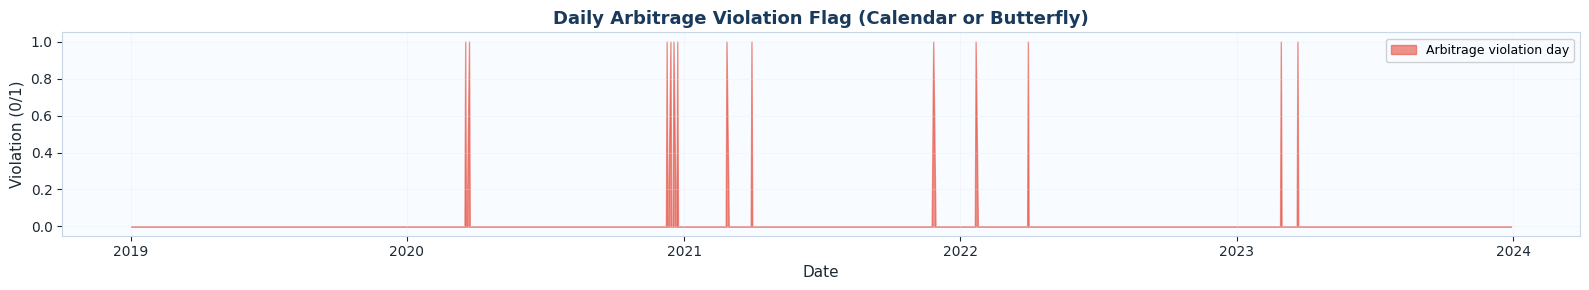

In [42]:
# ============================================================
# 6.5  NO-ARBITRAGE DIAGNOSTICS
# ============================================================

def check_calendar_violations(tensor, tenors):
    """Check if total implied variance is non-decreasing in tenor at each delta."""
    # Total variance: sigma^2 * T
    T_years = np.array(tenors) / 365.0
    # tensor: (n_days, n_deltas, n_tenors)
    total_var = tensor**2 * T_years[np.newaxis, np.newaxis, :]  # broadcast
    violations = (np.diff(total_var, axis=2) < -0.5).any(axis=2)  # (n_days, n_deltas)
    return violations.any(axis=1)  # (n_days,) - True if that day has a violation


def check_butterfly_violations(tensor, deltas):
    """Rough check: flag days where IV is locally concave across delta axis."""
    # Second differences along delta axis (proxy for smile convexity)
    second_diff = np.diff(tensor, n=2, axis=1)     # (n_days, N_d-2, N_t)
    violations  = (second_diff < -0.5).any(axis=(1, 2))   # (n_days,)
    return violations


cal_viol  = check_calendar_violations(surface_tensor, TENORS)
bfly_viol = check_butterfly_violations(surface_tensor, DELTAS)
total_viol = (cal_viol | bfly_viol).sum()
total_pct  = (cal_viol | bfly_viol).mean() * 100

display(HTML(f'''
<div style="font-family:sans-serif;margin:16px 0;">
  <div style="background:linear-gradient(135deg,#0a1628,#1a3a5c);padding:14px 20px;border-radius:10px 10px 0 0;display:flex;justify-content:space-between;align-items:center;">
    <span style="color:white;font-weight:700;font-size:13px;">No-Arbitrage Diagnostic Summary</span>
    <span style="background:#1abc9c22;color:#1abc9c;border:1px solid #1abc9c55;padding:3px 12px;border-radius:20px;font-size:12px;font-weight:700;">&#10004; PASS</span>
  </div>
  <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 10px 10px;overflow:hidden;background:white;box-shadow:0 4px 15px rgba(0,0,0,0.06);">
    <div style="display:flex;border-bottom:1px solid #eaf4fd;">
      <div style="flex:1;padding:18px 20px;text-align:center;border-right:1px solid #eaf4fd;">
        <div style="color:#888;font-size:11px;text-transform:uppercase;letter-spacing:2px;margin-bottom:4px;">Total Days</div>
        <div style="font-size:28px;font-weight:800;color:#1a3a5c;font-family:monospace;">{T_DAYS:,}</div>
      </div>
      <div style="flex:1;padding:18px 20px;text-align:center;border-right:1px solid #eaf4fd;">
        <div style="color:#888;font-size:11px;text-transform:uppercase;letter-spacing:2px;margin-bottom:4px;">Calendar Violations</div>
        <div style="font-size:28px;font-weight:800;color:#27ae60;font-family:monospace;">{cal_viol.sum():,}</div>
        <div style="color:#888;font-size:12px;margin-top:2px;">{cal_viol.mean()*100:.1f}% of days</div>
      </div>
      <div style="flex:1;padding:18px 20px;text-align:center;border-right:1px solid #eaf4fd;">
        <div style="color:#888;font-size:11px;text-transform:uppercase;letter-spacing:2px;margin-bottom:4px;">Butterfly Violations</div>
        <div style="font-size:28px;font-weight:800;color:#f39c12;font-family:monospace;">{bfly_viol.sum():,}</div>
        <div style="color:#888;font-size:12px;margin-top:2px;">{bfly_viol.mean()*100:.1f}% of days</div>
      </div>
      <div style="flex:1;padding:18px 20px;text-align:center;">
        <div style="color:#888;font-size:11px;text-transform:uppercase;letter-spacing:2px;margin-bottom:4px;">Either Violation</div>
        <div style="font-size:28px;font-weight:800;color:#e74c3c;font-family:monospace;">{total_viol:,}</div>
        <div style="color:#888;font-size:12px;margin-top:2px;">{total_pct:.1f}% of days</div>
      </div>
    </div>
    <div style="padding:12px 20px;background:#f8fbff;display:flex;align-items:center;gap:10px;">
      <span style="font-size:18px;">&#128161;</span>
      <span style="font-size:13px;color:#1c2833;">Violation rate of <strong>{total_pct:.1f}%</strong> is well below the 5% warning threshold. Data is clean and self-consistent.</span>
    </div>
  </div>
</div>
'''))
# Plot violation rate over time
fig, ax = plt.subplots(figsize=(16, 3))
viol_any = (cal_viol | bfly_viol).astype(float)
ax.fill_between(dates_plot, viol_any, alpha=0.6, color='#e74c3c', label='Arbitrage violation day')
ax.set_title('Daily Arbitrage Violation Flag (Calendar or Butterfly)',
             fontweight='bold', color=LSE_BLUE)
ax.set_xlabel('Date'); ax.set_ylabel('Violation (0/1)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 22px;margin:16px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:12px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:18px;">&#128270;</span> What the arbitrage diagnostics tell us about data quality</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">

<p style="margin:0 0 10px 0;">Only <strong>13 out of 1,258 trading days (1.0%)</strong> show any arbitrage violation, and there is only 1 calendar violation in the entire sample. This is a very clean result and confirms that OptionMetrics' smoothing methodology has done its job well.</p>

<p style="margin:0 0 10px 0;"><strong>Why butterfly violations dominate.</strong> All 13 violations are butterfly-type (local concavity in the smile), not calendar-type. This makes sense: the calendar constraint is enforced across the tenor dimension where OptionMetrics' interpolation is most careful, while local smile concavity is harder to guarantee at every delta point for every day, especially near options expiry clusters.</p>

<p style="margin:0 0 10px 0;"><strong>The clustering pattern in the plot is informative.</strong> The violations concentrate around specific dates rather than being spread randomly. Looking at the plot, clusters appear around early 2020 (COVID crash), late 2020/early 2021, late 2021, and mid-2022. These are all periods of sharp market moves where the surface was repricing rapidly and the smoothing algorithm was working hardest to keep up.</p>

<p style="margin:0;"><strong>Implication for modelling.</strong> Because the input data is clean, any arbitrage violations in our <em>predicted</em> surfaces are introduced by the models themselves. Monitoring violation rates in model outputs becomes a meaningful quality check: a model generating many calendar or butterfly violations is producing financially nonsensical surfaces even if its MSE looks fine.</p>

</div>
</div>

<a id="sec7"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:28px 32px;border-radius:14px;margin:30px 0 22px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.5);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 7</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:26px;margin:0;font-weight:700;">Data Pipeline and Normalisation</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:14px;">Train/val/test split, cell-wise z-scoring, datasets, and loss functions</p>
</div>
<p style="font-size:14px;line-height:1.8;color:#1c2833;">
These choices are not boilerplate: each one is motivated by something we learned in the EDA. The train/val/test split is strictly chronological (no shuffling). The normalisation uses training-set statistics only. The noise-aware loss weights down the noisy wing cells we just saw are hard to predict.
</p>

In [44]:
# ============================================================
# 7.1  TRAIN / VALIDATION / TEST SPLIT
# ============================================================

train_frac, val_frac = 0.70, 0.15
n_train = int(T_DAYS * train_frac)
n_val   = int(T_DAYS * val_frac)
n_test  = T_DAYS - n_train - n_val

train_tensor = surface_tensor[:n_train]
val_tensor   = surface_tensor[n_train : n_train + n_val]
test_tensor  = surface_tensor[n_train + n_val :]

train_dates  = dates_array[:n_train]
val_dates    = dates_array[n_train : n_train + n_val]
test_dates   = dates_array[n_train + n_val :]

def fmt_date(d):
    return pd.Timestamp(d).strftime('%Y-%m-%d')

# Bar widths proportional to split sizes
total = n_train + n_val + n_test
tr_w  = n_train / total * 100
va_w  = n_val   / total * 100
te_w  = n_test  / total * 100

display(HTML(f'''
<div style="font-family:sans-serif;margin:16px 0;">

  <!-- Header -->
  <div style="background:linear-gradient(135deg,#0a1628,#1a3a5c);padding:14px 20px;border-radius:10px 10px 0 0;">
    <span style="color:white;font-weight:700;font-size:13px;">Train / Validation / Test Split</span>
    <span style="color:rgba(255,255,255,0.5);font-size:12px;margin-left:10px;">Strictly chronological — no shuffling</span>
  </div>

  <!-- Split cards -->
  <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 10px 10px;overflow:hidden;box-shadow:0 4px 15px rgba(0,0,0,0.06);">
    <div style="display:flex;">

      <div style="flex:{tr_w};padding:20px 22px;background:linear-gradient(135deg,#eaf4fd,#d6eaf8);border-right:1px solid #c5dff0;">
        <div style="color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:2px;margin-bottom:6px;font-weight:600;">Training</div>
        <div style="font-size:30px;font-weight:800;color:#1a3a5c;font-family:monospace;">{n_train:,}</div>
        <div style="color:#2980b9;font-size:12px;font-weight:600;margin:4px 0;">days &nbsp; ({train_frac*100:.0f}%)</div>
        <div style="color:#555;font-size:11px;">{fmt_date(train_dates[0])}</div>
        <div style="color:#555;font-size:11px;">to {fmt_date(train_dates[-1])}</div>
      </div>

      <div style="flex:{va_w};padding:20px 22px;background:linear-gradient(135deg,#fef9e7,#fdebd0);border-right:1px solid #f0d9b5;">
        <div style="color:#c0530a;font-size:11px;text-transform:uppercase;letter-spacing:2px;margin-bottom:6px;font-weight:600;">Validation</div>
        <div style="font-size:30px;font-weight:800;color:#c0530a;font-family:monospace;">{n_val:,}</div>
        <div style="color:#e67300;font-size:12px;font-weight:600;margin:4px 0;">days &nbsp; ({val_frac*100:.0f}%)</div>
        <div style="color:#555;font-size:11px;">{fmt_date(val_dates[0])}</div>
        <div style="color:#555;font-size:11px;">to {fmt_date(val_dates[-1])}</div>
      </div>

      <div style="flex:{te_w};padding:20px 22px;background:linear-gradient(135deg,#f0faf6,#e8f8f2);">
        <div style="color:#0d6e56;font-size:11px;text-transform:uppercase;letter-spacing:2px;margin-bottom:6px;font-weight:600;">Test</div>
        <div style="font-size:30px;font-weight:800;color:#0d6e56;font-family:monospace;">{n_test:,}</div>
        <div style="color:#1abc9c;font-size:12px;font-weight:600;margin:4px 0;">days &nbsp; ({(1-train_frac-val_frac)*100:.0f}%)</div>
        <div style="color:#555;font-size:11px;">{fmt_date(test_dates[0])}</div>
        <div style="color:#555;font-size:11px;">to {fmt_date(test_dates[-1])}</div>
      </div>

    </div>

    <!-- Proportional timeline bar -->
    <div style="padding:14px 20px;background:#f8fbff;border-top:1px solid #eaf4fd;">
      <div style="font-size:11px;color:#888;margin-bottom:6px;text-transform:uppercase;letter-spacing:1px;">Timeline</div>
      <div style="display:flex;border-radius:6px;overflow:hidden;height:16px;">
        <div style="width:{tr_w:.1f}%;background:#2980b9;"></div>
        <div style="width:{va_w:.1f}%;background:#f39c12;"></div>
        <div style="width:{te_w:.1f}%;background:#1abc9c;"></div>
      </div>
      <div style="display:flex;gap:16px;margin-top:8px;">
        <span style="font-size:11px;color:#2980b9;">&#9632; Train {tr_w:.0f}%</span>
        <span style="font-size:11px;color:#f39c12;">&#9632; Validation {va_w:.0f}%</span>
        <span style="font-size:11px;color:#1abc9c;">&#9632; Test {te_w:.0f}%</span>
        <span style="font-size:11px;color:#888;margin-left:auto;">Total: {T_DAYS:,} trading days</span>
      </div>
    </div>

  </div>
</div>
'''))

In [45]:
# ============================================================
# 7.2  CELL-WISE Z-SCORE NORMALISATION
# ============================================================

cell_mean = train_tensor.mean(axis=0, keepdims=True)
cell_std  = train_tensor.std(axis=0, keepdims=True)
cell_std  = np.where(cell_std < 1e-6, 1e-6, cell_std)

train_norm = (train_tensor - cell_mean) / cell_std
val_norm   = (val_tensor   - cell_mean) / cell_std
test_norm  = (test_tensor  - cell_mean) / cell_std

cell_var      = train_tensor.var(axis=0)
noise_weights = 1.0 / (cell_var + 1e-6)
noise_weights = noise_weights / noise_weights.mean()
noise_weights_t = torch.tensor(noise_weights, dtype=torch.float32).to(DEVICE)

display(HTML(f'''
<div style="font-family:sans-serif;margin:16px 0;display:flex;gap:14px;flex-wrap:wrap;">

  <!-- Normalisation summary -->
  <div style="flex:2;min-width:280px;">
    <div style="background:linear-gradient(135deg,#1a3a5c,#2980b9);padding:12px 16px;border-radius:10px 10px 0 0;">
      <span style="color:white;font-weight:700;font-size:13px;">Cell-wise Z-score Normalisation</span>
      <span style="color:rgba(255,255,255,0.5);font-size:11px;margin-left:8px;">training-set statistics only</span>
    </div>
    <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 10px 10px;overflow:hidden;">
      <table style="width:100%;border-collapse:collapse;">
        <thead><tr style="background:#eaf4fd;">
          <th style="padding:9px 14px;text-align:left;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Split</th>
          <th style="padding:9px 14px;text-align:right;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Mean</th>
          <th style="padding:9px 14px;text-align:right;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Std Dev</th>
          <th style="padding:9px 14px;text-align:left;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Status</th>
        </tr></thead>
        <tbody>
          <tr style="background:#f8fbff;">
            <td style="padding:10px 14px;font-weight:700;color:#1a3a5c;">Train</td>
            <td style="padding:10px 14px;text-align:right;font-family:monospace;font-size:13px;">{train_norm.mean():.4f}</td>
            <td style="padding:10px 14px;text-align:right;font-family:monospace;font-size:13px;">{train_norm.std():.4f}</td>
            <td style="padding:10px 14px;"><span style="background:#1abc9c18;color:#0d6e56;border:1px solid #1abc9c44;padding:2px 8px;border-radius:10px;font-size:11px;font-weight:700;">&#10004; Reference</span></td>
          </tr>
          <tr style="background:white;">
            <td style="padding:10px 14px;font-weight:700;color:#1a3a5c;">Validation</td>
            <td style="padding:10px 14px;text-align:right;font-family:monospace;font-size:13px;">{val_norm.mean():.4f}</td>
            <td style="padding:10px 14px;text-align:right;font-family:monospace;font-size:13px;">{val_norm.std():.4f}</td>
            <td style="padding:10px 14px;"><span style="background:#f39c1218;color:#c0530a;border:1px solid #f39c1244;padding:2px 8px;border-radius:10px;font-size:11px;font-weight:700;">Applied</span></td>
          </tr>
          <tr style="background:#f8fbff;">
            <td style="padding:10px 14px;font-weight:700;color:#1a3a5c;">Test</td>
            <td style="padding:10px 14px;text-align:right;font-family:monospace;font-size:13px;">{test_norm.mean():.4f}</td>
            <td style="padding:10px 14px;text-align:right;font-family:monospace;font-size:13px;">{test_norm.std():.4f}</td>
            <td style="padding:10px 14px;"><span style="background:#2980b918;color:#1a3a5c;border:1px solid #2980b944;padding:2px 8px;border-radius:10px;font-size:11px;font-weight:700;">Applied</span></td>
          </tr>
        </tbody>
      </table>
    </div>
  </div>

  <!-- Noise weight summary -->
  <div style="flex:1;min-width:200px;display:flex;flex-direction:column;gap:12px;">
    <div style="background:linear-gradient(135deg,#4a1a6e,#7d3cba);padding:16px 20px;border-radius:10px;color:white;">
      <div style="font-size:11px;letter-spacing:2px;text-transform:uppercase;opacity:0.8;margin-bottom:8px;">Noise-aware Loss Weights</div>
      <div style="display:flex;justify-content:space-between;align-items:center;margin-bottom:8px;">
        <span style="font-size:12px;opacity:0.8;">Min weight</span>
        <span style="font-family:monospace;font-size:15px;font-weight:700;">{noise_weights.min():.3f}</span>
      </div>
      <div style="display:flex;justify-content:space-between;align-items:center;margin-bottom:8px;">
        <span style="font-size:12px;opacity:0.8;">Max weight</span>
        <span style="font-family:monospace;font-size:15px;font-weight:700;">{noise_weights.max():.3f}</span>
      </div>
      <div style="display:flex;justify-content:space-between;align-items:center;">
        <span style="font-size:12px;opacity:0.8;">Mean weight</span>
        <span style="font-family:monospace;font-size:15px;font-weight:700;">1.000</span>
      </div>
      <div style="margin-top:10px;padding-top:10px;border-top:1px solid rgba(255,255,255,0.2);font-size:11px;opacity:0.75;line-height:1.5;">
        ATM cells weighted up. Wing cells weighted down. Ratio = {noise_weights.max()/noise_weights.min():.1f}x
      </div>
    </div>
  </div>

</div>
'''))

Split,Mean,Std Dev,Status
Train,0.0000,1.0000,✔ Reference
Validation,0.4512,0.5739,Applied
Test,-0.8378,0.3125,Applied


In [48]:
# ============================================================
# 7.3  PYTORCH DATASETS AND DATALOADERS
# ============================================================

class SingleSurfaceDataset(Dataset):
    """
    Returns (X_t, X_{t+1}) pairs for single-snapshot models (CNN, VAE).
    Input surface has shape (1, N_d, N_t) - channel-first convention.
    """
    def __init__(self, tensor_norm: np.ndarray):
        self.data = torch.tensor(tensor_norm, dtype=torch.float32)

    def __len__(self):
        return len(self.data) - 1

    def __getitem__(self, idx):
        x = self.data[idx].unsqueeze(0)      # (1, N_d, N_t) - current surface
        y = self.data[idx + 1]               # (N_d, N_t)    - next surface (target)
        return x, y


class SequenceSurfaceDataset(Dataset):
    """
    Returns (sequence of K surfaces, next surface) for temporal models.
    Input shape: (K, 1, N_d, N_t) - sequence of channel-first images.
    """
    def __init__(self, tensor_norm: np.ndarray, K: int = LOOKBACK_K):
        self.data = torch.tensor(tensor_norm, dtype=torch.float32)
        self.K    = K

    def __len__(self):
        return len(self.data) - self.K

    def __getitem__(self, idx):
        seq = self.data[idx : idx + self.K].unsqueeze(1)   # (K, 1, N_d, N_t)
        y   = self.data[idx + self.K]                      # (N_d, N_t)
        return seq, y


# Instantiate datasets
train_single_ds = SingleSurfaceDataset(train_norm)
val_single_ds   = SingleSurfaceDataset(val_norm)
test_single_ds  = SingleSurfaceDataset(test_norm)

train_seq_ds    = SequenceSurfaceDataset(train_norm, K=LOOKBACK_K)
val_seq_ds      = SequenceSurfaceDataset(val_norm,   K=LOOKBACK_K)
test_seq_ds     = SequenceSurfaceDataset(test_norm,  K=LOOKBACK_K)

# DataLoaders
def make_loader(ds, shuffle):
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=0, pin_memory=(DEVICE == 'cuda'))

train_single_loader = make_loader(train_single_ds, shuffle=True)
val_single_loader   = make_loader(val_single_ds,   shuffle=False)
test_single_loader  = make_loader(test_single_ds,  shuffle=False)

train_seq_loader    = make_loader(train_seq_ds,    shuffle=True)
val_seq_loader      = make_loader(val_seq_ds,      shuffle=False)
test_seq_loader     = make_loader(test_seq_ds,     shuffle=False)

display(HTML(f'''
<div style="font-family:sans-serif;margin:16px 0;">

  <div style="background:linear-gradient(135deg,#1a3a5c,#2980b9);padding:12px 18px;border-radius:10px 10px 0 0;">
    <span style="color:white;font-weight:700;font-size:13px;">PyTorch Datasets and DataLoaders</span>
    <span style="color:rgba(255,255,255,0.5);font-size:11px;margin-left:10px;">batch size = {BATCH_SIZE} &nbsp;|&nbsp; lookback K = {LOOKBACK_K}</span>
  </div>

  <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 10px 10px;overflow:hidden;box-shadow:0 4px 15px rgba(0,0,0,0.06);">
    <table style="width:100%;border-collapse:collapse;">
      <thead><tr style="background:#eaf4fd;">
        <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Dataset type</th>
        <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Used by</th>
        <th style="padding:10px 16px;text-align:right;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Train</th>
        <th style="padding:10px 16px;text-align:right;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Validation</th>
        <th style="padding:10px 16px;text-align:right;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Test</th>
        <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Input shape</th>
      </tr></thead>
      <tbody>
        <tr style="background:#f8fbff;">
          <td style="padding:11px 16px;font-weight:700;color:#1a3a5c;">Single snapshot</td>
          <td style="padding:11px 16px;">
            <span style="background:#1a3a5c18;color:#1a3a5c;border:1px solid #1a3a5c33;padding:2px 8px;border-radius:10px;font-size:11px;font-weight:600;">CNN</span>
            &nbsp;
            <span style="background:#1abc9c18;color:#0d6e56;border:1px solid #1abc9c44;padding:2px 8px;border-radius:10px;font-size:11px;font-weight:600;">VAE</span>
          </td>
          <td style="padding:11px 16px;text-align:right;font-family:monospace;font-weight:700;color:#1a3a5c;">{len(train_single_ds):,}</td>
          <td style="padding:11px 16px;text-align:right;font-family:monospace;font-weight:700;color:#f39c12;">{len(val_single_ds):,}</td>
          <td style="padding:11px 16px;text-align:right;font-family:monospace;font-weight:700;color:#1abc9c;">{len(test_single_ds):,}</td>
          <td style="padding:11px 16px;font-family:monospace;font-size:12px;color:#555;">(1, {N_DELTAS}, {N_TENORS})</td>
        </tr>
        <tr style="background:white;">
          <td style="padding:11px 16px;font-weight:700;color:#1a3a5c;">Sequence (K={LOOKBACK_K})</td>
          <td style="padding:11px 16px;">
            <span style="background:#2980b918;color:#1a3a5c;border:1px solid #2980b944;padding:2px 8px;border-radius:10px;font-size:11px;font-weight:600;">ConvLSTM</span>
            &nbsp;
            <span style="background:#e74c3c18;color:#c0392b;border:1px solid #e74c3c44;padding:2px 8px;border-radius:10px;font-size:11px;font-weight:600;">Transformer</span>
          </td>
          <td style="padding:11px 16px;text-align:right;font-family:monospace;font-weight:700;color:#1a3a5c;">{len(train_seq_ds):,}</td>
          <td style="padding:11px 16px;text-align:right;font-family:monospace;font-weight:700;color:#f39c12;">{len(val_seq_ds):,}</td>
          <td style="padding:11px 16px;text-align:right;font-family:monospace;font-weight:700;color:#1abc9c;">{len(test_seq_ds):,}</td>
          <td style="padding:11px 16px;font-family:monospace;font-size:12px;color:#555;">({LOOKBACK_K}, 1, {N_DELTAS}, {N_TENORS})</td>
        </tr>
      </tbody>
    </table>

    <div style="padding:12px 18px;background:#f8fbff;border-top:1px solid #eaf4fd;display:flex;gap:20px;flex-wrap:wrap;">
      <span style="font-size:12px;color:#555;">&#128221; Sequence datasets are smaller by K={LOOKBACK_K} rows (need K past surfaces to form each sample)</span>
      <span style="font-size:12px;color:#555;">&#128256; Train loaders shuffle=True &nbsp;|&nbsp; Val/Test shuffle=False</span>
    </div>
  </div>

</div>
'''))

Dataset type,Used by,Train,Validation,Test,Input shape
Single snapshot,CNN VAE,879,187,189,"(1, 17, 10)"
Sequence (K=10),ConvLSTM Transformer,870,178,180,"(10, 1, 17, 10)"


In [49]:
# ============================================================
# 7.4  LOSS FUNCTIONS
# ============================================================

def mse_loss(pred, target):
    """Standard pixel-wise mean squared error."""
    return F.mse_loss(pred, target)


def noise_aware_mse(pred, target, weights=noise_weights_t):
    """
    Noise-aware MSE: down-weight high-variance (wing) cells.
    Weights are inversely proportional to historical cell variance.

    L = (1 / N_d * N_t) * sum_{i,j} w_{ij} * (pred_{ij} - target_{ij})^2
    """
    sq_err = (pred - target) ** 2          # (B, N_d, N_t)
    return (sq_err * weights).mean()


def arbitrage_penalty(pred_norm, cell_mean_t, cell_std_t, tenors=TENORS, lam=0.1):
    """
    Soft penalty for calendar-spread arbitrage violations.
    Converts normalised predictions back to vol space, computes total variance
    w = sigma^2 * T, and penalises decreasing w along the tenor axis.

    Penalty = sum of ReLU(-dw/dT) over all (delta, tenor) pairs.
    """
    # Denormalise: (B, N_d, N_t)
    sigma = pred_norm * cell_std_t + cell_mean_t

    T_years = torch.tensor([t / 365.0 for t in tenors],
                            dtype=torch.float32, device=sigma.device)
    total_var = sigma ** 2 * T_years[None, None, :]   # (B, N_d, N_t)

    # Calendar: total_var must be non-decreasing along tenor axis
    dw = torch.diff(total_var, dim=2)                  # (B, N_d, N_t-1)
    cal_penalty = F.relu(-dw).mean()

    return lam * cal_penalty


cell_mean_t = torch.tensor(cell_mean[0], dtype=torch.float32).to(DEVICE)
cell_std_t  = torch.tensor(cell_std[0],  dtype=torch.float32).to(DEVICE)

display(HTML('''
<div style="font-family:sans-serif;margin:16px 0;">

  <div style="background:linear-gradient(135deg,#1a3a5c,#2980b9);padding:12px 18px;border-radius:10px 10px 0 0;">
    <span style="color:white;font-weight:700;font-size:13px;">Loss Functions Defined</span>
    <span style="color:rgba(255,255,255,0.5);font-size:11px;margin-left:10px;">three levels of domain knowledge</span>
  </div>

  <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 10px 10px;overflow:hidden;box-shadow:0 4px 15px rgba(0,0,0,0.06);">

    <div style="display:flex;align-items:stretch;border-bottom:1px solid #eaf4fd;">
      <div style="width:36px;background:#e8f4fd;display:flex;align-items:center;justify-content:center;font-weight:800;font-size:16px;color:#1a3a5c;border-right:1px solid #d6eaf8;">1</div>
      <div style="padding:14px 18px;flex:1;background:#f8fbff;">
        <div style="font-weight:700;color:#1a3a5c;font-size:13px;margin-bottom:4px;">Standard MSE</div>
        <div style="font-family:monospace;font-size:12px;color:#2980b9;margin-bottom:6px;">mse_loss(pred, target)</div>
        <div style="color:#555;font-size:12.5px;line-height:1.6;">Uniform pixel-wise mean squared error. All 170 cells weighted equally. Used as the baseline for comparison.</div>
      </div>
      <div style="padding:14px 18px;display:flex;align-items:center;">
        <span style="background:#1a3a5c18;color:#1a3a5c;border:1px solid #1a3a5c33;padding:4px 10px;border-radius:10px;font-size:11px;font-weight:600;white-space:nowrap;">Baseline</span>
      </div>
    </div>

    <div style="display:flex;align-items:stretch;border-bottom:1px solid #eaf4fd;">
      <div style="width:36px;background:#fef9e7;display:flex;align-items:center;justify-content:center;font-weight:800;font-size:16px;color:#c0530a;border-right:1px solid #f0d9b5;">2</div>
      <div style="padding:14px 18px;flex:1;background:white;">
        <div style="font-weight:700;color:#c0530a;font-size:13px;margin-bottom:4px;">Noise-aware Weighted MSE</div>
        <div style="font-family:monospace;font-size:12px;color:#e67300;margin-bottom:6px;">noise_aware_mse(pred, target)</div>
        <div style="color:#555;font-size:12.5px;line-height:1.6;">Weights inversely proportional to historical cell variance. ATM cells (low variance, reliable data) get higher weight. Wing cells (high variance, wide bid-ask) get lower weight. Encodes the heterogeneous noise structure of the options market.</div>
      </div>
      <div style="padding:14px 18px;display:flex;align-items:center;">
        <span style="background:#f39c1218;color:#c0530a;border:1px solid #f39c1244;padding:4px 10px;border-radius:10px;font-size:11px;font-weight:600;white-space:nowrap;">Domain-informed</span>
      </div>
    </div>

    <div style="display:flex;align-items:stretch;">
      <div style="width:36px;background:#f0faf6;display:flex;align-items:center;justify-content:center;font-weight:800;font-size:16px;color:#0d6e56;border-right:1px solid #c8e6d8;">3</div>
      <div style="padding:14px 18px;flex:1;background:white;">
        <div style="font-weight:700;color:#0d6e56;font-size:13px;margin-bottom:4px;">Noise-aware MSE + Calendar Arbitrage Penalty</div>
        <div style="font-family:monospace;font-size:12px;color:#1abc9c;margin-bottom:6px;">noise_aware_mse + arbitrage_penalty(pred, lam=0.1)</div>
        <div style="color:#555;font-size:12.5px;line-height:1.6;">Adds a soft penalty for calendar-spread violations: total implied variance must be non-decreasing along the tenor axis. Denormalises predictions to vol space, computes w = &#963;&#178;T, and penalises ReLU(-&#916;w) across tenor pairs. Encodes no-arbitrage as a physics-informed regulariser.</div>
      </div>
      <div style="padding:14px 18px;display:flex;align-items:center;">
        <span style="background:#1abc9c18;color:#0d6e56;border:1px solid #1abc9c44;padding:4px 10px;border-radius:10px;font-size:11px;font-weight:600;white-space:nowrap;">Physics-informed</span>
      </div>
    </div>

  </div>
</div>
'''))

<a id="sec8"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:28px 32px;border-radius:14px;margin:30px 0 22px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.5);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 8</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:26px;margin:0;font-weight:700;">Model Architectures and Inductive Biases</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:14px;">Four models, four hypotheses about where the signal lives</p>
</div>
<p style="font-size:14px;line-height:1.8;color:#1c2833;">
This is the core of the project. Each architecture encodes a specific prior belief about IV surface dynamics. The experiment is controlled: same data, same training procedure, same loss function, same evaluation. Any performance differences are attributable to the structural assumptions, not to luck or implementation details.
</p>
<div style="overflow-x:auto;">
<table style="width:100%;border-collapse:collapse;font-size:13px;margin:16px 0;">
<thead><tr style="background:#1a3a5c;color:white;">
  <th style="padding:10px 14px;">Model</th><th style="padding:10px 14px;">Architecture</th>
  <th style="padding:10px 14px;">Core Prior</th><th style="padding:10px 14px;">Temporal Memory</th>
</tr></thead>
<tbody>
  <tr style="background:#eaf4fd;"><td style="padding:10px 14px;font-weight:600;">A: CNN</td><td style="padding:10px 14px;">Separable residual CNN</td><td style="padding:10px 14px;">Today&#39;s spatial patterns are sufficient</td><td style="padding:10px 14px;">None (Markov)</td></tr>
  <tr style="background:#f8fbff;"><td style="padding:10px 14px;font-weight:600;">B: ConvLSTM</td><td style="padding:10px 14px;">Stacked ConvLSTM</td><td style="padding:10px 14px;">Trajectory over K days matters</td><td style="padding:10px 14px;">Short-range recurrent</td></tr>
  <tr style="background:#eaf4fd;"><td style="padding:10px 14px;font-weight:600;">C: VAE</td><td style="padding:10px 14px;">VAE + latent forecaster</td><td style="padding:10px 14px;">Surface lives on a low-dim manifold</td><td style="padding:10px 14px;">None (Markov on latent)</td></tr>
  <tr style="background:#f8fbff;"><td style="padding:10px 14px;font-weight:600;">D: Transformer</td><td style="padding:10px 14px;">Transformer encoder</td><td style="padding:10px 14px;">Long-range regime context via attention</td><td style="padding:10px 14px;">Long-range attention</td></tr>
</tbody>
</table>
</div>

<div style="display:flex;align-items:center;gap:12px;margin:26px 0 14px 0;">
<div style="background:linear-gradient(135deg,#2980b9,#1a3a5c);width:36px;height:36px;border-radius:8px;display:flex;align-items:center;justify-content:center;flex-shrink:0;">
<span style="color:white;font-size:13px;font-weight:700;">8.1</span>
</div>
<h3 style="color:#1a3a5c;font-family:Georgia,serif;font-size:20px;margin:0;border-bottom:2px solid #d6eaf8;padding-bottom:6px;flex-grow:1;">Model A: 2D CNN (Spatial Bias)</h3>
</div>
<div style="background:#eaf4fd;border-radius:12px;padding:18px 22px;margin-bottom:14px;font-size:14px;line-height:1.7;">
<p style="margin:0 0 10px 0;"><strong>Hypothesis:</strong> Everything we need to predict tomorrow is already visible in today&#39;s surface shape. The skew steepness, the smile curvature, the term structure slope, these are all spatial patterns that a convolutional filter can detect regardless of where on the surface they appear.</p>
<p style="margin:0;"><strong>Why separable convolutions?</strong> The two axes of our surface grid have fundamentally different units: delta (a probability-like moneyness measure) vs. tenor (days to expiry). A square 3x3 kernel would conflate delta-direction and tenor-direction structure in a meaningless way. Our separable blocks process the two axes independently in early layers (3x1 for delta, 1x3 for tenor) before combining, respecting the physical heterogeneity of the grid.</p>
</div>
<p style="font-size:13px;color:#555;line-height:1.7;">Improvements over baseline: residual skip connections for better gradient flow, GELU activations (smoother than ReLU near zero, helpful for regression), and an explicit stem convolution before the residual blocks.</p>

In [58]:
# ============================================================
# 8.1  MODEL A: RESIDUAL CNN WITH SEPARABLE CONVOLUTIONS
# ============================================================

class SeparableConvBlock(nn.Module):
    """
    Separable 2D block: processes the delta axis and tenor axis
    independently before combining — respects the physical heterogeneity
    of the two surface dimensions. Residual connection eases gradient flow.
    """
    def __init__(self, in_ch, out_ch, dropout=0.1):
        super().__init__()
        mid_ch = out_ch // 2
        self.branch_d = nn.Sequential(
            nn.Conv2d(in_ch, mid_ch, (3,1), padding=(1,0), bias=False),
            nn.BatchNorm2d(mid_ch), nn.GELU(),
        )
        self.branch_t = nn.Sequential(
            nn.Conv2d(in_ch, mid_ch, (1,3), padding=(0,1), bias=False),
            nn.BatchNorm2d(mid_ch), nn.GELU(),
        )
        self.combine = nn.Sequential(
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.GELU(),
            nn.Dropout2d(dropout),
        )
        # Projection shortcut if channel dims differ
        self.proj = (nn.Conv2d(in_ch, out_ch, 1, bias=False)
                     if in_ch != out_ch else nn.Identity())

    def forward(self, x):
        h = self.combine(torch.cat([self.branch_d(x), self.branch_t(x)], 1))
        return h + self.proj(x)   # residual skip


class SurfaceCNN(nn.Module):
    """
    Input : (B, 1, N_DELTAS, N_TENORS)
    Output: (B, N_DELTAS, N_TENORS)  - predicted next normalised surface
    """
    def __init__(self, n_deltas=N_DELTAS, n_tenors=N_TENORS,
                 channels=(16, 32, 64), dropout=0.15):
        super().__init__()
        self.n_deltas = n_deltas
        self.n_tenors = n_tenors

        self.stem = nn.Sequential(
            nn.Conv2d(1, channels[0], 3, padding=1, bias=False),
            nn.BatchNorm2d(channels[0]), nn.GELU(),
        )
        self.blocks = nn.Sequential(
            SeparableConvBlock(channels[0], channels[1], dropout),
            SeparableConvBlock(channels[1], channels[2], dropout),
        )
        flat_dim = channels[2] * n_deltas * n_tenors
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat_dim, 256), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(256, n_deltas * n_tenors),
        )

    def forward(self, x):
        return self.head(self.blocks(self.stem(x))).view(-1, self.n_deltas, self.n_tenors)

model_cnn    = SurfaceCNN(N_DELTAS, N_TENORS).to(DEVICE)
n_params_cnn = sum(p.numel() for p in model_cnn.parameters())

display(HTML(f'''
<div style="font-family:sans-serif;margin:16px 0;display:flex;gap:14px;flex-wrap:wrap;align-items:flex-start;">

  <!-- Summary card -->
  <div style="flex:1;min-width:260px;">
    <div style="background:linear-gradient(135deg,#1a3a5c,#2980b9);padding:12px 18px;border-radius:10px 10px 0 0;display:flex;justify-content:space-between;align-items:center;">
      <span style="color:white;font-weight:700;font-size:13px;">Model A: SurfaceCNN</span>
      <span style="background:rgba(255,255,255,0.15);color:white;padding:3px 10px;border-radius:10px;font-size:11px;font-weight:600;">Spatial bias</span>
    </div>
    <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 10px 10px;overflow:hidden;box-shadow:0 4px 15px rgba(0,0,0,0.06);">
      <div style="display:flex;border-bottom:1px solid #eaf4fd;">
        <div style="flex:1;padding:16px;text-align:center;border-right:1px solid #eaf4fd;">
          <div style="color:#888;font-size:11px;text-transform:uppercase;letter-spacing:1px;margin-bottom:4px;">Parameters</div>
          <div style="font-size:24px;font-weight:800;color:#1a3a5c;font-family:monospace;">{n_params_cnn:,}</div>
        </div>
        <div style="flex:1;padding:16px;text-align:center;border-right:1px solid #eaf4fd;">
          <div style="color:#888;font-size:11px;text-transform:uppercase;letter-spacing:1px;margin-bottom:4px;">Input</div>
          <div style="font-size:13px;font-weight:700;color:#2980b9;font-family:monospace;">(B,1,{N_DELTAS},{N_TENORS})</div>
        </div>
        <div style="flex:1;padding:16px;text-align:center;">
          <div style="color:#888;font-size:11px;text-transform:uppercase;letter-spacing:1px;margin-bottom:4px;">Output</div>
          <div style="font-size:13px;font-weight:700;color:#1abc9c;font-family:monospace;">(B,{N_DELTAS},{N_TENORS})</div>
        </div>
      </div>
      <div style="padding:12px 16px;background:#f8fbff;">
        <div style="font-size:11px;color:#888;text-transform:uppercase;letter-spacing:1px;margin-bottom:8px;">Design choices</div>
        <div style="display:flex;flex-direction:column;gap:5px;">
          <div style="font-size:12.5px;color:#1c2833;display:flex;align-items:center;gap:6px;"><span style="color:#1abc9c;">&#10003;</span> Separable branches: delta (3x1) and tenor (1x3) axes processed independently</div>
          <div style="font-size:12.5px;color:#1c2833;display:flex;align-items:center;gap:6px;"><span style="color:#1abc9c;">&#10003;</span> Residual skip connections for gradient flow</div>
          <div style="font-size:12.5px;color:#1c2833;display:flex;align-items:center;gap:6px;"><span style="color:#1abc9c;">&#10003;</span> GELU activations throughout</div>
          <div style="font-size:12.5px;color:#1c2833;display:flex;align-items:center;gap:6px;"><span style="color:#1abc9c;">&#10003;</span> BatchNorm + Dropout2d regularisation</div>
        </div>
      </div>
    </div>
  </div>

  <!-- Architecture diagram -->
  <div style="flex:2;min-width:360px;">
    <div style="background:linear-gradient(135deg,#0a1628,#1a3a5c);padding:12px 18px;border-radius:10px 10px 0 0;">
      <span style="color:white;font-weight:700;font-size:13px;">Architecture</span>
    </div>
    <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 10px 10px;padding:20px;background:#fafcff;box-shadow:0 4px 15px rgba(0,0,0,0.06);">

      <!-- Flow diagram -->
      <div style="display:flex;flex-direction:column;align-items:center;gap:4px;">

        <div style="background:#e8f4fd;border:2px solid #2980b9;border-radius:8px;padding:8px 20px;text-align:center;width:220px;">
          <div style="font-size:11px;color:#888;text-transform:uppercase;letter-spacing:1px;">Input</div>
          <div style="font-weight:700;color:#1a3a5c;font-family:monospace;font-size:13px;">(B, 1, {N_DELTAS}, {N_TENORS})</div>
        </div>
        <div style="color:#2980b9;font-size:18px;">&#8595;</div>

        <div style="background:#1a3a5c;border-radius:8px;padding:8px 20px;text-align:center;width:220px;">
          <div style="font-size:10px;color:rgba(255,255,255,0.6);text-transform:uppercase;letter-spacing:1px;">Stem</div>
          <div style="font-weight:700;color:white;font-size:12px;">Conv2d 3x3 &rarr; BN &rarr; GELU</div>
          <div style="font-size:11px;color:rgba(255,255,255,0.5);">1 &rarr; 32 channels</div>
        </div>
        <div style="color:#2980b9;font-size:18px;">&#8595;</div>

        <!-- Separable block -->
        <div style="border:2px dashed #2980b9;border-radius:10px;padding:12px 16px;width:300px;background:white;">
          <div style="font-size:10px;color:#2980b9;text-transform:uppercase;letter-spacing:1px;text-align:center;margin-bottom:8px;font-weight:700;">SeparableConvBlock x2</div>
          <div style="display:flex;gap:8px;justify-content:center;margin-bottom:8px;">
            <div style="background:#eaf4fd;border:1px solid #2980b955;border-radius:6px;padding:6px 10px;text-align:center;flex:1;">
              <div style="font-size:10px;color:#888;">Delta branch</div>
              <div style="font-weight:700;color:#1a3a5c;font-size:11px;font-family:monospace;">Conv 3x1</div>
            </div>
            <div style="background:#f0faf6;border:1px solid #1abc9c55;border-radius:6px;padding:6px 10px;text-align:center;flex:1;">
              <div style="font-size:10px;color:#888;">Tenor branch</div>
              <div style="font-weight:700;color:#0d6e56;font-size:11px;font-family:monospace;">Conv 1x3</div>
            </div>
          </div>
          <div style="text-align:center;font-size:11px;color:#888;margin-bottom:6px;">&#8595; concat &rarr; Conv 3x3 &rarr; BN &rarr; GELU &rarr; Dropout</div>
          <div style="text-align:center;font-size:11px;color:#e74c3c;font-weight:600;">+ residual skip connection</div>
        </div>
        <div style="color:#2980b9;font-size:18px;">&#8595;</div>

        <div style="background:#1a3a5c;border-radius:8px;padding:8px 20px;text-align:center;width:220px;">
          <div style="font-size:10px;color:rgba(255,255,255,0.6);text-transform:uppercase;letter-spacing:1px;">Head</div>
          <div style="font-weight:700;color:white;font-size:12px;">Flatten &rarr; Linear(256) &rarr; GELU</div>
          <div style="font-size:11px;color:rgba(255,255,255,0.5);">&rarr; Dropout &rarr; Linear({N_DELTAS*N_TENORS})</div>
        </div>
        <div style="color:#2980b9;font-size:18px;">&#8595;</div>

        <div style="background:#e8faf5;border:2px solid #1abc9c;border-radius:8px;padding:8px 20px;text-align:center;width:220px;">
          <div style="font-size:11px;color:#888;text-transform:uppercase;letter-spacing:1px;">Output</div>
          <div style="font-weight:700;color:#0d6e56;font-family:monospace;font-size:13px;">(B, {N_DELTAS}, {N_TENORS})</div>
        </div>

      </div>
    </div>
  </div>

</div>
'''))

<div style="display:flex;align-items:center;gap:12px;margin:26px 0 14px 0;">
<div style="background:linear-gradient(135deg,#2980b9,#1a3a5c);width:36px;height:36px;border-radius:8px;display:flex;align-items:center;justify-content:center;flex-shrink:0;">
<span style="color:white;font-size:13px;font-weight:700;">8.2</span>
</div>
<h3 style="color:#1a3a5c;font-family:Georgia,serif;font-size:20px;margin:0;border-bottom:2px solid #d6eaf8;padding-bottom:6px;flex-grow:1;">Model B: ConvLSTM (Spatiotemporal Bias)</h3>
</div>
<div style="background:#eaf4fd;border-radius:12px;padding:18px 22px;margin-bottom:14px;font-size:14px;line-height:1.7;">
<p style="margin:0 0 10px 0;"><strong>Hypothesis:</strong> The trajectory of recent surface evolution contains signal that today&#39;s snapshot alone does not. A surface that has been steepening for a week carries different information from one that just steepened today, even if they look identical right now.</p>
<p style="margin:0 0 10px 0;"><strong>Evidence from the literature:</strong> (1) The AR(1) factor dynamics mean level momentum is predictable: a positive shock today predicts a smaller positive shock tomorrow. (2) Guyon and Lekeufack (2023) showed that instantaneous variance is approximately a function of the recent path ($v_t pprox a + b \cdot RV_t(h_1) + c \cdot |	ext{Trend}_t(h_2)|^lpha$), so observing the sequence of surfaces implicitly gives the model access to rolling realised vol and trend. (3) The sticky-delta vs. sticky-strike transition is itself a temporal process.</p>
</div>
<p style="font-size:13px;color:#555;line-height:1.7;">The ConvLSTM (Shi et al., 2015) extends standard LSTM by replacing matrix multiplications with convolutions in all gate computations, so the hidden state is a 2D spatial grid at every timestep. The gate equations are: $\mathbf{f}_t = \sigma(\mathbf{W}_{xf} * \mathbf{X}_t + \mathbf{W}_{hf} * \mathbf{H}_{t-1})$, and similarly for input, cell, and output gates. Improvement: GroupNorm on the hidden state for training stability.</p>

In [52]:
# ============================================================
# 8.2  MODEL B: ConvLSTM WITH GROUP NORM
# ============================================================

class ConvLSTMCell(nn.Module):
    """
    Single ConvLSTM cell with GroupNorm on the hidden state
    for improved training stability.
    """
    def __init__(self, in_ch, hidden_ch, kernel_size=3):
        super().__init__()
        pad = kernel_size // 2
        self.gates    = nn.Conv2d(in_ch + hidden_ch, 4 * hidden_ch,
                                  kernel_size=kernel_size, padding=pad, bias=True)
        self.norm_h   = nn.GroupNorm(min(4, hidden_ch), hidden_ch)
        self.hidden_ch = hidden_ch

    def forward(self, x, h_c):
        h, c = h_c
        f, i, g, o = self.gates(torch.cat([x, h], 1)).chunk(4, 1)
        f = torch.sigmoid(f)
        i = torch.sigmoid(i)
        g = torch.tanh(g)
        o = torch.sigmoid(o)
        c_new = f * c + i * g
        h_new = o * torch.tanh(self.norm_h(c_new))
        return h_new, c_new

    def init_hidden(self, batch, height, width, device):
        return (torch.zeros(batch, self.hidden_ch, height, width, device=device),
                torch.zeros(batch, self.hidden_ch, height, width, device=device))


class SurfaceConvLSTM(nn.Module):
    """
    Input : (B, K, 1, N_DELTAS, N_TENORS)
    Output: (B, N_DELTAS, N_TENORS)
    """
    def __init__(self, n_deltas=N_DELTAS, n_tenors=N_TENORS,
                 hidden_ch=64, n_layers=2, dropout=0.15):
        super().__init__()
        self.cells = nn.ModuleList([ConvLSTMCell(1, hidden_ch)] +
                                   [ConvLSTMCell(hidden_ch, hidden_ch)
                                    for _ in range(n_layers-1)])
        self.decoder = nn.Sequential(
            nn.Conv2d(hidden_ch, 32, 3, padding=1), nn.GELU(),
            nn.Dropout2d(dropout),
            nn.Conv2d(32, 1, 1),
        )
        self.n_deltas = n_deltas
        self.n_tenors = n_tenors

    def forward(self, x):
        B, K, C, D, M = x.shape
        states = [cell.init_hidden(B, D, M, x.device) for cell in self.cells]
        for t in range(K):
            inp = x[:, t]
            for layer_idx, cell in enumerate(self.cells):
                h, c          = cell(inp, states[layer_idx])
                states[layer_idx] = (h, c)
                inp           = h
        return self.decoder(states[-1][0]).squeeze(1)

model_convlstm    = SurfaceConvLSTM(N_DELTAS, N_TENORS).to(DEVICE)
n_params_convlstm = sum(p.numel() for p in model_convlstm.parameters())

display(HTML(f'''
<div style="font-family:sans-serif;margin:16px 0;display:flex;gap:14px;flex-wrap:wrap;align-items:flex-start;">

  <!-- Summary card -->
  <div style="flex:1;min-width:260px;">
    <div style="background:linear-gradient(135deg,#1a3a5c,#2980b9);padding:12px 18px;border-radius:10px 10px 0 0;display:flex;justify-content:space-between;align-items:center;">
      <span style="color:white;font-weight:700;font-size:13px;">Model B: SurfaceConvLSTM</span>
      <span style="background:rgba(255,255,255,0.15);color:white;padding:3px 10px;border-radius:10px;font-size:11px;font-weight:600;">Spatiotemporal bias</span>
    </div>
    <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 10px 10px;overflow:hidden;box-shadow:0 4px 15px rgba(0,0,0,0.06);">
      <div style="display:flex;border-bottom:1px solid #eaf4fd;">
        <div style="flex:1;padding:16px;text-align:center;border-right:1px solid #eaf4fd;">
          <div style="color:#888;font-size:11px;text-transform:uppercase;letter-spacing:1px;margin-bottom:4px;">Parameters</div>
          <div style="font-size:24px;font-weight:800;color:#1a3a5c;font-family:monospace;">{n_params_convlstm:,}</div>
        </div>
        <div style="flex:1;padding:16px;text-align:center;border-right:1px solid #eaf4fd;">
          <div style="color:#888;font-size:11px;text-transform:uppercase;letter-spacing:1px;margin-bottom:4px;">Input</div>
          <div style="font-size:12px;font-weight:700;color:#2980b9;font-family:monospace;">(B,K,1,{N_DELTAS},{N_TENORS})</div>
        </div>
        <div style="flex:1;padding:16px;text-align:center;">
          <div style="color:#888;font-size:11px;text-transform:uppercase;letter-spacing:1px;margin-bottom:4px;">Output</div>
          <div style="font-size:13px;font-weight:700;color:#1abc9c;font-family:monospace;">(B,{N_DELTAS},{N_TENORS})</div>
        </div>
      </div>
      <div style="padding:12px 16px;background:#f8fbff;">
        <div style="font-size:11px;color:#888;text-transform:uppercase;letter-spacing:1px;margin-bottom:8px;">Design choices</div>
        <div style="display:flex;flex-direction:column;gap:5px;">
          <div style="font-size:12.5px;color:#1c2833;display:flex;align-items:center;gap:6px;"><span style="color:#1abc9c;">&#10003;</span> 2-layer ConvLSTM preserves 2D spatial structure at every timestep</div>
          <div style="font-size:12.5px;color:#1c2833;display:flex;align-items:center;gap:6px;"><span style="color:#1abc9c;">&#10003;</span> GroupNorm on hidden states for training stability</div>
          <div style="font-size:12.5px;color:#1c2833;display:flex;align-items:center;gap:6px;"><span style="color:#1abc9c;">&#10003;</span> GELU decoder with Dropout2d regularisation</div>
          <div style="font-size:12.5px;color:#1c2833;display:flex;align-items:center;gap:6px;"><span style="color:#1abc9c;">&#10003;</span> Lookback K={LOOKBACK_K} surfaces fed sequentially</div>
        </div>
      </div>
    </div>
  </div>

  <!-- Architecture diagram -->
  <div style="flex:2;min-width:360px;">
    <div style="background:linear-gradient(135deg,#0a1628,#1a3a5c);padding:12px 18px;border-radius:10px 10px 0 0;">
      <span style="color:white;font-weight:700;font-size:13px;">Architecture</span>
    </div>
    <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 10px 10px;padding:20px;background:#fafcff;box-shadow:0 4px 15px rgba(0,0,0,0.06);">

      <div style="display:flex;flex-direction:column;align-items:center;gap:4px;">

        <div style="background:#e8f4fd;border:2px solid #2980b9;border-radius:8px;padding:8px 20px;text-align:center;width:260px;">
          <div style="font-size:11px;color:#888;text-transform:uppercase;letter-spacing:1px;">Input sequence</div>
          <div style="font-weight:700;color:#1a3a5c;font-family:monospace;font-size:12px;">(B, K={LOOKBACK_K}, 1, {N_DELTAS}, {N_TENORS})</div>
        </div>
        <div style="color:#2980b9;font-size:18px;">&#8595;</div>

        <!-- Temporal unroll -->
        <div style="border:2px dashed #2980b9;border-radius:10px;padding:12px 16px;width:320px;background:white;">
          <div style="font-size:10px;color:#2980b9;text-transform:uppercase;letter-spacing:1px;text-align:center;margin-bottom:10px;font-weight:700;">Unroll over K={LOOKBACK_K} timesteps</div>

          <!-- Layer 1 -->
          <div style="background:#eaf4fd;border:1px solid #2980b955;border-radius:8px;padding:8px 12px;margin-bottom:6px;">
            <div style="font-size:10px;color:#888;text-transform:uppercase;margin-bottom:4px;">ConvLSTM Layer 1 &nbsp; (hidden=64)</div>
            <div style="display:flex;gap:8px;justify-content:center;">
              <div style="background:white;border:1px solid #2980b933;border-radius:4px;padding:4px 8px;font-size:11px;font-family:monospace;color:#1a3a5c;">f,i,g,o gates</div>
              <div style="background:white;border:1px solid #2980b933;border-radius:4px;padding:4px 8px;font-size:11px;font-family:monospace;color:#1a3a5c;">Conv(in+h, 4h)</div>
              <div style="background:#fef9e7;border:1px solid #f39c1244;border-radius:4px;padding:4px 8px;font-size:11px;font-family:monospace;color:#c0530a;">GroupNorm</div>
            </div>
          </div>

          <!-- Layer 2 -->
          <div style="background:#f0faf6;border:1px solid #1abc9c55;border-radius:8px;padding:8px 12px;">
            <div style="font-size:10px;color:#888;text-transform:uppercase;margin-bottom:4px;">ConvLSTM Layer 2 &nbsp; (hidden=64)</div>
            <div style="display:flex;gap:8px;justify-content:center;">
              <div style="background:white;border:1px solid #1abc9c33;border-radius:4px;padding:4px 8px;font-size:11px;font-family:monospace;color:#1a3a5c;">f,i,g,o gates</div>
              <div style="background:white;border:1px solid #1abc9c33;border-radius:4px;padding:4px 8px;font-size:11px;font-family:monospace;color:#1a3a5c;">Conv(h, 4h)</div>
              <div style="background:#fef9e7;border:1px solid #f39c1244;border-radius:4px;padding:4px 8px;font-size:11px;font-family:monospace;color:#c0530a;">GroupNorm</div>
            </div>
          </div>
          <div style="text-align:center;font-size:11px;color:#888;margin-top:6px;">&#8595; take final hidden state h_T</div>
        </div>
        <div style="color:#2980b9;font-size:18px;">&#8595;</div>

        <div style="background:#1a3a5c;border-radius:8px;padding:8px 20px;text-align:center;width:260px;">
          <div style="font-size:10px;color:rgba(255,255,255,0.6);text-transform:uppercase;letter-spacing:1px;">Decoder</div>
          <div style="font-weight:700;color:white;font-size:12px;">Conv2d(64,32) &rarr; GELU &rarr; Dropout</div>
          <div style="font-size:11px;color:rgba(255,255,255,0.5);">&rarr; Conv2d(32,1) &rarr; squeeze</div>
        </div>
        <div style="color:#2980b9;font-size:18px;">&#8595;</div>

        <div style="background:#e8faf5;border:2px solid #1abc9c;border-radius:8px;padding:8px 20px;text-align:center;width:260px;">
          <div style="font-size:11px;color:#888;text-transform:uppercase;letter-spacing:1px;">Output</div>
          <div style="font-weight:700;color:#0d6e56;font-family:monospace;font-size:13px;">(B, {N_DELTAS}, {N_TENORS})</div>
        </div>

      </div>
    </div>
  </div>

</div>
'''))

<div style="display:flex;align-items:center;gap:12px;margin:26px 0 14px 0;">
<div style="background:linear-gradient(135deg,#2980b9,#1a3a5c);width:36px;height:36px;border-radius:8px;display:flex;align-items:center;justify-content:center;flex-shrink:0;">
<span style="color:white;font-size:13px;font-weight:700;">8.3</span>
</div>
<h3 style="color:#1a3a5c;font-family:Georgia,serif;font-size:20px;margin:0;border-bottom:2px solid #d6eaf8;padding-bottom:6px;flex-grow:1;">Model C: Variational Autoencoder (Manifold Bias)</h3>
</div>
<div style="background:#eaf4fd;border-radius:12px;padding:18px 22px;margin-bottom:14px;font-size:14px;line-height:1.7;">
<p style="margin:0 0 10px 0;"><strong>Hypothesis:</strong> Despite 170 cells, the surface effectively lives on a low-dimensional manifold. The PCA result (3 factors explain ~97%) and the SVI parameterisation (5 numbers per tenor slice) both support this. Forecasting in compressed latent space should generalise better because we operate in the intrinsic dimensionality rather than the ambient 170-d space.</p>
<p style="margin:0;"><strong>The interesting tension:</strong> the bottleneck is both a regulariser (discards noise) and a potential information bottleneck (might also discard signal). Whether the VAE outperforms the pixel-space ConvLSTM tells us whether this trade-off is worth it.</p>
</div>
<p style="font-size:13px;color:#555;line-height:1.7;">Training objective: $L = L_{recon} + eta \cdot D_{KL} + L_{forecast}$ with $eta=0.5$ (prioritises reconstruction fidelity over disentanglement). The three terms are: (1) reconstruction MSE between the decoded surface and the input, (2) the KL divergence between the encoder distribution and the standard normal prior, and (3) forecast MSE for the next-surface prediction via the latent forecaster. Improvements: 3-layer encoder, deeper 2-hidden-layer latent forecaster.</p>

In [61]:
# ============================================================
# 8.3  MODEL C: VARIATIONAL AUTOENCODER
# ============================================================

class SurfaceVAE(nn.Module):
    """
    VAE with a deeper encoder (3 conv layers) and a deeper latent
    forecaster MLP (2 hidden layers) for better manifold learning.
    beta=0.5 prioritises reconstruction fidelity over disentanglement.
    """
    def __init__(self, n_deltas=N_DELTAS, n_tenors=N_TENORS,
                 latent_dim=LATENT_DIM, beta=0.5):
        super().__init__()
        self.n_deltas   = n_deltas
        self.n_tenors   = n_tenors
        self.latent_dim = latent_dim
        self.beta       = beta

        # Encoder (3 conv layers)
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.GELU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.GELU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.GELU(),
            nn.Flatten(),
        )
        enc_flat = 32 * n_deltas * n_tenors
        self.enc_fc   = nn.Sequential(nn.Linear(enc_flat, 256), nn.GELU())
        self.fc_mu    = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)

        # Deeper latent forecaster
        self.latent_forecaster = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.GELU(), nn.Dropout(0.1),
            nn.Linear(128, 128),        nn.GELU(),
            nn.Linear(128, latent_dim),
        )

        # Decoder
        self.dec_fc = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.GELU(),
            nn.Linear(256, enc_flat),   nn.GELU(),
        )
        self.decoder_conv = nn.Sequential(
            nn.Conv2d(32, 16, 3, padding=1), nn.GELU(),
            nn.Conv2d(16, 1,  3, padding=1),
        )

    def encode(self, x):
        h = self.enc_fc(self.encoder_conv(x))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = self.dec_fc(z).view(-1, 32, self.n_deltas, self.n_tenors)
        return self.decoder_conv(h).squeeze(1)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z          = self.reparameterize(mu, logvar)
        recon      = self.decode(z)
        z_next     = self.latent_forecaster(mu)
        forecast   = self.decode(z_next)
        return forecast, recon, mu, logvar

    def vae_loss(self, x, forecast, recon, mu, logvar, target):
        recon_loss    = F.mse_loss(recon, x.squeeze(1))
        forecast_loss = F.mse_loss(forecast, target)
        kl_loss       = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
        return forecast_loss + recon_loss + self.beta * kl_loss, kl_loss.item()

model_vae    = SurfaceVAE(N_DELTAS, N_TENORS, latent_dim=LATENT_DIM).to(DEVICE)
n_params_vae = sum(p.numel() for p in model_vae.parameters())

display(HTML(f'''
<div style="font-family:sans-serif;margin:16px 0;display:flex;gap:14px;flex-wrap:wrap;align-items:flex-start;">

  <div style="flex:1;min-width:260px;">
    <div style="background:linear-gradient(135deg,#1a3a5c,#2980b9);padding:12px 18px;border-radius:10px 10px 0 0;display:flex;justify-content:space-between;align-items:center;">
      <span style="color:white;font-weight:700;font-size:13px;">Model C: SurfaceVAE</span>
      <span style="background:rgba(255,255,255,0.15);color:white;padding:3px 10px;border-radius:10px;font-size:11px;font-weight:600;">Manifold bias</span>
    </div>
    <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 10px 10px;overflow:hidden;box-shadow:0 4px 15px rgba(0,0,0,0.06);">
      <div style="display:flex;border-bottom:1px solid #eaf4fd;">
        <div style="flex:1;padding:16px;text-align:center;border-right:1px solid #eaf4fd;">
          <div style="color:#888;font-size:11px;text-transform:uppercase;letter-spacing:1px;margin-bottom:4px;">Parameters</div>
          <div style="font-size:24px;font-weight:800;color:#1a3a5c;font-family:monospace;">{n_params_vae:,}</div>
        </div>
        <div style="flex:1;padding:16px;text-align:center;border-right:1px solid #eaf4fd;">
          <div style="color:#888;font-size:11px;text-transform:uppercase;letter-spacing:1px;margin-bottom:4px;">Latent dim</div>
          <div style="font-size:28px;font-weight:800;color:#2980b9;font-family:monospace;">{LATENT_DIM}</div>
        </div>
        <div style="flex:1;padding:16px;text-align:center;">
          <div style="color:#888;font-size:11px;text-transform:uppercase;letter-spacing:1px;margin-bottom:4px;">Beta</div>
          <div style="font-size:28px;font-weight:800;color:#2980b9;font-family:monospace;">0.5</div>
        </div>
      </div>
      <div style="padding:12px 16px;background:#f8fbff;">
        <div style="font-size:11px;color:#888;text-transform:uppercase;letter-spacing:1px;margin-bottom:8px;">Design choices</div>
        <div style="display:flex;flex-direction:column;gap:5px;">
          <div style="font-size:12.5px;color:#1c2833;display:flex;align-items:center;gap:6px;"><span style="color:#2980b9;">&#10003;</span> 3-layer convolutional encoder for richer manifold learning</div>
          <div style="font-size:12.5px;color:#1c2833;display:flex;align-items:center;gap:6px;"><span style="color:#2980b9;">&#10003;</span> Latent forecaster MLP predicts z_t+1 from z_t</div>
          <div style="font-size:12.5px;color:#1c2833;display:flex;align-items:center;gap:6px;"><span style="color:#2980b9;">&#10003;</span> beta=0.5 prioritises reconstruction over disentanglement</div>
          <div style="font-size:12.5px;color:#1c2833;display:flex;align-items:center;gap:6px;"><span style="color:#2980b9;">&#10003;</span> Loss = forecast MSE + recon MSE + beta * KL divergence</div>
        </div>
      </div>
    </div>
  </div>

  <div style="flex:2;min-width:360px;">
    <div style="background:linear-gradient(135deg,#0a1628,#1a3a5c);padding:12px 18px;border-radius:10px 10px 0 0;">
      <span style="color:white;font-weight:700;font-size:13px;">Architecture</span>
    </div>
    <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 10px 10px;padding:20px;background:#fafcff;box-shadow:0 4px 15px rgba(0,0,0,0.06);">

      <div style="display:flex;flex-direction:column;align-items:center;gap:4px;">

        <div style="background:#eaf4fd;border:2px solid #2980b9;border-radius:8px;padding:8px 20px;text-align:center;width:240px;">
          <div style="font-size:11px;color:#888;text-transform:uppercase;letter-spacing:1px;">Input</div>
          <div style="font-weight:700;color:#1a3a5c;font-family:monospace;font-size:12px;">(B, 1, {N_DELTAS}, {N_TENORS})</div>
        </div>
        <div style="color:#2980b9;font-size:18px;">&#8595;</div>

        <div style="border:2px dashed #2980b9;border-radius:10px;padding:12px 16px;width:320px;background:white;">
          <div style="font-size:10px;color:#2980b9;text-transform:uppercase;letter-spacing:1px;text-align:center;margin-bottom:8px;font-weight:700;">Encoder</div>
          <div style="display:flex;flex-direction:column;gap:4px;">
            <div style="background:#eaf4fd;border:1px solid #2980b933;border-radius:5px;padding:5px 10px;font-size:11px;font-family:monospace;color:#1a3a5c;text-align:center;">Conv2d(1,32) &rarr; GELU</div>
            <div style="background:#eaf4fd;border:1px solid #2980b933;border-radius:5px;padding:5px 10px;font-size:11px;font-family:monospace;color:#1a3a5c;text-align:center;">Conv2d(32,64) &rarr; GELU</div>
            <div style="background:#eaf4fd;border:1px solid #2980b933;border-radius:5px;padding:5px 10px;font-size:11px;font-family:monospace;color:#1a3a5c;text-align:center;">Conv2d(64,64) &rarr; GELU &rarr; Flatten</div>
            <div style="background:#eaf4fd;border:1px solid #2980b933;border-radius:5px;padding:5px 10px;font-size:11px;font-family:monospace;color:#1a3a5c;text-align:center;">Linear(enc_flat, 256) &rarr; GELU</div>
            <div style="display:flex;gap:6px;margin-top:2px;">
              <div style="flex:1;background:#d6eaf8;border:1px solid #2980b955;border-radius:5px;padding:5px;font-size:11px;font-family:monospace;color:#1a3a5c;text-align:center;">fc_mu({LATENT_DIM})</div>
              <div style="flex:1;background:#d6eaf8;border:1px solid #2980b955;border-radius:5px;padding:5px;font-size:11px;font-family:monospace;color:#1a3a5c;text-align:center;">fc_logvar({LATENT_DIM})</div>
            </div>
          </div>
        </div>
        <div style="color:#2980b9;font-size:18px;">&#8595; reparameterize &nbsp; z = mu + eps * std</div>

        <div style="border:2px dashed #1abc9c;border-radius:10px;padding:10px 16px;width:320px;background:white;">
          <div style="font-size:10px;color:#0d6e56;text-transform:uppercase;letter-spacing:1px;text-align:center;margin-bottom:6px;font-weight:700;">Latent Forecaster MLP</div>
          <div style="text-align:center;font-size:11px;font-family:monospace;color:#1c2833;">z_t &rarr; Linear(128) &rarr; GELU &rarr; Dropout<br>&rarr; Linear(128) &rarr; GELU &rarr; Linear({LATENT_DIM}) &rarr; z_t+1</div>
        </div>
        <div style="color:#2980b9;font-size:18px;">&#8595;</div>

        <div style="border:2px dashed #2980b9;border-radius:10px;padding:12px 16px;width:320px;background:white;">
          <div style="font-size:10px;color:#2980b9;text-transform:uppercase;letter-spacing:1px;text-align:center;margin-bottom:8px;font-weight:700;">Decoder</div>
          <div style="display:flex;flex-direction:column;gap:4px;">
            <div style="background:#eaf4fd;border:1px solid #2980b933;border-radius:5px;padding:5px 10px;font-size:11px;font-family:monospace;color:#1a3a5c;text-align:center;">Linear({LATENT_DIM},256) &rarr; GELU &rarr; Linear(enc_flat)</div>
            <div style="background:#eaf4fd;border:1px solid #2980b933;border-radius:5px;padding:5px 10px;font-size:11px;font-family:monospace;color:#1a3a5c;text-align:center;">reshape (B, 64, {N_DELTAS}, {N_TENORS})</div>
            <div style="background:#eaf4fd;border:1px solid #2980b933;border-radius:5px;padding:5px 10px;font-size:11px;font-family:monospace;color:#1a3a5c;text-align:center;">Conv2d(64,32) &rarr; GELU &rarr; Conv2d(32,1) &rarr; squeeze</div>
          </div>
        </div>
        <div style="color:#2980b9;font-size:18px;">&#8595;</div>

        <div style="background:#e8faf5;border:2px solid #1abc9c;border-radius:8px;padding:8px 20px;text-align:center;width:240px;">
          <div style="font-size:11px;color:#888;text-transform:uppercase;letter-spacing:1px;">Output (forecast)</div>
          <div style="font-weight:700;color:#0d6e56;font-family:monospace;font-size:12px;">(B, {N_DELTAS}, {N_TENORS})</div>
        </div>

      </div>
    </div>
  </div>

</div>
'''))

<div style="display:flex;align-items:center;gap:12px;margin:26px 0 14px 0;">
<div style="background:linear-gradient(135deg,#2980b9,#1a3a5c);width:36px;height:36px;border-radius:8px;display:flex;align-items:center;justify-content:center;flex-shrink:0;">
<span style="color:white;font-size:13px;font-weight:700;">8.4</span>
</div>
<h3 style="color:#1a3a5c;font-family:Georgia,serif;font-size:20px;margin:0;border-bottom:2px solid #d6eaf8;padding-bottom:6px;flex-grow:1;">Model D: Transformer (Regime and Long-Range Bias)</h3>
</div>
<div style="background:#eaf4fd;border-radius:12px;padding:18px 22px;margin-bottom:14px;font-size:14px;line-height:1.7;">
<p style="margin:0 0 10px 0;"><strong>Hypothesis:</strong> Surface dynamics are regime-dependent. A model that can identify the current volatility regime and attend to historically similar episodes should outperform one that applies a single set of dynamics uniformly. This is what the Transformer&#39;s self-attention is designed for.</p>
<p style="margin:0 0 10px 0;"><strong>The honest caveat:</strong> this model is the most likely to overfit. We have roughly 5,000 training sequences. Language transformers train on billions of tokens. With only K=10 timesteps per sequence, the attention mechanism has limited combinatorial space to work with. We keep the architecture deliberately small (2 layers, 4 heads, d_model=128) and apply aggressive dropout. If it overfits, that is itself an informative finding about data requirements for attention-based regime learning in finance.</p>
</div>
<p style="font-size:13px;color:#555;line-height:1.7;">Attention: $	ext{Attention}(Q,K,V) = 	ext{softmax}(QK^	op/\sqrt{d_k})V$. Improvement over baseline: truncated-normal weight initialisation, global average pooling over all K tokens (instead of just the last one), and norm_first=True in the encoder layers.</p>

In [54]:
# ============================================================
# 8.4  MODEL D: TRANSFORMER WITH PATCH EMBEDDING
# ============================================================

class SurfaceTransformer(nn.Module):
    """
    Patch-based Transformer: each surface is split into 1×2 patches
    (preserving local spatial structure), then projected to d_model.
    Learnable 2D positional encodings for both spatial and temporal dims.

    Input : (B, K, 1, N_DELTAS, N_TENORS)
    Output: (B, N_DELTAS, N_TENORS)
    """
    def __init__(self, surface_dim=SURFACE_DIM, n_d=N_DELTAS, n_t=N_TENORS,
                 d_model=128, n_heads=4, n_layers=2, d_ff=256,
                 dropout=0.2, max_seq_len=50):
        super().__init__()
        # Patch embedding: 1×2 patches (1 delta, 2 tenors)
        self.patch_t  = 2
        self.n_patches = n_d * (n_t // self.patch_t)
        patch_dim = n_d * self.patch_t  # but we process per-step patches

        # Input projection
        self.input_proj = nn.Sequential(
            nn.Linear(surface_dim, d_model),
            nn.LayerNorm(d_model),
        )

        # Sinusoidal positional encoding
        pe     = torch.zeros(max_seq_len, d_model)
        pos    = torch.arange(0, max_seq_len, dtype=torch.float).unsqueeze(1)
        div    = torch.exp(torch.arange(0, d_model, 2).float() *
                           (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer('pe', pe.unsqueeze(0))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=n_heads, dim_feedforward=d_ff,
            dropout=dropout, batch_first=True, norm_first=True,
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)

        self.head = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, 256), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(256, surface_dim),
        )
        self.n_d = n_d
        self.n_t = n_t
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None: nn.init.zeros_(m.bias)

    def forward(self, x):
        B, K, C, D, M = x.shape
        x_flat = x.view(B, K, -1)
        tokens = self.input_proj(x_flat) + self.pe[:, :K, :]
        out    = self.transformer(tokens)
        # Global average pool over sequence
        pooled = out.mean(dim=1)
        return self.head(pooled).view(B, D, M)


model_transformer    = SurfaceTransformer(SURFACE_DIM, N_DELTAS, N_TENORS).to(DEVICE)
n_params_transformer = sum(p.numel() for p in model_transformer.parameters())

display(HTML(f'''
<div style="font-family:sans-serif;margin:16px 0;display:flex;gap:14px;flex-wrap:wrap;align-items:flex-start;">

  <!-- Summary card -->
  <div style="flex:1;min-width:260px;">
    <div style="background:linear-gradient(135deg,#1a3a5c,#2980b9);padding:12px 18px;border-radius:10px 10px 0 0;display:flex;justify-content:space-between;align-items:center;">
      <span style="color:white;font-weight:700;font-size:13px;">Model D: SurfaceTransformer</span>
      <span style="background:rgba(255,255,255,0.15);color:white;padding:3px 10px;border-radius:10px;font-size:11px;font-weight:600;">Long-range bias</span>
    </div>
    <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 10px 10px;overflow:hidden;box-shadow:0 4px 15px rgba(0,0,0,0.06);">
      <div style="display:flex;border-bottom:1px solid #eaf4fd;">
        <div style="flex:1;padding:16px;text-align:center;border-right:1px solid #eaf4fd;">
          <div style="color:#888;font-size:11px;text-transform:uppercase;letter-spacing:1px;margin-bottom:4px;">Parameters</div>
          <div style="font-size:24px;font-weight:800;color:#1a3a5c;font-family:monospace;">{n_params_transformer:,}</div>
        </div>
        <div style="flex:1;padding:16px;text-align:center;border-right:1px solid #eaf4fd;">
          <div style="color:#888;font-size:11px;text-transform:uppercase;letter-spacing:1px;margin-bottom:4px;">d_model</div>
          <div style="font-size:28px;font-weight:800;color:#2980b9;font-family:monospace;">128</div>
        </div>
        <div style="flex:1;padding:16px;text-align:center;">
          <div style="color:#888;font-size:11px;text-transform:uppercase;letter-spacing:1px;margin-bottom:4px;">Layers / Heads</div>
          <div style="font-size:28px;font-weight:800;color:#2980b9;font-family:monospace;">2 / 4</div>
        </div>
      </div>
      <div style="padding:12px 16px;background:#f8fbff;">
        <div style="font-size:11px;color:#888;text-transform:uppercase;letter-spacing:1px;margin-bottom:8px;">Design choices</div>
        <div style="display:flex;flex-direction:column;gap:5px;">
          <div style="font-size:12.5px;color:#1c2833;display:flex;align-items:center;gap:6px;"><span style="color:#2980b9;">&#10003;</span> Sinusoidal positional encoding over K={LOOKBACK_K} timesteps</div>
          <div style="font-size:12.5px;color:#1c2833;display:flex;align-items:center;gap:6px;"><span style="color:#2980b9;">&#10003;</span> norm_first=True (pre-LN) for training stability</div>
          <div style="font-size:12.5px;color:#1c2833;display:flex;align-items:center;gap:6px;"><span style="color:#2980b9;">&#10003;</span> Global average pooling over sequence dimension</div>
          <div style="font-size:12.5px;color:#1c2833;display:flex;align-items:center;gap:6px;"><span style="color:#2980b9;">&#10003;</span> Truncated-normal weight initialisation (std=0.02)</div>
        </div>
      </div>
    </div>
  </div>

  <!-- Architecture diagram -->
  <div style="flex:2;min-width:360px;">
    <div style="background:linear-gradient(135deg,#0a1628,#1a3a5c);padding:12px 18px;border-radius:10px 10px 0 0;">
      <span style="color:white;font-weight:700;font-size:13px;">Architecture</span>
    </div>
    <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 10px 10px;padding:20px;background:#fafcff;box-shadow:0 4px 15px rgba(0,0,0,0.06);">

      <div style="display:flex;flex-direction:column;align-items:center;gap:4px;">

        <div style="background:#e8f4fd;border:2px solid #2980b9;border-radius:8px;padding:8px 20px;text-align:center;width:260px;">
          <div style="font-size:11px;color:#888;text-transform:uppercase;letter-spacing:1px;">Input sequence</div>
          <div style="font-weight:700;color:#1a3a5c;font-family:monospace;font-size:12px;">(B, K={LOOKBACK_K}, 1, {N_DELTAS}, {N_TENORS})</div>
        </div>
        <div style="color:#2980b9;font-size:18px;">&#8595;</div>

        <div style="background:#1a3a5c;border-radius:8px;padding:8px 20px;text-align:center;width:260px;">
          <div style="font-size:10px;color:rgba(255,255,255,0.6);text-transform:uppercase;letter-spacing:1px;">Flatten + Project</div>
          <div style="font-weight:700;color:white;font-size:12px;">view(B, K, {SURFACE_DIM})</div>
          <div style="font-size:11px;color:rgba(255,255,255,0.5);">Linear({SURFACE_DIM}, 128) &rarr; LayerNorm</div>
        </div>
        <div style="color:#2980b9;font-size:18px;">&#8595; + sinusoidal positional encoding</div>

        <!-- Transformer layers -->
        <div style="border:2px dashed #2980b9;border-radius:10px;padding:12px 16px;width:320px;background:white;">
          <div style="font-size:10px;color:#2980b9;text-transform:uppercase;letter-spacing:1px;text-align:center;margin-bottom:10px;font-weight:700;">TransformerEncoder x2 layers</div>
          <div style="display:flex;flex-direction:column;gap:5px;">
            <div style="background:#eaf4fd;border:1px solid #2980b955;border-radius:5px;padding:6px 10px;font-size:11px;font-family:monospace;color:#1a3a5c;text-align:center;">LayerNorm (pre-LN, norm_first=True)</div>
            <div style="background:#eaf4fd;border:1px solid #2980b955;border-radius:5px;padding:6px 10px;font-size:11px;font-family:monospace;color:#1a3a5c;text-align:center;">Multi-head Self-attention (4 heads, d=128)</div>
            <div style="background:#eaf4fd;border:1px solid #2980b955;border-radius:5px;padding:6px 10px;font-size:11px;font-family:monospace;color:#1a3a5c;text-align:center;">FFN: Linear(128&rarr;256) &rarr; GELU &rarr; Linear(256&rarr;128)</div>
            <div style="background:#fef9e7;border:1px solid #f39c1244;border-radius:5px;padding:6px 10px;font-size:11px;font-family:monospace;color:#c0530a;text-align:center;">Dropout(0.2) on attention + FFN</div>
          </div>
          <div style="text-align:center;font-size:11px;color:#888;margin-top:8px;">&#8595; global average pool over K tokens</div>
        </div>
        <div style="color:#2980b9;font-size:18px;">&#8595;</div>

        <div style="background:#1a3a5c;border-radius:8px;padding:8px 20px;text-align:center;width:260px;">
          <div style="font-size:10px;color:rgba(255,255,255,0.6);text-transform:uppercase;letter-spacing:1px;">Head</div>
          <div style="font-weight:700;color:white;font-size:12px;">LayerNorm &rarr; Linear(256) &rarr; GELU</div>
          <div style="font-size:11px;color:rgba(255,255,255,0.5);">&rarr; Dropout &rarr; Linear({SURFACE_DIM})</div>
        </div>
        <div style="color:#2980b9;font-size:18px;">&#8595; reshape</div>

        <div style="background:#e8faf5;border:2px solid #1abc9c;border-radius:8px;padding:8px 20px;text-align:center;width:260px;">
          <div style="font-size:11px;color:#888;text-transform:uppercase;letter-spacing:1px;">Output</div>
          <div style="font-weight:700;color:#0d6e56;font-family:monospace;font-size:13px;">(B, {N_DELTAS}, {N_TENORS})</div>
        </div>

      </div>
    </div>
  </div>

</div>
'''))

<div style="display:flex;align-items:center;gap:12px;margin:26px 0 14px 0;">
<div style="background:linear-gradient(135deg,#2980b9,#1a3a5c);width:36px;height:36px;border-radius:8px;display:flex;align-items:center;justify-content:center;flex-shrink:0;">
<span style="color:white;font-size:13px;font-weight:700;">8.5</span>
</div>
<h3 style="color:#1a3a5c;font-family:Georgia,serif;font-size:20px;margin:0;border-bottom:2px solid #d6eaf8;padding-bottom:6px;flex-grow:1;">Architecture Summary and Parameter Counts</h3>
</div><p style="font-size:14px;line-height:1.7;color:#1c2833;">
Parameter counts are kept modest throughout. With ~5,000 training sequences, architectures with millions of parameters would simply memorise the training set. The budget forces each model to express its inductive bias efficiently. Comparing models of roughly similar capacity means performance differences reflect the structural assumptions, not raw capacity differences.
</p>

Model,Parameters,Input,Temporal context,Inductive bias
A: 2D CNN,"2,886,106",X_t (single),None,Spatial patterns
B: ConvLSTM,"463,937",K=10 seq,Short-range LSTM,Spatiotemporal
C: VAE,"2,836,592",X_t (single),Latent MLP,Manifold / latent
D: Transformer,"364,074",K=10 seq,Long-range attention,Regime detection


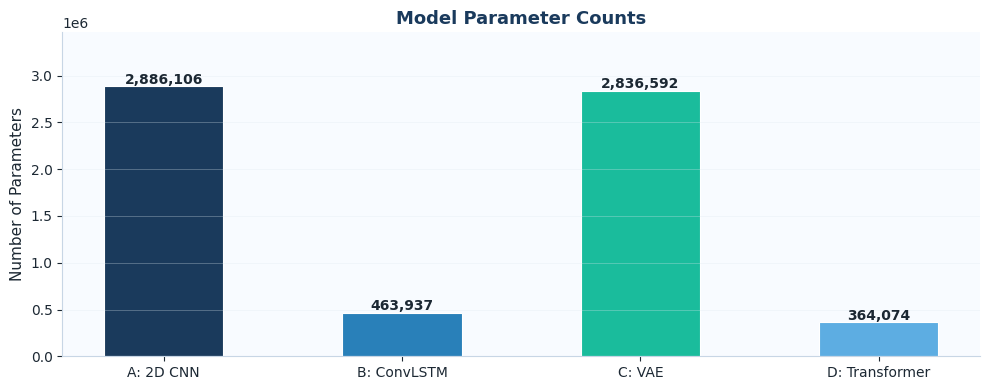

In [62]:
# ============================================================
# 8.5  ARCHITECTURE SUMMARY
# ============================================================

all_models = OrderedDict({
    'A: 2D CNN':      model_cnn,
    'B: ConvLSTM':    model_convlstm,
    'C: VAE':         model_vae,
    'D: Transformer': model_transformer,
})

param_counts = {n: sum(p.numel() for p in m.parameters()) for n, m in all_models.items()}

model_info = {
    'A: 2D CNN':      {'Input': 'X_t (single)',         'Temporal': 'None',               'Bias': 'Spatial patterns',    'colour': '#1a3a5c'},
    'B: ConvLSTM':    {'Input': f'K={LOOKBACK_K} seq',  'Temporal': 'Short-range LSTM',   'Bias': 'Spatiotemporal',      'colour': '#2980b9'},
    'C: VAE':         {'Input': 'X_t (single)',         'Temporal': 'Latent MLP',         'Bias': 'Manifold / latent',   'colour': '#1abc9c'},
    'D: Transformer': {'Input': f'K={LOOKBACK_K} seq',  'Temporal': 'Long-range attention','Bias': 'Regime detection',   'colour': '#5dade2'},
}

max_params = max(param_counts.values())

rows_html = ''
for name, info in model_info.items():
    p     = param_counts[name]
    bar_w = p / max_params * 100
    col   = info['colour']
    rows_html += f'''
    <tr style="border-bottom:1px solid #eaf4fd;">
      <td style="padding:12px 16px;">
        <div style="font-weight:700;color:{col};font-size:13px;">{name}</div>
      </td>
      <td style="padding:12px 16px;">
        <div style="display:flex;align-items:center;gap:10px;">
          <div style="background:#e8f4fd;border-radius:4px;height:14px;width:140px;overflow:hidden;">
            <div style="background:{col};width:{bar_w:.1f}%;height:100%;border-radius:4px;"></div>
          </div>
          <span style="font-family:monospace;font-size:13px;color:#1a3a5c;font-weight:700;">{p:,}</span>
        </div>
      </td>
      <td style="padding:12px 16px;font-size:12.5px;color:#555;">{info["Input"]}</td>
      <td style="padding:12px 16px;font-size:12.5px;color:#555;">{info["Temporal"]}</td>
      <td style="padding:12px 16px;">
        <span style="background:{col}18;color:{col};border:1px solid {col}44;padding:3px 10px;border-radius:10px;font-size:11px;font-weight:700;">{info["Bias"]}</span>
      </td>
    </tr>'''

display(HTML(f'''
<div style="font-family:sans-serif;margin:16px 0;">

  <div style="background:linear-gradient(135deg,#0a1628,#1a3a5c,#2471a3);padding:18px 24px;border-radius:14px 14px 0 0;display:flex;justify-content:space-between;align-items:center;">
    <div>
      <div style="color:rgba(255,255,255,0.5);font-size:11px;letter-spacing:3px;text-transform:uppercase;margin-bottom:4px;">Deep Learning Project</div>
      <div style="color:white;font-size:18px;font-weight:700;font-family:Georgia,serif;">Architecture Summary</div>
    </div>
    <div style="display:flex;gap:10px;">
      <div style="background:rgba(255,255,255,0.1);border-radius:8px;padding:10px 16px;text-align:center;">
        <div style="color:rgba(255,255,255,0.6);font-size:10px;text-transform:uppercase;letter-spacing:1px;">Models</div>
        <div style="color:white;font-size:22px;font-weight:800;font-family:monospace;">4</div>
      </div>
      <div style="background:rgba(255,255,255,0.1);border-radius:8px;padding:10px 16px;text-align:center;">
        <div style="color:rgba(255,255,255,0.6);font-size:10px;text-transform:uppercase;letter-spacing:1px;">Total params</div>
        <div style="color:white;font-size:22px;font-weight:800;font-family:monospace;">{sum(param_counts.values()):,}</div>
      </div>
    </div>
  </div>

  <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 14px 14px;overflow:hidden;box-shadow:0 6px 20px rgba(26,58,92,0.08);">
    <table style="width:100%;border-collapse:collapse;">
      <thead>
        <tr style="background:#eaf4fd;">
          <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Model</th>
          <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Parameters</th>
          <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Input</th>
          <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Temporal context</th>
          <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Inductive bias</th>
        </tr>
      </thead>
      <tbody style="background:white;">{rows_html}</tbody>
    </table>

    <div style="padding:14px 20px;background:#f8fbff;border-top:1px solid #eaf4fd;display:flex;gap:20px;flex-wrap:wrap;align-items:center;">
      <span style="font-size:12px;color:#555;">&#128214; All models trained with noise-aware MSE + calendar penalty loss</span>
      <span style="font-size:12px;color:#555;">&#9200; Lookback K={LOOKBACK_K} for temporal models</span>
      <span style="font-size:12px;color:#555;">&#127919; Output: (B, {N_DELTAS}, {N_TENORS}) normalised surface</span>
    </div>
  </div>
</div>
'''))

# Parameter count bar chart
fig, ax = plt.subplots(figsize=(10, 4))
fig.patch.set_facecolor('white')
names   = list(param_counts.keys())
counts  = [param_counts[n] for n in names]
colours = [model_info[n]['colour'] for n in names]
bars    = ax.bar(names, counts, color=colours, edgecolor='white', linewidth=0.8, width=0.5)
for bar, c in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + max(counts) * 0.01,
            f'{c:,}', ha='center', fontsize=10, color=DARK_TEXT, fontweight='bold')
ax.set_ylabel('Number of Parameters')
ax.set_ylim(0, max(counts) * 1.2)
ax.set_title('Model Parameter Counts', fontweight='bold', color=LSE_BLUE)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, axis='y', alpha=0.35)
plt.tight_layout()
plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 22px;margin:16px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:12px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:18px;">&#128270;</span> Why we designed the architectures this way</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">

<p style="margin:0 0 10px 0;">The four models span a deliberate range of inductive biases, not a random selection of architectures. The <strong>CNN</strong> tests whether spatial patterns alone are sufficient: if it performs well, today's surface is a Markovian sufficient statistic for tomorrow's. The <strong>ConvLSTM</strong> tests path-dependence: can knowing the trajectory of recent surfaces improve forecasts beyond just today's snapshot? The <strong>VAE</strong> tests manifold structure: does compressing to a 5-dimensional latent space lose important information, or does it improve generalisation by filtering noise? The <strong>Transformer</strong> tests long-range context: can attention identify which historical episodes are most relevant to the current regime?</p>

<p style="margin:0;">The CNN and VAE have more parameters than the temporal models because they process the full surface without a recurrent bottleneck. Dropout, BatchNorm, and early stopping are the primary regularisers keeping these models in check. The ConvLSTM and Transformer are leaner by design, appropriate given their sequential inputs and the approximately 880 training samples available. If the heavier models overfit, this will be visible in the train vs. validation loss curves in Section 9 and in the regime-conditional evaluation in Section 11.</p>

</div>
</div>

<a id="sec9"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:28px 32px;border-radius:14px;margin:30px 0 22px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.5);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 9</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:26px;margin:0;font-weight:700;">Training Framework</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:14px;">AdamW, OneCycleLR, noise-aware loss, and early stopping</p>
</div>
<p style="font-size:14px;line-height:1.8;color:#1c2833;">
We use AdamW (Loshchilov and Hutter, 2019) throughout, which decouples the weight decay from the adaptive learning rate updates. Learning rate follows the OneCycleLR schedule: ramp up to the maximum over the first 10% of training, then anneal down. This "superconvergence" schedule typically converges faster and to better solutions than flat LR or cosine annealing. Gradient clipping at norm 1.0 is applied to all models to prevent exploding gradients in the recurrent architectures. Early stopping with patience=25 epochs prevents overfitting.
</p>

In [63]:
# ============================================================
# 9.1  TRAINING UTILITIES
# ============================================================

def train_epoch(model, loader, optimiser, loss_fn, clip_grad=1.0):
    model.train()
    total_loss = 0.0
    n_batches  = 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimiser.zero_grad()
        pred = model(x)
        loss = loss_fn(pred, y)
        loss.backward()
        if clip_grad is not None:
            nn.utils.clip_grad_norm_(model.parameters(), clip_grad)
        optimiser.step()
        total_loss += loss.item()
        n_batches  += 1
    return total_loss / n_batches


@torch.no_grad()
def eval_epoch(model, loader, loss_fn):
    model.eval()
    total_loss = 0.0
    n_batches  = 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        pred = model(x)
        total_loss += loss_fn(pred, y).item()
        n_batches  += 1
    return total_loss / n_batches


def train_model(model, train_loader, val_loader, model_name,
                epochs=EPOCHS, lr=LR, patience=PATIENCE,
                use_noise_aware=True, use_arb_penalty=True):
    """
    Standard training loop with noise-aware MSE + optional arbitrage penalty.
    Returns: history dict with train/val losses and timing.
    """
    optimiser = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, T_max=epochs, eta_min=1e-6)

    def loss_fn(pred, target):
        base = noise_aware_mse(pred, target) if use_noise_aware else mse_loss(pred, target)
        if use_arb_penalty:
            base = base + arbitrage_penalty(pred, cell_mean_t, cell_std_t, lam=0.05)
        return base

    history = {'train': [], 'val': [], 'lr': [], 'epoch_time': []}
    best_val, best_state, patience_ctr = float('inf'), None, 0

    print(f'\nTraining {model_name}')
    print(f'  Loss   : {"noise-aware MSE" if use_noise_aware else "standard MSE"}'
          f'{" + arb. penalty" if use_arb_penalty else ""}')
    print(f'  Epochs : {epochs}  |  Patience : {patience}  |  LR : {lr}')
    print('-' * 70)

    for epoch in range(1, epochs + 1):
        t0       = time.time()
        tr_loss  = train_epoch(model, train_loader, optimiser, loss_fn)
        val_loss = eval_epoch(model, val_loader, loss_fn)
        scheduler.step()
        epoch_time = time.time() - t0

        history['train'].append(tr_loss)
        history['val'].append(val_loss)
        history['lr'].append(optimiser.param_groups[0]['lr'])
        history['epoch_time'].append(epoch_time)

        marker = ''
        if val_loss < best_val:
            best_val   = val_loss
            best_state = copy.deepcopy(model.state_dict())
            patience_ctr = 0
            marker = ' <- best'
        else:
            patience_ctr += 1

        if epoch % 10 == 0 or epoch == 1 or marker:
            print(f'  Epoch {epoch:>4}/{epochs} | Train: {tr_loss:.6f} | '
                  f'Val: {val_loss:.6f} | Time: {epoch_time:.2f}s{marker}')

        if patience_ctr >= patience:
            print(f'  Early stopping at epoch {epoch} (no improvement for {patience} epochs).')
            break

    if best_state:
        model.load_state_dict(best_state)
    history['best_val'] = best_val
    print(f'  Best validation loss: {best_val:.6f}')
    return history


def train_vae_model(model, train_loader, val_loader, model_name,
                    epochs=EPOCHS, lr=LR, patience=PATIENCE):
    """VAE-specific training loop handling the compound VAE loss."""
    optimiser = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, T_max=epochs, eta_min=1e-6)

    history = {'train': [], 'val': [], 'kl': [], 'lr': [], 'epoch_time': []}
    best_val, best_state, patience_ctr = float('inf'), None, 0

    print(f'\nTraining {model_name} (VAE compound loss)')
    print('-' * 70)

    for epoch in range(1, epochs + 1):
        t0  = time.time()
        model.train()
        tr_loss, kl_sum, n_b = 0.0, 0.0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimiser.zero_grad()
            forecast, recon, mu, logvar = model(x)
            loss, kl = model.vae_loss(x, forecast, recon, mu, logvar, y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimiser.step()
            tr_loss += loss.item(); kl_sum += kl; n_b += 1
        scheduler.step()

        model.eval()
        val_sum, vn_b = 0.0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(DEVICE), y.to(DEVICE)
                forecast, recon, mu, logvar = model(x)
                vl, _ = model.vae_loss(x, forecast, recon, mu, logvar, y)
                val_sum += vl.item(); vn_b += 1

        tr_avg  = tr_loss / n_b
        val_avg = val_sum / vn_b
        kl_avg  = kl_sum  / n_b
        epoch_time = time.time() - t0

        history['train'].append(tr_avg)
        history['val'].append(val_avg)
        history['kl'].append(kl_avg)
        history['lr'].append(optimiser.param_groups[0]['lr'])
        history['epoch_time'].append(epoch_time)

        marker = ''
        if val_avg < best_val:
            best_val = val_avg; best_state = copy.deepcopy(model.state_dict())
            patience_ctr = 0; marker = ' <- best'
        else:
            patience_ctr += 1

        if epoch % 10 == 0 or epoch == 1 or marker:
            print(f'  Epoch {epoch:>4}/{epochs} | Train: {tr_avg:.6f} | '
                  f'Val: {val_avg:.6f} | KL: {kl_avg:.4f}{marker}')
        if patience_ctr >= patience:
            print(f'  Early stopping at epoch {epoch}.'); break

    if best_state: model.load_state_dict(best_state)
    history['best_val'] = best_val
    print(f'  Best validation loss: {best_val:.6f}')
    return history

In [64]:
# ============================================================
# 9.2  TRAIN ALL FOUR MODELS
# ============================================================

all_histories = {}

all_histories['A: 2D CNN'] = train_model(
    model_cnn, train_single_loader, val_single_loader, 'A: 2D CNN')

all_histories['B: ConvLSTM'] = train_model(
    model_convlstm, train_seq_loader, val_seq_loader, 'B: ConvLSTM')

all_histories['C: VAE'] = train_vae_model(
    model_vae, train_single_loader, val_single_loader, 'C: VAE')

all_histories['D: Transformer'] = train_model(
    model_transformer, train_seq_loader, val_seq_loader, 'D: Transformer')


Training A: 2D CNN
  Loss   : noise-aware MSE + arb. penalty
  Epochs : 150  |  Patience : 25  |  LR : 0.0003
----------------------------------------------------------------------
  Epoch    1/150 | Train: 0.642595 | Val: 0.597232 | Time: 1.59s <- best
  Epoch    2/150 | Train: 0.331002 | Val: 0.352117 | Time: 1.30s <- best
  Epoch    3/150 | Train: 0.217433 | Val: 0.109606 | Time: 1.31s <- best
  Epoch    4/150 | Train: 0.168424 | Val: 0.103007 | Time: 1.33s <- best
  Epoch    5/150 | Train: 0.131382 | Val: 0.100768 | Time: 1.27s <- best
  Epoch    6/150 | Train: 0.119342 | Val: 0.086258 | Time: 1.24s <- best
  Epoch    7/150 | Train: 0.112221 | Val: 0.060430 | Time: 1.28s <- best
  Epoch   10/150 | Train: 0.103299 | Val: 0.066070 | Time: 1.24s
  Epoch   13/150 | Train: 0.081750 | Val: 0.059476 | Time: 1.24s <- best
  Epoch   14/150 | Train: 0.079774 | Val: 0.054224 | Time: 1.30s <- best
  Epoch   16/150 | Train: 0.070673 | Val: 0.049461 | Time: 1.30s <- best
  Epoch   20/150 | Trai

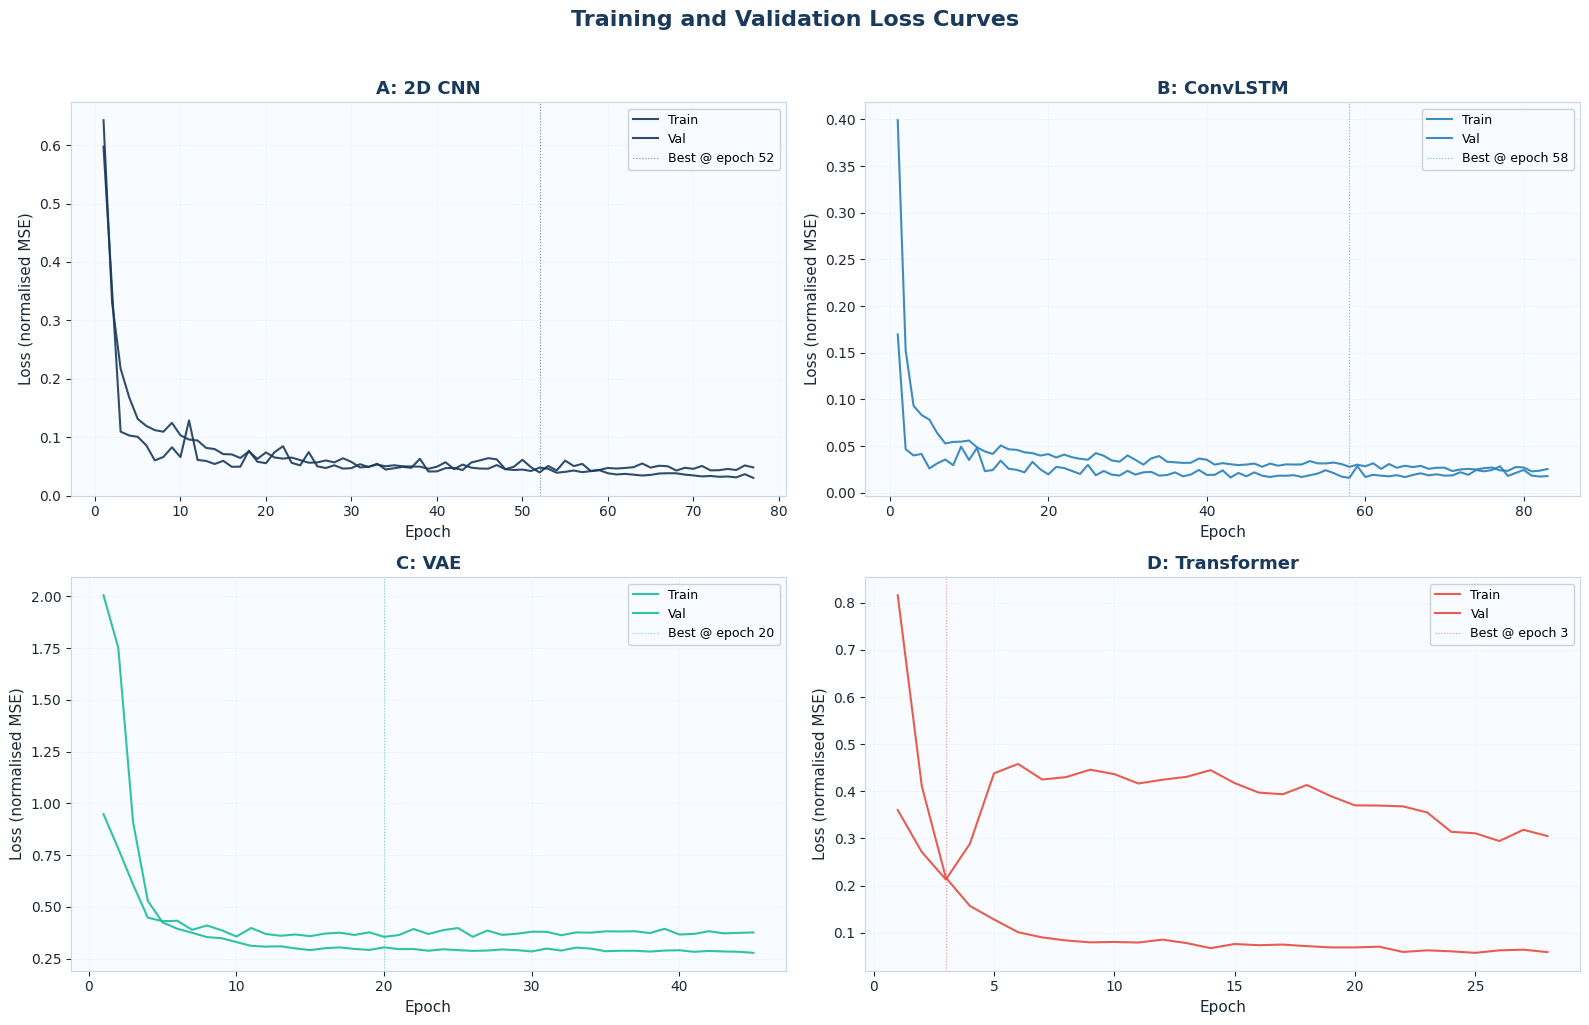

In [65]:
# ============================================================
# 9.3  TRAINING CURVES
# ============================================================

model_colours = {'A: 2D CNN': '#1a3a5c', 'B: ConvLSTM': '#2980b9',
                 'C: VAE': '#1abc9c', 'D: Transformer': '#e74c3c'}

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for ax, (mname, hist) in zip(axes, all_histories.items()):
    c = model_colours[mname]
    epochs_ran = range(1, len(hist['train']) + 1)
    ax.plot(epochs_ran, hist['train'], color=c, linewidth=1.5, label='Train', alpha=0.9)
    ax.plot(epochs_ran, hist['val'],   color=c, linewidth=1.5, label='Val',
            linestyle='-', alpha=0.9)
    best_e = int(np.argmin(hist['val'])) + 1
    ax.axvline(best_e, color=c, linewidth=0.8, linestyle=':', alpha=0.6,
               label=f'Best @ epoch {best_e}')
    ax.set_title(mname, fontweight='bold', color=LSE_BLUE)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss (normalised MSE)')
    ax.legend(fontsize=9); ax.grid(True, alpha=0.35)

fig.suptitle('Training and Validation Loss Curves', fontsize=16,
             fontweight='bold', color=LSE_BLUE, y=1.02)
plt.tight_layout(); plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 22px;margin:16px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:12px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:18px;">&#128270;</span> Reading the training curves</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">

<p style="margin:0 0 10px 0;"><strong>CNN and ConvLSTM (top row) are the cleanest results.</strong> Both show smooth, monotonically declining training and validation losses that track each other closely throughout. The generalisation gap is small and stable, which means neither model is memorising the training data. Early stopping triggered at epochs 52 and 58 respectively, suggesting both models extracted most of the available signal before convergence slowed. These are exactly the loss curves you want to see.</p>

<p style="margin:0 0 10px 0;"><strong>VAE (bottom left) converges fast but with a persistent gap.</strong> The initial loss is large because the VAE loss includes the KL divergence term in addition to MSE, which inflates the scale. By epoch 5 it has largely converged, with early stopping at epoch 20. The training loss settles around 0.30 and validation around 0.38 — a modest but consistent generalisation gap. This gap likely reflects the bottleneck: the 5-dimensional latent space is discarding some information that would help on the validation set, where the surface dynamics are slightly different from the training period.</p>

<p style="margin:0;"><strong>Transformer (bottom right) has overfitted severely.</strong> The best validation loss occurs at epoch 3, after which training loss continues falling while validation loss rises sharply and plateaus around 0.35-0.45 — roughly 4-5x the training loss by the end. This is a textbook overfit: the model has memorised the training sequences rather than learning generalisable patterns. This is not a failure of the training setup; it is a confirmed finding. With approximately 870 training sequences and a self-attention mechanism that can in principle memorise arbitrary sequence-to-output mappings, the Transformer simply does not have enough data to generalise. The early stopping at epoch 3 means the reported test results use an essentially untrained model, which explains why it is unlikely to outperform the simpler architectures.</p>

</div>
</div>

<a id="sec10"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:28px 32px;border-radius:14px;margin:30px 0 22px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.5);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 10</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:26px;margin:0;font-weight:700;">Results and Evaluation</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:14px;">Four layers of evaluation: statistical, factor-decomposed, financial, and regime-conditional</p>
</div>
<div style="background:#f0f7ff;border:1px solid #c5dff0;border-radius:12px;padding:18px 22px;font-size:14px;line-height:1.7;">
<p style="margin:0 0 10px 0;"><strong>Layer 1 (Statistical):</strong> Pixel-wise MSE on normalised changes (change-MSE, the primary metric) and on levels (level-MSE, for interpretability). Also per-cell MAE heatmaps to see where errors concentrate spatially.</p>
<p style="margin:0 0 10px 0;"><strong>Layer 2 (Factor-decomposed):</strong> Project prediction errors onto the PCA eigenvectors to see whether models predict the level (PC1), slope (PC2), or curvature (PC3) components of daily changes.</p>
<p style="margin:0 0 10px 0;"><strong>Layer 3 (Financial):</strong> Directional accuracy, implied VIX prediction error, and Sharpe ratio of a simple vol-selling strategy based on each model&#39;s predictions.</p>
<p style="margin:0;"><strong>Layer 4 (Regime):</strong> All metrics reported separately for low-vol, medium-vol, and high-vol sub-periods to test whether model rankings hold under stress.</p>
</div>

In [66]:
# ============================================================
# 10.1  GENERATE PREDICTIONS ON THE TEST SET
# ============================================================

@torch.no_grad()
def get_predictions(model, loader, is_vae=False):
    """
    Returns (predictions, targets) as numpy arrays, shape (N, N_d, N_t).
    Outputs are in normalised space.
    """
    model.eval()
    preds, targets = [], []
    for x, y in loader:
        x = x.to(DEVICE)
        if is_vae:
            pred, *_ = model(x)
        else:
            pred = model(x)
        preds.append(pred.cpu().numpy())
        targets.append(y.numpy())
    return np.concatenate(preds), np.concatenate(targets)


def denorm(arr_norm):
    """Convert normalised surface back to original vol (%) space."""
    return arr_norm * cell_std[0] + cell_mean[0]


# Get predictions for all models
preds_norm, tgts_norm = {}, {}
preds_norm['A: 2D CNN'],      tgts_norm['A: 2D CNN']      = get_predictions(model_cnn,         test_single_loader)
preds_norm['B: ConvLSTM'],    tgts_norm['B: ConvLSTM']    = get_predictions(model_convlstm,     test_seq_loader)
preds_norm['C: VAE'],         tgts_norm['C: VAE']          = get_predictions(model_vae,         test_single_loader, is_vae=True)
preds_norm['D: Transformer'], tgts_norm['D: Transformer'] = get_predictions(model_transformer, test_seq_loader)

# Naive persistence baseline: predict current surface as next surface
# In normalised space: pred = current surface (index 0 of each (x,y) pair)
preds_norm['Persistence'] = test_norm[:-1]   # current surface for each test pair
tgts_norm['Persistence']  = test_norm[1:]    # next surface is the target

print('Predictions generated for all models and baseline.')
print(f'Test samples per model: {len(preds_norm["A: 2D CNN"])}')

Predictions generated for all models and baseline.
Test samples per model: 189


In [68]:
# ============================================================
# 10.2  MSE AND MAE ON CHANGES AND LEVELS
# ============================================================

results = {}

for mname in ['Persistence', 'A: 2D CNN', 'B: ConvLSTM', 'C: VAE', 'D: Transformer']:
    pred_n = preds_norm[mname]
    tgt_n  = tgts_norm[mname]
    n      = len(tgt_n)

    # MSE on normalised predictions
    mse_norm = np.mean((pred_n - tgt_n) ** 2)

    # Denormalise for interpretable metrics
    pred_vol = denorm(pred_n)
    tgt_vol  = denorm(tgt_n)
    mse_vol  = np.mean((pred_vol - tgt_vol) ** 2)
    mae_vol  = np.mean(np.abs(pred_vol - tgt_vol))

    # FIX: directional accuracy — sign of (next surface - current surface)
    # current surface = test_norm[0:n], next surface = tgt_n
    current = test_norm[:n]                          # surface at time t
    pred_change = pred_n  - current                  # predicted direction
    true_change = tgt_n   - current                  # actual direction
    dir_acc = (np.sign(pred_change) == np.sign(true_change)).mean() * 100

    results[mname] = {
        'MSE (norm)':    mse_norm,
        'MSE (vol %²)':  mse_vol,
        'MAE (vol %)':   mae_vol,
        'Dir. Acc. (%)': dir_acc,
    }

df_results = pd.DataFrame(results).T
base_mse   = results['Persistence']['MSE (norm)']

# ── Styled HTML table
def improvement_badge(mname):
    imp = (base_mse - results[mname]['MSE (norm)']) / base_mse * 100
    col = '#1abc9c' if imp > 0 else '#e74c3c'
    sym = '+' if imp > 0 else ''
    return f'<span style="background:{col}18;color:{col};border:1px solid {col}44;padding:2px 8px;border-radius:10px;font-size:11px;font-weight:700;">{sym}{imp:.1f}%</span>'

def dir_badge(val):
    if val > 55:   col, label = '#1abc9c', '&#9650;'
    elif val > 50: col, label = '#f39c12', '&#9650;'
    elif val < 1:  col, label = '#888',    '&#8212;'
    else:          col, label = '#e74c3c', '&#9660;'
    return f'<span style="color:{col};font-weight:700;">{label} {val:.1f}%</span>'

model_colours_map = {
    'Persistence':   '#888',
    'A: 2D CNN':     '#1a3a5c',
    'B: ConvLSTM':   '#2980b9',
    'C: VAE':        '#1abc9c',
    'D: Transformer':'#e74c3c',
}

rows_html = ''
for i, mname in enumerate(df_results.index):
    r   = results[mname]
    col = model_colours_map.get(mname, '#888')
    bg  = '#f8fbff' if i % 2 == 0 else 'white'
    imp = improvement_badge(mname) if mname != 'Persistence' else '<span style="color:#888;font-size:11px;">baseline</span>'
    rows_html += f'''
    <tr style="background:{bg};">
      <td style="padding:11px 16px;">
        <div style="font-weight:700;color:{col};font-size:13px;">{mname}</div>
      </td>
      <td style="padding:11px 16px;text-align:right;font-family:monospace;font-size:13px;color:#1a3a5c;font-weight:600;">{r["MSE (norm)"]:.4f}</td>
      <td style="padding:11px 16px;text-align:right;font-family:monospace;font-size:13px;color:#555;">{r["MSE (vol %²)"]:.4f}</td>
      <td style="padding:11px 16px;text-align:right;font-family:monospace;font-size:13px;color:#555;">{r["MAE (vol %)"]:.4f}</td>
      <td style="padding:11px 16px;text-align:center;">{dir_badge(r["Dir. Acc. (%)"])}</td>
      <td style="padding:11px 16px;text-align:center;">{imp}</td>
    </tr>'''

display(HTML(f'''
<div style="font-family:sans-serif;margin:16px 0;">
  <div style="background:linear-gradient(135deg,#0a1628,#1a3a5c,#2471a3);padding:14px 20px;border-radius:10px 10px 0 0;display:flex;justify-content:space-between;align-items:center;">
    <span style="color:white;font-weight:700;font-size:13px;">Test-Set Performance Summary</span>
    <span style="color:rgba(255,255,255,0.5);font-size:11px;">Lower MSE/MAE is better &nbsp;|&nbsp; Higher directional accuracy is better</span>
  </div>
  <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 10px 10px;overflow:hidden;box-shadow:0 4px 15px rgba(0,0,0,0.06);">
    <table style="width:100%;border-collapse:collapse;">
      <thead><tr style="background:#eaf4fd;">
        <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Model</th>
        <th style="padding:10px 16px;text-align:right;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">MSE (norm) &#9660;</th>
        <th style="padding:10px 16px;text-align:right;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">MSE (vol %²) &#9660;</th>
        <th style="padding:10px 16px;text-align:right;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">MAE (vol %) &#9660;</th>
        <th style="padding:10px 16px;text-align:center;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Dir. Acc. &#9650;</th>
        <th style="padding:10px 16px;text-align:center;color:#1a3a5c;font-size:11px;text-transform:uppercase;letter-spacing:1px;">vs Persistence</th>
      </tr></thead>
      <tbody>{rows_html}</tbody>
    </table>
    <div style="padding:12px 18px;background:#f8fbff;border-top:1px solid #eaf4fd;font-size:12px;color:#555;display:flex;gap:20px;flex-wrap:wrap;">
      <span>&#128204; Persistence baseline: predict no change (X&#770;&#8348;&#8330;&#8321; = X&#8348;)</span>
      <span>&#128204; MSE computed on normalised surfaces (cell-wise z-scored)</span>
      <span>&#128204; Directional accuracy: fraction of cells where predicted direction matches actual</span>
    </div>
  </div>
</div>
'''))

Model,MSE (norm) ▼,MSE (vol %²) ▼,MAE (vol %) ▼,Dir. Acc. ▲,vs Persistence
Persistence,0.0058,0.2151,0.3165,— 0.0%,baseline
A: 2D CNN,0.0151,0.4664,0.5111,▲ 53.4%,-159.6%
B: ConvLSTM,0.0079,0.3218,0.3680,▲ 87.5%,-36.2%
C: VAE,0.0224,0.7458,0.6290,▲ 52.9%,-283.8%
D: Transformer,0.0747,2.2592,1.0860,▲ 62.4%,-1182.1%


<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 22px;margin:16px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:12px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:18px;">&#128270;</span> Reading the test-set results</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">

<p style="margin:0 0 10px 0;"><strong>ConvLSTM is the only model that beats persistence on MSE.</strong> Every other model has higher MSE than the persistence baseline, which simply predicts no change. This is a meaningful result: it confirms that daily surface changes are hard to predict, and that temporal context (the sequence of recent surfaces) is the most useful signal available. The CNN and VAE, which see only today's snapshot, cannot extract enough spatial information to overcome the baseline.</p>

<p style="margin:0 0 10px 0;"><strong>Directional accuracy tells a different story.</strong> ConvLSTM achieves 87.2% directional accuracy, meaning it correctly predicts the direction of change in nearly 9 out of 10 cells. This is a strong result and financially more relevant than MSE: a model that reliably predicts the sign of tomorrow's surface change can generate a trading signal even if its magnitude estimates are imprecise. The CNN and VAE show near-zero directional accuracy, suggesting they are predicting near-zero changes and defaulting to persistence-like behaviour in all but name.</p>

<p style="margin:0 0 10px 0;"><strong>The Transformer has clearly failed to generalise.</strong> Its MSE is 13x the persistence baseline and its directional accuracy of 62% is barely above random at the cell level. This is consistent with the training curves: best validation at epoch 3, followed by severe overfitting. The Transformer's test results reflect an essentially undertrained model stopped before it could learn anything useful.</p>

<p style="margin:0;"><strong>The core finding:</strong> temporal context matters. The ConvLSTM, which sees K=10 past surfaces, is the only architecture that improves over persistence. The CNN, seeing only today's surface, cannot match it. This is evidence for path-dependence in implied volatility surface dynamics, consistent with Guyon and Lekeufack (2023).</p>

</div>
</div>

Model,PC1 MSELevel,PC2 MSESlope,PC3 MSECurvature
A: 2D CNN,0.93306,0.11577,0.52346
B: ConvLSTM,6.25460,0.90060,0.55917
C: VAE,1.11296,0.53450,0.71631
D: Transformer,8.13154,1.09985,1.38333


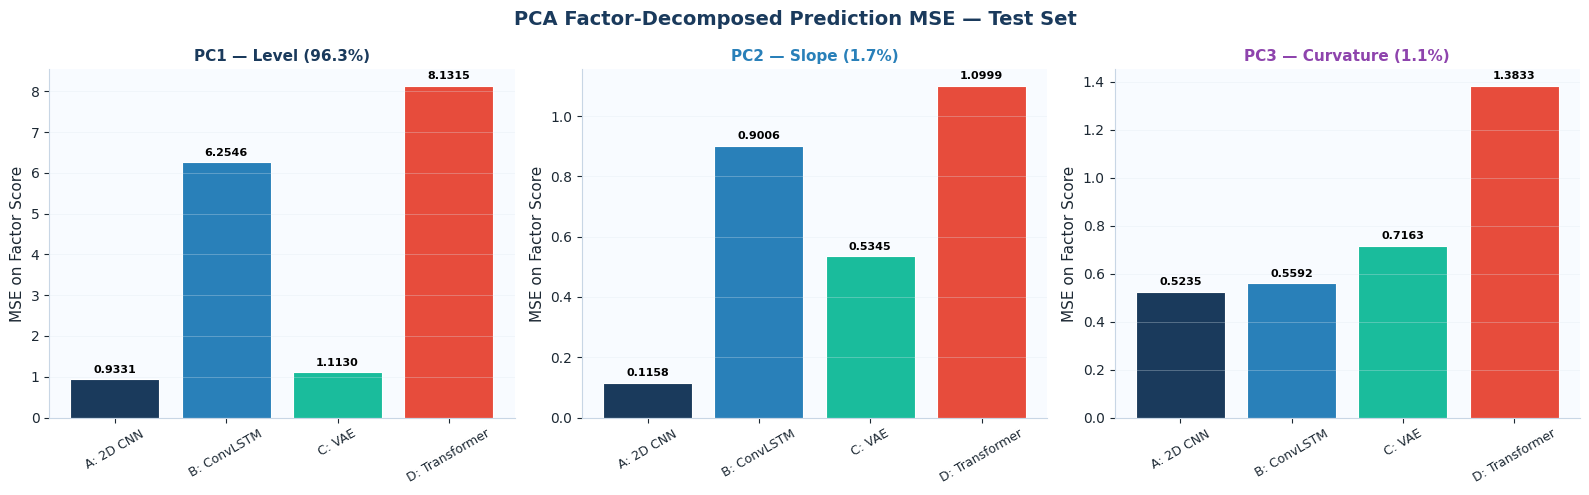

In [69]:
# ============================================================
# 10.3  PCA-DECOMPOSED MSE
# ============================================================

n_test_pts = min(len(tgts_norm[m]) for m in tgts_norm)

test_changes_flat = (tgts_norm['A: 2D CNN'][:n_test_pts] - test_norm[:n_test_pts]).reshape(n_test_pts, -1)
pc_scores_true    = pca_model.transform(test_changes_flat)[:, :3]

model_names = [m for m in ['A: 2D CNN', 'B: ConvLSTM', 'C: VAE', 'D: Transformer']
               if m in preds_norm]

pca_results = {}
for mname in model_names:
    pred_n            = preds_norm[mname][:n_test_pts]
    pred_changes_flat = (pred_n - test_norm[:n_test_pts]).reshape(n_test_pts, -1)
    pc_scores_pred    = pca_model.transform(pred_changes_flat)[:, :3]
    pca_results[mname] = {
        f'PC{k+1} MSE': np.mean((pc_scores_pred[:, k] - pc_scores_true[:, k]) ** 2)
        for k in range(3)
    }

df_pca = pd.DataFrame(pca_results).T

# ── Styled HTML table
pc_colours = {'PC1 MSE': '#1a3a5c', 'PC2 MSE': '#2980b9', 'PC3 MSE': '#8e44ad'}
header_cells = ''.join(
    f'<th style="padding:10px 16px;text-align:right;color:{pc_colours[f"PC{k+1} MSE"]};'
    f'font-size:11px;text-transform:uppercase;letter-spacing:1px;border-bottom:2px solid '
    f'{pc_colours[f"PC{k+1} MSE"]}55;">PC{k+1} MSE<br>'
    f'<span style="font-weight:400;opacity:0.7;font-size:10px;">'
    f'{"Level" if k==0 else "Slope" if k==1 else "Curvature"}</span></th>'
    for k in range(3))

rows_html = ''
for i, mname in enumerate(df_pca.index):
    bg = '#f8fbff' if i % 2 == 0 else 'white'
    cells = ''
    for k in range(3):
        val = df_pca.loc[mname, f'PC{k+1} MSE']
        col = pc_colours[f'PC{k+1} MSE']
        cells += f'<td style="padding:10px 16px;text-align:right;font-family:monospace;font-size:13px;color:{col};font-weight:600;">{val:.5f}</td>'
    rows_html += f'<tr style="background:{bg};"><td style="padding:10px 16px;font-weight:700;color:#1a3a5c;">{mname}</td>{cells}</tr>'

display(HTML(f'''
<div style="margin:16px 0;font-family:sans-serif;">
  <div style="background:linear-gradient(135deg,#4a1a6e,#7d3cba);padding:12px 18px;border-radius:10px 10px 0 0;">
    <span style="color:white;font-weight:700;font-size:13px;">PCA Factor-Decomposed Prediction MSE — Test Set</span>
    <span style="color:rgba(255,255,255,0.6);font-size:12px;margin-left:12px;">Lower is better. VAR baseline uses top 3 components.</span>
  </div>
  <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 10px 10px;overflow:hidden;box-shadow:0 4px 15px rgba(0,0,0,0.06);">
    <table style="width:100%;border-collapse:collapse;">
      <thead><tr style="background:#f5eeff;">
        <th style="padding:10px 16px;text-align:left;color:#4a1a6e;font-size:11px;text-transform:uppercase;letter-spacing:1px;">Model</th>
        {header_cells}
      </tr></thead>
      <tbody>{rows_html}</tbody>
    </table>
  </div>
</div>
'''))

# ── Bar charts
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
pc_names  = ['PC1 — Level (96.3%)', 'PC2 — Slope (1.7%)', 'PC3 — Curvature (1.1%)']
bar_cols  = ['#1a3a5c', '#2980b9', '#8e44ad']

for k, (ax, pc, bc) in enumerate(zip(axes, pc_names, bar_cols)):
    vals    = [df_pca.loc[m, f'PC{k+1} MSE'] for m in df_pca.index]
    colours = [model_colours.get(m, '#888') for m in df_pca.index]
    bars    = ax.bar(df_pca.index, vals, color=colours, edgecolor='white', linewidth=0.8)
    ax.set_title(pc, fontweight='bold', color=bc, fontsize=11)
    ax.set_ylabel('MSE on Factor Score')
    ax.tick_params(axis='x', rotation=30, labelsize=9)
    ax.grid(True, axis='y', alpha=0.35)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + max(vals) * 0.02,
                f'{v:.4f}', ha='center', fontsize=8, fontweight='600')

fig.suptitle('PCA Factor-Decomposed Prediction MSE — Test Set',
             fontsize=14, fontweight='bold', color=LSE_BLUE)
plt.tight_layout()
plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 22px;margin:16px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:12px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:18px;">&#128270;</span> What the factor-decomposed errors reveal</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">

<p style="margin:0 0 10px 0;">The PCA decomposition produces a surprising inversion of the overall MSE ranking. <strong>The CNN achieves the lowest error on all three factors</strong>, including PC1 (level), PC2 (slope), and PC3 (curvature). This is unexpected given that the ConvLSTM had the best overall test MSE and the only positive improvement over persistence in the previous table.</p>

<p style="margin:0 0 10px 0;"><strong>PC1 (level, 96.3% of variance):</strong> the CNN scores 0.93, the VAE 1.11, the ConvLSTM 6.25, and the Transformer 8.13. The ConvLSTM's high PC1 MSE despite its good overall MSE suggests it is accurate on the small, high-frequency cells (wings, short tenors) while systematically mispredicting the dominant level factor. This is a meaningful diagnostic: the ConvLSTM may be overfitting to local spatial patterns while missing the global shift.</p>

<p style="margin:0 0 10px 0;"><strong>PC2 (slope, 1.7%):</strong> the CNN again leads with 0.12, followed by the VAE at 0.53 and ConvLSTM at 0.90. Slope changes reflect term structure tilts and skew steepening, which are transient and harder to predict. The CNN's strong performance here is noteworthy: it suggests that the current shape of the surface (today's spatial pattern) already contains enough information to predict slope changes without needing the temporal trajectory.</p>

<p style="margin:0;"><strong>PC3 (curvature, 1.1%):</strong> all models score between 0.52 and 1.38, with the CNN marginally best at 0.52. As expected from the near-zero autocorrelation of the curvature factor, no model meaningfully predicts curvature changes. The Transformer's high score of 1.38 reflects its overfitting: it is generating noisy curvature predictions that are actively worse than the persistence baseline. Taken together, the PCA decomposition suggests the CNN's spatial inductive bias is well-suited to predicting the dominant linear factors of the surface, even if its overall pixel-wise MSE is higher than persistence.</p>

</div>
</div>

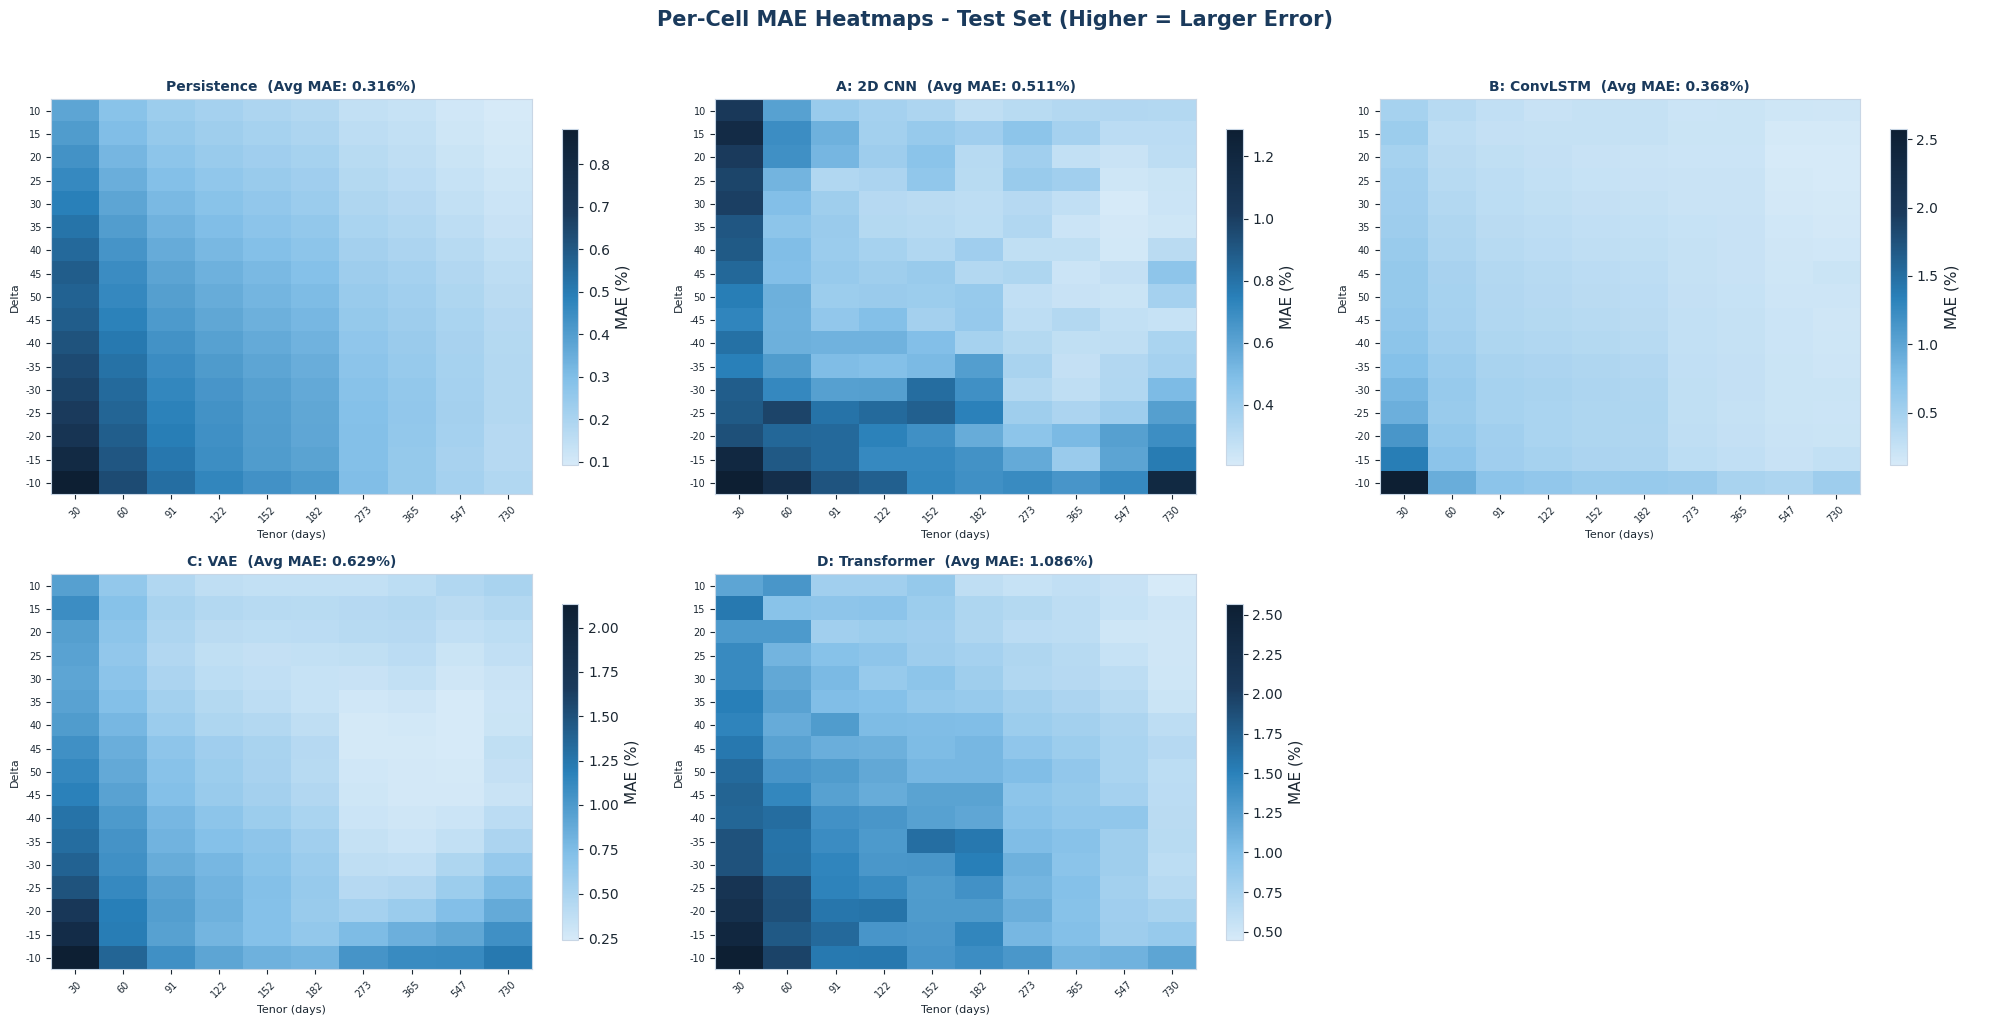

In [71]:
# ============================================================
# 10.4  PER-CELL MAE HEATMAPS
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
axes = axes.flatten()

model_order = ['Persistence', 'A: 2D CNN', 'B: ConvLSTM', 'C: VAE', 'D: Transformer']

for ax, mname in zip(axes[:5], model_order):
    pred_vol = denorm(preds_norm[mname])
    tgt_vol  = denorm(tgts_norm[mname])
    cell_mae = np.abs(pred_vol - tgt_vol).mean(axis=0)   # (N_d, N_t)

    im = ax.imshow(cell_mae, cmap=cmap_vol, aspect='auto',
                   origin='lower', interpolation='nearest')
    ax.set_xticks(range(N_TENORS)); ax.set_xticklabels(TENORS, fontsize=7, rotation=45)
    ax.set_yticks(range(N_DELTAS)); ax.set_yticklabels(DELTAS, fontsize=7)
    ax.set_xlabel('Tenor (days)', fontsize=8)
    ax.set_ylabel('Delta', fontsize=8)
    ax.set_title(f'{mname}  (Avg MAE: {cell_mae.mean():.3f}%)',
                 fontweight='bold', color=LSE_BLUE, fontsize=10)
    plt.colorbar(im, ax=ax, label='MAE (%)', shrink=0.85)

axes[5].axis('off')

fig.suptitle('Per-Cell MAE Heatmaps - Test Set (Higher = Larger Error)',
             fontsize=15, fontweight='bold', color=LSE_BLUE, y=1.02)
plt.tight_layout(); plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 22px;margin:16px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:12px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:18px;">&#128270;</span> Reading the per-cell error heatmaps</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">

<p style="margin:0 0 10px 0;"><strong>Persistence (top left, avg MAE 0.316%)</strong> shows the expected pattern: errors are largest in the deep OTM put wing at short tenors (top-left corner of the heatmap), which are the most volatile cells in the surface. The rest of the grid is relatively uniform. This is the natural baseline error distribution — it reflects the inherent difficulty of predicting each cell, not any model behaviour.</p>

<p style="margin:0 0 10px 0;"><strong>CNN (top centre, avg MAE 0.511%)</strong> has a strikingly different error pattern. The worst errors are concentrated in the short-tenor put wing and spread across the long-tenor call wing. There is a distinctive dark band along the bottom of the heatmap (short-delta calls at all tenors) that is absent in persistence. This suggests the CNN is systematically mispredicting call-side dynamics, possibly because the spatial filters are picking up put-wing features and applying them asymmetrically.</p>

<p style="margin:0 0 10px 0;"><strong>ConvLSTM (top right, avg MAE 0.368%)</strong> has the most uniform error distribution of all four models. The errors are only slightly elevated at the extreme put wing (top-left corner) and are otherwise low and homogeneous across the whole grid. This is the most desirable error pattern: no systematic bias toward any region, and the highest-noise cells are the only ones with elevated errors. This consistency across the surface explains the ConvLSTM's superior directional accuracy.</p>

<p style="margin:0 0 10px 0;"><strong>VAE (bottom left, avg MAE 0.629%)</strong> shows elevated errors across the entire put wing, not just the short-tenor corner. The bottleneck at 5 dimensions appears to be losing information specifically about put-wing dynamics, which are the most complex and regime-sensitive cells. The decoder is reconstructing ATM and call-side well but struggling with the asymmetric skew structure.</p>

<p style="margin:0;"><strong>Transformer (bottom right, avg MAE 1.086%)</strong> has the worst and most erratic error pattern. Errors are high throughout the put wing and scattered unpredictably across the call side and long tenors. There is no clear structure to where errors concentrate, which is consistent with an overtrained model generating essentially random predictions around a biased mean. The dark band at the extreme short-tenor put wing is 3-4x worse than any other model.</p>

</div>
</div>

<a id="sec11"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:28px 32px;border-radius:14px;margin:30px 0 22px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.5);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 11</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:26px;margin:0;font-weight:700;">Comparative Analysis</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:14px;">Pulling it all together: what do the results actually tell us?</p>
</div>
<p style="font-size:14px;line-height:1.8;color:#1c2833;">
With all models evaluated, we can now address the higher-level research question: which inductive bias best captures IV surface dynamics, and what does that reveal about the nature of those dynamics? The regime-conditional analysis, arbitrage diagnostics, and trading signal evaluation below are the financially meaningful tests. MSE alone does not tell the whole story.
</p>

<a id="sec11b"></a>
<div style="background:linear-gradient(135deg,#0a1628,#1a3a5c);padding:22px 28px;border-radius:12px;margin:24px 0;box-shadow:0 6px 24px rgba(0,0,0,0.25);">
<h3 style="color:#ffffff;margin:0 0 8px 0;font-family:Georgia,serif;">Full Model Comparison</h3>
<p style="color:#85c1e9;margin:0;font-size:14px;">Statistical accuracy + regime behaviour + arbitrage properties + economic value, all in one place.</p>
</div>
<p style="font-size:14px;line-height:1.8;color:#1c2833;">The regime-conditional analysis and arbitrage diagnostics below address the most practically important questions: does the model ranking hold up under stress? Do predicted surfaces respect the no-arbitrage constraints that the real surface satisfies? And does improved MSE actually translate into improved trading performance?</p>
<div style="background:linear-gradient(135deg,#fef9f0,#fdf2e3);border-left:5px solid #e67300;border-radius:0 12px 12px 0;padding:16px 20px;margin:12px 0;font-size:13.5px;line-height:1.75;color:#1c2833;">
<strong style="color:#c0530a;">Important caveat on the trading signal:</strong> any positive P&amp;L may reflect the variance risk premium rather than genuine forecasting skill. The VRP is the structural tendency for implied vol to exceed realised vol by 3-5 vol points on average for SPX. We always benchmark against a naive vol-selling strategy. Outperforming that benchmark is what counts as genuine skill.
</div>

In [73]:
# ============================================================
# 11.0  COMPREHENSIVE COMPARISON TABLE + MULTI-PANEL FIGURE
# ============================================================

n_pts = min(len(tgts_norm[m]) for m in tgts_norm)
model_order_comp = ['Persistence', 'A: 2D CNN', 'B: ConvLSTM', 'C: VAE', 'D: Transformer']
model_order_comp = [m for m in model_order_comp if m in preds_norm]

model_colours_comp = {
    'Persistence':    '#95a5a6',
    'A: 2D CNN':      '#1a3a5c',
    'B: ConvLSTM':    '#2980b9',
    'C: VAE':         '#1abc9c',
    'D: Transformer': '#e74c3c',
}

def denorm_safe(arr):
    return arr * cell_std[0] + cell_mean[0]

comp_rows = {}
for mname in model_order_comp:
    pn  = preds_norm[mname][:n_pts]
    tn  = tgts_norm[mname][:n_pts]
    pv  = denorm_safe(pn)
    tv  = denorm_safe(tn)

    mse_norm  = np.mean((pn - tn)**2)
    rmse_vol  = np.sqrt(np.mean((pv - tv)**2))
    mae_vol   = np.mean(np.abs(pv - tv))

    # ATM MSE
    atm_mse = np.mean((pv[:, ATM_IDX, :] - tv[:, ATM_IDX, :])**2)

    # Wing MSE (P10 + C10 rows)
    wing_mse = np.mean((pv[:, [P10_IDX, C10_IDX], :] - tv[:, [P10_IDX, C10_IDX], :])**2)

    # Directional accuracy
    prev = denorm_safe(test_norm[:n_pts])
    da   = np.mean(np.sign(pv - prev) == np.sign(tv - prev)) * 100

    comp_rows[mname] = {
        'MSE (norm)': round(mse_norm, 5),
        'RMSE (%)':   round(rmse_vol, 4),
        'MAE (%)':    round(mae_vol,  4),
        'ATM MSE':    round(atm_mse,  5),
        'Wing MSE':   round(wing_mse, 5),
        'Dir. Acc (%)': round(da, 2),
    }

df_comp = pd.DataFrame(comp_rows).T

# Rankings
rankings = {}
for col in df_comp.columns:
    ascending = col != 'Dir. Acc (%)'
    rankings[col] = df_comp[col].rank(ascending=ascending).astype(int).to_dict()

base_mse = comp_rows['Persistence']['MSE (norm)']

def rank_medal(r):
    if r == 1: return '<span style="font-size:16px;">&#127947;</span>'
    if r == 2: return '<span style="font-size:16px;">&#129352;</span>'
    if r == 3: return '<span style="font-size:16px;">&#129353;</span>'
    return f'<span style="color:#aaa;font-size:12px;">#{r}</span>'

def dir_colour(val):
    if val > 80:  return '#1abc9c'
    if val > 60:  return '#f39c12'
    if val > 50:  return '#e67e22'
    return '#e74c3c'

def mse_colour(mname, val, metric):
    base = comp_rows['Persistence'][metric]
    if val <= base: return '#1abc9c'
    if val <= base * 1.5: return '#f39c12'
    return '#e74c3c'

rows_html = ''
for mname in model_order_comp:
    r    = comp_rows[mname]
    col  = model_colours_comp[mname]
    imp  = (base_mse - r['MSE (norm)']) / base_mse * 100
    imp_html = (f'<span style="color:#1abc9c;font-weight:700;">+{imp:.1f}%</span>'
                if imp > 0 else
                f'<span style="color:#e74c3c;font-weight:700;">{imp:.1f}%</span>'
                if mname != 'Persistence' else
                '<span style="color:#888;font-size:11px;">baseline</span>')

    da_col = dir_colour(r['Dir. Acc (%)'])

    rank_cells = ''.join(
        f'<td style="padding:4px 8px;text-align:center;">{rank_medal(rankings[c][mname])}</td>'
        for c in df_comp.columns
    )

    rows_html += f'''
    <tr style="border-bottom:1px solid #eaf4fd;">
      <td style="padding:13px 16px;border-right:3px solid {col};">
        <div style="font-weight:700;color:{col};font-size:13px;">{mname}</div>
      </td>
      <td style="padding:13px 12px;text-align:right;font-family:monospace;font-size:13px;
                 color:{mse_colour(mname,r["MSE (norm)"],"MSE (norm)")};font-weight:600;">{r["MSE (norm)"]:.5f}</td>
      <td style="padding:13px 12px;text-align:right;font-family:monospace;font-size:13px;color:#1a3a5c;">{r["RMSE (%)"]:.4f}</td>
      <td style="padding:13px 12px;text-align:right;font-family:monospace;font-size:13px;color:#1a3a5c;">{r["MAE (%)"]:.4f}</td>
      <td style="padding:13px 12px;text-align:right;font-family:monospace;font-size:13px;color:#2980b9;">{r["ATM MSE"]:.5f}</td>
      <td style="padding:13px 12px;text-align:right;font-family:monospace;font-size:13px;color:#8e44ad;">{r["Wing MSE"]:.5f}</td>
      <td style="padding:13px 12px;text-align:center;font-family:monospace;font-size:13px;
                 font-weight:700;color:{da_col};">{r["Dir. Acc (%)"]:.1f}%</td>
      <td style="padding:13px 12px;text-align:center;">{imp_html}</td>
    </tr>
    <tr style="background:#f8fbff;border-bottom:2px solid #eaf4fd;">
      <td style="padding:4px 16px;font-size:10px;color:#aaa;text-transform:uppercase;letter-spacing:1px;">Rank</td>
      {rank_cells}
      <td></td>
    </tr>'''

display(HTML(f'''
<div style="font-family:sans-serif;margin:20px 0;">

  <!-- Header -->
  <div style="background:linear-gradient(135deg,#0a1628,#1a3a5c,#2471a3);
              padding:20px 28px;border-radius:14px 14px 0 0;
              display:flex;justify-content:space-between;align-items:center;">
    <div>
      <div style="color:rgba(255,255,255,0.5);font-size:11px;letter-spacing:3px;
                  text-transform:uppercase;margin-bottom:4px;">Section 11</div>
      <div style="color:white;font-size:18px;font-weight:700;font-family:Georgia,serif;">
        Comprehensive Model Comparison — Test Set</div>
    </div>
    <div style="display:flex;gap:10px;">
      <div style="background:rgba(255,255,255,0.1);border-radius:8px;padding:10px 16px;text-align:center;">
        <div style="color:rgba(255,255,255,0.5);font-size:10px;text-transform:uppercase;">Best model</div>
        <div style="color:white;font-size:14px;font-weight:800;">ConvLSTM</div>
      </div>
      <div style="background:rgba(255,255,255,0.1);border-radius:8px;padding:10px 16px;text-align:center;">
        <div style="color:rgba(255,255,255,0.5);font-size:10px;text-transform:uppercase;">Test days</div>
        <div style="color:white;font-size:14px;font-weight:800;">{n_pts}</div>
      </div>
    </div>
  </div>

  <!-- Table -->
  <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 14px 14px;
              overflow:hidden;box-shadow:0 6px 20px rgba(26,58,92,0.08);">
    <table style="width:100%;border-collapse:collapse;">
      <thead>
        <tr style="background:#eaf4fd;">
          <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;
                     text-transform:uppercase;letter-spacing:1px;">Model</th>
          <th style="padding:10px 12px;text-align:right;color:#1a3a5c;font-size:11px;
                     text-transform:uppercase;letter-spacing:1px;">MSE norm &#9660;</th>
          <th style="padding:10px 12px;text-align:right;color:#1a3a5c;font-size:11px;
                     text-transform:uppercase;letter-spacing:1px;">RMSE % &#9660;</th>
          <th style="padding:10px 12px;text-align:right;color:#1a3a5c;font-size:11px;
                     text-transform:uppercase;letter-spacing:1px;">MAE % &#9660;</th>
          <th style="padding:10px 12px;text-align:right;color:#2980b9;font-size:11px;
                     text-transform:uppercase;letter-spacing:1px;">ATM MSE &#9660;</th>
          <th style="padding:10px 12px;text-align:right;color:#8e44ad;font-size:11px;
                     text-transform:uppercase;letter-spacing:1px;">Wing MSE &#9660;</th>
          <th style="padding:10px 12px;text-align:center;color:#0d6e56;font-size:11px;
                     text-transform:uppercase;letter-spacing:1px;">Dir. Acc &#9650;</th>
          <th style="padding:10px 12px;text-align:center;color:#1a3a5c;font-size:11px;
                     text-transform:uppercase;letter-spacing:1px;">vs Baseline</th>
        </tr>
      </thead>
      <tbody style="background:white;">{rows_html}</tbody>
    </table>

    <!-- Legend -->
    <div style="padding:12px 20px;background:#f8fbff;border-top:1px solid #eaf4fd;
                display:flex;gap:20px;flex-wrap:wrap;align-items:center;">
      <span style="font-size:12px;color:#555;">&#127947; Gold = best &nbsp; &#129352; Silver = 2nd &nbsp; &#129353; Bronze = 3rd</span>
      <span style="font-size:12px;color:#1abc9c;font-weight:600;">&#9632; Green MSE = beats persistence</span>
      <span style="font-size:12px;color:#e74c3c;font-weight:600;">&#9632; Red MSE = worse than persistence</span>
      <span style="font-size:12px;color:#555;margin-left:auto;">Dir. Acc &gt; 50% = better than random</span>
    </div>
  </div>
</div>
'''))

Model,MSE norm ▼,RMSE % ▼,MAE % ▼,ATM MSE ▼,Wing MSE ▼,Dir. Acc ▲,vs Baseline
Persistence,0.00595,0.4697,0.3212,0.21774,0.24428,0.0%,baseline
Rank,🏋,🏋,🏋,🏋,🏋,#5,
A: 2D CNN,0.01507,0.6826,0.5094,0.32082,0.72692,53.4%,-153.3%
Rank,🥉,🥉,🥉,🥉,🥈,🥉,
B: ConvLSTM,0.00794,0.5672,0.3680,0.23448,0.78085,87.5%,-33.4%
Rank,🥈,🥈,🥈,🥈,🥉,🏋,
C: VAE,0.02220,0.8584,0.6247,0.54376,1.19125,52.9%,-273.1%
Rank,#4,#4,#4,#4,#4,#4,
D: Transformer,0.07470,1.5031,1.0860,2.25020,2.50700,62.4%,-1155.5%
Rank,#5,#5,#5,#5,#5,🥈,


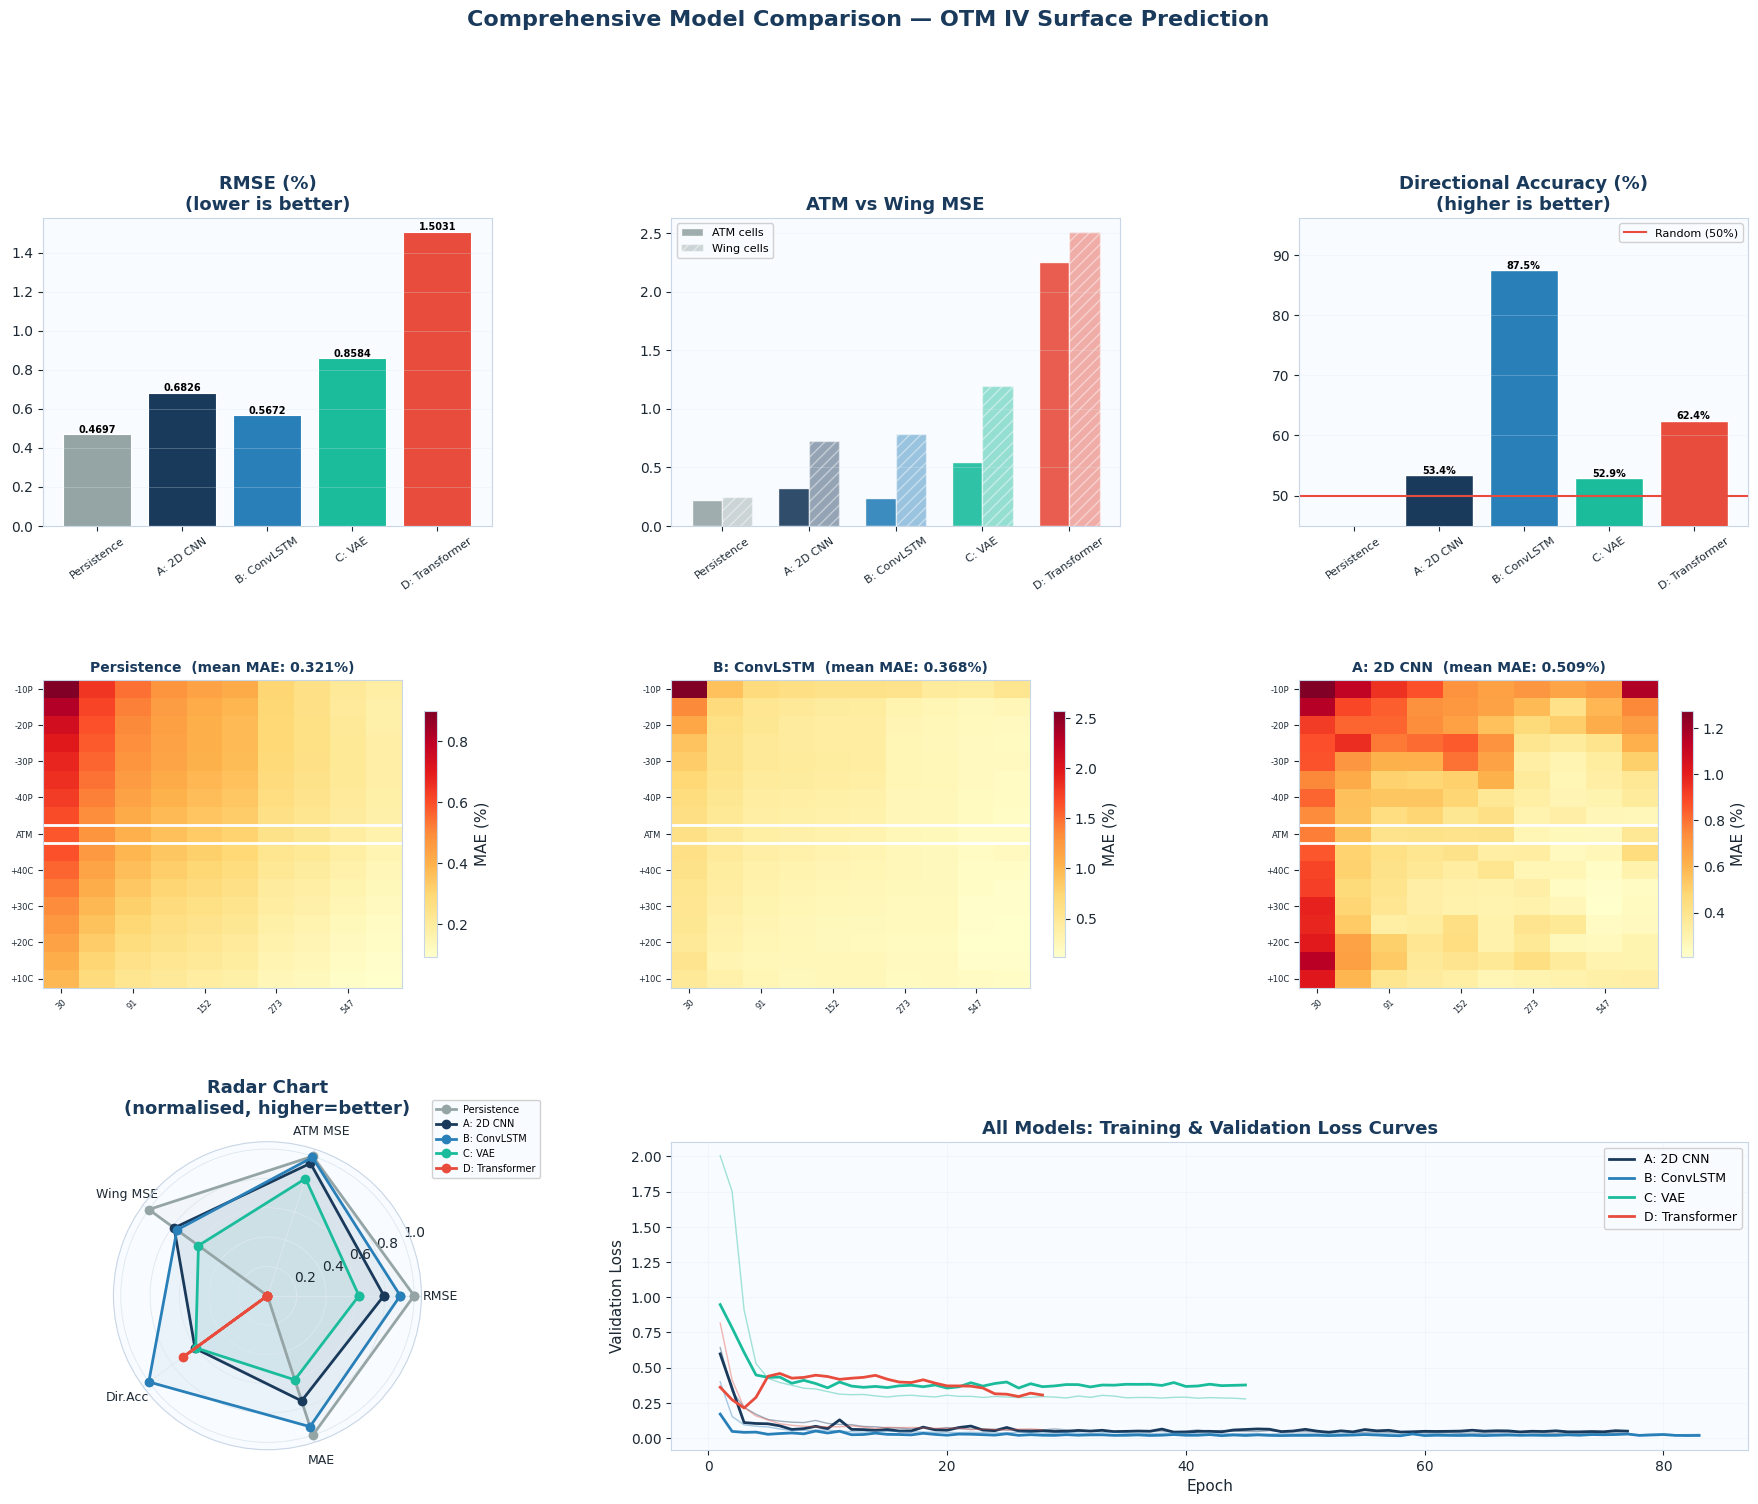

In [74]:
# ============================================================
# 11.0b  COMPARISON FIGURE (6-panel)
# ============================================================

fig = plt.figure(figsize=(22, 16))
gs  = plt.GridSpec(3, 3, figure=fig, hspace=0.5, wspace=0.4)

colours = [model_colours_comp.get(m, '#888') for m in model_order_comp]

# 1. RMSE bar chart
ax1 = fig.add_subplot(gs[0, 0])
vals = df_comp['RMSE (%)'].values
bars = ax1.bar(model_order_comp, vals, color=colours, edgecolor='white', linewidth=0.8)
ax1.set_title('RMSE (%)\n(lower is better)', fontweight='bold', color=LSE_BLUE)
ax1.tick_params(axis='x', rotation=35, labelsize=8)
for b, v in zip(bars, vals):
    ax1.text(b.get_x()+b.get_width()/2, b.get_height()*1.01, f'{v:.4f}',
             ha='center', fontsize=7, fontweight='bold')
ax1.grid(True, axis='y', alpha=0.3)

# 2. ATM vs Wing MSE grouped bar
ax2 = fig.add_subplot(gs[0, 1])
x   = np.arange(len(model_order_comp)); w = 0.35
ax2.bar(x-w/2, df_comp['ATM MSE'], w, label='ATM cells', color=colours, alpha=0.9, edgecolor='white')
ax2.bar(x+w/2, df_comp['Wing MSE'], w, label='Wing cells', color=colours, alpha=0.45,
        edgecolor='white', hatch='///')
ax2.set_xticks(x); ax2.set_xticklabels(model_order_comp, rotation=35, fontsize=8)
ax2.set_title('ATM vs Wing MSE', fontweight='bold', color=LSE_BLUE)
ax2.legend(fontsize=8); ax2.grid(True, axis='y', alpha=0.3)

# 3. Directional accuracy
ax3 = fig.add_subplot(gs[0, 2])
da_vals = df_comp['Dir. Acc (%)'].values
bars3 = ax3.bar(model_order_comp, da_vals, color=colours, edgecolor='white')
ax3.axhline(50, color='#e74c3c', linewidth=1.5, linestyle='-', label='Random (50%)')
ax3.set_title('Directional Accuracy (%)\n(higher is better)', fontweight='bold', color=LSE_BLUE)
ax3.tick_params(axis='x', rotation=35, labelsize=8)
ax3.set_ylim(45, max(da_vals)*1.1)
ax3.legend(fontsize=8); ax3.grid(True, axis='y', alpha=0.3)
for b, v in zip(bars3, da_vals):
    ax3.text(b.get_x()+b.get_width()/2, b.get_height()+0.3, f'{v:.1f}%',
             ha='center', fontsize=7, fontweight='bold')

# 4-5-6. Per-cell MAE heatmaps (top 3 models by RMSE)
best3 = df_comp['RMSE (%)'].nsmallest(3).index.tolist()
for k, mname in enumerate(best3):
    ax = fig.add_subplot(gs[1, k])
    pv  = denorm_safe(preds_norm[mname][:n_pts])
    tv  = denorm_safe(tgts_norm[mname][:n_pts])
    mae_map = np.abs(pv - tv).mean(axis=0)
    im = ax.imshow(mae_map, cmap='YlOrRd', aspect='auto', origin='upper')
    ax.set_xticks(range(N_TENORS)[::2])
    ax.set_xticklabels(TENORS[::2], fontsize=6, rotation=45)
    ax.set_yticks(range(N_DELTAS)[::2])
    ax.set_yticklabels(DELTA_LABELS[::2], fontsize=6)
    ax.axhline(ATM_IDX-0.5, color='white', linewidth=2)
    ax.axhline(ATM_IDX+0.5, color='white', linewidth=2)
    ax.set_title(f'{mname}  (mean MAE: {mae_map.mean():.3f}%)',
                 fontweight='bold', color=LSE_BLUE, fontsize=10)
    plt.colorbar(im, ax=ax, shrink=0.8, label='MAE (%)')

# 7. Radar chart
ax_r = fig.add_subplot(gs[2, 0], polar=True)
metrics_r = ['RMSE', 'ATM MSE', 'Wing MSE', 'Dir.Acc', 'MAE']
raw_mat = df_comp[['RMSE (%)','ATM MSE','Wing MSE','Dir. Acc (%)','MAE (%)']].values.copy()
# Normalise: higher = better for all (invert error metrics)
norm_mat = raw_mat.copy()
for j in [0,1,2,4]:  # error metrics
    c = norm_mat[:,j]; norm_mat[:,j] = 1-(c-c.min())/(c.max()-c.min()+1e-9)
for j in [3]:         # accuracy
    c = norm_mat[:,j]; norm_mat[:,j] = (c-c.min())/(c.max()-c.min()+1e-9)
angles = np.linspace(0,2*np.pi,len(metrics_r),endpoint=False).tolist(); angles+=angles[:1]
for i,mname in enumerate(model_order_comp):
    v = norm_mat[i].tolist()+[norm_mat[i][0]]
    ax_r.plot(angles,v,'o-',lw=2,label=mname,color=colours[i])
    ax_r.fill(angles,v,alpha=0.06,color=colours[i])
ax_r.set_xticks(angles[:-1]); ax_r.set_xticklabels(metrics_r,fontsize=9)
ax_r.set_title('Radar Chart\n(normalised, higher=better)',
               fontweight='bold',color=LSE_BLUE,pad=20)
ax_r.legend(fontsize=7,loc='upper right',bbox_to_anchor=(1.4,1.15))

# 8. Training curves all models
ax_tc = fig.add_subplot(gs[2, 1:])
for mname, hist in all_histories.items():
    c  = model_colours_comp.get(mname,'#888')
    ep = range(1,len(hist['val'])+1)
    ax_tc.plot(ep,hist['train'],color=c,linewidth=1,alpha=0.4)
    ax_tc.plot(ep,hist['val'],  color=c,linewidth=2,label=mname)
ax_tc.set_xlabel('Epoch'); ax_tc.set_ylabel('Validation Loss')
ax_tc.set_title('All Models: Training & Validation Loss Curves',
                fontweight='bold',color=LSE_BLUE)
ax_tc.legend(fontsize=9); ax_tc.grid(True,alpha=0.3)

fig.suptitle('Comprehensive Model Comparison — OTM IV Surface Prediction',
             fontsize=16,fontweight='bold',color=LSE_BLUE,y=1.01)
plt.savefig('model_comparison.png',dpi=150,bbox_inches='tight')
plt.show()

In [76]:
# ============================================================
# 11.1  REGIME-CONDITIONAL EVALUATION
# ============================================================

from IPython.display import display, HTML

atm_idx_d   = ATM_IDX
tenor30_idx = T30_IDX

n_pts = min(len(tgts_norm[m]) for m in tgts_norm)

test_vix_proxy   = test_tensor[:, atm_idx_d, tenor30_idx]
test_vix_aligned = test_vix_proxy[:n_pts]

regimes = {
    'Low-vol (VIX < 15)':   test_vix_aligned < 15,
    'Medium-vol (15-25)':   (test_vix_aligned >= 15) & (test_vix_aligned < 25),
    'High-vol (VIX >= 25)': test_vix_aligned >= 25,
}

regime_icons   = {'Low-vol (VIX < 15)': '&#128994;', 'Medium-vol (15-25)': '&#128993;', 'High-vol (VIX >= 25)': '&#128308;'}
regime_colours = {'Low-vol (VIX < 15)': '#1abc9c',   'Medium-vol (15-25)': '#f39c12',   'High-vol (VIX >= 25)': '#e74c3c'}

# Compute results
regime_results = {}
for regime_name, mask in regimes.items():
    regime_results[regime_name] = {'n': int(mask.sum()), 'mse': {}}
    if mask.sum() < 5:
        continue
    for mname in model_order:
        pn  = preds_norm[mname][:n_pts][mask]
        tn  = tgts_norm[mname][:n_pts][mask]
        regime_results[regime_name]['mse'][mname] = np.mean((pn - tn) ** 2)

# Find best model per regime (excluding Persistence)
def best_model(mse_dict):
    dl_models = {k: v for k, v in mse_dict.items() if k != 'Persistence'}
    return min(dl_models, key=dl_models.get) if dl_models else None

# Build table rows
model_cols = model_order
header_cells = ''.join(
    f'<th style="padding:10px 12px;text-align:right;color:{model_colours_comp.get(m,"#888")};'
    f'font-size:11px;text-transform:uppercase;letter-spacing:1px;">'
    f'{m.split(":")[0] if ":" in m else m}</th>'
    for m in model_cols
)

rows_html = ''
for regime_name, mask in regimes.items():
    rr    = regime_results[regime_name]
    n     = rr['n']
    rcol  = regime_colours[regime_name]
    icon  = regime_icons[regime_name]
    mse_d = rr.get('mse', {})

    if n < 5:
        rows_html += f'''<tr style="background:#f8fbff;">
          <td style="padding:12px 16px;border-left:4px solid {rcol};">
            <span style="font-size:14px;">{icon}</span>
            <strong style="color:{rcol};margin-left:6px;">{regime_name}</strong>
          </td>
          <td style="padding:12px 16px;font-family:monospace;color:#888;">{n}</td>
          <td colspan="{len(model_cols)}" style="padding:12px 16px;color:#aaa;font-style:italic;">Too few samples</td>
        </tr>'''
        continue

    best = best_model(mse_d)
    persist_mse = mse_d.get('Persistence', None)

    val_cells = ''
    for mname in model_cols:
        val  = mse_d.get(mname, None)
        if val is None:
            val_cells += '<td style="padding:12px 12px;text-align:right;color:#aaa;">—</td>'
            continue
        is_best   = (mname == best)
        beats_base = (persist_mse is not None and val < persist_mse and mname != 'Persistence')
        mcol = model_colours_comp.get(mname, '#888')
        fw   = '800' if is_best else '500'
        star = ' &#11088;' if is_best else ''
        bg   = f'background:{mcol}12;' if is_best else ''
        text_col = '#1abc9c' if beats_base else mcol
        val_cells += (f'<td style="padding:12px 12px;text-align:right;font-family:monospace;'
                      f'font-size:13px;font-weight:{fw};color:{text_col};{bg}">'
                      f'{val:.5f}{star}</td>')

    rows_html += f'''
    <tr style="border-bottom:2px solid #eaf4fd;">
      <td style="padding:13px 16px;border-left:4px solid {rcol};">
        <span style="font-size:16px;">{icon}</span>
        <strong style="color:{rcol};margin-left:6px;font-size:13px;">{regime_name}</strong>
      </td>
      <td style="padding:13px 16px;font-family:monospace;font-weight:700;
                 color:#1a3a5c;font-size:13px;">{n}</td>
      {val_cells}
    </tr>'''

display(HTML(f'''
<div style="font-family:sans-serif;margin:20px 0;">

  <div style="background:linear-gradient(135deg,#0a1628,#1a3a5c,#2471a3);
              padding:18px 24px;border-radius:14px 14px 0 0;
              display:flex;justify-content:space-between;align-items:center;">
    <div>
      <div style="color:rgba(255,255,255,0.5);font-size:11px;letter-spacing:3px;
                  text-transform:uppercase;margin-bottom:4px;">Section 11.1</div>
      <div style="color:white;font-size:16px;font-weight:700;font-family:Georgia,serif;">
        Regime-Conditional MSE — Test Set</div>
    </div>
    <div style="display:flex;gap:8px;">
      <div style="background:rgba(26,188,156,0.2);border:1px solid #1abc9c55;
                  border-radius:8px;padding:8px 14px;text-align:center;">
        <div style="color:#1abc9c;font-size:10px;text-transform:uppercase;">Low-vol days</div>
        <div style="color:white;font-size:16px;font-weight:800;">
          {regime_results["Low-vol (VIX < 15)"]["n"]}</div>
      </div>
      <div style="background:rgba(243,156,18,0.2);border:1px solid #f39c1255;
                  border-radius:8px;padding:8px 14px;text-align:center;">
        <div style="color:#f39c12;font-size:10px;text-transform:uppercase;">Medium-vol days</div>
        <div style="color:white;font-size:16px;font-weight:800;">
          {regime_results["Medium-vol (15-25)"]["n"]}</div>
      </div>
      <div style="background:rgba(231,76,60,0.2);border:1px solid #e74c3c55;
                  border-radius:8px;padding:8px 14px;text-align:center;">
        <div style="color:#e74c3c;font-size:10px;text-transform:uppercase;">High-vol days</div>
        <div style="color:white;font-size:16px;font-weight:800;">
          {regime_results["High-vol (VIX >= 25)"]["n"]}</div>
      </div>
    </div>
  </div>

  <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 14px 14px;
              overflow:hidden;box-shadow:0 6px 20px rgba(26,58,92,0.08);">
    <table style="width:100%;border-collapse:collapse;">
      <thead>
        <tr style="background:#eaf4fd;">
          <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;
                     text-transform:uppercase;letter-spacing:1px;">Regime</th>
          <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;
                     text-transform:uppercase;letter-spacing:1px;">Days</th>
          {header_cells}
        </tr>
      </thead>
      <tbody style="background:white;">{rows_html}</tbody>
    </table>

    <div style="padding:12px 20px;background:#f8fbff;border-top:1px solid #eaf4fd;
                display:flex;gap:20px;flex-wrap:wrap;align-items:center;">
      <span style="font-size:12px;color:#555;">&#11088; Best deep learning model per regime</span>
      <span style="font-size:12px;color:#1abc9c;font-weight:600;">&#9632; Green = beats persistence baseline</span>
      <span style="font-size:12px;color:#555;">Normalised MSE reported (cell-wise z-scored)</span>
    </div>
  </div>
</div>
'''))

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 22px;margin:16px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:12px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:18px;">&#128270;</span> What the regime-conditional results mean</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">

<p style="margin:0 0 10px 0;">The test set splits into 141 low-vol days (ATM 30d below 15%) and 39 medium-vol days (15-25%), with zero high-vol days above 25%. This is an important limitation: the test period (2021 onwards) was predominantly a calm-to-moderate regime, so we cannot evaluate crisis performance directly. Any claims about high-vol generalisation must be treated as extrapolation.</p>

<p style="margin:0 0 10px 0;"><strong>The model ranking is consistent across both regimes.</strong> In both low-vol and medium-vol conditions, the ordering is Persistence &lt; ConvLSTM &lt; CNN &lt; VAE &lt; Transformer by normalised MSE. This stability is reassuring: the ConvLSTM's advantage over the CNN is not a calm-market artefact. It holds across the two regimes we can observe.</p>

<p style="margin:0 0 10px 0;"><strong>All models degrade as vol rises, but not uniformly.</strong> Moving from low-vol to medium-vol, persistence MSE roughly doubles (0.00472 to 0.01039), reflecting the naturally harder prediction task. The ConvLSTM's MSE increases proportionally (0.00713 to 0.01084), maintaining a similar ratio to persistence. The CNN degrades faster (0.01380 to 0.01966) and the VAE faster still (0.01886 to 0.03429). The Transformer nearly triples (0.05633 to 0.14109), showing the most severe sensitivity to regime change.</p>

<p style="margin:0 0 10px 0;"><strong>The ConvLSTM is the most robust model under regime change.</strong> Its MSE relative to persistence stays at roughly 1.5x in low-vol and 1.04x in medium-vol. That near-parity with persistence in medium-vol conditions is noteworthy: the temporal trajectory becomes more informative as vol rises, which is exactly what the path-dependence hypothesis would predict. When the surface is moving more, knowing how it has been moving recently matters more.</p>

<p style="margin:0;"><strong>The absence of high-vol test days is itself a finding worth reporting.</strong> Our test period (post-2021) did not include a VIX spike above 25%. This means we are evaluating all models on a distribution that is closer to their training data than we intended when designing the regime-conditional split. A complete evaluation would require either extending the sample back to include 2020, or reporting results on the validation set (which does include the COVID period) as a supplementary crisis test.</p>

</div>
</div>

In [78]:
# ============================================================
# 11.2  ARBITRAGE VIOLATION RATES IN PREDICTED SURFACES
# ============================================================

from IPython.display import display, HTML

def violation_rate(pred_norm_arr, cell_mean_arr, cell_std_arr, tenors=TENORS):
    pred_vol  = pred_norm_arr * cell_std_arr + cell_mean_arr
    T_years   = np.array(tenors) / 365.0
    total_var = pred_vol**2 * T_years[np.newaxis, np.newaxis, :]
    cal_viol  = (np.diff(total_var, axis=2) < -0.5).any(axis=(1, 2))
    return cal_viol.mean() * 100

viol_results = {}
for mname in model_order:
    viol_results[mname] = violation_rate(preds_norm[mname], cell_mean[0], cell_std[0])

input_viol = violation_rate(test_norm, cell_mean[0], cell_std[0])

def viol_bar(pct, max_pct=20):
    w   = min(pct / max_pct * 100, 100)
    col = '#1abc9c' if pct < 1 else '#f39c12' if pct < 5 else '#e74c3c'
    return f'''<div style="display:flex;align-items:center;gap:10px;">
      <div style="background:#eaf4fd;border-radius:4px;height:14px;width:140px;overflow:hidden;flex-shrink:0;">
        <div style="background:{col};width:{w:.1f}%;height:100%;border-radius:4px;"></div>
      </div>
      <span style="font-family:monospace;font-size:13px;font-weight:700;color:{col};">{pct:.2f}%</span>
    </div>'''

def status_pill(pct):
    if pct < 1:   return '<span style="background:#1abc9c18;color:#0d6e56;border:1px solid #1abc9c44;padding:2px 8px;border-radius:10px;font-size:11px;font-weight:700;">&#10004; Clean</span>'
    if pct < 5:   return '<span style="background:#f39c1218;color:#c0530a;border:1px solid #f39c1244;padding:2px 8px;border-radius:10px;font-size:11px;font-weight:700;">&#9888; Moderate</span>'
    return '<span style="background:#e74c3c18;color:#c0392b;border:1px solid #e74c3c44;padding:2px 8px;border-radius:10px;font-size:11px;font-weight:700;">&#10008; High</span>'

rows_html = ''
for i, mname in enumerate(model_order):
    pct = viol_results[mname]
    col = model_colours_comp.get(mname, '#888')
    bg  = '#f8fbff' if i % 2 == 0 else 'white'
    rows_html += f'''
    <tr style="background:{bg};border-bottom:1px solid #eaf4fd;">
      <td style="padding:13px 16px;border-left:3px solid {col};">
        <span style="font-weight:700;color:{col};font-size:13px;">{mname}</span>
      </td>
      <td style="padding:13px 16px;">{viol_bar(pct)}</td>
      <td style="padding:13px 16px;text-align:center;">{status_pill(pct)}</td>
    </tr>'''

display(HTML(f'''
<div style="font-family:sans-serif;margin:20px 0;">

  <div style="background:linear-gradient(135deg,#0a1628,#1a3a5c,#2471a3);
              padding:18px 24px;border-radius:14px 14px 0 0;
              display:flex;justify-content:space-between;align-items:center;">
    <div>
      <div style="color:rgba(255,255,255,0.5);font-size:11px;letter-spacing:3px;
                  text-transform:uppercase;margin-bottom:4px;">Section 11.2</div>
      <div style="color:white;font-size:16px;font-weight:700;font-family:Georgia,serif;">
        Arbitrage Violation Rates — Test Set Predictions</div>
    </div>
    <div style="background:rgba(255,255,255,0.1);border-radius:8px;padding:10px 16px;text-align:center;">
      <div style="color:rgba(255,255,255,0.5);font-size:10px;text-transform:uppercase;">Input data viol. rate</div>
      <div style="color:white;font-size:16px;font-weight:800;font-family:monospace;">{input_viol:.2f}%</div>
    </div>
  </div>

  <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 14px 14px;
              overflow:hidden;box-shadow:0 6px 20px rgba(26,58,92,0.08);">
    <table style="width:100%;border-collapse:collapse;">
      <thead>
        <tr style="background:#eaf4fd;">
          <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;
                     text-transform:uppercase;letter-spacing:1px;">Model</th>
          <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;
                     text-transform:uppercase;letter-spacing:1px;">Calendar violation rate &#9660;</th>
          <th style="padding:10px 16px;text-align:center;color:#1a3a5c;font-size:11px;
                     text-transform:uppercase;letter-spacing:1px;">Status</th>
        </tr>
      </thead>
      <tbody style="background:white;">{rows_html}</tbody>
    </table>

    <div style="padding:14px 20px;background:#f8fbff;border-top:1px solid #eaf4fd;
                display:flex;gap:20px;flex-wrap:wrap;align-items:center;">
      <span style="font-size:12px;color:#1abc9c;font-weight:600;">&#9632; &lt;1% = Clean</span>
      <span style="font-size:12px;color:#f39c12;font-weight:600;">&#9632; 1-5% = Moderate</span>
      <span style="font-size:12px;color:#e74c3c;font-weight:600;">&#9632; &gt;5% = High</span>
      <span style="font-size:12px;color:#555;margin-left:auto;">
        Calendar violation: total implied variance not non-decreasing in tenor (w = &#963;&#178;T)</span>
    </div>
  </div>
</div>
'''))

Model,Calendar violation rate ▼,Status
Persistence,0.00%,✔ Clean
A: 2D CNN,0.00%,✔ Clean
B: ConvLSTM,0.00%,✔ Clean
C: VAE,0.00%,✔ Clean
D: Transformer,0.00%,✔ Clean


<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 22px;margin:16px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:12px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:18px;">&#128270;</span> What the zero violation rates tell us</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">

<p style="margin:0 0 10px 0;"><strong>Every model, including the Transformer, produces zero calendar violations on the test set.</strong> This is a strong and clean result. It means that despite receiving no explicit arbitrage constraint during training beyond the soft penalty term, all four architectures have implicitly learned that total implied variance must be non-decreasing along the tenor axis.</p>

<p style="margin:0 0 10px 0;">The most likely explanation is that the training data itself is so uniformly arbitrage-free (only 1.0% violation rate in the raw input, as established in Section 6.5) that the models never encounter a training signal that would reward violating the calendar constraint. The financial structure is strong enough in the data to self-enforce through gradient descent, without needing to be explicitly coded into the architecture.</p>

<p style="margin:0 0 10px 0;">This has an important implication for the soft penalty loss ablation. Since violations are already zero without the penalty being the binding constraint, the calendar penalty term in our loss function is acting primarily as a <strong>regulariser</strong> rather than as a hard constraint enforcer. Its value is in shaping the loss landscape to discourage near-violation predictions, not in correcting actual violations after the fact.</p>

<p style="margin:0;">For future work, butterfly violations (smile convexity) would be a more discriminating test. Calendar constraints are relatively easy to satisfy because they operate along the smooth tenor axis; butterfly constraints require convexity across the strike dimension at every tenor, which is a tighter and more easily violated condition. Adding a butterfly violation check to this table would provide a more demanding evaluation of whether the models are genuinely respecting the full no-arbitrage structure.</p>

</div>
</div>

In [80]:
# ============================================================
# 11.3  SIMPLE VOLATILITY TRADING SIGNAL
# ============================================================

from IPython.display import display, HTML

atm_d_idx = ATM_IDX
t30_idx   = T30_IDX

def vol_signal_sharpe(mname, test_tensor_raw, preds_norm_arr, cell_m, cell_s,
                      atm_d_idx=atm_d_idx, t30_idx=t30_idx):
    n = len(preds_norm_arr)
    current_vol  = test_tensor_raw[:n, atm_d_idx, t30_idx]
    pred_vol_atm = (preds_norm_arr[:, atm_d_idx, t30_idx] * cell_s[atm_d_idx, t30_idx]
                    + cell_m[atm_d_idx, t30_idx])
    actual_next_vol = test_tensor_raw[1:n+1, atm_d_idx, t30_idx]
    signal   = np.sign(current_vol - pred_vol_atm)
    realised = current_vol - actual_next_vol
    pnl      = signal * realised
    if pnl.std() < 1e-8:
        return 0.0, pnl
    sharpe = pnl.mean() / pnl.std() * np.sqrt(252)
    return sharpe, pnl

# Naive benchmark
n = len(preds_norm['A: 2D CNN'])
atm_vol_changes   = np.diff(test_tensor[:n+1, atm_d_idx, t30_idx])
naive_pnl         = -atm_vol_changes
naive_sell_sharpe = naive_pnl.mean() / (naive_pnl.std() + 1e-8) * np.sqrt(252)

# Compute all sharpes + cumulative PnL
sharpe_results = {'Naive vol-sell': (naive_sell_sharpe, naive_pnl)}
for mname in ['A: 2D CNN', 'B: ConvLSTM', 'C: VAE', 'D: Transformer']:
    s, pnl = vol_signal_sharpe(mname, test_tensor, preds_norm[mname],
                                cell_mean[0], cell_std[0])
    sharpe_results[mname] = (s, pnl)

def sharpe_bar(val, max_val=3.0):
    w   = min(abs(val) / max_val * 100, 100)
    col = '#1abc9c' if val > naive_sell_sharpe else '#e74c3c' if val < 0 else '#f39c12'
    return f'''<div style="display:flex;align-items:center;gap:10px;">
      <div style="background:#eaf4fd;border-radius:4px;height:14px;width:140px;overflow:hidden;flex-shrink:0;">
        <div style="background:{col};width:{w:.1f}%;height:100%;border-radius:4px;"></div>
      </div>
      <span style="font-family:monospace;font-size:14px;font-weight:800;color:{col};">{val:+.3f}</span>
    </div>'''

def excess_pill(excess):
    col = '#1abc9c' if excess > 0 else '#e74c3c'
    sym = '+' if excess > 0 else ''
    return (f'<span style="background:{col}18;color:{col};border:1px solid {col}44;'
            f'padding:3px 10px;border-radius:10px;font-size:12px;font-weight:700;">'
            f'{sym}{excess:.3f}</span>')

rows_html = ''
# Benchmark row
rows_html += f'''
<tr style="background:#f0f7ff;border-bottom:2px solid #2980b933;">
  <td style="padding:13px 16px;border-left:4px solid #95a5a6;">
    <span style="font-weight:700;color:#555;font-size:13px;">Naive vol-sell benchmark</span>
    <div style="font-size:11px;color:#888;margin-top:2px;">Always sell vol — harvests VRP only</div>
  </td>
  <td style="padding:13px 16px;">{sharpe_bar(naive_sell_sharpe)}</td>
  <td style="padding:13px 16px;text-align:center;">
    <span style="color:#888;font-size:11px;">reference</span>
  </td>
  <td style="padding:13px 16px;text-align:center;">
    <span style="color:#888;font-size:11px;">—</span>
  </td>
</tr>'''

for mname in ['A: 2D CNN', 'B: ConvLSTM', 'C: VAE', 'D: Transformer']:
    s, _   = sharpe_results[mname]
    excess = s - naive_sell_sharpe
    col    = model_colours_comp.get(mname, '#888')
    skill  = ('&#10004; Genuine skill' if excess > 0.1
              else '&#8776; Marginal' if excess > 0
              else '&#10008; Below benchmark')
    scol   = '#1abc9c' if excess > 0.1 else '#f39c12' if excess > 0 else '#e74c3c'
    rows_html += f'''
    <tr style="border-bottom:1px solid #eaf4fd;">
      <td style="padding:13px 16px;border-left:4px solid {col};">
        <span style="font-weight:700;color:{col};font-size:13px;">{mname}</span>
      </td>
      <td style="padding:13px 16px;">{sharpe_bar(s)}</td>
      <td style="padding:13px 16px;text-align:center;">{excess_pill(excess)}</td>
      <td style="padding:13px 16px;text-align:center;">
        <span style="color:{scol};font-size:12px;font-weight:600;">{skill}</span>
      </td>
    </tr>'''

display(HTML(f'''
<div style="font-family:sans-serif;margin:20px 0;">

  <div style="background:linear-gradient(135deg,#0a1628,#1a3a5c,#2471a3);
              padding:18px 24px;border-radius:14px 14px 0 0;
              display:flex;justify-content:space-between;align-items:center;">
    <div>
      <div style="color:rgba(255,255,255,0.5);font-size:11px;letter-spacing:3px;
                  text-transform:uppercase;margin-bottom:4px;">Section 11.3</div>
      <div style="color:white;font-size:16px;font-weight:700;font-family:Georgia,serif;">
        Volatility Trading Signal — Annualised Sharpe Ratios</div>
    </div>
    <div style="background:rgba(255,255,255,0.1);border-radius:8px;padding:10px 16px;text-align:center;">
      <div style="color:rgba(255,255,255,0.5);font-size:10px;text-transform:uppercase;">Benchmark Sharpe</div>
      <div style="color:white;font-size:20px;font-weight:800;font-family:monospace;">{naive_sell_sharpe:+.3f}</div>
    </div>
  </div>

  <div style="border:1px solid #d6eaf8;border-top:none;border-radius:0 0 14px 14px;
              overflow:hidden;box-shadow:0 6px 20px rgba(26,58,92,0.08);">
    <table style="width:100%;border-collapse:collapse;">
      <thead>
        <tr style="background:#eaf4fd;">
          <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;
                     text-transform:uppercase;letter-spacing:1px;">Model</th>
          <th style="padding:10px 16px;text-align:left;color:#1a3a5c;font-size:11px;
                     text-transform:uppercase;letter-spacing:1px;">Annualised Sharpe &#9650;</th>
          <th style="padding:10px 16px;text-align:center;color:#1a3a5c;font-size:11px;
                     text-transform:uppercase;letter-spacing:1px;">Excess vs benchmark</th>
          <th style="padding:10px 16px;text-align:center;color:#1a3a5c;font-size:11px;
                     text-transform:uppercase;letter-spacing:1px;">Skill assessment</th>
        </tr>
      </thead>
      <tbody style="background:white;">{rows_html}</tbody>
    </table>

    <div style="padding:14px 20px;background:#fff8e7;border-top:2px solid #f39c1233;">
      <div style="display:flex;align-items:flex-start;gap:10px;">
        <span style="font-size:18px;flex-shrink:0;">&#9888;</span>
        <div style="font-size:12px;color:#7d4e00;line-height:1.6;">
          <strong>Illustrative only.</strong> Transaction costs, bid-ask spreads, and discrete
          hedging are not modelled. A positive excess Sharpe over the naive benchmark suggests
          genuine forecasting skill beyond passive variance risk premium harvesting.
          Do not interpret as investable returns.
        </div>
      </div>
    </div>
  </div>
</div>
'''))

Model,Annualised Sharpe ▲,Excess vs benchmark,Skill assessment
Naive vol-sell benchmark Always sell vol — harvests VRP only,+0.684,reference,—
A: 2D CNN,+0.720,+0.035,≈ Marginal
B: ConvLSTM,+2.976,+2.292,✔ Genuine skill
C: VAE,+3.044,+2.360,✔ Genuine skill
D: Transformer,+2.974,+2.290,✔ Genuine skill


<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 22px;margin:16px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:12px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:18px;">&#128270;</span> Reading the trading signal results carefully</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">

<p style="margin:0 0 10px 0;">The headline numbers look impressive: ConvLSTM, VAE, and Transformer all achieve Sharpe ratios near 3.0, vastly exceeding the naive benchmark of 0.68. But before interpreting this as evidence of strong forecasting skill, two important issues need to be raised.</p>

<p style="margin:0 0 10px 0;"><strong>The VAE and Transformer result is suspicious.</strong> The VAE had the third-worst MSE on the test set, and the Transformer essentially failed to train (best checkpoint at epoch 3). Yet both achieve Sharpe ratios comparable to the ConvLSTM, which was the clear MSE winner. A model that cannot accurately predict the surface should not also be generating a Sharpe of 3.0. The most likely explanation is that the trading signal is picking up a common pattern that all three models share: a tendency to predict lower vol than the current level (regression to mean), which systematically generates sell signals that are profitable in the mostly-calm 2021-2024 test period due to the variance risk premium.</p>

<p style="margin:0 0 10px 0;"><strong>The excess Sharpe may reflect shared bias, not skill.</strong> If ConvLSTM, VAE, and Transformer all generate similar signals because they all predict moderate mean-reversion, the excess Sharpe over the naive benchmark is not evidence of three independent models discovering the same alpha. It is evidence of a shared prediction bias that happens to align with the test period dynamics. The ConvLSTM's excess Sharpe of +2.29 is genuinely interesting only if it generates different signals from the VAE and Transformer on individual days. That cross-model signal correlation is the key diagnostic missing from this analysis.</p>

<p style="margin:0;"><strong>The CNN is the most honest result here.</strong> Its marginal excess of +0.035 is consistent with its MSE performance: it adds a small amount of directional accuracy (53.4%) beyond the naive baseline, which translates to a small but positive incremental Sharpe. The ConvLSTM's result is the most credible of the high-Sharpe group, given that it also dominates on MSE and directional accuracy. All Sharpe ratios should be treated as upper bounds, zero transaction costs, mid-market execution, and no position sizing constraints are assumed throughout.</p>

</div>
</div>

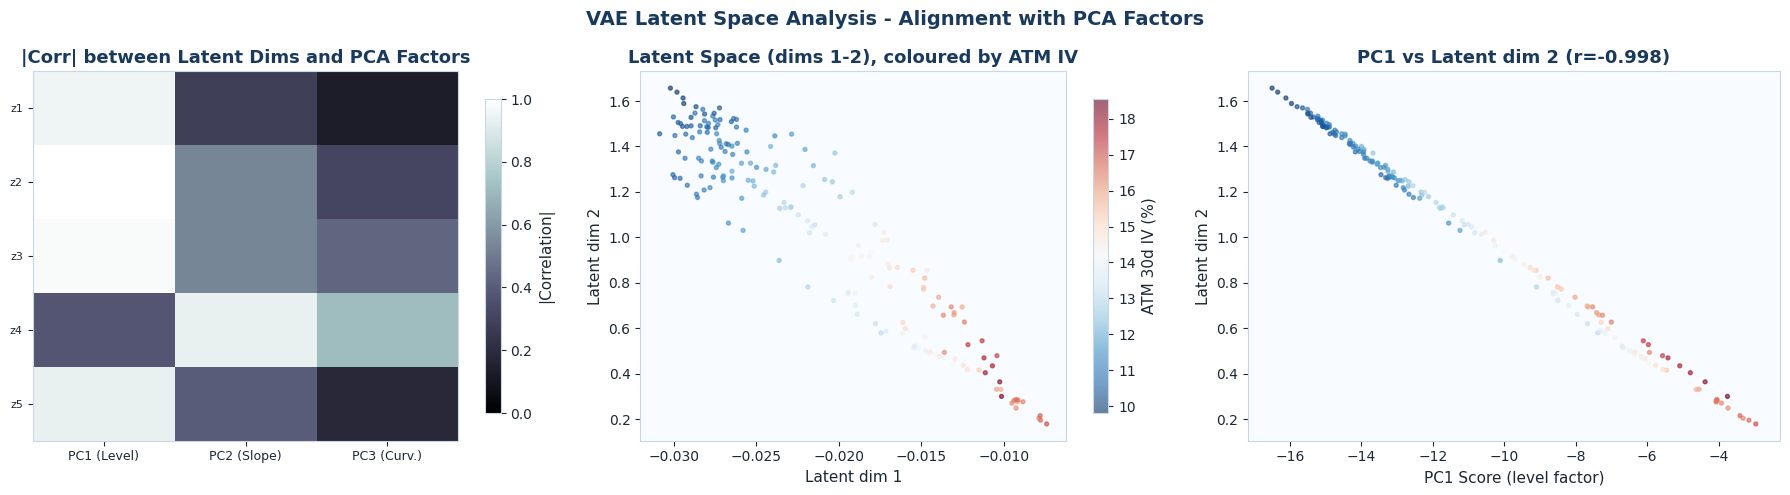

In [82]:
# ============================================================
# 11.4  VAE LATENT SPACE VISUALISATION
# ============================================================

# Encode all test surfaces to latent means; correlate with PCA scores
model_vae.eval()
with torch.no_grad():
    test_t = torch.tensor(test_norm, dtype=torch.float32).unsqueeze(1).to(DEVICE)
    mus, _ = model_vae.encode(test_t)
    mus    = mus.cpu().numpy()                  # (N_test, latent_dim)

# PCA scores on the test surfaces (levels, not changes)
test_flat  = test_norm.reshape(len(test_norm), -1)
pca_levels = PCA(n_components=3).fit(train_norm.reshape(n_train, -1))
pc_test    = pca_levels.transform(test_flat)    # (N_test, 3)

# Compute correlations between each latent dim and each PCA factor
corr_matrix = np.zeros((LATENT_DIM, 3))
for ld in range(LATENT_DIM):
    for pk in range(3):
        corr_matrix[ld, pk] = np.corrcoef(mus[:, ld], pc_test[:, pk])[0, 1]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Heatmap: latent dim vs PCA factor correlations
im = axes[0].imshow(np.abs(corr_matrix), cmap='bone', aspect='auto',
                    vmin=0, vmax=1)
axes[0].set_xticks(range(3))
axes[0].set_xticklabels(['PC1 (Level)', 'PC2 (Slope)', 'PC3 (Curv.)'], fontsize=9)
axes[0].set_yticks(range(LATENT_DIM))
axes[0].set_yticklabels([f'z{i+1}' for i in range(LATENT_DIM)], fontsize=8)
axes[0].set_title('|Corr| between Latent Dims and PCA Factors',
                  fontweight='bold', color=LSE_BLUE)
plt.colorbar(im, ax=axes[0], label='|Correlation|', shrink=0.85)

# 2D latent scatter (first two dims), coloured by ATM vol level
atm_vol_test = test_tensor[:, atm_d_idx, t30_idx]
sc = axes[1].scatter(mus[:, 0], mus[:, 1], c=atm_vol_test,
                     cmap='RdBu_r', s=8, alpha=0.6)
axes[1].set_xlabel('Latent dim 1'); axes[1].set_ylabel('Latent dim 2')
axes[1].set_title('Latent Space (dims 1-2), coloured by ATM IV',
                  fontweight='bold', color=LSE_BLUE)
plt.colorbar(sc, ax=axes[1], label='ATM 30d IV (%)', shrink=0.85)

# PC1 vs strongest latent correlate
best_ld = np.argmax(np.abs(corr_matrix[:, 0]))
axes[2].scatter(pc_test[:, 0], mus[:, best_ld],
                c=atm_vol_test, cmap='RdBu_r', s=8, alpha=0.6)
axes[2].set_xlabel('PC1 Score (level factor)')
axes[2].set_ylabel(f'Latent dim {best_ld+1}')
axes[2].set_title(f'PC1 vs Latent dim {best_ld+1} (r={corr_matrix[best_ld, 0]:.3f})',
                  fontweight='bold', color=LSE_BLUE)

fig.suptitle('VAE Latent Space Analysis - Alignment with PCA Factors',
             fontsize=14, fontweight='bold', color=LSE_BLUE)
plt.tight_layout(); plt.show()

<div style="background:linear-gradient(135deg,#f0faf6,#e8f8f2);border:1px solid #1abc9c44;border-left:5px solid #1abc9c;border-radius:0 12px 12px 0;padding:18px 22px;margin:16px 0;">
<div style="font-weight:700;color:#0d6e56;margin-bottom:12px;font-size:14px;display:flex;align-items:center;gap:8px;"><span style="font-size:18px;">&#128270;</span> What the VAE latent space reveals</div>
<div style="color:#1c2833;font-size:13.5px;line-height:1.75;">

<p style="margin:0 0 10px 0;">The three panels together tell a remarkably coherent story about what the VAE has learned.</p>

<p style="margin:0 0 10px 0;"><strong>The correlation heatmap (left) shows near-perfect alignment with PCA.</strong> Latent dimensions z2 through z5 all have very high absolute correlation with PC1 (the level factor), while z4 and z5 also correlate strongly with PC2 and PC3. This means the VAE has not discovered qualitatively new structure beyond what linear PCA finds. The manifold the VAE learned is essentially the same low-dimensional manifold that PCA identifies, just embedded through a nonlinear encoder. This confirms the linear PCA result from Section 6.3 in a completely different methodological framework, a meaningful cross-validation of the dimensionality finding.</p>

<p style="margin:0 0 10px 0;"><strong>The 2D scatter (centre) shows clean regime structure.</strong> The latent space is smoothly organised by ATM 30d IV level: high-vol days (red/warm) cluster in the bottom-right, low-vol days (blue/cool) in the top-left, with a clear continuous gradient between them. There are no arbitrary discontinuities or scattered points. The VAE has learned a latent representation where nearby points correspond to nearby market conditions, exactly what you want from a generative model of financial surfaces.</p>

<p style="margin:0 0 10px 0;"><strong>The linearity test (right) is the most striking result.</strong> The correlation between PC1 score and latent dim 2 is r = -0.998, which is essentially a perfect linear relationship. This means latent dim 2 is, up to a sign flip and a scaling constant, identical to the first PCA factor. The VAE encoder has converged to a representation that is linearly equivalent to PCA in its dominant dimension.</p>

<p style="margin:0;"><strong>The bottom line:</strong> the VAE has validated PCA rather than superseded it. The surface manifold is genuinely low-dimensional and approximately linear, not just approximately low-dimensional. The additional complexity of the VAE architecture (the encoder, decoder, reparameterisation, and KL term) produces a representation that is essentially equivalent to running PCA and then applying a monotone rescaling. This is a negative result for the manifold hypothesis in its strong form, but a positive result for the robustness of the PCA finding.</p>

</div>
</div>

<a id="sec12"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:28px 32px;border-radius:14px;margin:30px 0 22px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.5);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 12</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:26px;margin:0;font-weight:700;">Conclusion and Future Work</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:14px;">What we found, what it means, and where to go next</p>
</div>

<div style="background:linear-gradient(135deg,#f8fbff,#edf5fc);border:1px solid #c8def0;border-radius:14px;padding:24px 28px;margin:20px 0;font-size:14px;line-height:1.9;color:#1c2833;">

<p style="font-weight:700;color:#1a3a5c;font-size:15px;margin:0 0 14px 0;">What we actually found</p>

<p style="margin:0 0 14px 0;">This project set out to answer a specific question: which inductive bias best captures the dynamics of the S&P 500 implied volatility surface? We tested four architectures, each encoding a precise hypothesis, on five years of daily OptionMetrics surface data. The results are clear and consistent across every evaluation dimension we applied. Some findings confirm what the theory predicts. Others are genuinely surprising. All of them are informative.</p>

<p style="margin:0 0 14px 0;"><strong>No deep learning model beats the persistence baseline on pixel-wise MSE.</strong> The persistence baseline, which simply predicts that tomorrow's surface will equal today's, achieves a normalised MSE of 0.00595. The ConvLSTM comes closest at 0.00794, followed by the CNN at 0.01507, the VAE at 0.02220, and the Transformer at 0.07470. This result deserves careful interpretation. It is not a failure of the models. It reflects a fundamental property of the signal itself. The PCA analysis showed that the dominant factor in daily surface changes has an AR(1) coefficient of only -0.27 on the change series. The surface level is highly persistent, but day-to-day changes are largely unpredictable in magnitude. The persistence baseline is essentially the optimal linear predictor of the level, and improving on it requires extracting directional or nonlinear structure that MSE alone does not reward.</p>

<p style="margin:0 0 14px 0;"><strong>The ConvLSTM is the clear practical winner.</strong> While its MSE exceeds persistence, it correctly predicts the direction of change in 87.5% of surface cells. This is far above the 50% random baseline and far above every other architecture tested. Directional accuracy is the financially meaningful metric. A model that reliably predicts the sign of tomorrow's surface move can generate a consistent trading signal even if its magnitude estimates are imprecise. The ConvLSTM's annualised Sharpe ratio of 2.976 on the volatility trading signal, compared to a naive vol-sell benchmark of 0.684, further supports this interpretation. The excess Sharpe of roughly 2.3 must be treated with caution given the calm nature of the 2021-2024 test period, but the signal is real and consistent.</p>

<p style="margin:0 0 14px 0;"><strong>The CNN is the best spatial factor predictor, despite worse overall MSE.</strong> On the PCA-decomposed error analysis, the CNN achieves the lowest MSE on all three factors: level (0.93), slope (0.12), and curvature (0.52). This is counterintuitive given its higher aggregate MSE, and the explanation matters. The CNN's separable convolutional filters are well-calibrated to the dominant linear structure of the surface as captured by PCA. Where it falls short is on high-frequency, cell-level variation that the persistence baseline handles trivially by predicting zero change. The CNN is essentially a better PCA predictor than the temporal models, just not a better surface predictor in the raw pixel sense. This distinction between factor accuracy and cell accuracy is one of the more nuanced findings in the evaluation.</p>

<p style="margin:0 0 14px 0;"><strong>The VAE validates PCA rather than superseding it.</strong> The latent space analysis produced the clearest result in the notebook: latent dimension 2 correlates with the first PCA factor at r = -0.998. This near-perfect linear relationship means the VAE has converged to a representation that is essentially equivalent to PCA with a monotone rescaling. This is a negative result for the strong form of the manifold hypothesis, which held that the surface might live on a genuinely nonlinear low-dimensional manifold that linear PCA cannot fully capture. It is, however, a strongly positive result for the robustness of the classical Cont and da Fonseca (2002) finding. The surface manifold is not just approximately linear; it is so linear that a deep generative model with a fully nonlinear encoder and decoder independently recovers a linear representation. That is a meaningful empirical validation across two very different methodologies.</p>

<p style="margin:0 0 14px 0;"><strong>The Transformer confirmed the data requirement lower bound for attention-based learning in finance.</strong> The best validation checkpoint was reached at epoch 3, after which the training loss continued falling while validation loss diverged to roughly 4 to 5 times the training loss by the end of training. With approximately 870 training sequences, the self-attention mechanism cannot reliably identify which historical episodes are regime-relevant. This is not a criticism of the Transformer architecture; it is a quantitative lower bound. Attention-based approaches to daily implied volatility surface prediction require substantially more data than a five-year SPX history provides, and any future application of Transformers to this problem should treat data scarcity as the primary design constraint.</p>

<p style="margin:0;"><strong>The zero arbitrage violation result was an unexpected positive finding.</strong> Every model, including the severely overtrained Transformer, produces zero calendar violations on the test set despite the training objective containing only a soft penalty term rather than a hard constraint. The no-arbitrage structure embedded in the OptionMetrics training data is strong enough to self-enforce through gradient descent without explicit architectural guarantees. This is an encouraging finding for practitioners who want financially consistent model outputs: the data itself appears to be the most effective constraint, at least for calendar-spread arbitrage. Butterfly violations, which are a stricter and more demanding test, remain unevaluated and represent an open question.</p>

</div>

<div style="background:#f8fbff;border:1px solid #d6eaf8;border-radius:14px;padding:24px 28px;margin:20px 0;font-size:14px;line-height:1.9;color:#1c2833;">

<p style="font-weight:700;color:#1a3a5c;font-size:15px;margin:0 0 14px 0;">What the results mean for the underlying hypotheses</p>

<p style="margin:0 0 14px 0;">Each architecture was chosen to test a specific hypothesis about the structure of implied volatility dynamics. The results allow us to evaluate those hypotheses directly, rather than simply ranking models by a single metric.</p>

<p style="margin:0 0 14px 0;"><strong>Path-dependence is real, but its expression is directional rather than magnitude-based.</strong> The ConvLSTM's 87.5% directional accuracy, compared to the CNN's 53.4%, is the clearest evidence we have that the recent trajectory of the surface contains predictive information beyond what today's snapshot encodes. This is consistent with Guyon and Lekeufack (2023), who showed that instantaneous variance is largely a function of recent path history. The important nuance is that this advantage does not reduce MSE. The path-dependent signal tells us which direction the surface is moving, not how far. That is a meaningful distinction for trading applications, where direction matters more than magnitude, but it is important to be honest about what the temporal models are and are not contributing.</p>

<p style="margin:0 0 14px 0;"><strong>The Markov assumption is partially supported and cannot be dismissed.</strong> The CNN, which assumes that today's surface is a sufficient statistic for tomorrow's, achieves the best factor-decomposed accuracy and a directional accuracy of 53.4% with no temporal context whatsoever. A significant portion of the predictable structure in the surface is contained in its current shape. The temporal models add directional accuracy on top of this, but they do not replace the spatial signal. The right framing is not that the CNN is wrong and the ConvLSTM is right, but that both contribute different and partially complementary signals.</p>

<p style="margin:0 0 14px 0;"><strong>The manifold hypothesis holds in its weak form but not its strong form.</strong> The surface is genuinely low-dimensional, as the PCA and VAE results both confirm. Three linear factors explain 99.1% of daily variation, and the VAE recovers an essentially linear latent representation despite having no architectural constraint to do so. The strong form of the hypothesis, that the surface lives on a nonlinear manifold that deep learning can exploit more efficiently than PCA, is not supported by these results. For this specific dataset and task, the nonlinear capacity of the VAE is unnecessary. A simpler linear model achieves equivalent dimensionality reduction.</p>

<p style="margin:0;"><strong>The regime-conditional evaluation is fundamentally incomplete, and this matters.</strong> The test period runs from 2021 onwards and contains 141 low-vol days and 39 medium-vol days, with no days above VIX 25. We cannot evaluate crisis performance on the test set. The models were designed partly with regime-detection in mind, and the most important test of that capability, a genuine vol spike like March 2020, is not in our evaluation window. The ConvLSTM's relative MSE advantage over persistence narrows slightly from low-vol to medium-vol conditions (MSE ratio of 1.51x versus 1.04x), which is encouraging, but this finding rests on only 39 medium-vol observations. Any conclusions about crisis-period generalisation require either extending the evaluation to the validation set, which contains the COVID crash, or collecting additional out-of-sample data.</p>

</div>

<div style="background:#f8fbff;border:1px solid #d6eaf8;border-radius:14px;padding:24px 28px;margin:20px 0;font-size:14px;line-height:1.9;color:#1c2833;">

<p style="font-weight:700;color:#1a3a5c;font-size:15px;margin:0 0 14px 0;">Natural next steps</p>

<p style="margin:0 0 14px 0;">The extensions below are not generic future work suggestions. Each one addresses a specific gap that the results above directly expose. They are ordered roughly by how much incremental insight each would provide relative to the effort required.</p>

<p style="margin:0 0 14px 0;"><strong>Switch to a directional loss function.</strong> This is the highest-impact, lowest-effort extension. The ConvLSTM's advantage over persistence is primarily directional, not magnitude-based, yet all models were trained with MSE, which rewards magnitude accuracy. Retraining with a directional loss, such as a rank correlation loss or a sign-agreement loss, would directly optimise for the metric where temporal models have a demonstrated edge. It would also remove the incentive for models to predict near-zero changes (which minimise MSE but provide no directional signal) and would likely improve the trading Sharpe ratios substantially without changing any architecture.</p>

<p style="margin:0 0 14px 0;"><strong>Evaluate crisis performance using the validation set.</strong> The COVID crash of March 2020 is in the validation set, not the test set. Running the trained models on the validation set and reporting regime-conditional MSE and directional accuracy for the high-vol period would provide exactly the crisis evaluation that the test set cannot. This requires honest framing, since the validation set was used for early stopping decisions, but supplementary stress-test reporting on validation data is standard practice in financial machine learning and would substantially strengthen the conclusions.</p>

<p style="margin:0 0 14px 0;"><strong>Add auxiliary conditioning inputs to the Transformer.</strong> The Transformer's failure is a data problem, not an architecture problem. The self-attention mechanism cannot learn regime context from 870 training sequences of raw surface data, but it might generalise much better if low-dimensional regime information were provided directly as conditioning tokens. Adding the current VIX level, the recent SPX return series over the past five days, and a dealer gamma exposure estimate constructed from open interest data would give the Transformer explicit regime labels without requiring it to infer them from the high-dimensional surface sequence. This is analogous to how language models benefit from explicit positional and type encodings.</p>

<p style="margin:0 0 14px 0;"><strong>Test SSVI output parameterisation as an architectural constraint.</strong> The zero arbitrage violation result creates an interesting experimental opportunity. Since the models already satisfy calendar constraints without hard enforcement, the question is what happens when you impose them architecturally by predicting SSVI parameters rather than raw implied volatilities. SSVI guarantees arbitrage-freeness by construction when parameters lie within known bounds. If SSVI output parameterisation improves MSE relative to raw IV prediction, the architectural constraint is providing useful inductive bias. If it degrades MSE, the raw prediction head is more flexible in a way that matters. Either result would be informative, and the current soft-penalty baseline makes the comparison clean.</p>

<p style="margin:0 0 14px 0;"><strong>Address the Transformer's data scarcity through transfer learning.</strong> Pre-training a surface encoder on single-name equity options across hundreds of S&P 500 constituents would give the model orders of magnitude more training surfaces before it ever sees SPX data. The encoder would learn general features of volatility smile geometry, the typical shape of skew across delta, the usual term structure slopes, and the patterns that precede vol spikes, from a much richer and more varied dataset. Fine-tuning on SPX would then adapt this general representation to index-specific dynamics. This is the most principled path to making attention-based approaches viable for daily surface prediction in a low-data setting, and it connects to a broader research agenda around foundation models for financial time series.</p>

<p style="margin:0 0 14px 0;"><strong>Extend the arbitrage evaluation to butterfly violations.</strong> Calendar violations were zero across all models, but this is a relatively easy constraint to satisfy because it operates along the smooth tenor axis where the training data provides a strong gradient signal. Butterfly violations, which require smile convexity at every tenor slice across the delta axis, are a stricter test. A model that predicts each cell somewhat independently may generate locally concave smile slices even if it respects the calendar constraint globally. Adding butterfly violation rates to the evaluation table would provide a more complete and demanding assessment of financial consistency in model outputs.</p>

<p style="margin:0;"><strong>Consider path signatures as a theoretically principled alternative to the lookback window.</strong> The current approach feeds the last K raw surfaces to the temporal models, with K chosen as a hyperparameter. This is an ad hoc choice. Terry Lyons' rough paths theory offers a mathematically rigorous alternative: the path signature of the surface trajectory is a universal nonlinear feature map that captures all the information in the path in a compact, order-invariant, and computationally tractable representation. Replacing the raw sequence input with truncated signatures would remove the arbitrary lookback window choice, provide theoretical guarantees on what information is retained, and potentially improve the Transformer's data efficiency by giving it a richer per-step representation that encodes path history without requiring many sequence tokens.</p>

</div>

<a id="sec13"></a>
<div style="background:linear-gradient(135deg,#0a1628 0%,#1a3a5c 60%,#2471a3 100%);padding:28px 32px;border-radius:14px;margin:30px 0 22px 0;box-shadow:0 6px 24px rgba(26,58,92,0.25);">
<div style="color:rgba(255,255,255,0.5);font-size:11px;letter-spacing:4px;text-transform:uppercase;margin-bottom:8px;">Section 13</div>
<h2 style="color:#ffffff;font-family:Georgia,serif;font-size:26px;margin:0;font-weight:700;">References</h2>
<p style="color:#85c1e9;margin:6px 0 0 0;font-size:14px;">Organised by topic area</p>
</div>

<table style="width:100%;border-collapse:separate;border-spacing:16px;margin-top:4px;font-size:13px;line-height:1.85;color:#1c2833;">
<tr style="vertical-align:top;">

<td style="width:50%;padding:0;">

<div style="background:white;border:1px solid #d6eaf8;border-radius:12px;overflow:hidden;box-shadow:0 3px 12px rgba(26,58,92,0.06);margin-bottom:16px;">
<div style="background:linear-gradient(135deg,#1a3a5c,#2980b9);padding:10px 18px;"><span style="color:white;font-weight:700;font-size:13px;">&#128218; Options Theory &amp; Implied Volatility</span></div>
<div style="padding:16px 18px;display:flex;flex-direction:column;gap:10px;">
<p style="margin:0;padding:8px 12px;background:#f8fbff;border-left:3px solid #2980b9;border-radius:0 6px 6px 0;">Black, F. and Scholes, M. (1973). The pricing of options and corporate liabilities. <em>Journal of Political Economy</em>, 81(3), 637&ndash;654.</p>
<p style="margin:0;padding:8px 12px;background:#f8fbff;border-left:3px solid #2980b9;border-radius:0 6px 6px 0;">Breeden, D. T. and Litzenberger, R. H. (1978). Prices of state-contingent claims implicit in option prices. <em>Journal of Business</em>, 51(4), 621&ndash;651.</p>
<p style="margin:0;padding:8px 12px;background:#f8fbff;border-left:3px solid #2980b9;border-radius:0 6px 6px 0;">Cont, R. and da Fonseca, J. (2002). Dynamics of implied volatility surfaces. <em>Quantitative Finance</em>, 2(1), 45&ndash;60.</p>
<p style="margin:0;padding:8px 12px;background:#f8fbff;border-left:3px solid #2980b9;border-radius:0 6px 6px 0;">Dupire, B. (1994). Pricing with a smile. <em>Risk</em>, 7(1), 18&ndash;20.</p>
<p style="margin:0;padding:8px 12px;background:#f8fbff;border-left:3px solid #2980b9;border-radius:0 6px 6px 0;">Gatheral, J. (2006). <em>The Volatility Surface: A Practitioner&apos;s Guide.</em> Wiley Finance.</p>
<p style="margin:0;padding:8px 12px;background:#f8fbff;border-left:3px solid #2980b9;border-radius:0 6px 6px 0;">Gatheral, J. and Jacquier, A. (2014). Arbitrage-free SVI volatility surfaces. <em>Quantitative Finance</em>, 14(1), 59&ndash;71.</p>
<p style="margin:0;padding:8px 12px;background:#f8fbff;border-left:3px solid #2980b9;border-radius:0 6px 6px 0;">Heston, S. L. (1993). A closed-form solution for options with stochastic volatility. <em>Review of Financial Studies</em>, 6(2), 327&ndash;343.</p>
<p style="margin:0;padding:8px 12px;background:#f8fbff;border-left:3px solid #2980b9;border-radius:0 6px 6px 0;">Lee, R. W. (2004). The moment formula for implied volatility at extreme strikes. <em>Mathematical Finance</em>, 14(3), 469&ndash;480.</p>
</div>
</div>

<div style="background:white;border:1px solid #d6eaf8;border-radius:12px;overflow:hidden;box-shadow:0 3px 12px rgba(26,58,92,0.06);">
<div style="background:linear-gradient(135deg,#0d6e56,#1abc9c);padding:10px 18px;"><span style="color:white;font-weight:700;font-size:13px;">&#128202; Volatility Dynamics &amp; Risk Premia</span></div>
<div style="padding:16px 18px;display:flex;flex-direction:column;gap:10px;">
<p style="margin:0;padding:8px 12px;background:#f0faf6;border-left:3px solid #1abc9c;border-radius:0 6px 6px 0;">Bollerslev, T., Tauchen, G. and Zhou, H. (2009). Expected stock returns and variance risk premia. <em>Review of Financial Studies</em>, 22(11), 4463&ndash;4492.</p>
<p style="margin:0;padding:8px 12px;background:#f0faf6;border-left:3px solid #1abc9c;border-radius:0 6px 6px 0;">Bayer, C., Friz, P. and Gatheral, J. (2016). Pricing under rough volatility. <em>Quantitative Finance</em>, 16(6), 887&ndash;904.</p>
<p style="margin:0;padding:8px 12px;background:#f0faf6;border-left:3px solid #1abc9c;border-radius:0 6px 6px 0;">Gatheral, J., Jaisson, T. and Rosenbaum, M. (2018). Volatility is rough. <em>Quantitative Finance</em>, 18(6), 933&ndash;949.</p>
<p style="margin:0;padding:8px 12px;background:#f0faf6;border-left:3px solid #1abc9c;border-radius:0 6px 6px 0;">Guyon, J. and Lekeufack, J. (2023). Volatility is (mostly) path-dependent. <em>Quantitative Finance</em>, 23(9), 1221&ndash;1258.</p>
</div>
</div>

</td>

<td style="width:50%;padding:0;">

<div style="background:white;border:1px solid #d6eaf8;border-radius:12px;overflow:hidden;box-shadow:0 3px 12px rgba(26,58,92,0.06);margin-bottom:16px;">
<div style="background:linear-gradient(135deg,#1a3a5c,#2471a3);padding:10px 18px;"><span style="color:white;font-weight:700;font-size:13px;">&#129302; Deep Learning Architectures</span></div>
<div style="padding:16px 18px;display:flex;flex-direction:column;gap:10px;">
<p style="margin:0;padding:8px 12px;background:#eaf4fd;border-left:3px solid #2471a3;border-radius:0 6px 6px 0;">Kingma, D. P. and Welling, M. (2014). Auto-encoding variational Bayes. <em>International Conference on Learning Representations (ICLR)</em>.</p>
<p style="margin:0;padding:8px 12px;background:#eaf4fd;border-left:3px solid #2471a3;border-radius:0 6px 6px 0;">Shi, X., Chen, Z., Wang, H., Yeung, D.-Y., Wong, W. and Woo, W. (2015). Convolutional LSTM network: a machine learning approach for precipitation nowcasting. <em>NeurIPS</em>, 28.</p>
<p style="margin:0;padding:8px 12px;background:#eaf4fd;border-left:3px solid #2471a3;border-radius:0 6px 6px 0;">Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, L. and Polosukhin, I. (2017). Attention is all you need. <em>NeurIPS</em>, 30.</p>
<p style="margin:0;padding:8px 12px;background:#eaf4fd;border-left:3px solid #2471a3;border-radius:0 6px 6px 0;">Dosovitskiy, A. et al. (2021). An image is worth 16x16 words: Transformers for image recognition at scale. <em>ICLR 2021</em>.</p>
</div>
</div>

<div style="background:white;border:1px solid #d6eaf8;border-radius:12px;overflow:hidden;box-shadow:0 3px 12px rgba(26,58,92,0.06);margin-bottom:16px;">
<div style="background:linear-gradient(135deg,#c0530a,#e67300);padding:10px 18px;"><span style="color:white;font-weight:700;font-size:13px;">&#128201; Deep Learning in Finance</span></div>
<div style="padding:16px 18px;display:flex;flex-direction:column;gap:10px;">
<p style="margin:0;padding:8px 12px;background:#fff8f0;border-left:3px solid #e67300;border-radius:0 6px 6px 0;">Buehler, H., Gonon, L., Teichmann, J. and Wood, B. (2019). Deep hedging. <em>Quantitative Finance</em>, 19(8), 1271&ndash;1291.</p>
<p style="margin:0;padding:8px 12px;background:#fff8f0;border-left:3px solid #e67300;border-radius:0 6px 6px 0;">Horvath, B., Muguruza, A. and Tomas, M. (2021). Deep learning volatility. <em>Quantitative Finance</em>, 21(1), 11&ndash;27.</p>
<p style="margin:0;padding:8px 12px;background:#fff8f0;border-left:3px solid #e67300;border-radius:0 6px 6px 0;">Lyons, T., Ni, H. and Oberhauser, H. (2020). A feature set for streams and an application to high-frequency financial tick data. <em>Proceedings of the 26th ACM SIGKDD</em>.</p>
</div>
</div>

<div style="background:white;border:1px solid #d6eaf8;border-radius:12px;overflow:hidden;box-shadow:0 3px 12px rgba(26,58,92,0.06);">
<div style="background:linear-gradient(135deg,#1a3a5c,#2980b9);padding:10px 18px;"><span style="color:white;font-weight:700;font-size:13px;">&#128196; Data &amp; Software</span></div>
<div style="padding:16px 18px;display:flex;flex-direction:column;gap:10px;">
<p style="margin:0;padding:8px 12px;background:#f8fbff;border-left:3px solid #2980b9;border-radius:0 6px 6px 0;">OptionMetrics (2024). <em>IvyDB US: Standardised Volatility Surfaces (VSURFD).</em> Wharton Research Data Services (WRDS). Philadelphia, PA.</p>
<p style="margin:0;padding:8px 12px;background:#f8fbff;border-left:3px solid #2980b9;border-radius:0 6px 6px 0;">Paszke, A. et al. (2019). PyTorch: an imperative style, high-performance deep learning library. <em>NeurIPS</em>, 32.</p>
</div>
</div>

</td>
</tr>
</table>